In [1]:
import pandas as pd

## Main Figure 1

## 1b

Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/FIG1/evoage_sunburst_1b_regen.svg


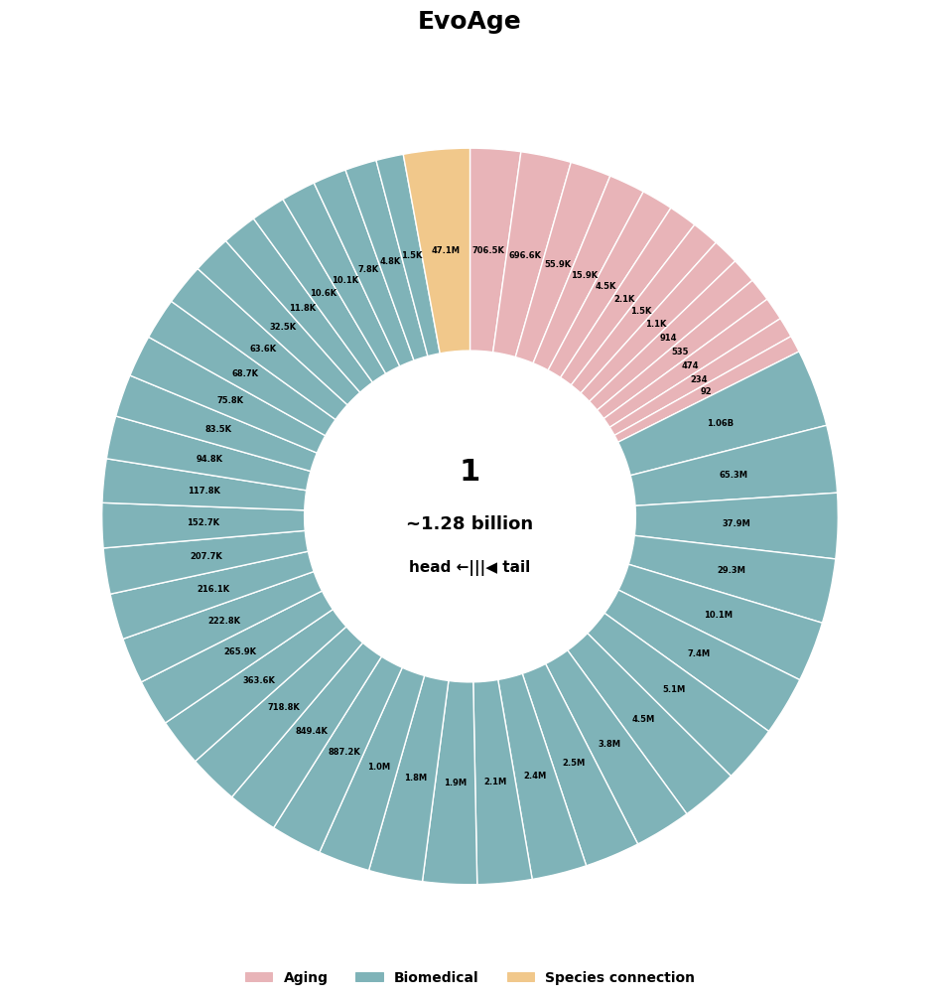

In [188]:
"""
EvoAge KG — Figure 1b: single-ring sunburst/donut of data sources,
wedge size = log10(Total edges), colored by KG_Type category.

Reads figure1b.csv (columns: Source, KG_Type, Total, log) and reproduces
evoage_sunburst_1b.svg. Output SVG text stays fully editable (svg.fonttype='none').
"""

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['font.family'] = 'DejaVu Sans'

# ----------------------------------------------------------------------
# Editable-text SVG output (Rai's standing preference)
# ----------------------------------------------------------------------
mpl.rcParams['svg.fonttype'] = 'none'

# ----------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------
CSV_PATH = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/figure1b.csv"          # update path as needed, e.g. server path
OUT_PATH = "/storage/Arushi/090526_EvoAge/kg_formation/all_figures/FIG1/evoage_sunburst_1b_regen.svg"

CATEGORY_ORDER = ["Aging", "Biomedical", "Species connection"]
CATEGORY_COLORS = {
    "Aging": "#e8b4b8",              # salmon/pink
    "Biomedical": "#7fb3b8",         # teal
    "Species connection": "#f1c88b", # gold
}

DONUT_WIDTH = 0.55      # ring thickness as fraction of radius (donut hole size)
WEDGE_EDGE_COLOR = "white"
WEDGE_EDGE_WIDTH = 1.0
START_ANGLE = 90        # start at 12 o'clock
CLOCKWISE = True        # counterclockwise=False in pie()

SHOW_RAW_NUMBERS = True     # print each source's raw Total on its wedge
RAW_LABEL_FONTSIZE = 6
RAW_LABEL_MIN_PCT = 0.0     # raise this (e.g. 0.5) to hide labels on tiny wedges


def format_raw(x: float) -> str:
    """Human-readable raw count, e.g. 1055910438 -> '1.06B'."""
    if x >= 1e9:
        return f"{x/1e9:.2f}B"
    if x >= 1e6:
        return f"{x/1e6:.1f}M"
    if x >= 1e3:
        return f"{x/1e3:.1f}K"
    return f"{int(x)}"

# ----------------------------------------------------------------------
# Load + prep data
# ----------------------------------------------------------------------
df = pd.read_csv(CSV_PATH)

# clean thousands-separator formatted totals (e.g. "4,71,00,000")
df["Total"] = df["Total"].astype(str).str.replace(",", "").astype(float)

# category order = alphabetical (Aging, Biomedical, Species connection);
# within each category, rows are already sorted descending by 'log' —
# preserve that order rather than re-sorting, so ties/order match the source file
df["KG_Type"] = pd.Categorical(df["KG_Type"], categories=CATEGORY_ORDER, ordered=True)
df = df.sort_values(["KG_Type"], kind="stable").reset_index(drop=True)

sizes = df["log"].values                       # <-- wedge size uses log values
colors = df["KG_Type"].map(CATEGORY_COLORS).values
grand_total = df["Total"].sum()

# ----------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.57, 11.27))  # matches ~689x811pt canvas

# autopct only receives a percentage, so use a row counter (pie() calls it
# once per wedge, in the same order as `sizes`/`df`) to map back to the
# actual raw Total for that source.
raw_values = df["Total"].tolist()
_row = {"i": 0}


def raw_number_label(pct):
    i = _row["i"]
    _row["i"] += 1
    if not SHOW_RAW_NUMBERS or pct < RAW_LABEL_MIN_PCT:
        return ""
    return format_raw(raw_values[i])


wedges, _, raw_labels = ax.pie(
    sizes,
    colors=colors,
    startangle=START_ANGLE,
    counterclock=not CLOCKWISE,
    radius=1.0,
    wedgeprops=dict(
        width=DONUT_WIDTH,
        edgecolor=WEDGE_EDGE_COLOR,
        linewidth=WEDGE_EDGE_WIDTH,
    ),
    autopct=raw_number_label,
    pctdistance=1.0 - DONUT_WIDTH / 2,   # center of the donut ring
)

for lbl in raw_labels:
    lbl.set_fontsize(RAW_LABEL_FONTSIZE)
    lbl.set_ha("center")
    lbl.set_va("center")

ax.set_aspect("equal")

# ----------------------------------------------------------------------
# Center annotation
# ----------------------------------------------------------------------
ax.text(
    0, 0.12, "1",
    ha="center", va="center", fontsize=22, fontweight="bold",
)
ax.text(
    0, -0.02, f"~{grand_total/1e9:.2f} billion",
    ha="center", va="center", fontsize=13,
)
ax.text(
    0, -0.14, "head ←|||◀ tail",
    ha="center", va="center", fontsize=11,
)

# ----------------------------------------------------------------------
# Title + legend
# ----------------------------------------------------------------------
ax.set_title("EvoAge", fontsize=18, pad=20)

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=CATEGORY_COLORS[cat])
    for cat in CATEGORY_ORDER
]
ax.legend(
    legend_handles,
    CATEGORY_ORDER,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=3,
    frameon=False,
    fontsize=10,
)

fig.tight_layout()
fig.savefig(OUT_PATH, format="svg")
print(f"Saved: {OUT_PATH}")

## 1c

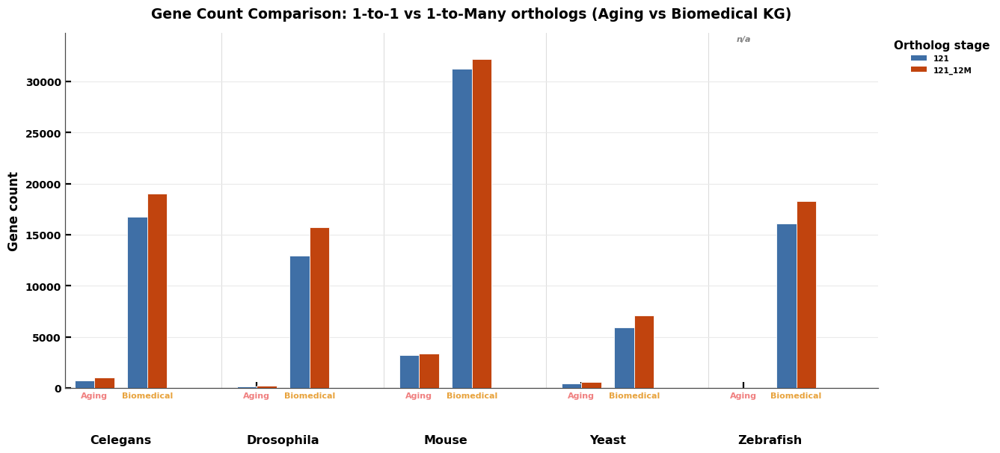

Saved genecount_bar_aging_biomedical.svg / .png


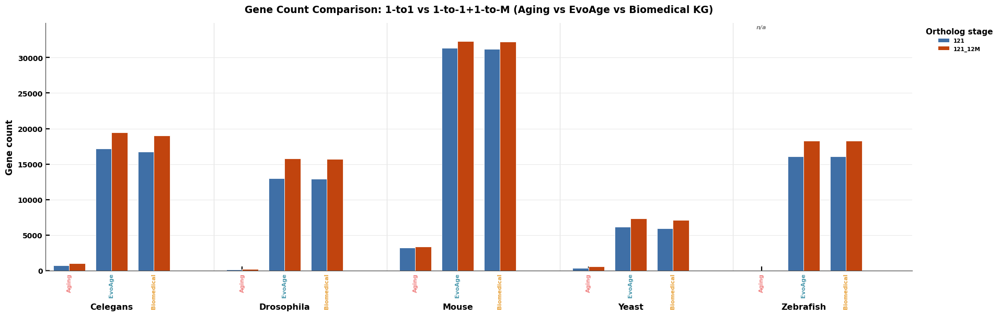

Saved genecount_bar_aging_evoage_biomedical.svg / .png


In [200]:
"""
Vertical grouped bar charts comparing gene counts at the "121" vs
"121_12M" ortholog-mapping stage, per species, for each KG resource.

Plot 1: Aging KG vs Biomedical KG
Plot 2: Aging KG vs EvoAge KG vs Biomedical KG

Input : combined_gene_counts.csv
         columns -> Species, Aging_121, Aging_121_12M,
                    Biomedical_121, Biomedical_121_12M,
                    EvoAge_121, EvoAge_121_12M
Output: SVG (+PNG) files, vector, publication-ready.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ----------------------------------------------------------------------
# 0. Paths -- EDIT THESE to match your local setup
# ----------------------------------------------------------------------
INPUT_CSV = "combined_gene_counts_no_human.csv"
OUT_DIR   = "."   # where the SVG/PNG figures will be written

# ----------------------------------------------------------------------
# 1. Style
# ----------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.fonttype": "none",   # keep text editable in Illustrator/Inkscape
})

COLOR_121     = "#3F6FA6"   # blue   -> "121" (before)
COLOR_121_12M = "#C1440E"   # orange -> "121_12M" (after)

# established dataset accent colors (used for the small dataset tick labels)
DATASET_COLORS = {
    "Aging":      "#F08080",
    "Biomedical": "#E8A33D",
    "EvoAge":     "#4C9AAE",
}


def plot_gene_count_bars(df, datasets, title, outfile,
                          bar_width=0.38, ds_gap=0.25, group_gap=1.1,
                          figsize_per_col=1.15):
    """
    df       : the combined_gene_counts dataframe
    datasets : list of prefixes, e.g. ["Aging", "Biomedical"]
               or ["Aging", "EvoAge", "Biomedical"]
    Each dataset contributes one pair of bars (121 / 121_12M) per species.
    """
    species_list = df["Species"].tolist()
    n_ds = len(datasets)

    fig_w = max(7, figsize_per_col * n_ds * len(species_list) + 2)
    fig, ax = plt.subplots(figsize=(fig_w, 6.2))

    x_cursor = 0.0
    group_centers, group_labels = [], []
    tick_pos, tick_labels, tick_colors = [], [], []

    for sp in species_list:
        row = df[df["Species"] == sp].iloc[0]
        group_start = x_cursor

        for ds in datasets:
            y0 = row[f"{ds}_121"]
            y1 = row[f"{ds}_121_12M"]
            x_center = x_cursor

            if pd.notna(y0) and pd.notna(y1):
                ax.bar(x_center - bar_width / 2, y0, width=bar_width,
                       color=COLOR_121, edgecolor="white", linewidth=0.6, zorder=3)
                ax.bar(x_center + bar_width / 2, y1, width=bar_width,
                       color=COLOR_121_12M, edgecolor="white", linewidth=0.6, zorder=3)
            else:
                ax.text(x_center, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 1000,
                        "n/a", ha="center", va="bottom", fontsize=8,
                        color="grey", style="italic")

            tick_pos.append(x_center)
            tick_labels.append(ds)
            tick_colors.append(DATASET_COLORS.get(ds, "black"))
            x_cursor += (bar_width * 2 + ds_gap)

        group_centers.append((group_start + x_cursor - (bar_width * 2 + ds_gap)) / 2)
        group_labels.append(sp)

        # light vertical separator between species groups
        if sp != species_list[-1]:
            sep_x = x_cursor - ds_gap / 2 + group_gap / 2
            ax.axvline(sep_x, color="#DDDDDD", lw=0.8, zorder=0)

        x_cursor += group_gap

    # dataset-level ticks (small, colored)
    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_labels, rotation=90 if n_ds > 2 else 0, fontsize=8)
    for tick, c in zip(ax.get_xticklabels(), tick_colors):
        tick.set_color(c)

    # species-level labels below the dataset ticks
    for xc, sp in zip(group_centers, group_labels):
        ax.text(xc, -0.13, sp, transform=ax.get_xaxis_transform(),
                 ha="center", va="top", fontsize=11.5, fontweight="bold")

    ax.set_xlim(-bar_width * 1.5, x_cursor - group_gap + bar_width * 1.5)
    ax.set_ylabel("Gene count", fontsize=12)
    ax.set_title(title, fontsize=13.5, fontweight="bold", pad=14)
    ax.margins(y=0.08)
    ax.grid(axis="y", color="#EAEAEA", lw=0.8, zorder=0)

    legend_elems = [
        Patch(facecolor=COLOR_121, label="121"),
        Patch(facecolor=COLOR_121_12M, label="121_12M"),
    ]
    ax.legend(handles=legend_elems, frameon=False, loc="upper left",
              bbox_to_anchor=(1.01, 1.0), title="Ortholog stage")

    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/{outfile}.svg", bbox_inches="tight")
    fig.savefig(f"{OUT_DIR}/{outfile}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved {outfile}.svg / .png")


if __name__ == "__main__":
    df = pd.read_csv(INPUT_CSV)

    # Plot 1: Aging vs Biomedical
    plot_gene_count_bars(
        df,
        datasets=["Aging", "Biomedical"],
        title="Gene Count Comparison: 1-to-1 vs 1-to-Many orthologs (Aging vs Biomedical KG)",
        outfile="genecount_bar_aging_biomedical",
    )

    # Plot 2: Aging vs EvoAge vs Biomedical
    plot_gene_count_bars(
        df,
        datasets=["Aging", "EvoAge", "Biomedical"],
        title="Gene Count Comparison: 1-to1 vs 1-to-1+1-to-M (Aging vs EvoAge vs Biomedical KG)",
        outfile="genecount_bar_aging_evoage_biomedical",
    )

## 1d

In [45]:
import plotly.io as pio
pio.renderers.default = "iframe"

In [201]:
"""
KG Node-Type Hierarchy Visualization (Sunburst ONLY)
=====================================================

Builds a multi-layer sunburst chart (Dataset -> Species -> Node type)
for your Aging vs Biomedical knowledge graphs, for the node scheme:
  - Node (1:1 + 1:N)

Chart details:
  - Two top-level branches: Aging (coral/red family) vs Biomedical
    (teal family -- same teal used previously for EvoAge) -- children
    inherit shades of their branch color.
  - Wedge SIZE is driven by log10(count+1), so small node types (e.g.
    Chemical, Protein) stay readable next to huge ones (PMID, Mutation)
    instead of being squeezed to an invisible sliver.
  - Labels and hover text still show the REAL, un-logged count (e.g.
    "Chemical  434,768"), not the log value -- log scale only affects size.
  - Combines all species into one figure per scheme (species is just one
    ring/layer of the hierarchy, so you still see per-species breakdown
    without needing six separate panels).

Requirements:
    pip install pandas plotly kaleido

  SVG export (kaleido) note: recent kaleido versions (v1+) need a local
  Chrome install. If `write_image` fails, run this once in your terminal:
      plotly_get_chrome
  or pin an older, self-contained kaleido that needs no Chrome:
      pip install "kaleido==0.2.1"

HOW TO USE
----------
1. Edit the FILES dict below so the paths point to your own CSVs.
2. Run:  python kg_hierarchy_sunburst_aging_biomedical.py
3. Each figure is saved directly as a .svg file next to this script.
   (No HTML files are written -- SVG only, per your request.)
"""

import numpy as np
import pandas as pd
import plotly.express as px

# ---------------------------------------------------------------------------
# 1. EDIT THESE PATHS to point at your own CSV files
# ---------------------------------------------------------------------------
FILES = {
    "1to1_1toN": {
        "Aging":      "/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/aging_121_12M_Species_NodeType_unique_counts.csv",
        "Biomedical": "/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/Species_Biomedical_121_12M_NodeType_unique_counts.csv",
    },
}

SCHEME_TITLE = {
    "1to1_1toN": "Node (1:1 + 1:N)",
}

# Node-type row names (as they appear in the CSV) -> short display labels
NODE_MAP = {
    "CellularComponent": "Cellular",
    "Disease": "Disease",
    "Phenotype": "Phenotype",
    "BiologicalProcess": "Biological",
    "PlantSpecies": "Plant",
    "MolecularFunction": "Molecular",
    "Pathway": "Pathway",
    "Mutation": "Mutation",
    "ChemicalEntity": "Chemical",
    "Protein": "Protein",
    "Mirna": "miRNA",
    "AnatomicalEntity": "Anatomy",
    "Gene": "Gene",
    "Tissue": "Tissue",
    "PMID": "PMID",
}

# Distinct color families for the two datasets (kept for reference/legend)
# NOTE: Biomedical keeps the SAME teal family previously used for EvoAge.
DATASET_COLORS = {
    "Aging": "#E85C6B",       # coral/red family
    "Biomedical": "#1F7A8C",  # teal family (same as former EvoAge)
}

# Distinct designated color per node type (leaf-level segments)
NODE_COLORS = {
    "Cellular":   "#F5E1A4",
    "Disease":    "#B79FCB",
    "Phenotype":  "#E0559B",
    "Biological": "#7FB8D6",
    "Plant":      "#5B2A6E",
    "Molecular":  "#D98E3F",
    "Pathway":    "#7A4B32",
    "Mutation":   "#9B9B9B",
    "Chemical":   "#C9B458",
    "Protein":    "#F0BFC8",
    "miRNA":      "#8E4E8F",
    "Anatomy":    "#E08D6D",
    "Gene":       "#4472A8",
    "Tissue":     "#E8A96B",
    "PMID":       "#B7C88A",
}


# ---------------------------------------------------------------------------
# 2. Reshape each CSV (wide: NodeType x Species) into long hierarchical rows
# ---------------------------------------------------------------------------
def load_long(dataset_name, path):
    df = pd.read_csv(path)
    df = df[df["NodeType"].isin(NODE_MAP.keys())].copy()
    df["NodeType"] = df["NodeType"].map(NODE_MAP)

    species_cols = [c for c in df.columns if c != "NodeType"]
    long_df = df.melt(id_vars="NodeType", value_vars=species_cols,
                       var_name="Species", value_name="Count")
    long_df["Dataset"] = dataset_name
    long_df = long_df[long_df["Count"] > 0]  # drop empty branches (cleaner chart)
    long_df["LogCount"] = np.log10(long_df["Count"] + 1)  # drives wedge SIZE only
    return long_df[["Dataset", "Species", "NodeType", "Count", "LogCount"]]


def build_hierarchy(scheme_key):
    files = FILES[scheme_key]
    frames = [load_long(ds_name, path) for ds_name, path in files.items()]
    return pd.concat(frames, ignore_index=True)


def apply_node_colors(fig):
    """Give each NodeType leaf its designated color; Dataset/Species parent
    rings get a neutral gray so they don't inherit a random default color."""
    colors = [NODE_COLORS.get(lab, "#EDEDED") for lab in fig.data[0].labels]
    fig.data[0].marker.colors = colors
    return fig


# ---------------------------------------------------------------------------
# 3. Chart builder (Sunburst only)
# ---------------------------------------------------------------------------
def make_sunburst(df, title):
    fig = px.sunburst(
        df,
        path=["Dataset", "Species", "NodeType"],
        values="LogCount",
        branchvalues="total",
        custom_data=["Count"],
        title=title,
    )
    fig = apply_node_colors(fig)
    fig.update_traces(
        texttemplate="%{label}<br>%{customdata[0]:,}",
        hovertemplate="%{label}<br>Count: %{customdata[0]:,}<extra></extra>",
        insidetextorientation="radial",
        marker=dict(line=dict(color="white", width=1.5)),
    )
    fig.update_layout(
        font=dict(family="Arial, sans-serif", size=15),
        title=dict(x=0.5, font=dict(size=22, family="Arial, sans-serif")),
        margin=dict(t=80, l=10, r=10, b=10),
        paper_bgcolor="white",
    )
    return fig


# ---------------------------------------------------------------------------
# 4. Run for both schemes, sunburst only -- SVG output only
# ---------------------------------------------------------------------------
if __name__ == "__main__":
    for scheme_key, scheme_label in SCHEME_TITLE.items():
        df = build_hierarchy(scheme_key)

        sun_fig = make_sunburst(df, f"Knowledge-graph node types")

        try:
            sun_fig.write_image(f"sunburst_aging_biomedical_{scheme_key}.svg", width=1400, height=1400, scale=2)
            print(f"Saved: sunburst_aging_biomedical_{scheme_key}.svg")
        except Exception as e:
            print("SVG saved")
    sun_fig.show()

SVG saved


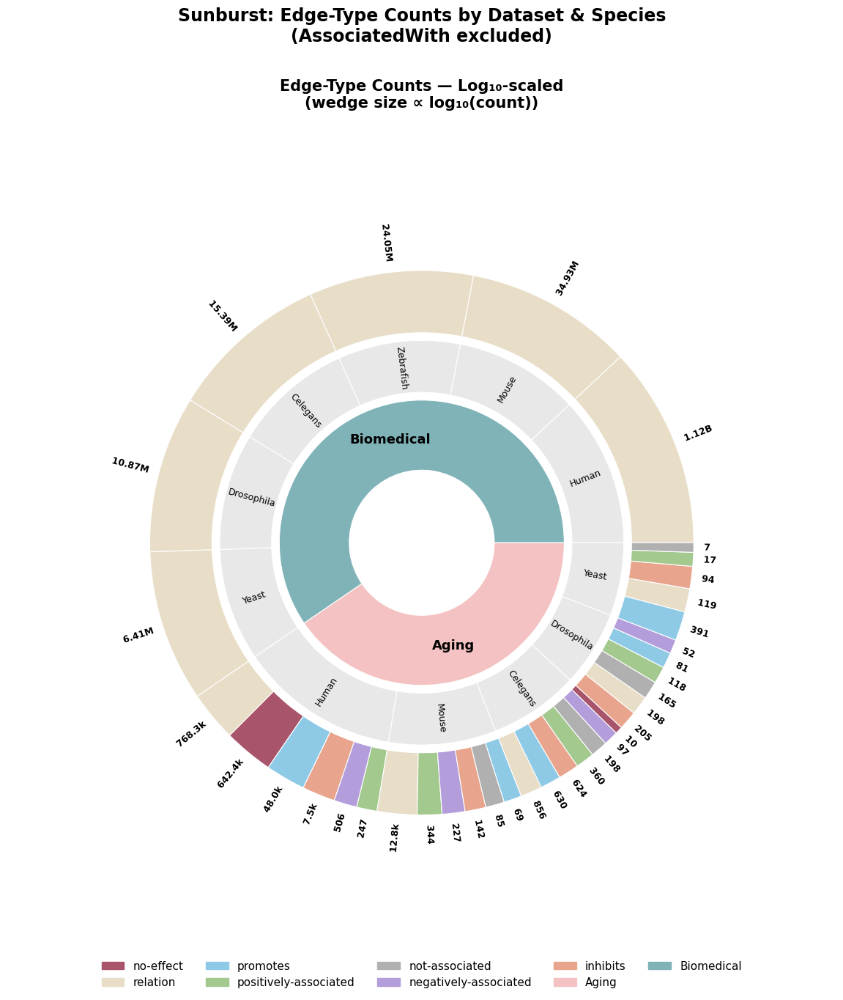

,dataset,Species,edge_type,count
0,Aging,Human,NoEffect,642378
1,Aging,Human,relation,768267
2,Aging,Human,Promotes,47972
3,Aging,Human,Inhibits,7477
4,Aging,Human,NegativelyAssociatedWith,506


In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

# Keep SVG text as real, editable <text> elements instead of converting every
# label/title/legend entry into vector path outlines (matplotlib's default,
# "svg.fonttype" = "path", bakes text into shapes that can't be edited or
# re-fonted in Illustrator/Inkscape). "none" keeps it as selectable/editable text.
plt.rcParams["svg.fonttype"] = "none"

# -----------------------------------------------------------------------------
# 1. LOAD & PREP
# -----------------------------------------------------------------------------
# Aging: long-format file, already has an edge_type + dataset column
# (same source file as before, just keep the "Aging" rows this time).
aging_path = "/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/Edgetype.csv"
# Biomedical: wide-format file (NodeType/Relation x Species columns), needs
# reshaping to long + an edge_type derived from the Relation name.
biomedical_path = "/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/Species_Biomedical_121_12M_RelationType_unique_counts.csv"

EDGE_TYPES_IN_NAME = [
    "NegativelyAssociatedWith",
    "PositivelyAssociatedWith",
    "NotAssociatedWith",
    "NoEffect",
    "Promotes",
    "Inhibits",
]

def infer_edge_type(relation):
    for et in EDGE_TYPES_IN_NAME:
        if et in relation:
            return et
    return "relation"

# --- Aging (long format already) ---
df_aging = pd.read_csv(aging_path)
df_aging = df_aging[df_aging["dataset"] == "Aging"].copy()
df_aging = df_aging[df_aging["edge_type"] != "AssociatedWith"]
df_aging = df_aging[["Relation", "Species", "count", "edge_type"]]
df_aging["dataset"] = "Aging"

# --- Biomedical (wide format -> long) ---
bio_wide = pd.read_csv(biomedical_path)
bio_wide = bio_wide[~bio_wide["Relation"].isin(["Species_AssociatedWith_Nodes", "Total Triples"])].copy()
species_cols = [c for c in bio_wide.columns if c != "Relation"]
df_biomedical = bio_wide.melt(id_vars="Relation", value_vars=species_cols,
                               var_name="Species", value_name="count")
df_biomedical = df_biomedical[df_biomedical["count"] > 0].copy()
df_biomedical["edge_type"] = df_biomedical["Relation"].apply(infer_edge_type)
df_biomedical["dataset"] = "Biomedical"

# --- combine ---
df = pd.concat([df_aging, df_biomedical], ignore_index=True)
# True log10(count) needs count > 0 (log10(0) is undefined) -- drop any
# leftover zero/negative-count rows before taking logs anywhere below.
df = df[df["count"] > 0].copy()

# IMPORTANT: several raw Relation rows collapse into the same wedge (e.g. many
# distinct relation names all map to edge_type "relation"). Sum their raw
# counts into ONE number per (dataset, Species, edge_type) wedge FIRST, then
# take a single log10 of that sum. Taking log10 of each row separately and
# summing those logs would instead compute log10(count_1 * count_2 * ...) --
# the log of a PRODUCT, not the log of the total -- which makes wedges with
# many small rows balloon past wedges with one genuinely large count. This
# way, wedge size is proportional to log10(true total count) for that wedge.
df = (df.groupby(["dataset", "Species", "edge_type"], sort=False)["count"]
        .sum().reset_index())

def format_count(n):
    if n >= 1_000_000_000:
        return f"{n/1_000_000_000:.2f}B"
    elif n >= 1_000_000:
        return f"{n/1_000_000:.2f}M"
    elif n >= 1_000:
        return f"{n/1_000:.1f}k"
    return str(int(n))

# -----------------------------------------------------------------------------
# 2. COLOR MAPS
# -----------------------------------------------------------------------------
# NOTE: Biomedical keeps the SAME teal previously used for EvoAge.
dataset_colors = {"Aging": "#f4c2c2", "Biomedical": "#7fb3b8"}
species_colors = {sp: "#e8e8e8" for sp in
                  ["Human", "Yeast", "Celegans", "Drosophila", "Zebrafish", "Mouse"]}

edge_colors = {
    "NoEffect":                 "#a8546b",
    "relation":                 "#e8ddc7",
    "Promotes":                 "#8ecae6",
    "PositivelyAssociatedWith": "#a3c98f",
    "NotAssociatedWith":        "#b0b0b0",
    "NegativelyAssociatedWith": "#b39ddb",
    "Inhibits":                 "#e8a48c",
    # AssociatedWith intentionally excluded
}
edge_legend_labels = {
    "NoEffect":                 "no-effect",
    "relation":                 "relation",
    "Promotes":                 "promotes",
    "PositivelyAssociatedWith": "positively-associated",
    "NotAssociatedWith":        "not-associated",
    "NegativelyAssociatedWith": "negatively-associated",
    "Inhibits":                 "inhibits",
}

# -----------------------------------------------------------------------------
# 3. ANGLE ASSIGNMENT (recursive, log10 of the TRUE raw total at every level)
#    At each level (dataset -> Species -> edge_type), a node's weight is
#    log10(sum of its own raw counts) -- recomputed fresh from "count" every
#    time, not inherited by summing children's already-logged weights. That
#    means a dataset with a few huge counts (e.g. Biomedical, billions) will
#    correctly get a bigger wedge than one with many small/medium counts
#    (e.g. Aging), because we're logging the real total once, not summing
#    several small logs together (which silently favors "many small values").
# -----------------------------------------------------------------------------
def assign_angles(data, group_cols, start_angle=0, end_angle=360):
    if not group_cols:
        return data
    col = group_cols[0]
    # Weight of each child at THIS level = log10(sum of raw counts under it).
    # Recomputing from raw "count" at every level (rather than summing
    # already-logged child weights) is what keeps parent wedges honestly
    # proportional to what's actually inside them -- a dataset with a few
    # huge counts will correctly out-weigh one with many small counts.
    sums = data.groupby(col, sort=False)["count"].sum()
    weights = np.log10(sums)
    total_weight = weights.sum()
    order = weights.sort_values(ascending=False).index
    angle = start_angle
    frames = []
    for key in order:
        w = weights[key]
        span = (w / total_weight) * (end_angle - start_angle) if total_weight > 0 else 0
        sub = data[data[col] == key].copy()
        sub = assign_angles(sub, group_cols[1:], angle, angle + span)
        sub[f"{col}_start"] = angle
        sub[f"{col}_end"] = angle + span
        frames.append(sub)
        angle += span
    return pd.concat(frames)

# -----------------------------------------------------------------------------
# 4. DRAWING HELPERS
# -----------------------------------------------------------------------------
r_hole    = 0.28
r_dataset = (r_hole, 0.55)
r_species = (0.58, 0.78)
r_edge    = (0.81, 1.05)
r_label   = 1.09

def draw_wedge(ax, t1, t2, r_inner, r_outer, color, edgecolor="white", lw=0.8):
    if t2 - t1 <= 0:
        return
    w = mpatches.Wedge((0, 0), r_outer, t1, t2, width=r_outer - r_inner,
                        facecolor=color, edgecolor=edgecolor, linewidth=lw)
    ax.add_patch(w)

def draw_sunburst(ax, df, title):
    # ── Ring 1: dataset ──────────────────────────────────────────────────────
    for dataset, grp in df.groupby("dataset", sort=False):
        t1 = grp["dataset_start"].iloc[0]
        t2 = grp["dataset_end"].iloc[0]
        draw_wedge(ax, t1, t2, r_dataset[0], r_dataset[1],
                   dataset_colors.get(dataset, "#cccccc"))
        mid = np.deg2rad((t1 + t2) / 2)
        r_t = (r_dataset[0] + r_dataset[1]) / 2
        ax.text(r_t * np.cos(mid), r_t * np.sin(mid), dataset,
                ha="center", va="center", fontsize=13, fontweight="bold")

    # ── Ring 2: species ───────────────────────────────────────────────────────
    for (dataset, sp), grp in df.groupby(["dataset", "Species"], sort=False):
        t1 = grp["Species_start"].iloc[0]
        t2 = grp["Species_end"].iloc[0]
        draw_wedge(ax, t1, t2, r_species[0], r_species[1],
                   species_colors.get(sp, "#e8e8e8"))
        mid_deg = (t1 + t2) / 2
        mid     = np.deg2rad(mid_deg)
        r_t     = (r_species[0] + r_species[1]) / 2
        norm    = mid_deg % 360
        rot     = mid_deg + 180 if 90 < norm < 270 else mid_deg
        ax.text(r_t * np.cos(mid), r_t * np.sin(mid), sp,
                ha="center", va="center", fontsize=9,
                rotation=rot, rotation_mode="anchor")

    # ── Ring 3: edge_type ─────────────────────────────────────────────────────
    for _, row in df.iterrows():
        t1, t2 = row["angle_start"], row["angle_end"]
        color  = edge_colors.get(row["edge_type"], "#cccccc")
        draw_wedge(ax, t1, t2, r_edge[0], r_edge[1], color)

    # ── Outer count labels ────────────────────────────────────────────────────
    # IMPORTANT: multiple raw rows can share the same edge_type wedge (e.g. many
    # different relation sub-types all rolled into the single "relation" wedge),
    # and they all share the same angle_start/angle_end. Looping over raw rows
    # here would draw one label per underlying row, all stacked at the same
    # midpoint -> garbled overlapping digits. Aggregate to one label per wedge first.
    label_df = (df.groupby(["Species", "edge_type", "angle_start", "angle_end"], sort=False)
                  ["count"].sum().reset_index())

    MIN_LABEL_DEG = 1.5
    skipped = []
    for _, row in label_df.iterrows():
        t1, t2 = row["angle_start"], row["angle_end"]
        if t2 - t1 <= 0:
            continue
        if (t2 - t1) < MIN_LABEL_DEG:
            skipped.append((row.get("Species", ""), row["edge_type"], row["count"]))
            continue
        mid_deg   = (t1 + t2) / 2
        mid       = np.deg2rad(mid_deg)
        norm      = mid_deg % 360
        rot       = mid_deg + 180 if 90 < norm < 270 else mid_deg
        ha        = "right"     if 90 < norm < 270 else "left"
        ax.text(r_label * np.cos(mid), r_label * np.sin(mid),
                format_count(row["count"]),
                ha=ha, va="center", fontsize=9, fontweight="bold", color="black",
                rotation=rot, rotation_mode="anchor",
                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

    # list skipped (too-thin-to-label) values in the corner so the exact
    # numbers are still available, just not crammed onto the wedge
    if skipped:
        lines = [f"{sp} / {et}: {format_count(c)}" for sp, et, c in skipped]
        ax.text(-1.55, -1.55, "small slices (not labeled on ring):\n" + "\n".join(lines),
                ha="left", va="bottom", fontsize=6, color="dimgray")

    ax.set_xlim(-1.6, 1.6)
    ax.set_ylim(-1.6, 1.6)
    ax.axis("off")
    ax.set_title(title, fontsize=15, fontweight="bold", pad=20)

# -----------------------------------------------------------------------------
# 5. BUILD LOG-SCALED DATAFRAME (only)
# -----------------------------------------------------------------------------
df_log = assign_angles(df.copy(), ["dataset", "Species", "edge_type"])
df_log["angle_start"] = df_log["edge_type_start"]
df_log["angle_end"] = df_log["edge_type_end"]

# -----------------------------------------------------------------------------
# 6. PLOT — single log-scaled sunburst
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(1, 1, figsize=(13, 13), subplot_kw={"aspect": "equal"})

draw_sunburst(ax, df_log,
              "Edge-Type Counts — Log₁₀-scaled\n(wedge size ∝ log₁₀(count))")

legend_handles = [
    mpatches.Patch(color=c, label=edge_legend_labels.get(k, k))
    for k, c in edge_colors.items()
]
legend_handles += [
    mpatches.Patch(color=c, label=k)
    for k, c in dataset_colors.items()
]
fig.legend(handles=legend_handles, loc="lower center", ncol=5,
           fontsize=11, bbox_to_anchor=(0.5, -0.03), frameon=False)

fig.suptitle("Sunburst: Edge-Type Counts by Dataset & Species\n(AssociatedWith excluded)",
             fontsize=17, fontweight="bold", y=1.01)

plt.tight_layout()
plt.savefig("edge-type-sunburst_log_aging_biomedical.svg", format="svg", bbox_inches="tight")
plt.show()
df.head()

## 1e

Saved: nodes_triples_dumbbell.svg, nodes_triples_dumbbell.png


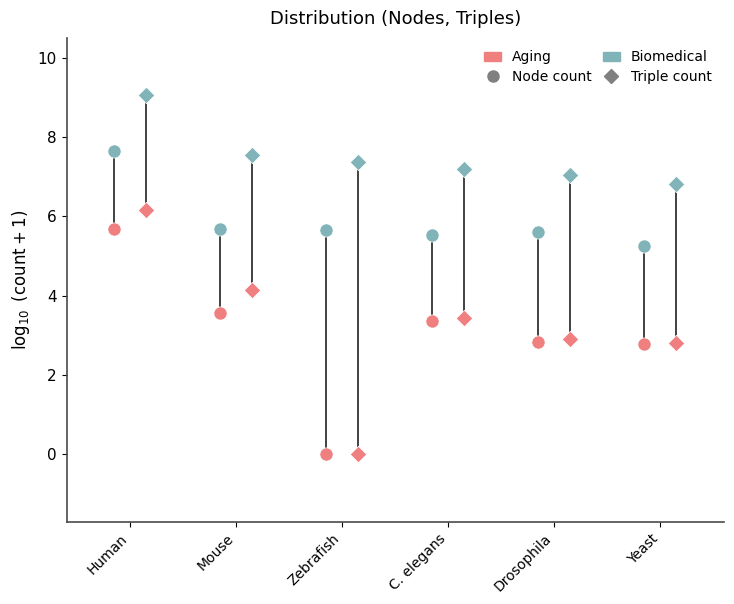

In [86]:
import matplotlib
matplotlib.rcParams['svg.fonttype'] = 'none'
matplotlib.rcParams['font.family'] = 'sans-serif'
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import numpy as np
import pandas as pd
from matplotlib.patches import Circle, Ellipse

# ── File paths ────────────────────────────────────────────────────────────────
AGING_NODES_CSV   = "/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/aging_121_12M_Species_NodeType_unique_counts.csv"
AGING_TRIPLES_CSV = "/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/aging_121_12M_RelationType_AllSpecies.csv"
BIO_NODES_CSV     = "/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/Species_Biomedical_121_12M_NodeType_unique_counts.csv"
BIO_TRIPLES_CSV   = "/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/Species_Biomedical_121_12M_RelationType_unique_counts.csv"

OUTPUT_SVG = "nodes_triples_dumbbell.svg"
OUTPUT_PNG = "nodes_triples_dumbbell.png"

# ── Colors ────────────────────────────────────────────────────────────────────
AGING_COL = '#F08080'   # salmon
BIO_COL   = '#80b4b9'   # teal

# ── Species order (left → right on x-axis, matching icon order) ───────────────
# Column names as they appear in CSVs → display label
SPECIES_MAP = {
    'Human':      'Human',
    'Mouse':      'Mouse',
    'Zebrafish':  'Zebrafish',
    'Celegans':   'C. elegans',
    'Drosophila': 'Drosophila',
    'Yeast':      'Yeast',
}
SPECIES_COLS  = list(SPECIES_MAP.keys())   # CSV column names
SPECIES_ORDER = list(SPECIES_MAP.keys())   # plot order

# ── Load & extract TOTAL row ──────────────────────────────────────────────────
def load_total_row(filepath, total_col_value):
    """
    Reads a CSV where the first column is a label column.
    Returns a dict {species_col: count} for the row whose
    first-column value matches `total_col_value`.
    """
    df = pd.read_csv(filepath)
    label_col = df.columns[0]
    row = df[df[label_col] == total_col_value].iloc[0]
    return {sp: int(row[sp]) if sp in df.columns else 0 for sp in SPECIES_COLS}

aging_nodes   = load_total_row(AGING_NODES_CSV,   'TOTAL')
aging_triples = load_total_row(AGING_TRIPLES_CSV,  'Total Triples')
bio_nodes     = load_total_row(BIO_NODES_CSV,      'TOTAL')
bio_triples   = load_total_row(BIO_TRIPLES_CSV,    'Total Triples')

# ── log10(count + 1) helper ───────────────────────────────────────────────────
def log1(val):
    return np.log10(val + 1)

# ── Figure ────────────────────────────────────────────────────────────────────
x_pos  = np.arange(len(SPECIES_ORDER), dtype=float)
OFFSET = 0.15   # left stem = nodes, right stem = triples

fig, ax = plt.subplots(figsize=(7.5, 6.2))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

for i, sp in enumerate(SPECIES_ORDER):
    cx = x_pos[i]

    an = log1(aging_nodes[sp])
    bn = log1(bio_nodes[sp])
    at = log1(aging_triples[sp])
    bt = log1(bio_triples[sp])

    x_node   = cx - OFFSET   # left  dumbbell → node counts
    x_triple = cx + OFFSET   # right dumbbell → triple counts

    # vertical stems
    ax.plot([x_node,   x_node],   [an, bn], color='#333333', lw=1.3, zorder=1, solid_capstyle='round')
    ax.plot([x_triple, x_triple], [at, bt], color='#333333', lw=1.3, zorder=1, solid_capstyle='round')

    # node dumbbell: circles
    ax.scatter(x_node, an, marker='o', s=90, color=AGING_COL, zorder=4, linewidths=0.5, edgecolors='white')
    ax.scatter(x_node, bn, marker='o', s=90, color=BIO_COL,   zorder=4, linewidths=0.5, edgecolors='white')

    # triple dumbbell: diamonds
    ax.scatter(x_triple, at, marker='D', s=70, color=AGING_COL, zorder=4, linewidths=0.5, edgecolors='white')
    ax.scatter(x_triple, bt, marker='D', s=70, color=BIO_COL,   zorder=4, linewidths=0.5, edgecolors='white')

# ── Axes formatting ───────────────────────────────────────────────────────────
ax.set_ylabel(r'$\log_{10}\ (\mathrm{count}+1)$', fontsize=12)
ax.set_xticks(x_pos)
# Add species names as x-axis labels
ax.set_xticklabels([SPECIES_MAP[sp] for sp in SPECIES_ORDER], fontsize=10, rotation=45, ha='right')
ax.set_xlim(-0.6, len(SPECIES_ORDER) - 0.4)
ax.set_ylim(-1.7, 10.5)
ax.set_yticks(range(0, 11, 2))
ax.tick_params(axis='y', labelsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.2)
ax.spines['left'].set_linewidth(1.2)
ax.set_title('Distribution (Nodes, Triples)', fontsize=13, pad=10)

# ── Legend ────────────────────────────────────────────────────────────────────
aging_patch = mpatches.Patch(color=AGING_COL, label='Aging')
bio_patch   = mpatches.Patch(color=BIO_COL,   label='Biomedical')
node_marker = mlines.Line2D([], [], color='grey', marker='o', linestyle='None', markersize=8, label='Node count')
tri_marker  = mlines.Line2D([], [], color='grey', marker='D', linestyle='None', markersize=7, label='Triple count')
ax.legend(
    handles=[aging_patch, node_marker, bio_patch, tri_marker],
    loc='upper right', fontsize=10, frameon=False, ncol=2,
    handlelength=1.2, columnspacing=0.8, labelspacing=0.4,
)

# ── Save ──────────────────────────────────────────────────────────────────────
plt.tight_layout()
plt.savefig(OUTPUT_SVG, format='svg', bbox_inches='tight')
plt.savefig(OUTPUT_PNG, dpi=200, bbox_inches='tight')
print(f"Saved: {OUTPUT_SVG}, {OUTPUT_PNG}")

## 1f

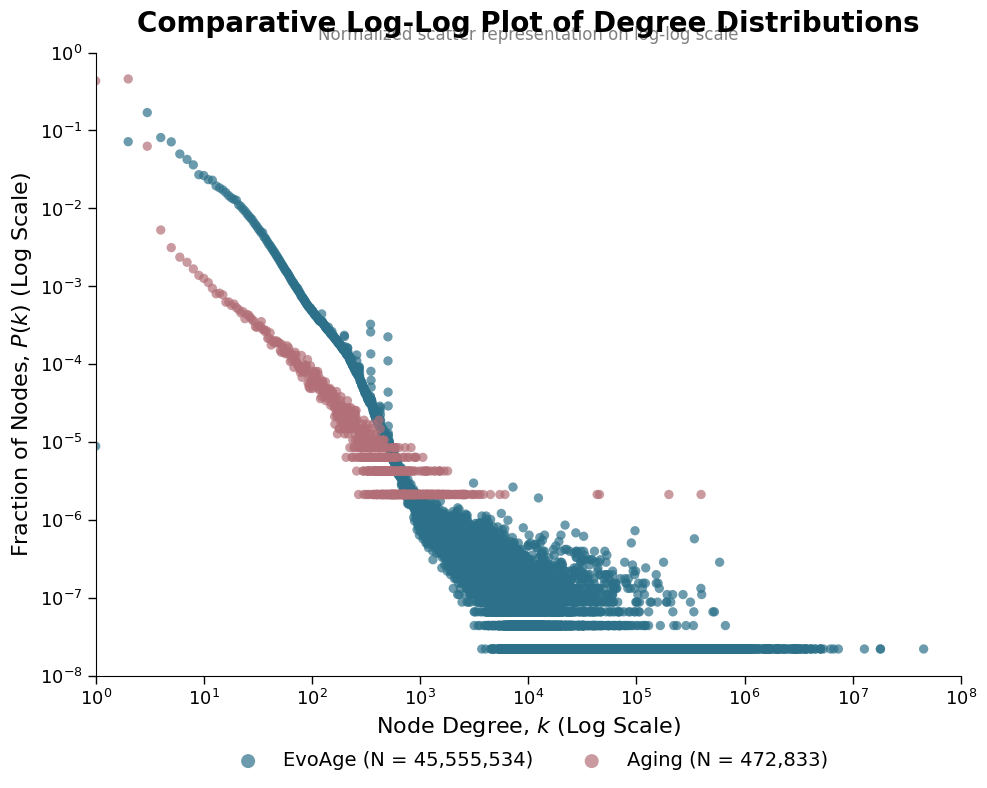

In [54]:
# /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_degree.csv
# /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_degree.csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_degree.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_degree.csv"

aging  = pd.read_csv(aging_path)
evoage = pd.read_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. BUILD NORMALIZED DEGREE DISTRIBUTION: P(k) = fraction of nodes with degree k
# -----------------------------------------------------------------------------
def to_distribution(df, model_name):
    N = len(df)
    dist = (
        df["total_degree"]
        .value_counts()
        .rename_axis("degree")
        .reset_index(name="num_nodes")
    )
    dist["P_k"] = dist["num_nodes"] / N          # normalize by total node count
    dist["Model"] = model_name
    dist["N"] = N
    return dist

aging_dist  = to_distribution(aging,  "Aging")
evoage_dist = to_distribution(evoage, "EvoAge")

N_aging  = len(aging)
N_evoage = len(evoage)

data_long = pd.concat([evoage_dist, aging_dist], ignore_index=True)
data_long = data_long[(data_long["degree"] > 0) & (data_long["P_k"] > 0)]

# -----------------------------------------------------------------------------
# 3. PLOT (log-log scatter)
# -----------------------------------------------------------------------------
colors = {"EvoAge": "#2c7189", "Aging": "#b26f77"}
labels = {"EvoAge": f"EvoAge (N = {N_evoage:,})",
          "Aging":  f"Aging (N = {N_aging:,})"}

fig, ax = plt.subplots(figsize=(10, 8))

for model in ["EvoAge", "Aging"]:
    subset = data_long[data_long["Model"] == model]
    ax.scatter(
        subset["degree"], subset["P_k"],
        color=colors[model], s=45, alpha=0.7,
        edgecolor="none", label=labels[model],
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10, numticks=15))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=15))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"$10^{{{int(np.log10(x))}}}$"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"$10^{{{int(np.log10(x))}}}$"))

# Auto-fit limits to actual data
max_deg = data_long["degree"].max()
ax.set_xlim(1, 10 ** np.ceil(np.log10(max_deg)))

min_pk = data_long["P_k"].min()
ax.set_ylim(10 ** np.floor(np.log10(min_pk)), 1)

ax.set_title("Comparative Log-Log Plot of Degree Distributions",
             fontsize=20, fontweight="bold", pad=15)
ax.text(0.5, 1.02, "Normalized scatter representation on log-log scale",
        transform=ax.transAxes, ha="center", fontsize=12, color="gray")
ax.set_xlabel("Node Degree, $k$ (Log Scale)", fontsize=16)
ax.set_ylabel("Fraction of Nodes, $P(k)$ (Log Scale)", fontsize=16)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="both", which="major", length=6, width=1, color="black", labelsize=13)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False, which="major")
ax.grid(False, which="minor")

ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.18),
          ncol=2, frameon=False, fontsize=14, markerscale=1.5)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_h_main.pdf", format="pdf", bbox_inches="tight")
plt.savefig("FIG1/fig1h-degree.png", format="png", bbox_inches="tight")
plt.show()

## 1g


=== Summary ===
Aging   | Nodes: 472,833 | Communities: 100 | Largest: 78.71% | Entropy: 0.815
Biomedical  | Nodes: 45,228,611 | Communities: 3,223 | Largest: 26.07% | Entropy: 2.310



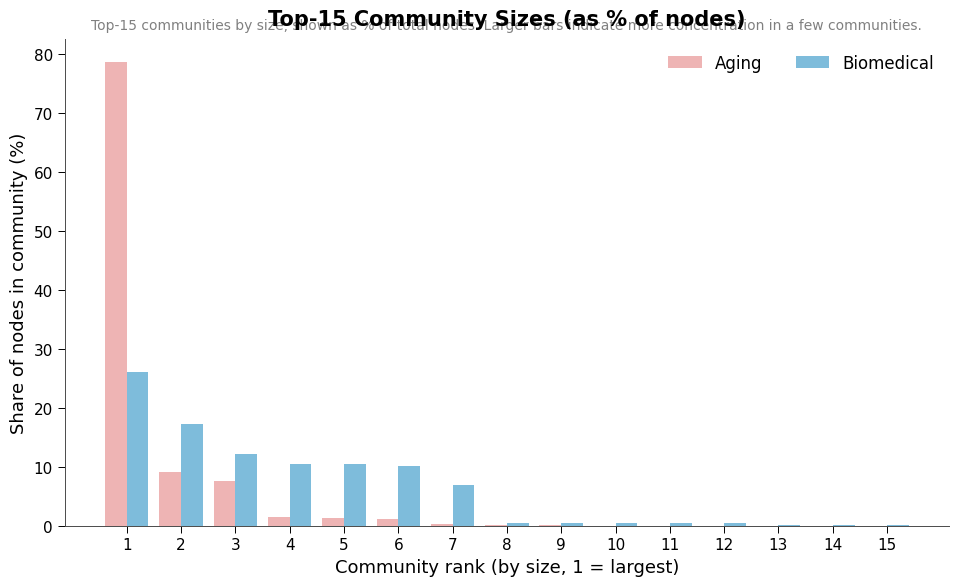

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_louvain_partitions.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Biomedical_121_12M/Biomedical_121_12M_louvain_partitions.csv"

def read_louvain_csv(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.lower()
    if not {"vertex", "partition"}.issubset(df.columns):
        raise ValueError(f"Expected 'vertex' and 'partition' columns in {path}, got {list(df.columns)}")
    return df[["vertex", "partition"]]

aging_raw  = read_louvain_csv(aging_path)
evoage_raw = read_louvain_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. COMMUNITY SIZE TABLES
# -----------------------------------------------------------------------------
def community_sizes(df):
    return (
        df.groupby("partition")
          .size()
          .reset_index(name="size")
          .sort_values("size", ascending=False)
          .reset_index(drop=True)
    )

aging_sizes  = community_sizes(aging_raw)
evoage_sizes = community_sizes(evoage_raw)

N_aging  = len(aging_raw)
N_evoage = len(evoage_raw)

# -----------------------------------------------------------------------------
# 3. QUICK STATS (mirrors R's cat block)
# -----------------------------------------------------------------------------
def entropy(sizes):
    p = sizes / sizes.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log(p)))

print("\n=== Summary ===")
print(f"Aging   | Nodes: {N_aging:,} | Communities: {len(aging_sizes):,} | "
      f"Largest: {100*aging_sizes['size'].max()/N_aging:.2f}% | "
      f"Entropy: {entropy(aging_sizes['size'].values):.3f}")
print(f"Biomedical  | Nodes: {N_evoage:,} | Communities: {len(evoage_sizes):,} | "
      f"Largest: {100*evoage_sizes['size'].max()/N_evoage:.2f}% | "
      f"Entropy: {entropy(evoage_sizes['size'].values):.3f}\n")

# -----------------------------------------------------------------------------
# 4. TOP-K COMMUNITIES
# -----------------------------------------------------------------------------
K = 15

top_aging = aging_sizes.head(K).copy()
top_aging["rank"]  = np.arange(1, len(top_aging) + 1)
top_aging["pct"]   = 100 * top_aging["size"] / N_aging
top_aging["graph"] = "Aging"

top_evoage = evoage_sizes.head(K).copy()
top_evoage["rank"]  = np.arange(1, len(top_evoage) + 1)
top_evoage["pct"]   = 100 * top_evoage["size"] / N_evoage
top_evoage["graph"] = "Biomedical"

top_df = pd.concat([top_aging, top_evoage], ignore_index=True)

# -----------------------------------------------------------------------------
# 5. PLOT — grouped bar chart
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "Biomedical": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(10, 6))

ranks = np.arange(1, K + 1)
width = 0.4

aging_vals  = top_df[top_df["graph"] == "Aging"].set_index("rank").reindex(ranks)["pct"].fillna(0)
evoage_vals = top_df[top_df["graph"] == "Biomedical"].set_index("rank").reindex(ranks)["pct"].fillna(0)

ax.bar(ranks - width/2, aging_vals,  width=width, color=colors["Aging"],  label="Aging",
       edgecolor="none")
ax.bar(ranks + width/2, evoage_vals, width=width, color=colors["Biomedical"], label="Biomedical",
       edgecolor="none")

ax.set_xticks(ranks)
ax.set_xticklabels(ranks, fontsize=11)

ax.set_title(f"Top-{K} Community Sizes (as % of nodes)",
             fontsize=15, fontweight="bold", pad=10)
ax.text(0.5, 1.02,
        f"Top-{K} communities by size, shown as % of total nodes. "
        "Larger bars indicate more concentration in a few communities.",
        transform=ax.transAxes, ha="center", fontsize=10, color="gray")

ax.set_xlabel("Community rank (by size, 1 = largest)", fontsize=13)
ax.set_ylabel("Share of nodes in community (%)", fontsize=13)

# theme_classic-ish
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(0.7)
ax.spines["bottom"].set_linewidth(0.7)
ax.tick_params(axis="both", which="major", length=5, width=0.7, color="black", labelsize=11)
ax.grid(False)

ax.legend(loc="upper right", frameon=False, fontsize=12, ncol=2)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 6. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/aging-biomedical-commmunity.pdf", format="pdf", bbox_inches="tight")
plt.show()

## 1h

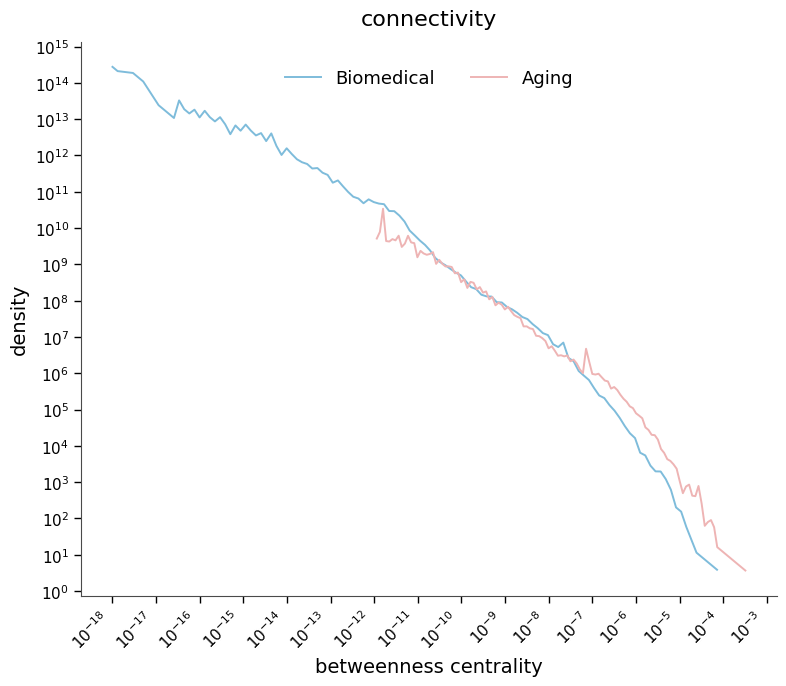

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_betweenness_centrality_sorted.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Biomedical_121_12M/Biomedical_121_12M_betweenness_centrality_sorted.csv"

df_aging  = pd.read_csv(aging_path)
df_evoage = pd.read_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. CONFIG
# -----------------------------------------------------------------------------
TARGET_ROWS = 2_000_000
NBINS_PDF   = 120
SEED        = 42

# -----------------------------------------------------------------------------
# 3. HELPERS
# -----------------------------------------------------------------------------
def positive_vec(x, min_positive=1e-12):
    """Keep only finite, positive values (required for log-scale)."""
    x = pd.to_numeric(x, errors="coerce").to_numpy()
    x = x[np.isfinite(x)]
    x = x[x > 0]
    return x if len(x) else np.array([min_positive])

def log_binned_pdf(arr, nbins=120):
    """Width-corrected PDF using log-spaced bins."""
    lo, hi = arr.min(), arr.max()
    if hi <= lo:
        return np.array([hi]), np.array([1.0])
    bins = np.logspace(np.log10(lo), np.log10(hi), nbins + 1)
    counts, edges = np.histogram(arr, bins=bins)
    widths = np.diff(edges)
    total = counts.sum()
    pdf = np.where(widths > 0, (counts / total) / widths, 0)
    centers = np.sqrt(edges[:-1] * edges[1:])   # geometric mean of bin edges
    # keep only bins with non-zero density (log axis can't plot 0)
    mask = pdf > 0
    return centers[mask], pdf[mask]

# -----------------------------------------------------------------------------
# 4. PREP
# -----------------------------------------------------------------------------
# Subsample EvoAge if too large (matches R's TARGET_ROWS = 2e6 on df2)
if len(df_evoage) > TARGET_ROWS:
    df_evoage = df_evoage.sample(n=TARGET_ROWS, random_state=SEED)

a_aging  = positive_vec(df_aging["betweenness_centrality"])
a_evoage = positive_vec(df_evoage["betweenness_centrality"])

x_aging,  y_aging  = log_binned_pdf(a_aging,  NBINS_PDF)
x_evoage, y_evoage = log_binned_pdf(a_evoage, NBINS_PDF)

# -----------------------------------------------------------------------------
# 5. PLOT
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "Biomedical": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(x_evoage, y_evoage, color=colors["Biomedical"], linewidth=1.4, label="Biomedical")
ax.plot(x_aging,  y_aging,  color=colors["Aging"],  linewidth=1.4, label="Aging")

ax.set_xscale("log")
ax.set_yscale("log")

# 10^n tick formatting
def sci_fmt(x, _):
    return f"$10^{{{int(np.log10(x))}}}$"

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(sci_fmt))

# Labels
ax.set_title("connectivity", fontsize=16, pad=12)
ax.set_xlabel("betweenness centrality", fontsize=14)
ax.set_ylabel("density", fontsize=14)

# Rotate x tick labels a bit (matches your reference image)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# Clean minimal look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", length=5, width=1, color="black", labelsize=11)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False)

# Legend top-center inside plot
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98),
          ncol=2, frameon=False, fontsize=13)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 6. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/aging-biomedical-centrality.pdf", format="pdf", bbox_inches="tight")
plt.show()

## 1i


=== Triangle Count Summary ===
Aging   | Nodes: 15,225  | zero-triangle nodes: 0.00%
Biomedical  | Nodes: 35,595,483 | zero-triangle nodes: 0.00%



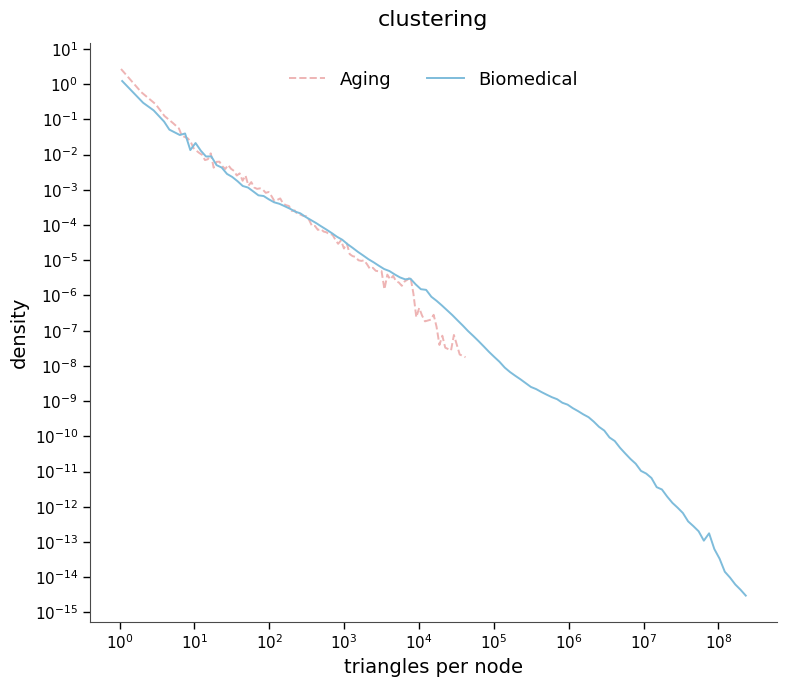

<Figure size 640x480 with 0 Axes>

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M_vertex_counts.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Biomedical_121_12M/Biomedical_121_12M_vertex_counts.csv"

def read_tri_csv(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.lower()
    if not {"vertex", "counts"}.issubset(df.columns):
        raise ValueError(f"Expected 'vertex' and 'counts' columns in {path}, got {list(df.columns)}")
    return df[["vertex", "counts"]].apply(pd.to_numeric, errors="coerce")

aging_raw  = read_tri_csv(aging_path)
evoage_raw = read_tri_csv(evoage_path)

N_aging  = len(aging_raw)
N_evoage = len(evoage_raw)

# -----------------------------------------------------------------------------
# 2. QUICK STATS
# -----------------------------------------------------------------------------
aging_zero  = (aging_raw["counts"]  <= 0).mean()
evoage_zero = (evoage_raw["counts"] <= 0).mean()

print("\n=== Triangle Count Summary ===")
print(f"Aging   | Nodes: {N_aging:,}  | zero-triangle nodes: {100*aging_zero:.2f}%")
print(f"Biomedical  | Nodes: {N_evoage:,} | zero-triangle nodes: {100*evoage_zero:.2f}%\n")

# Keep positive counts for log-scale
pos_aging  = aging_raw.loc[aging_raw["counts"]  > 0, "counts"].to_numpy()
pos_evoage = evoage_raw.loc[evoage_raw["counts"] > 0, "counts"].to_numpy()

# -----------------------------------------------------------------------------
# 3. LOG-BINNED PDF (matches R's hist(..., include.lowest=TRUE, right=FALSE))
# -----------------------------------------------------------------------------
def log_binned_pdf(arr, nbins=120):
    arr = arr[np.isfinite(arr) & (arr > 0)]
    if len(arr) == 0:
        return np.array([1.0]), np.array([1.0])

    lo, hi = arr.min(), arr.max()
    if hi <= lo:
        return np.array([hi]), np.array([1.0])

    bins = np.logspace(np.log10(lo), np.log10(hi), nbins + 1)

    # Replicate R's right=FALSE, include.lowest=TRUE:
    # left-closed, right-open intervals [a,b); include max value in last bin
    idx = np.digitize(arr, bins, right=False)
    idx[arr == bins[-1]] = nbins   # include the maximum value in the last bin
    counts = np.bincount(idx, minlength=nbins + 2)[1:nbins + 1]

    widths = np.diff(bins)
    total = counts.sum()
    pdf = np.where(widths > 0, (counts / total) / widths, 0)
    centers = np.sqrt(bins[:-1] * bins[1:])

    mask = pdf > 0
    return centers[mask], pdf[mask]

x_aging,  y_aging  = log_binned_pdf(pos_aging,  nbins=120)
x_evoage, y_evoage = log_binned_pdf(pos_evoage, nbins=120)

# -----------------------------------------------------------------------------
# 4. PLOT
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "Biomedical": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(8, 7))

# Aging as dashed line (matches your reference image)
ax.plot(x_aging,  y_aging,  color=colors["Aging"],
        linewidth=1.4, linestyle="--", label="Aging")
ax.plot(x_evoage, y_evoage, color=colors["Biomedical"],
        linewidth=1.4, linestyle="-",  label="Biomedical")

ax.set_xscale("log")
ax.set_yscale("log")

def sci_fmt(x, _):
    return f"$10^{{{int(np.log10(x))}}}$"

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(sci_fmt))

ax.set_title("clustering", fontsize=16, pad=12)
ax.set_xlabel("triangles per node", fontsize=14)
ax.set_ylabel("density", fontsize=14)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", length=5, width=1, color="black", labelsize=11)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98),
          ncol=2, frameon=False, fontsize=13)

plt.tight_layout()
plt.show()
# -----------------------------------------------------------------------------
# 5. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/aging-biomedical-clustering.pdf", format="pdf", bbox_inches="tight")

## Main Figure 2

## 2b

In [239]:
"""
3-set Venn across both KG variants (1:1 vs 121_12M, sharing the same test set),
for all three KG families — Aging, Biomedical, EvoAge.
"""
import gc
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib_venn import venn3

# ============================================================
# CONFIG
# ============================================================
FAMILIES = {
    "Aging": {
        "full_1to1": "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/building_aging_kg_new/Store_House/Aging_specific_1_to_1_KG.pt",
        "test":      "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/building_aging_kg_new/Store_House/Aging_specific_1to1_KG_test_10_shared.pt",
        "full_12m":  "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/building_aging_kg_new/Store_House/Aging_specific_121_12M_KG.pt",
    },
    "Biomedical": {
        "full_1to1": "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/building_biomedical_kg_new/Store_House/Biomedical_1_to_1_KG.pt",
        "test":      "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/building_biomedical_kg_new/Store_House/Biomedical_1to1_KG_test_10_shared.pt",
        "full_12m":  "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/building_biomedical_kg_new/Store_House/Biomedical_121_12M_KG.pt",
    },
    "EvoAge": {
        "full_1to1": "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/building_evoage_kg_new/Store_House/EvoAge_1_to_1_KG.pt",
        "test":      "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/building_evoage_kg_new/Store_House/EvoAge_1to1_KG_test_10_shared.pt",
        "full_12m":  "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/building_evoage_kg_new/Store_House/EvoAge_121_12M_to_many_KG.pt",
    },
}

ASSUME_UNIQUE_INPUT = False   # True -> sort only, skip dedupe (if files already unique)
UNWEIGHTED          = True    # True -> readable fixed layout; False -> area-proportional
USE_GPU             = False   # True -> CuPy path (needs cupy + enough VRAM per set)

xp = np
if USE_GPU:
    import cupy as cp
    xp = cp

# ============================================================
# LOADER  -> (N,3) int64 on CPU
# ============================================================
def load_triples_pt(path):
    obj = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(obj, torch.Tensor) and obj.ndim == 2 and obj.shape[1] == 3:
        return obj.numpy().astype(np.int64, copy=False)
    if isinstance(obj, dict):
        for key in ("triples", "edge_triples", "all_triples"):
            if key in obj:
                return np.asarray(obj[key], dtype=np.int64)
        if "edge_index" in obj and "edge_type" in obj:
            h, t = np.asarray(obj["edge_index"]); r = np.asarray(obj["edge_type"])
            return np.stack([h, r, t], axis=1).astype(np.int64)
    if hasattr(obj, "edge_index") and hasattr(obj, "edge_type"):
        h, t = obj.edge_index.numpy(); r = obj.edge_type.numpy()
        return np.stack([h, r, t], axis=1).astype(np.int64)
    raise ValueError(f"Unrecognized structure in {path}: type={type(obj)}")

# ============================================================
# helpers
# ============================================================
def unique_keys(triples, r_max, t_max):
    h = xp.asarray(triples[:, 0]); r = xp.asarray(triples[:, 1]); t = xp.asarray(triples[:, 2])
    keys = (h * r_max + r) * t_max + t            # bijective packing
    return xp.sort(keys) if ASSUME_UNIQUE_INPUT else xp.unique(keys)

def isin_mask(query, ref):
    """Which elements of sorted query are present in sorted ref."""
    if ref.size == 0:
        return xp.zeros(query.size, dtype=bool)
    idx = xp.clip(xp.searchsorted(ref, query), 0, ref.size - 1)
    return ref[idx] == query

def count_in(query, ref):                          # pass the SMALLER array as query
    return int(isin_mask(query, ref).sum())

# version-robust unweighted layout
def make_venn3(subsets, labels, ax, unweighted=True):
    if not unweighted:
        return venn3(subsets=subsets, set_labels=labels, ax=ax)
    try:
        # newer matplotlib_venn (>=1.0): fixed_subset_sizes, no normalize_to
        from matplotlib_venn.layout.venn3 import DefaultLayoutAlgorithm
        layout = DefaultLayoutAlgorithm(fixed_subset_sizes=(1, 1, 1, 1, 1, 1, 1))
        return venn3(subsets=subsets, set_labels=labels, ax=ax, layout_algorithm=layout)
    except ImportError:
        # older matplotlib_venn: the deprecated helper still works
        from matplotlib_venn import venn3_unweighted
        return venn3_unweighted(subsets=subsets, set_labels=labels, ax=ax)

# ============================================================
# per-family Venn
# ============================================================
def venn_for_family(family, paths):
    raw = {
        "Full 1:1 KG":     load_triples_pt(paths["full_1to1"]),
        "Test (shared)":   load_triples_pt(paths["test"]),
        "Full 121_12M KG": load_triples_pt(paths["full_12m"]),
    }

    # shared packing bases within THIS family so keys are comparable across its three sets
    r_max = max(int(a[:, 1].max()) for a in raw.values()) + 1
    t_max = max(int(a[:, 2].max()) for a in raw.values()) + 1
    h_max = max(int(a[:, 0].max()) for a in raw.values())
    assert h_max * r_max * t_max + (r_max - 1) * t_max + (t_max - 1) < 2**63 - 1, \
        f"[{family}] packing overflows int64 — switch to a row-void view for keys"

    keysets = {}
    for name in list(raw):
        keysets[name] = unique_keys(raw[name], r_max, t_max)
        del raw[name]; gc.collect()               # free each large raw array immediately

    A, B, C = keysets["Full 1:1 KG"], keysets["Test (shared)"], keysets["Full 121_12M KG"]
    a, b, c = A.size, B.size, C.size

    # intersections — always query the smaller array
    inBA = isin_mask(B, A); ab = int(inBA.sum())
    AB   = B[inBA]                                 # A∩B keys (small)
    bc   = count_in(B, C)
    ac   = count_in(A, C) if a <= c else count_in(C, A)
    abc  = count_in(AB, C)

    # 7 disjoint regions
    ABC     = abc
    AB_only = ab - abc
    AC_only = ac - abc
    BC_only = bc - abc
    A_only  = a - ab - ac + abc
    B_only  = b - ab - bc + abc
    C_only  = c - ac - bc + abc

    print(f"\n=== {family} ===")
    for name, s in [("Full 1:1 KG", a), ("Test (shared)", b), ("Full 121_12M KG", c)]:
        print(f"  {name:18s}: {s:,} unique triples")
    print(f"  A∩B={ab:,}  A∩C={ac:,}  B∩C={bc:,}  A∩B∩C={abc:,}")

    # matplotlib_venn subset order: (Abc, aBc, ABc, abC, AbC, aBC, ABC)
    subsets = (A_only, B_only, AB_only, C_only, AC_only, BC_only, ABC)
    labels  = ("Full 1:1 KG", "Test (shared)", "Full 121_12M KG")

    fig, ax = plt.subplots(figsize=(9, 9))
    make_venn3(subsets, labels, ax, unweighted=UNWEIGHTED)
    ax.set_title(f"{family}: triple-set provenance across KG variants (real counts)",
                 fontsize=15, fontweight="bold")
    fig.tight_layout()
    out = f"venn_3set_{family}.svg"
    fig.savefig(out, bbox_inches="tight")
    print(f"  saved -> {out}")
    return fig


=== Aging ===
  Full 1:1 KG       : 1,483,098 unique triples
  Test (shared)     : 148,310 unique triples
  Full 121_12M KG   : 1,483,755 unique triples
  A∩B=148,310  A∩C=1,483,087  B∩C=148,310  A∩B∩C=148,310
  saved -> venn_3set_Aging.svg


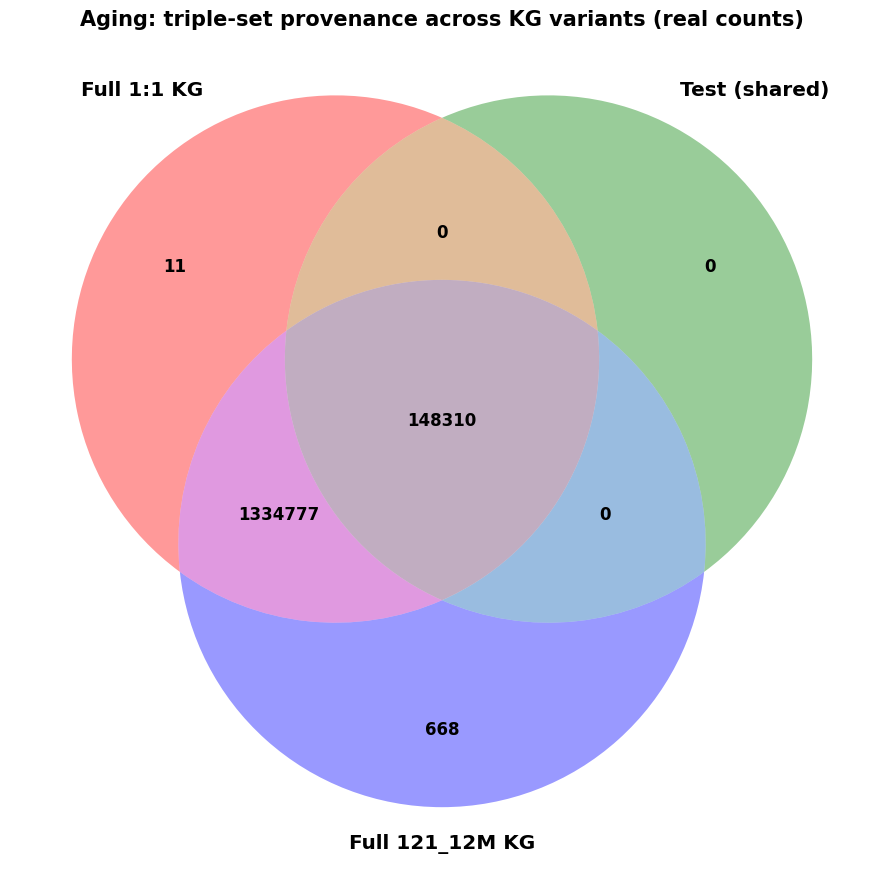

In [240]:
family = "Aging"
fig_aging = venn_for_family(family, FAMILIES[family])
plt.show()


=== Biomedical ===
  Full 1:1 KG       : 1,181,409,142 unique triples
  Test (shared)     : 118,140,804 unique triples
  Full 121_12M KG   : 1,189,088,051 unique triples
  A∩B=118,140,804  A∩C=1,181,408,040  B∩C=118,140,804  A∩B∩C=118,140,804
  saved -> venn_3set_Biomedical.svg


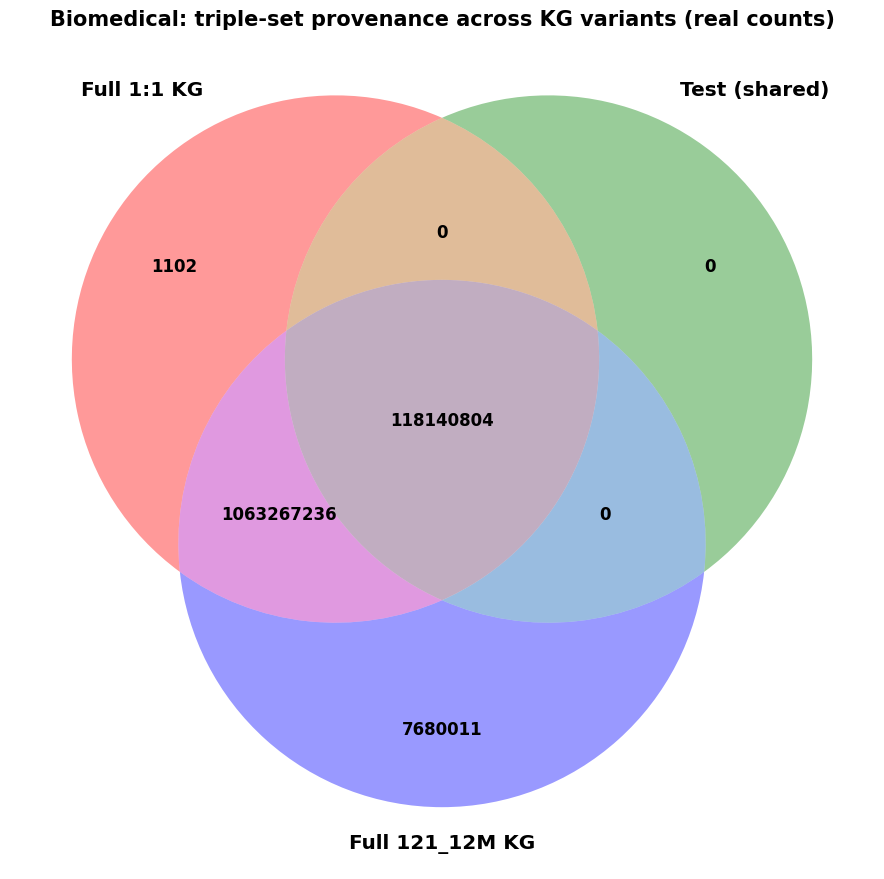

In [241]:
family = "Biomedical"
fig_biomedical = venn_for_family(family, FAMILIES[family])
plt.show()


=== EvoAge ===
  Full 1:1 KG       : 1,229,890,206 unique triples
  Test (shared)     : 118,287,941 unique triples
  Full 121_12M KG   : 1,237,567,801 unique triples
  A∩B=118,287,941  A∩C=1,229,887,985  B∩C=118,287,941  A∩B∩C=118,287,941
  saved -> venn_3set_EvoAge.svg


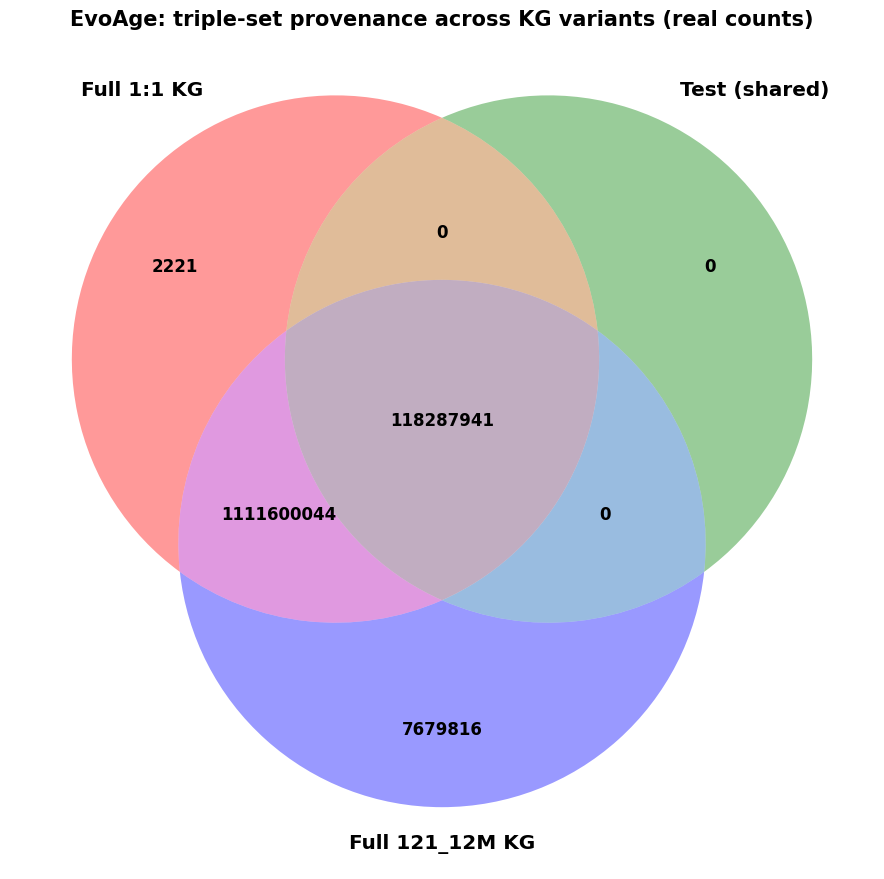

In [242]:
family = "EvoAge"
fig_evoage = venn_for_family(family, FAMILIES[family])
plt.show()

## 2c

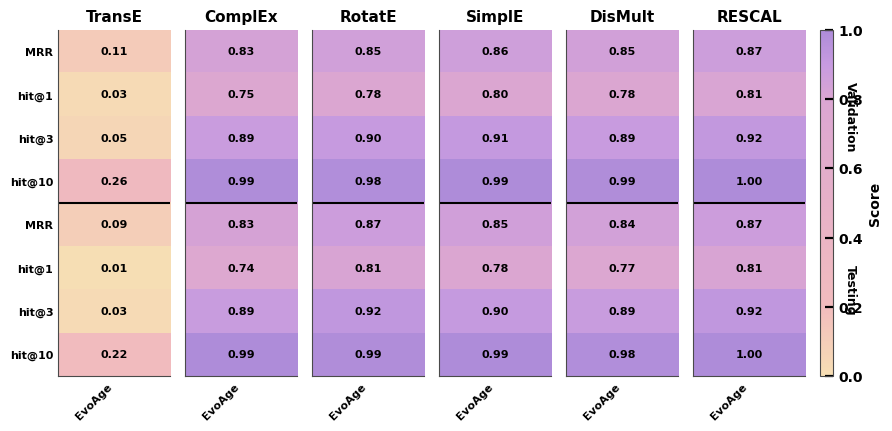

In [219]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap

# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
data = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/Training_Stats/Trained_model_performance_Fig2b.csv')

# ----------------------------------------------------------------------
# 2. Clean / normalize model + graph names
# ----------------------------------------------------------------------
model_map = {
    'complex': 'ComplEx',
    'complexe': 'ComplEx',
    'simple':  'SimplE',
    'simpple': 'SimplE',
    'dismult': 'DisMult',
    'distmult': 'DisMult',
    'rescal':  'RESCAL',
    'rotate':  'RotatE',
    'transe':  'TransE',
}
data['Model'] = data['Model Type'].str.strip().str.lower().map(model_map)

graph_map = {
    'EvoAge_121_12M': 'EvoAge',
    'Aging_121_12M':  'Aging',
}
data['Graph'] = data['Graph'].map(graph_map)

data['metric_type'] = data['metric_type'].str.strip().str.title()  # Validation / Testing

model_order = ['TransE', 'ComplEx', 'RotatE', 'SimplE', 'DisMult', 'RESCAL']
graph_order = ['Aging', 'EvoAge']

# ----------------------------------------------------------------------
# 3. FIGURE 2b — heatmap grid (EvoAge only, MRR + Hit@k)
# ----------------------------------------------------------------------
row_order  = [('Validation', 'MRR'), ('Validation', 'Hit@1'), ('Validation', 'Hit@3'), ('Validation', 'Hit@10'),
              ('Testing',    'MRR'), ('Testing',    'Hit@1'), ('Testing',    'Hit@3'), ('Testing',    'Hit@10')]
row_labels = ['MRR', 'hit@1', 'hit@3', 'hit@10', 'MRR', 'hit@1', 'hit@3', 'hit@10']
n_rows = len(row_order)

fig = plt.figure(figsize=(10, 4.5))
gs = gridspec.GridSpec(1, len(model_order) + 1,
                       width_ratios=[1] * len(model_order) + [0.12],
                       wspace=0.15)

vmin, vmax = 0.0, 1.0
# cmap = LinearSegmentedColormap.from_list('original_paper', ['#FCFDDD', '#A9DDD1', '#5EBBA6'])

# # ----- COLOR GRADIENT: edit these 3 hex codes -----
# COLOR_LOW  = '#FCFDDD'   # lowest values (0.0)
# COLOR_MID  = '#A9DDD1'   # midpoint (0.5)
# COLOR_HIGH = '#5EBBA6'   # highest values (1.0)

# COLOR_LOW  = '#F7FBFF'
# COLOR_MID  = '#6BAED6'
# COLOR_HIGH = '#08306B'
# # cmap = LinearSegmentedColormap.from_list(
# #     'custom3', [COLOR_LOW, COLOR_MID, COLOR_HIGH]
# # )



# cmap = LinearSegmentedColormap.from_list(

#     'custom3',

#     [(0.0, COLOR_LOW), (0.85, COLOR_MID), (1.0, COLOR_HIGH)]   # change 0.5 to shift the middle color

# )

# ----- COLOR GRADIENT: 5 stops -----
C1 = '#F5D49B'   # sand
C2 = '#F0AAAE'   # pink
C3 = '#D98CC8'   # mauve
C4 = '#C063E8'   # violet
C5 = '#9B51E0'   # purple

cmap = LinearSegmentedColormap.from_list('custom5', [C1, C2, C3, C4, C5])

# # ----- COLOR GRADIENT: 5 stops, edit these hex codes -----
# C1 = '#FFFFE5'   # 0.00  lowest
# C2 = '#D9F0A3'   # 0.25
# C3 = '#78C679'   # 0.50
# C4 = '#238443'   # 0.75
# C5 = '#004529'   # 1.00  highest

# cmap = LinearSegmentedColormap.from_list('custom5', [C1, C2, C3, C4, C5])


# ----- COLOR GRADIENT: 5 stops, pastel purple end -----
C1 = '#F7DFB4'   # soft sand
C2 = '#F2BCBE'   # soft pink
C3 = '#DBA6D2'   # soft mauve
C4 = '#C79BE0'   # pastel violet
C5 = '#AE8CD9'   # muted purple

cmap = LinearSegmentedColormap.from_list('custom5', [
    (0.00, C1),
    (0.20, C2),
    (0.80, C3),
    (0.90, C4),
    (1.00, C5),
])


im = None
for i, model in enumerate(model_order):
    ax = fig.add_subplot(gs[0, i])

    mat = np.full((n_rows, 1), np.nan)
    for r, (metric_type, col) in enumerate(row_order):
        sub = data[(data['Model'] == model) &
                   (data['metric_type'] == metric_type) &
                   (data['Graph'] == 'EvoAge')]
        if not sub.empty:
            mat[r, 0] = sub[col].values[0]

    im = ax.imshow(mat, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')

    for r in range(n_rows):
        if not np.isnan(mat[r, 0]):
            ax.text(0, r, f'{mat[r, 0]:.2f}', ha='center', va='center', fontsize=8)

    ax.axhline(3.5, color='black', linewidth=1.5)

    ax.set_title(model, fontsize=11, fontweight='bold')
    ax.set_xticks([0])
    ax.set_xticklabels(['EvoAge'], rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels(row_labels if i == 0 else [], fontsize=8)
    ax.tick_params(length=0)

ax_last = fig.axes[len(model_order) - 1]
ax_last.text(0.85, 1.5, 'Validation', rotation=-90, va='center', fontsize=9)
ax_last.text(0.85, 5.5, 'Testing', rotation=-90, va='center', fontsize=9)

cax = fig.add_subplot(gs[0, -1])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Score', fontsize=10)

plt.tight_layout()
plt.savefig('FIG2/Fig2b_heatmap.svg', dpi=300, bbox_inches='tight')
plt.show()

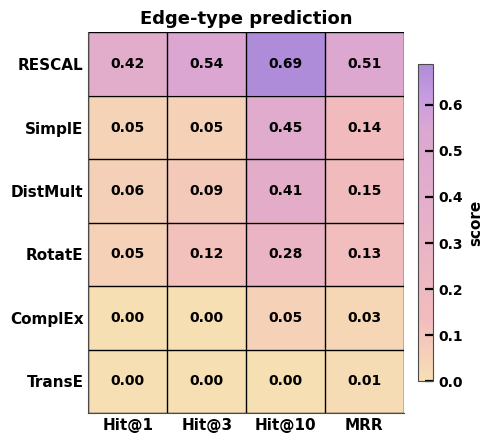

In [220]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
EvoAge_6model_Etype = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/Training_Stats/EvoAge_121_12M_64Emb_EdgeType_testing.csv')
EvoAge_6model_Etype

# ----------------------------------------------------------------------
# 2. Order rows by performance (RESCAL, SimplE, DistMult, RotatE, ComplEx, TransE)
#    and select the columns to plot: Hit@1, Hit@3, Hit@10, MRR
# ----------------------------------------------------------------------
model_order = ['RESCAL', 'SimplE', 'DistMult', 'RotatE', 'ComplEx', 'TransE']
df = EvoAge_6model_Etype.set_index('Model Type').loc[model_order]
cols = ['Hit@1', 'Hit@3', 'Hit@10', 'MRR']
mat = df[cols].values

# ----------------------------------------------------------------------
# 3. FIGURE 2f — edge-type prediction heatmap (Hit@1, Hit@3, Hit@10, MRR)
# ----------------------------------------------------------------------
# ----- COLOR GRADIENT: 5 stops, pastel purple end -----
C1 = '#F7DFB4'   # soft sand
C2 = '#F2BCBE'   # soft pink
C3 = '#DBA6D2'   # soft mauve
C4 = '#C79BE0'   # pastel violet
C5 = '#AE8CD9'   # muted purple

cmap = LinearSegmentedColormap.from_list('custom5', [
    (0.00, C1),
    (0.20, C2),
    (0.80, C3),
    (0.90, C4),
    (1.00, C5),
])

vmin, vmax = 0.0, mat.max()
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(mat, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')

# annotate cells
for r in range(mat.shape[0]):
    for c in range(mat.shape[1]):
        ax.text(c, r, f'{mat[r, c]:.2f}', ha='center', va='center', fontsize=10)

ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, fontsize=11)
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_order, fontsize=11)
ax.tick_params(length=0)

# grid lines between cells
ax.set_xticks(np.arange(-0.5, len(cols), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(model_order), 1), minor=True)
ax.grid(which='minor', color='black', linewidth=1)
ax.tick_params(which='minor', length=0)

ax.set_title('Edge-type prediction', fontsize=13)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('score', fontsize=11)

plt.tight_layout()
plt.savefig('FIG2/Fig2f_edgetype-prediction.svg', dpi=300, bbox_inches='tight')
plt.show()

## 2d

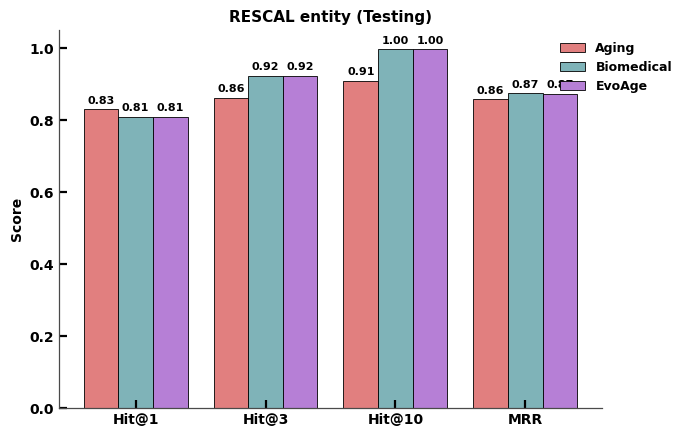

In [202]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['svg.fonttype'] = 'none'

# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
df = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/Training_Stats/EA_A_B_Rescal_selected_metrics.csv')

# ----------------------------------------------------------------------
# 2. Filter: 121_12M ortholog, Testing split only
# ----------------------------------------------------------------------
df['Split'] = df['Split'].str.strip().str.title()
sub = df[(df['Ortholog'] == '121_12M') & (df['Split'] == 'Testing')].copy()

metrics = ['Hit@1', 'Hit@3', 'Hit@10', 'MRR']
metric_ticklabels = ['Hit@1', 'Hit@3', 'Hit@10', 'MRR']
kg_order = ['Aging', 'Biomedical', 'EvoAge']

kg_colors = {
    'Aging': '#e17f7f',       # salmon/pink
    'Biomedical': '#7fb3b8',  # teal
    'EvoAge': '#b67fd6',      # purple
}

# ----------------------------------------------------------------------
# 3. Build plotting matrix: rows = KG, cols = metrics
# ----------------------------------------------------------------------
data = {kg: [sub[sub['KG'] == kg][m].values[0] for m in metrics] for kg in kg_order}

# ----------------------------------------------------------------------
# 4. Grouped bar plot
# ----------------------------------------------------------------------
x = np.arange(len(metrics))
n_kg = len(kg_order)
bar_width = 0.8 / n_kg

fig, ax = plt.subplots(figsize=(7, 4.5))

for i, kg in enumerate(kg_order):
    offset = (i - (n_kg - 1) / 2) * bar_width
    bars = ax.bar(x + offset, data[kg], width=bar_width,
                   color=kg_colors[kg], edgecolor='black', linewidth=0.6,
                   label=kg)
    for rect, val in zip(bars, data[kg]):
        ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 0.01,
                f'{val:.2f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metric_ticklabels, fontsize=10)
ax.set_ylabel('Score', fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_title('RESCAL entity (Testing)', fontsize=11)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(frameon=False, fontsize=9, loc='upper right', bbox_to_anchor=(1.15, 1.0))

plt.tight_layout()
plt.savefig('FIG2/Fig2_121_12M_testing_barplot_rescal_entity.svg', dpi=300, bbox_inches='tight')
plt.show()

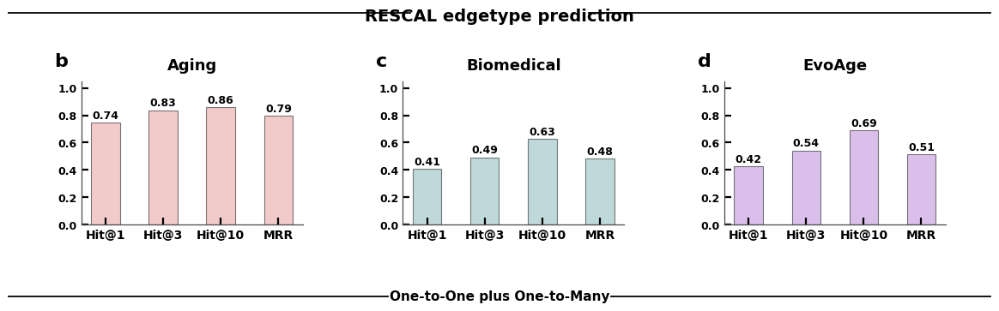

done


In [203]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

mpl.rcParams['svg.fonttype'] = 'none'

# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
EvoAge_Aging_biomed_edgeType = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/Training_Stats/RESCAL_all_KGtype_edgetype_results.csv')

df = EvoAge_Aging_biomed_edgeType.copy()

def get_category(name):
    if name.startswith('Aging'):
        return 'Aging'
    elif name.startswith('Biomedical'):
        return 'Biomedical'
    elif name.startswith('EvoAge'):
        return 'EvoAge'

def get_ortholog_type(name):
    return '1:1' if '1to1' in name else '1:N'

df['Category'] = df['Dataset'].apply(get_category)
df['OrthologType'] = df['Dataset'].apply(get_ortholog_type)
cols = ['Hit@1', 'Hit@3', 'Hit@10', 'MRR']
row_order = ['1:N']

# ----------------------------------------------------------------------
# 2. Flat category colours -- sampled straight from your legend snapshot
# ----------------------------------------------------------------------
panel_colors = {
    "Aging":      "#e69797",
    "Biomedical": "#80b4b9",
    "EvoAge":     "#b780d6",
}
panel_titles = {'Aging': 'Aging', 'Biomedical': 'Biomedical', 'EvoAge': 'EvoAge'}
panel_letters = {'Aging': 'b', 'Biomedical': 'c', 'EvoAge': 'd'}

# 1:1 = solid full colour, 1:N = same hue but lighter (alpha)
bar_alpha = {'1:1': 1.0, '1:N': 0.5}
row_swatch_colors = ['#8b96c9', '#e0a377']  # legend swatches (kept from original style)

# ----------------------------------------------------------------------
# 3. Build one combined figure with 3 grouped-bar panels
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
plt.subplots_adjust(wspace=0.45, top=0.72, bottom=0.28)

x = np.arange(len(cols))
bar_width = 0.5

for ax, category in zip(axes, ['Aging', 'Biomedical', 'EvoAge']):
    sub = df[df['Category'] == category].set_index('OrthologType').loc[row_order]
    color = panel_colors[category]

    vals = sub.loc['1:N', cols].values.astype(float)
    ax.bar(x, vals, width=bar_width,
           color=color, alpha=bar_alpha['1:N'],
           edgecolor='black', linewidth=0.8)
    for xi, v in zip(x, vals):
        ax.text(xi, v + 0.015, f'{v:.2f}', ha='center', va='bottom', fontsize=9)

    ax.set_xticks(x)
    ax.set_xticklabels(['Hit@1', 'Hit@3', 'Hit@10', 'MRR'], fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.tick_params(axis='y', labelsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.set_title(panel_titles[category], fontsize=13, pad=10)

    # panel letter, top-left of panel
    ax.text(-0.12, 1.08, panel_letters[category], fontsize=16, fontweight='bold',
            ha='left', va='bottom', transform=ax.transAxes, clip_on=False)

# top overall title with flanking lines
fig.text(0.5, 0.92, 'RESCAL edgetype prediction', ha='center', va='center',
          fontsize=14, fontweight='bold')
fig.add_artist(Line2D([0.06, 0.42], [0.93, 0.93], color='black', lw=1.3, transform=fig.transFigure))
fig.add_artist(Line2D([0.58, 0.94], [0.93, 0.93], color='black', lw=1.3, transform=fig.transFigure))

# bottom label: One-to-One plus One-to-Many (single group now, no legend split needed)
legend_y = 0.06
fig.text(0.5, legend_y, 'One-to-One plus One-to-Many', ha='center', va='center', fontsize=11)
fig.add_artist(Line2D([0.06, 0.40], [legend_y, legend_y], color='black', lw=1.3, transform=fig.transFigure))
fig.add_artist(Line2D([0.60, 0.94], [legend_y, legend_y], color='black', lw=1.3, transform=fig.transFigure))

plt.savefig('FIG2/Fig2_bcd_RESCAL_bars.svg', bbox_inches='tight')
plt.savefig('FIG2/Fig2_bcd_RESCAL_bars.png', dpi=300, bbox_inches='tight')
plt.show()

print("done")

## 2e

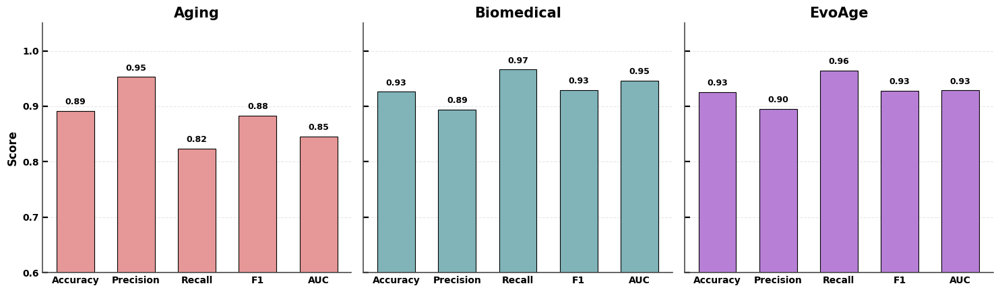

In [221]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# Load data
# --------------------------------------------------
df = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/training_3/InAccuracy_format/combined_classification_accuracy_R4.csv")

graphs = [
    ("Aging_121_12M", "Aging", "#e69797"),
    ("Biomedical_121_12M", "Biomedical", "#80b4b9"),
    ("EvoAge_121_12M", "EvoAge", "#b780d6"),
]
metrics = ["Accuracy", "Precision", "Recall", "F1_Score", "Mean_AUC"]
labels = ["Accuracy", "Precision", "Recall", "F1", "AUC"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.linewidth": 1.2,
    "svg.fonttype": "none"   # keeps text editable in Illustrator/Inkscape
})

# --------------------------------------------------
# Create one figure with 3 panels
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (graph, title, color) in zip(axes, graphs):
    row = df[df["Graph"] == graph].iloc[0]
    values = row[metrics].astype(float).values

    bars = ax.bar(
        np.arange(len(metrics)),
        values,
        width=0.62,
        color=color,
        edgecolor="black",
        linewidth=0.8
    )

    # value labels
    for bar, val in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            val + 0.008,
            f"{val:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_xticks(np.arange(len(metrics)))
    ax.set_xticklabels(labels, fontsize=10)
    ax.set_title(title, fontsize=15, weight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Score", fontsize=12)
axes[0].set_ylim(0.60, 1.05)

# Optional overall title
# fig.suptitle("Node Classification Performance (1:1 + 1:N)", fontsize=16)

plt.tight_layout()

# --------------------------------------------------
# Save ONE SVG and ONE PNG
# --------------------------------------------------
plt.savefig(
    "FIG2/triple_classification_KG_Accuracy_1to1plus1toMany.svg",
    format="svg",
    bbox_inches="tight"
)
plt.savefig(
    "FIG2/_TRIPLE_CLASSIFICATION_KG_Accuracy_1to1plus1toMany.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

## 2f

MONTE CARLO P-VALUE ANALYSIS
Real Test Set vs 30 Shuffled Test Sets

[1/3] Loaded 30 shuffled test set results
   shuffle_id      MRR   HITS@1  HITS@10
0           0 0.564546 0.466329 0.759111
1           1 0.564478 0.466194 0.759229
2           2 0.564802 0.466646 0.759183
3           3 0.564354 0.466079 0.759103
4           4 0.564555 0.466367 0.759084
5           5 0.564738 0.466584 0.759178
6           6 0.564163 0.465845 0.759134
7           7 0.564278  0.46599 0.759115
8           8 0.564812 0.466601 0.759358
9           9 0.564198 0.465847 0.759177

[2/3] Computing Monte Carlo p-values...

 metric  real_value  shuffled_mean  shuffled_std  shuffled_min  shuffled_max  n_shuffles  n_extreme  z_score  cohens_d  p_monte_carlo  p_ztest
    MRR    0.875109       0.564483    0.00025863      0.563968      0.564961          30          0  1201.05   1201.05      0.0322581        0
 HITS@1    0.810538       0.466223   0.000318984      0.465592      0.466736          30          0  1079.41  

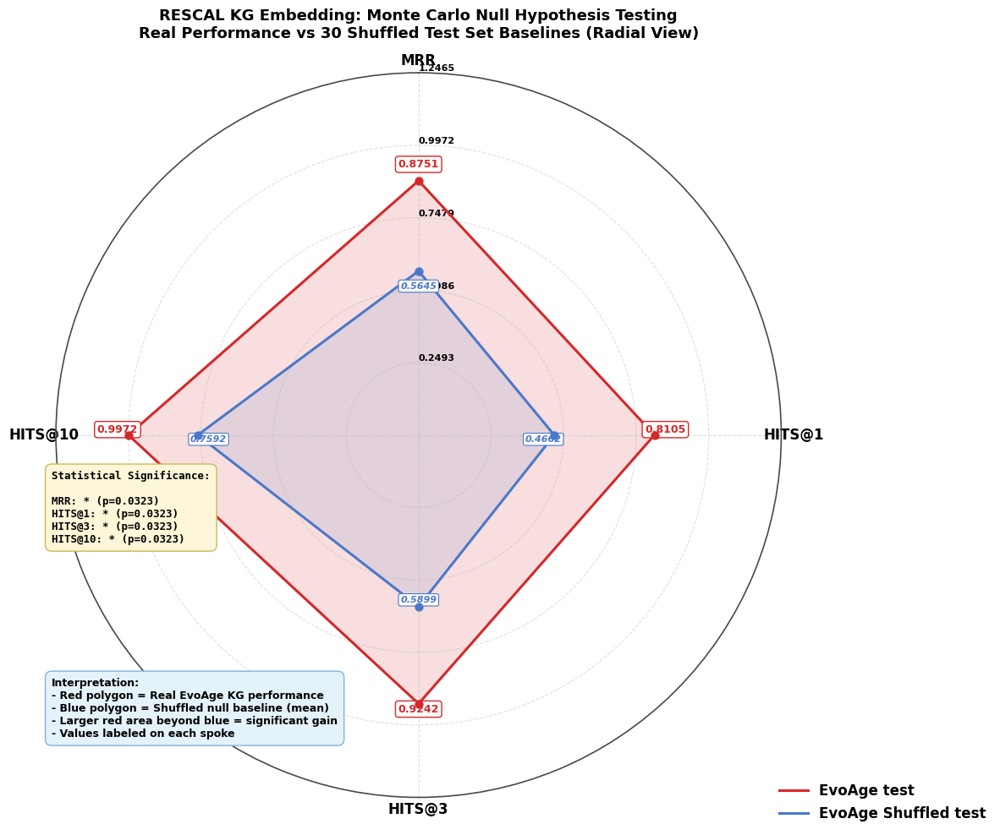


INTERPRETATION

MRR       
  Real:            0.875109
  Shuffled mean:   0.564483  (ratio: 1.55x)
  p-value:         0.032258  * SIGNIFICANT
  Effect size:     Cohen's d = +1201.047

HITS@1    
  Real:            0.810538
  Shuffled mean:   0.466223  (ratio: 1.74x)
  p-value:         0.032258  * SIGNIFICANT
  Effect size:     Cohen's d = +1079.413

HITS@3    
  Real:            0.924235
  Shuffled mean:   0.589921  (ratio: 1.57x)
  p-value:         0.032258  * SIGNIFICANT
  Effect size:     Cohen's d = +1251.545

HITS@10   
  Real:            0.997215
  Shuffled mean:   0.759197  (ratio: 1.31x)
  p-value:         0.032258  * SIGNIFICANT
  Effect size:     Cohen's d = +2258.758



In [223]:
# Edge_type = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training__2/Shuffled_EvoAge_testing/Store_House/shuffled_test_sets/rescal_shuffled_metrics.csv')
# Edge_type
#!/usr/bin/env python3
"""
Monte Carlo P-Value Analysis — Radial (Spider) Plot
Compare real EvoAge test set performance vs 30 shuffled test sets.

Produces a single radial/spider chart (matching the reference figure):
  - Red polygon  = real EvoAge test performance
  - Blue polygon = mean of 30 shuffled null-hypothesis baselines
  - Value labels on every spoke
  - "Statistical Significance" box (per-metric Monte Carlo p-value + marker)
  - "Interpretation" box
Output is saved as a PDF (vector, publication-ready).
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "none"
})

# ---- Your real test set results ----
REAL_RESULTS = {
    'HITS@1': 0.810538,
    'HITS@3': 0.924235,
    'HITS@10': 0.997215,
    'MR': 1.520212,
    'MRR': 0.875109
}

# ---- Load your shuffled results ----
results_df = pd.read_csv(
    '/storage/Arushi/090526_EvoAge/kg_formation/training_3/Shuffled_EvoAge_testing/Store_House/shuffled_test_sets/rescal_shuffled_metrics.csv'
)

print("=" * 70)
print("MONTE CARLO P-VALUE ANALYSIS")
print("Real Test Set vs 30 Shuffled Test Sets")
print("=" * 70)

print(f"\n[1/3] Loaded {len(results_df)} shuffled test set results")
print(results_df[['shuffle_id', 'MRR', 'HITS@1', 'HITS@10']].head(10))

# Order controls the layout of the radial chart (clockwise from the top)
metrics = ['MRR', 'HITS@1', 'HITS@3', 'HITS@10']
# For MRR, HITS@K: higher = better -> test if real is significantly HIGHER
# For MR: lower = better -> test if real is significantly LOWER
higher_is_better = {'MRR': True, 'HITS@1': True, 'HITS@3': True, 'HITS@10': True}

# ---- Compute p-values ----
print("\n[2/3] Computing Monte Carlo p-values...")

summary_rows = []
for metric in metrics:
    shuffled_vals = results_df[metric].dropna().values
    real_val = REAL_RESULTS[metric]
    n = len(shuffled_vals)

    shuffled_mean = shuffled_vals.mean()
    shuffled_std = shuffled_vals.std(ddof=1)
    shuffled_min = shuffled_vals.min()
    shuffled_max = shuffled_vals.max()

    # ---- MONTE CARLO P-VALUE (empirical) ----
    if higher_is_better[metric]:
        n_extreme = np.sum(shuffled_vals >= real_val)
    else:
        n_extreme = np.sum(shuffled_vals <= real_val)

    # Empirical p-value with +1/+1 correction (standard in permutation testing)
    monte_carlo_p = (n_extreme + 1) / (n + 1)

    # ---- Z-TEST P-VALUE (parametric, for reference) ----
    z_score = (real_val - shuffled_mean) / shuffled_std if shuffled_std > 0 else np.nan
    if higher_is_better[metric]:
        z_p = stats.norm.sf(z_score)
    else:
        z_p = stats.norm.cdf(z_score)

    # Cohen's d (effect size)
    cohens_d = (real_val - shuffled_mean) / shuffled_std if shuffled_std > 0 else np.nan

    summary_rows.append({
        'metric': metric,
        'real_value': real_val,
        'shuffled_mean': shuffled_mean,
        'shuffled_std': shuffled_std,
        'shuffled_min': shuffled_min,
        'shuffled_max': shuffled_max,
        'n_shuffles': n,
        'n_extreme': n_extreme,
        'z_score': z_score,
        'cohens_d': cohens_d,
        'p_monte_carlo': monte_carlo_p,
        'p_ztest': z_p
    })

summary_df = pd.DataFrame(summary_rows)

pd.set_option('display.float_format', lambda x: f'{x:.6g}')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("\n" + summary_df.to_string(index=False))

# ---- Save results table ----
output_dir = 'FIG2/'
summary_df.to_csv(f'{output_dir}/monte_carlo_pvalues_vs_shuffled.csv', index=False)
print(f"\n✓ Saved to: {output_dir}/monte_carlo_pvalues_vs_shuffled.csv")

# ---- Radial (spider) plot ----
print("\n[3/3] Creating radial visualization...")


def sig_marker(p):
    if p < 0.001:
        return '***'
    if p < 0.01:
        return '**'
    if p < 0.05:
        return '*'
    return 'n.s.'


real_vals = [summary_df.loc[summary_df['metric'] == m, 'real_value'].values[0] for m in metrics]
shuf_vals = [summary_df.loc[summary_df['metric'] == m, 'shuffled_mean'].values[0] for m in metrics]

N = len(metrics)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
real_plot = real_vals + real_vals[:1]
shuf_plot = shuf_vals + shuf_vals[:1]
angles_plot = angles + angles[:1]

fig = plt.figure(figsize=(11, 10))
ax = fig.add_subplot(111, polar=True)
ax.set_theta_zero_location('N')   # first metric (MRR) at the top
ax.set_theta_direction(-1)        # go clockwise
ax.set_xticks(angles)
ax.set_xticklabels(metrics, fontsize=12, fontweight='bold')

max_r = max(real_vals + shuf_vals) * 1.25
ax.set_ylim(0, max_r)
ax.set_rgrids(np.linspace(max_r / 5, max_r, 5), angle=0, fontsize=8)
ax.grid(alpha=0.4, linestyle='--')

RED = '#d62728'
BLUE = '#4a78c9'

# Real EvoAge performance
ax.plot(angles_plot, real_plot, color=RED, linewidth=2.2, label='EvoAge test')
ax.fill(angles_plot, real_plot, color=RED, alpha=0.15)
ax.scatter(angles, real_vals, color=RED, s=45, zorder=5)

# Shuffled null baseline (mean of 30 shuffles)
ax.plot(angles_plot, shuf_plot, color=BLUE, linewidth=2.2, label='EvoAge Shuffled test')
ax.fill(angles_plot, shuf_plot, color=BLUE, alpha=0.12)
ax.scatter(angles, shuf_vals, color=BLUE, s=45, zorder=5)

# Value labels
for ang, val in zip(angles, real_vals):
    ax.annotate(f'{val:.4f}', xy=(ang, val), xytext=(ang, val + max_r * 0.03),
                ha='center', va='bottom', fontsize=9, fontweight='bold', color=RED,
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=RED, lw=1))

for ang, val in zip(angles, shuf_vals):
    ax.annotate(f'{val:.4f}', xy=(ang, val), xytext=(ang, val - max_r * 0.03),
                ha='center', va='top', fontsize=8, style='italic', color=BLUE,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=BLUE, lw=0.8))

ax.set_title(
    'RESCAL KG Embedding: Monte Carlo Null Hypothesis Testing\n'
    'Real Performance vs 30 Shuffled Test Set Baselines (Radial View)',
    fontsize=13, fontweight='bold', pad=30
)

ax.legend(loc='lower right', bbox_to_anchor=(1.3, -0.05), fontsize=12, frameon=False)

# Statistical significance box
sig_lines = "\n".join(
    f"{row['metric']}: {sig_marker(row['p_monte_carlo'])} (p={row['p_monte_carlo']:.3g})"
    for _, row in summary_df.iterrows()
)
fig.text(0.03, 0.35,
         f"Statistical Significance:\n\n{sig_lines}",
         fontsize=9, family='monospace',
         bbox=dict(boxstyle='round,pad=0.6', fc='#fdf6d8', ec='#c9b95a', lw=1))

# Interpretation box
interp_text = (
    "Interpretation:\n"
    "- Red polygon = Real EvoAge KG performance\n"
    "- Blue polygon = Shuffled null baseline (mean)\n"
    "- Larger red area beyond blue = significant gain\n"
    "- Values labeled on each spoke"
)
fig.text(0.03, 0.12, interp_text, fontsize=9,
         bbox=dict(boxstyle='round,pad=0.6', fc='#e4f2fb', ec='#7fb3d9', lw=1))

fig.tight_layout()

pdf_path = f'{output_dir}/monte_carlo_radial_comparison.pdf'
fig.savefig(pdf_path, format='pdf', bbox_inches='tight')
print(f"✓ Saved radial plot to: {pdf_path}")
plt.show()
plt.close(fig)

# ---- Final interpretation (console) ----
print("\n" + "=" * 70)
print("INTERPRETATION")
print("=" * 70)

for _, row in summary_df.iterrows():
    metric = row['metric']
    real = row['real_value']
    shuffled_mean = row['shuffled_mean']
    p_val = row['p_monte_carlo']
    cohens_d = row['cohens_d']

    if p_val < 0.001:
        sig_text = "*** HIGHLY SIGNIFICANT"
    elif p_val < 0.01:
        sig_text = "** VERY SIGNIFICANT"
    elif p_val < 0.05:
        sig_text = "* SIGNIFICANT"
    else:
        sig_text = "n.s. NOT SIGNIFICANT"

    ratio = real / shuffled_mean if shuffled_mean != 0 else np.inf

    print(f"\n{metric:10s}")
    print(f"  Real:            {real:.6f}")
    print(f"  Shuffled mean:   {shuffled_mean:.6f}  (ratio: {ratio:.2f}x)")
    print(f"  p-value:         {p_val:.6f}  {sig_text}")
    print(f"  Effect size:     Cohen's d = {cohens_d:+.3f}")

print("\n" + "=" * 70)

## 2h

['Species', 'Line_Count', 'Triple_Count']


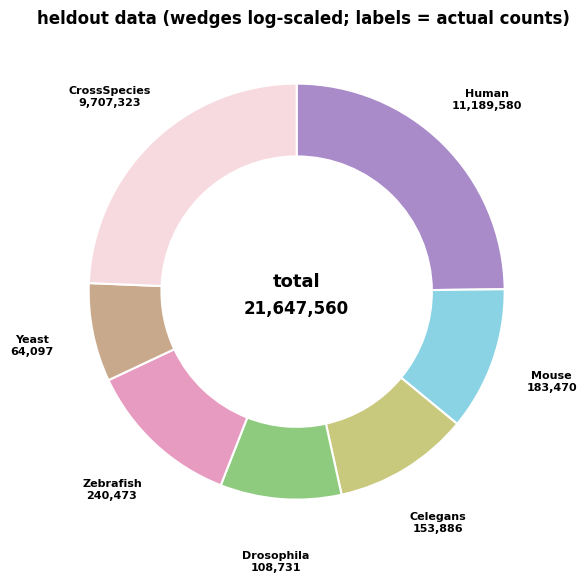

,Species,Line_Count,Triple_Count
0,Human,11189580,33568740
1,Mouse,183470,550410
2,Celegans,153886,461658
3,Drosophila,108731,326193
4,Zebrafish,240473,721419


In [224]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "none"
})
k = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/building_evoage_with_1_percent_species_testsplit/1_per_test_triple_count.csv')
print(k.columns.tolist())

# Color scheme matching original figure
colors = {
    'Human': '#A98BC9',
    'Mouse': '#8AD3E4',
    'Celegans': '#C9C97E',
    'Drosophila': '#8FCB7E',
    'Zebrafish': '#E89BC0',
    'Yeast': '#C9A98B',
    'CrossSpecies': '#F7DADF',
}
order = ['Human', 'Mouse', 'Celegans', 'Drosophila', 'Zebrafish', 'Yeast', 'CrossSpecies']

# ---------- Panel K: donut chart of heldout data (log-scaled wedges, real labels) ----------
k = k.set_index('Species').loc[order].reset_index()

# Log-transform wedge sizes so small species are still visible,
# but keep the real counts as text labels.
log_vals = np.log10(k['Line_Count'])
log_vals = log_vals - log_vals.min() + 1   # shift so smallest still gets a visible wedge

fig, ax = plt.subplots(figsize=(6, 6))
wedges, _ = ax.pie(
    log_vals,
    colors=[colors[s] for s in k['Species']],
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.35, edgecolor='white', linewidth=1.5)
)

total = k['Line_Count'].sum()
ax.text(0, 0.05, 'total', ha='center', va='center', fontsize=13, fontweight='bold')
ax.text(0, -0.08, f'{total:,}', ha='center', va='center', fontsize=12)

# Labels read back from each wedge's true midpoint angle -> can never drift onto the wrong wedge
for w, (_, row) in zip(wedges, k.iterrows()):
    ang = np.radians((w.theta1 + w.theta2) / 2)
    x = 1.3 * np.cos(ang)
    y = 1.3 * np.sin(ang)
    ax.text(x, y, f"{row['Species']}\n{row['Line_Count']:,}",
            ha='center', va='center', fontsize=8)

ax.set_title('heldout data (wedges log-scaled; labels = actual counts)',
             fontsize=12, fontweight='bold', loc='left')
plt.tight_layout()
plt.savefig('FIG2/fig2n.pdf')
plt.show()
plt.close()
k.head()

## 2i

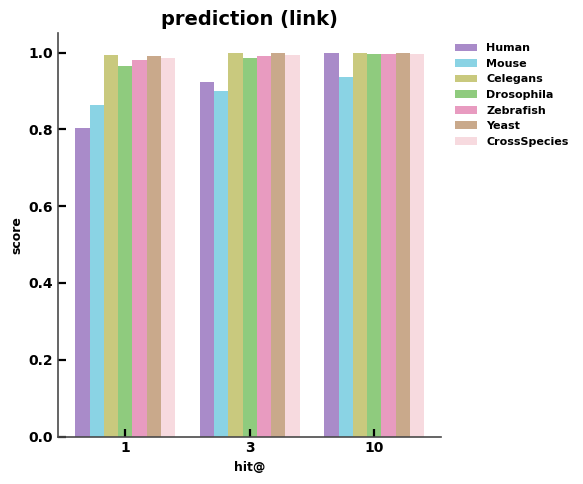

done


In [225]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "none"
})
# ================================================================
# CANONICAL PALETTE  (matches icon legend)
# ================================================================
colors = {
    'Human':        '#A98BC9',
    'Mouse':        '#8AD3E4',
    'Celegans':     '#C9C97E',
    'Drosophila':   '#8FCB7E',
    'Zebrafish':    '#E89BC0',
    'Yeast':        '#C9A98B',
    'CrossSpecies': '#F7DADF',
}
order = ['Human', 'Mouse', 'Celegans', 'Drosophila', 'Zebrafish', 'Yeast', 'CrossSpecies']


# ================================================================
# FIG 2N — heldout-data donut
# ================================================================
def make_donut():
    k = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/'
                    'building_evoage_with_1_percent_species_testsplit/1_per_test_triple_count.csv')
    k = k.set_index('Species').loc[order].reset_index()

    log_vals = np.log10(k['Line_Count'])
    log_vals = log_vals - log_vals.min() + 1   # smallest wedge stays visible

    fig, ax = plt.subplots(figsize=(6, 6))
    wedges, _ = ax.pie(
        log_vals,
        colors=[colors[s] for s in k['Species']],
        startangle=90,
        counterclock=False,
        wedgeprops=dict(width=0.35, edgecolor='white', linewidth=1.5)
    )

    total = k['Line_Count'].sum()
    ax.text(0, 0.05, 'total', ha='center', va='center', fontsize=13, fontweight='bold')
    ax.text(0, -0.08, f'{total:,}', ha='center', va='center', fontsize=12)

    # labels read from each wedge's true midpoint -> never drift onto wrong wedge
    for w, (_, row) in zip(wedges, k.iterrows()):
        ang = np.radians((w.theta1 + w.theta2) / 2)
        x, y = 1.3 * np.cos(ang), 1.3 * np.sin(ang)
        ax.text(x, y, f"{row['Species']}\n{row['Line_Count']:,}",
                ha='center', va='center', fontsize=8)

    ax.set_title('heldout data (wedges log-scaled; labels = actual counts)',
                 fontsize=12, fontweight='bold', loc='left')
    plt.tight_layout()
    plt.savefig('FIG2/fig2n.pdf', bbox_inches='tight')
    plt.close()


# ================================================================
# FIG 2O — link-prediction hit@k grouped bars
# ================================================================
def make_linkpred():
    l = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/'
                    '1_per_species_test_EvoAge_121_12M/rescal_1_percent_test_linkprediction_results.csv')
    l['TestSet'] = l['TestSet'].replace({'Unknown_0': 'Human', 'Unknown_6': 'CrossSpecies'})
    l = l.set_index('TestSet').loc[order].reset_index()   # ordered; index i == order[i]

    hits = ['Hits@1', 'Hits@3', 'Hits@10']
    x_labels = ['1', '3', '10']
    n_species = len(order)
    width = 0.8 / n_species
    x = np.arange(len(hits))

    fig, ax = plt.subplots(figsize=(6, 5))
    for i, sp in enumerate(order):
        vals = l.iloc[i][hits].values.astype(float)   # by position -> no filter mismatch
        ax.bar(x + (i - n_species / 2) * width + width / 2, vals,
               width=width, color=colors[sp], label=sp)

    ax.set_ylim(0, 1.05)
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels)
    ax.set_xlabel('hit@')
    ax.set_ylabel('score')
    ax.set_title('prediction (link)', fontsize=14, fontweight='bold')
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8, frameon=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig('FIG2/fig2o_new.pdf', bbox_inches='tight')
    plt.show()
    plt.close()


if __name__ == '__main__':
    make_donut()
    make_linkpred()
    print('done')

['Human' 'Celegans' 'CrossSpecies' 'Drosophila' 'Mouse' 'Yeast'
 'Zebrafish']


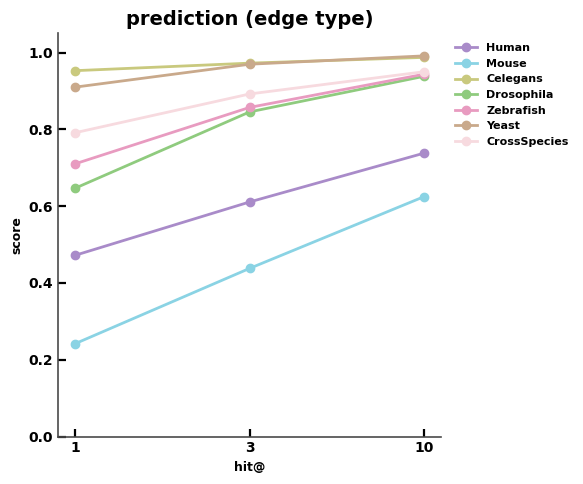

done


In [226]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "none"
})
# ================================================================
# CANONICAL PALETTE  (matches icon legend)
# ================================================================
colors = {
    'Human':        '#A98BC9',
    'Mouse':        '#8AD3E4',
    'Celegans':     '#C9C97E',
    'Drosophila':   '#8FCB7E',
    'Zebrafish':    '#E89BC0',
    'Yeast':        '#C9A98B',
    'CrossSpecies': '#F7DADF',
}
order = ['Human', 'Mouse', 'Celegans', 'Drosophila', 'Zebrafish', 'Yeast', 'CrossSpecies']


# ================================================================
# FIG 2N — heldout-data donut
# ================================================================
def make_donut():
    k = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/'
                    'building_evoage_with_1_percent_species_testsplit/1_per_test_triple_count.csv')
    k = k.set_index('Species').loc[order].reset_index()

    log_vals = np.log10(k['Line_Count'])
    log_vals = log_vals - log_vals.min() + 1   # smallest wedge stays visible

    fig, ax = plt.subplots(figsize=(6, 6))
    wedges, _ = ax.pie(
        log_vals,
        colors=[colors[s] for s in k['Species']],
        startangle=90,
        counterclock=False,
        wedgeprops=dict(width=0.35, edgecolor='white', linewidth=1.5)
    )

    total = k['Line_Count'].sum()
    ax.text(0, 0.05, 'total', ha='center', va='center', fontsize=13, fontweight='bold')
    ax.text(0, -0.08, f'{total:,}', ha='center', va='center', fontsize=12)

    # labels read from each wedge's true midpoint -> never drift onto wrong wedge
    for w, (_, row) in zip(wedges, k.iterrows()):
        ang = np.radians((w.theta1 + w.theta2) / 2)
        x, y = 1.3 * np.cos(ang), 1.3 * np.sin(ang)
        ax.text(x, y, f"{row['Species']}\n{row['Line_Count']:,}",
                ha='center', va='center', fontsize=8)

    ax.set_title('heldout data (wedges log-scaled; labels = actual counts)',
                 fontsize=12, fontweight='bold', loc='left')
    plt.tight_layout()
    plt.savefig('FIG2/fig2n.pdf', bbox_inches='tight')
    plt.close()


# ================================================================
# FIG 2O — link-prediction hit@k grouped bars
# ================================================================
def make_linkpred():
    l = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/'
                    '1_per_species_test_EvoAge_121_12M/rescal_1_percent_test_linkprediction_results.csv')
    l['TestSet'] = l['TestSet'].replace({'Unknown_0': 'Human', 'Unknown_6': 'CrossSpecies'})
    l = l.set_index('TestSet').loc[order].reset_index()   # ordered; index i == order[i]

    hits = ['Hits@1', 'Hits@3', 'Hits@10']
    x_labels = ['1', '3', '10']
    n_species = len(order)
    width = 0.8 / n_species
    x = np.arange(len(hits))

    fig, ax = plt.subplots(figsize=(6, 5))
    for i, sp in enumerate(order):
        vals = l.iloc[i][hits].values.astype(float)   # by position -> no filter mismatch
        ax.bar(x + (i - n_species / 2) * width + width / 2, vals,
               width=width, color=colors[sp], label=sp)

    ax.set_ylim(0, 1.05)
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels)
    ax.set_xlabel('hit@')
    ax.set_ylabel('score')
    ax.set_title('prediction (link)', fontsize=14, fontweight='bold')
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8, frameon=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig('FIG2/fig2o_new.pdf', bbox_inches='tight')
    plt.close()


# ================================================================
# FIG 2P — edge-type prediction hit@k line plot
# ================================================================
def make_edgetype():
    m = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/'
                    '1_per_species_test_EvoAge_121_12M/rescal_1_percent_test_edgeType_results.csv')
    m['TestSet'] = m['TestSet'].replace({'Unknown_0': 'Human', 'Unknown_6': 'CrossSpecies'})
    print(m['TestSet'].unique())

    hits = ['Hits@1', 'Hits@3', 'Hits@10']
    available = m['TestSet'].unique()
    order_m = [s for s in order if s in available]   # keep canonical order, drop missing

    fig, ax = plt.subplots(figsize=(6, 5))
    x_pos = [0, 1, 2]   # evenly spaced positions so '3' sits centered, not skewed toward '1'
    for sp in order_m:
        vals = m.loc[m['TestSet'] == sp, hits].values.flatten().astype(float)
        ax.plot(x_pos, vals, marker='o', color=colors[sp], label=sp, linewidth=2)

    ax.set_ylim(0, 1.05)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(['1', '3', '10'])
    ax.set_xlabel('hit@')
    ax.set_ylabel('score')
    ax.set_title('prediction (edge type)', fontsize=14, fontweight='bold')
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8, frameon=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig('FIG2/fig2p_new.pdf', bbox_inches='tight')
    plt.show()
    plt.close()


if __name__ == '__main__':
    make_donut()
    make_linkpred()
    make_edgetype()
    print('done')

## 2j

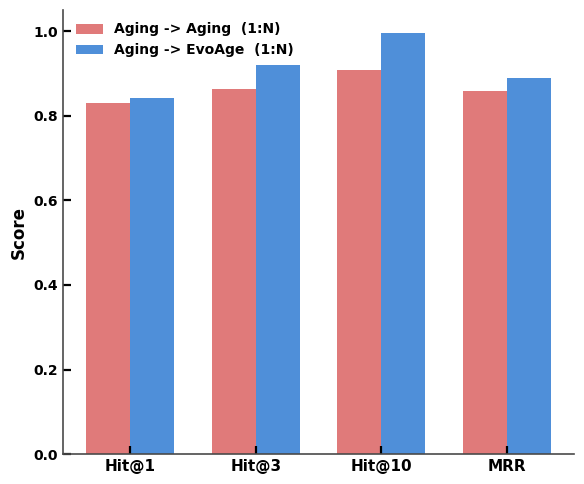

In [227]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "none"
})
# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
dataframe = pd.read_csv(
    "/storage/Arushi/090526_EvoAge/kg_formation/training_3/Agingonly_testing_data/Aging_Only_Testingdata_Evaluated_onall_rescal_trainedKG's_summary.csv"
)

# ----------------------------------------------------------------------
# 2. Keep only 1:N (121_12M)
# ----------------------------------------------------------------------
dataframe = dataframe[dataframe["Ortholog"] == "121_12M"].copy()

ortholog_label = {"121_12M": "1:N"}
dataframe["OrthologLabel"] = dataframe["Ortholog"].map(ortholog_label)
dataframe["Condition"] = dataframe["Graph"] + "  (" + dataframe["OrthologLabel"] + ")"

# Order
condition_order = [
    "Aging -> Aging  (1:N)",
    "Aging -> EvoAge  (1:N)",
]

dataframe["Condition"] = pd.Categorical(
    dataframe["Condition"],
    categories=condition_order,
    ordered=True,
)
dataframe = dataframe.sort_values("Condition")

# Colours
condition_colors = {
    "Aging -> Aging  (1:N)": "#e07a7a",
    "Aging -> EvoAge  (1:N)": "#4f8fd9",
}

metrics = ["Hit@1", "Hit@3", "Hit@10", "MRR"]

# ----------------------------------------------------------------------
# 3. Grouped bar chart
# ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))

n_conditions = len(condition_order)
width = 0.35
x = np.arange(len(metrics))

for i, cond in enumerate(condition_order):
    row = dataframe[dataframe["Condition"] == cond]
    if row.empty:
        continue

    vals = row[metrics].values.flatten()
    offset = (i - (n_conditions - 1) / 2) * width

    ax.bar(
        x + offset,
        vals,
        width,
        label=cond,
        color=condition_colors[cond],
    )

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylabel("Score", fontsize=12)
ax.set_ylim(0, 1.05)

ax.legend(frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("FIG2/2oAging_crossKG_barplot_1N_only.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Main Figure 4

## 4b

In [116]:
from __future__ import annotations
%matplotlib inline

import csv
import re
import shutil
import urllib.parse
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.backends.backend_pdf import PdfPages

# ============================================================
# Configuration
# ============================================================
INPUT = Path('/storage/Arushi/090526_EvoAge/multiagent_hypo/evoage_100_right_inverse/all_LLMs_hypothesis_response.csv')
ROOT = Path('/storage/Arushi/090526_EvoAge/multiagent_hypo/evoage_100_right_inverse/My_final_analysis/My_analysis_doi_paired_retention_plots')
MASTER_PDF = ROOT / 'retention_pie_donut_plots.pdf'

ALL_MODELS = ['EvoAge', 'medgemma', 'BioMistral', 'BioMistralFinetuned']
DISPLAY = {
    'EvoAge': 'EvoAge',
    'medgemma': 'MedGemma',
    'BioMistral': 'BioMistral',
    'BioMistralFinetuned': 'BioMistral fine-tuned',
}
PRIMARY_MODELS = ['EvoAge', 'medgemma', 'BioMistral']
ALT_MODELS = ['EvoAge', 'BioMistral', 'BioMistralFinetuned']

TYPES = ['Right', 'Inverse']
VERDICTS = ['no_support', 'weak_support', 'partial_support', 'support', 'strong_support']
VERDICT_LABELS = ['No support', 'Weak support', 'Partial support', 'Support', 'Strong support']
SCORE = {'no_support': 0, 'weak_support': 1, 'partial_support': 2, 'support': 3, 'strong_support': 4}
UNKNOWN = {'unknown', 'missing', 'unknown/missing', 'unknown / missing', ''}

MODEL_COLORS = {'EvoAge': '#4C72B0', 'medgemma': '#DD8452', 'BioMistral': '#55A868',
                'BioMistralFinetuned': '#937860'}
KEPT_COLOR = '#4C9F70'
REMOVED_COLOR = '#C44E52'
MULTI_COLOR = '#8172B3'
BAR_COLOR = '#1f77b4'

GRADIENT_ENDPOINTS = ['#1a9850', '#d61f96']
_ordinal_cmap = LinearSegmentedColormap.from_list('green_to_magenta', GRADIENT_ENDPOINTS)
VERDICT_COLORS = [_ordinal_cmap(i / (len(VERDICTS) - 1)) for i in range(len(VERDICTS))]

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.labelsize': 9,
    'legend.fontsize': 8,
    'axes.linewidth': 0.8,
    'patch.linewidth': 0.7,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# ============================================================
# Helper Functions
# ============================================================
def normalize_doi(value: str) -> str:
    value = (value or '').strip().lower()
    value = re.sub(r'^https?://(dx\.)?doi\.org/', '', value)
    value = re.sub(r'^doi:\s*', '', value)
    value = urllib.parse.unquote(value).strip().rstrip(' .;,')
    return value

def normalize_verdict(value: str) -> str:
    value = (value or '').strip().lower().replace('-', '_').replace(' ', '_')
    value = re.sub(r'_+', '_', value)
    aliases = {'nosupport': 'no_support', 'partialsupport': 'partial_support',
               'weaksupport': 'weak_support', 'strongsupport': 'strong_support',
               'unknown_missing': 'unknown'}
    return aliases.get(value, value)

def footer(fig, text):
    fig.text(0.01, 0.01, text, ha='left', va='bottom', fontsize=6.5)

def pct_count_autopct(total: int):
    def _fmt(pct):
        count = int(round(pct * total / 100.0))
        return f'{pct:.1f}%\n(n={count})'
    return _fmt

# ============================================================
# Load and Process Data
# ============================================================
with INPUT.open(newline='', encoding='utf-8-sig') as handle:
    reader = csv.DictReader(handle)
    raw = []
    for row in reader:
        model = row['model'].strip()
        if model not in ALL_MODELS:
            continue
        raw.append({
            'doi': normalize_doi(row['DOI']),
            'model': model,
            'hypothesis_type': row['hypothesis_type'].strip().title(),
            'verdict': normalize_verdict(row['verdict']),
        })

by_doi = defaultdict(list)
for row in raw:
    by_doi[row['doi']].append(row)
dois = sorted(by_doi)

lookup_all = {(r['doi'], r['model'], r['hypothesis_type']): r for r in raw}

def scores(model: str, direction: str, doi_list) -> np.ndarray:
    return np.array([SCORE[lookup_all[(doi, model, direction)]['verdict']] for doi in doi_list], dtype=float)

# Filtering
trigger_rows = [r for r in raw if r['model'] in set(ALL_MODELS) and r['verdict'] in UNKNOWN]
excluded_dois = sorted({r['doi'] for r in trigger_rows})
retained_dois = [doi for doi in dois if doi not in set(excluded_dois)]

n_total = len(dois)
n_removed = len(excluded_dois)
n_kept = len(retained_dois)

flagged_by = defaultdict(set)
for r in trigger_rows:
    flagged_by[r['doi']].add(r['model'])

per_model_removed = {m: len({r['doi'] for r in trigger_rows if r['model'] == m}) for m in PRIMARY_MODELS}
per_model_kept = {m: n_total - per_model_removed[m] for m in PRIMARY_MODELS}

attribution = Counter()
for doi, models in flagged_by.items():
    if len(models) == 1:
        attribution[next(iter(models))] += 1
    else:
        attribution['Multiple'] += 1

print(f"Data loaded: {n_total} total DOIs, {n_kept} retained, {n_removed} removed")

Data loaded: 101 total DOIs, 86 retained, 15 removed


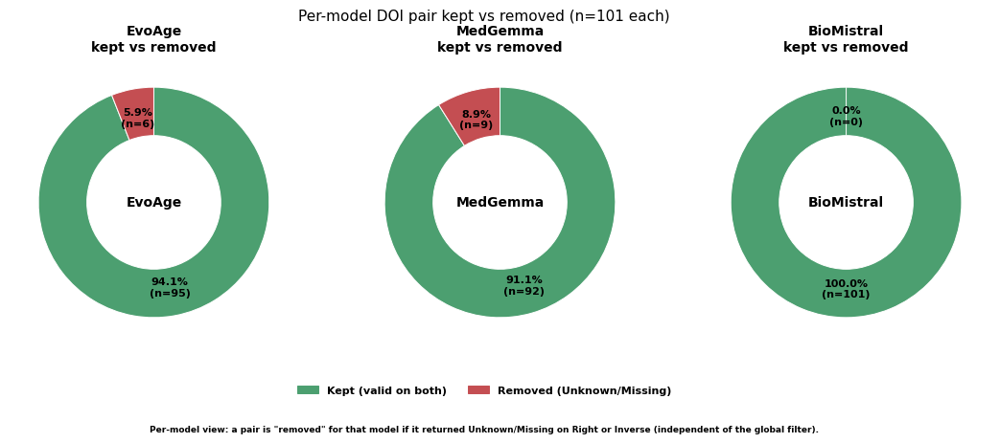

✅ Plot 3: Per-model Kept vs Removed Donuts


In [121]:
# ============================================================
# Plot 3: Per-model % kept vs % removed (Donut Charts)
# ============================================================
fig, axes = plt.subplots(1, len(PRIMARY_MODELS), figsize=(4.4 * len(PRIMARY_MODELS), 4.6))
for ax, model in zip(axes, PRIMARY_MODELS):
    ax.pie([per_model_kept[model], per_model_removed[model]], 
           colors=[KEPT_COLOR, REMOVED_COLOR],
           autopct=pct_count_autopct(n_total), startangle=90, counterclock=False,
           wedgeprops=dict(width=0.42, edgecolor='white'), pctdistance=0.75, 
           textprops=dict(fontsize=8))
    ax.text(0, 0, DISPLAY[model], ha='center', va='center', fontsize=10, fontweight='bold')
    ax.set_title(f'{DISPLAY[model]}\nkept vs removed', fontsize=10)
fig.subplots_adjust(bottom=0.2)
handles = [plt.Rectangle((0, 0), 1, 1, color=KEPT_COLOR), 
           plt.Rectangle((0, 0), 1, 1, color=REMOVED_COLOR)]
fig.legend(handles, ['Kept (valid on both)', 'Removed (Unknown/Missing)'],
           ncol=2, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 0.08))
fig.suptitle(f'Per-model DOI pair kept vs removed (n={n_total} each)', fontsize=11)
fig.text(0.5, 0.015, 'Per-model view: a pair is "removed" for that model if it returned Unknown/Missing on Right or Inverse (independent of the global filter).',
         ha='center', va='bottom', fontsize=6.5)
plt.show()
print("✅ Plot 3: Per-model Kept vs Removed Donuts")

## 4c

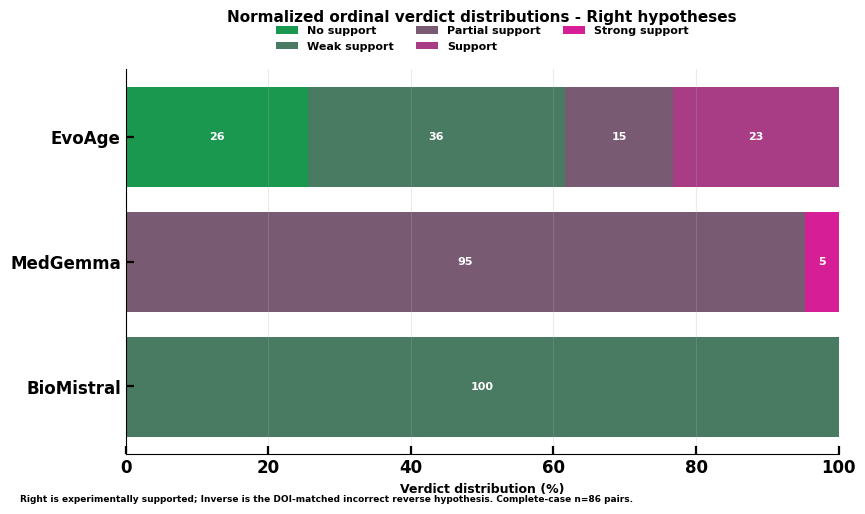

✅ Plot 4: Ordinal Distributions - Primary Models (Right)


In [122]:
# ============================================================
# Plot 4: Ordinal distributions - Primary Models (Right)
# ============================================================
def ordinal_percent_matrix(models, direction, doi_list):
    matrix = np.zeros((len(models), len(VERDICTS)))
    for i, model in enumerate(models):
        counts = np.zeros(len(VERDICTS))
        for doi in doi_list:
            counts[SCORE[lookup_all[(doi, model, direction)]['verdict']]] += 1
        matrix[i] = counts / counts.sum() * 100
    return matrix

models = PRIMARY_MODELS
direction = 'Right'
matrix = ordinal_percent_matrix(models, direction, retained_dois)

fig, ax = plt.subplots(figsize=(9.2, 5.0))
y = np.arange(len(models))
left = np.zeros(len(models))
for j, (label, color) in enumerate(zip(VERDICT_LABELS, VERDICT_COLORS)):
    ax.barh(y, matrix[:, j], left=left, label=label, color=color)
    for i in range(len(models)):
        value = matrix[i, j]
        if value >= 4.0:
            ax.text(left[i] + value / 2, i, f'{value:.0f}', ha='center', va='center', fontsize=8, color='white')
    left += matrix[:, j]
ax.set_yticks(y, [DISPLAY[m] for m in models])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Verdict distribution (%)')
ax.set_title(f'Normalized ordinal verdict distributions - {direction} hypotheses', pad=34)
ax.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.02))
ax.grid(axis='x', alpha=0.25)
footer(fig, f'Right is experimentally supported; Inverse is the DOI-matched incorrect reverse hypothesis. Complete-case n={len(retained_dois)} pairs.')
plt.show()
print("✅ Plot 4: Ordinal Distributions - Primary Models (Right)")

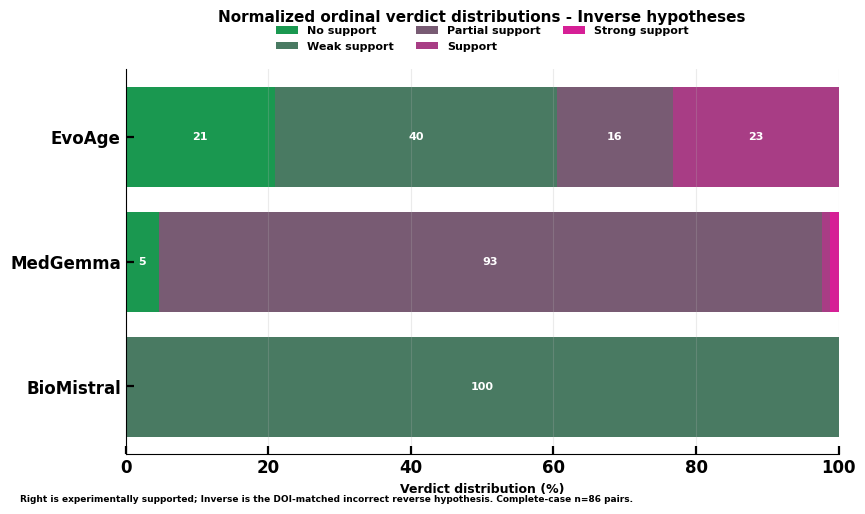

✅ Plot 5: Ordinal Distributions - Primary Models (Inverse)


In [123]:
# ============================================================
# Plot 5: Ordinal distributions - Primary Models (Inverse)
# ============================================================
models = PRIMARY_MODELS
direction = 'Inverse'
matrix = ordinal_percent_matrix(models, direction, retained_dois)

fig, ax = plt.subplots(figsize=(9.2, 5.0))
y = np.arange(len(models))
left = np.zeros(len(models))
for j, (label, color) in enumerate(zip(VERDICT_LABELS, VERDICT_COLORS)):
    ax.barh(y, matrix[:, j], left=left, label=label, color=color)
    for i in range(len(models)):
        value = matrix[i, j]
        if value >= 4.0:
            ax.text(left[i] + value / 2, i, f'{value:.0f}', ha='center', va='center', fontsize=8, color='white')
    left += matrix[:, j]
ax.set_yticks(y, [DISPLAY[m] for m in models])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Verdict distribution (%)')
ax.set_title(f'Normalized ordinal verdict distributions - {direction} hypotheses', pad=34)
ax.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.02))
ax.grid(axis='x', alpha=0.25)
footer(fig, f'Right is experimentally supported; Inverse is the DOI-matched incorrect reverse hypothesis. Complete-case n={len(retained_dois)} pairs.')
plt.show()
print("✅ Plot 5: Ordinal Distributions - Primary Models (Inverse)")

## 4d

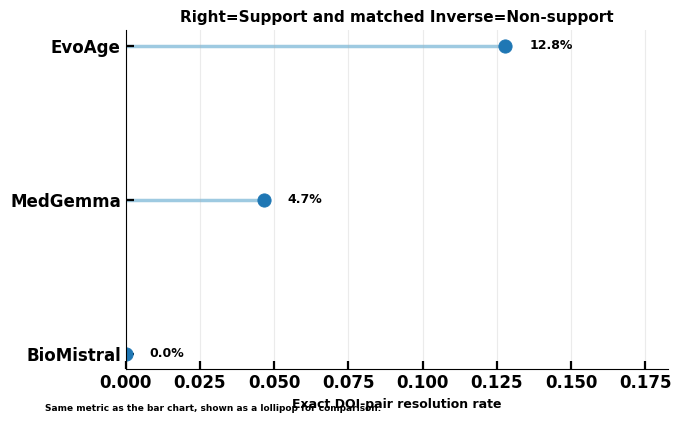

✅ Plot 7: Exact Pair Resolution Lollipop


In [124]:
# ============================================================
# Plot 7: Exact pair resolution (Lollipop)
# ============================================================
fig, ax = plt.subplots(figsize=(7.0, 4.4))
y = np.arange(len(PRIMARY_MODELS))
ax.hlines(y, 0, exact_rates, color='#9ecae1', linewidth=2.5, zorder=1)
ax.scatter(exact_rates, y, color=BAR_COLOR, s=90, zorder=2)
for yi, value in zip(y, exact_rates):
    ax.text(value + max(exact_rates + [0.01]) * 0.04 + 0.003, yi, f'{value:.1%}', va='center', fontsize=9)
ax.set_yticks(y, [DISPLAY[m] for m in PRIMARY_MODELS])
ax.invert_yaxis()
ax.set_xlim(0, max(exact_rates + [0.05]) * 1.35 + 0.01)
ax.set_xlabel('Exact DOI-pair resolution rate')
ax.set_title('Right=Support and matched Inverse=Non-support')
ax.grid(axis='x', alpha=0.25)
footer(fig, 'Same metric as the bar chart, shown as a lollipop for comparison.')
plt.show()
print("✅ Plot 7: Exact Pair Resolution Lollipop")

## 4f

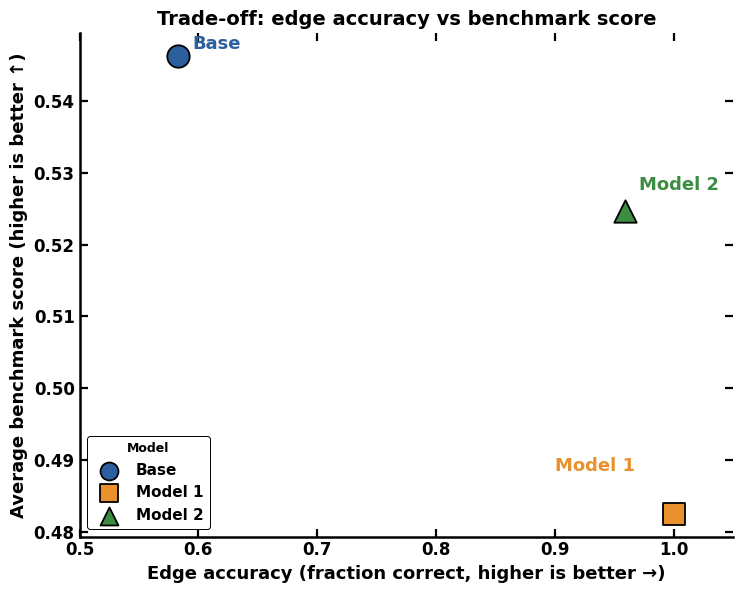

In [125]:
# ============================================================================
# PLOT 1: Trade-off: edge accuracy vs benchmark score
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import re
import os

# Configuration
PATH_BASE = "judge_results_base_resolved_common.csv"
PATH_FT3 = "judge_results_3_2_resolved_common.csv"
PATH_FT4 = "judge_results_4_2_resolved_common.csv"
PATH_BENCH = "model-accuracy.csv"
OUTDIR = "outputs"
os.makedirs(OUTDIR, exist_ok=True)

MODEL_ORDER = ["Base", "Model 1", "Model 2"]
MODEL_COLORS = {"Base": "#2C5F9E", "Model 1": "#E8912D", "Model 2": "#3C8C42"}
MODEL_MARKERS = {"Base": "o", "Model 1": "s", "Model 2": "^"}

mpl.rcParams.update({
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.linewidth": 1.8,
    "axes.edgecolor": "black",
    "xtick.major.width": 1.6,
    "ytick.major.width": 1.6,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.fontsize": 11,
    "legend.edgecolor": "black",
    "legend.framealpha": 1.0,
})

def style_axes(ax):
    ax.tick_params(which="both", top=True, right=True, direction="in")
    for spine in ax.spines.values():
        spine.set_linewidth(1.8)
        spine.set_color("black")

def resolve_prediction(row):
    pred = str(row.get("resolved_answer", "")).upper().strip()
    if pred in {"TRUE", "FALSE"}:
        return pred
    raw = str(row.get("judge_raw_response", "")).upper()
    has_true = bool(re.search(r"\bTRUE\b", raw))
    has_false = bool(re.search(r"\bFALSE\b", raw))
    if has_true and not has_false:
        return "TRUE"
    if has_false and not has_true:
        return "FALSE"
    return "OTHER"

def load_judge_csv(path):
    df = pd.read_csv(path)
    if df["ground_truth"].dtype != bool:
        df["ground_truth"] = df["ground_truth"].astype(str).str.upper().map({"TRUE": True, "FALSE": False})
    df["prediction"] = df.apply(resolve_prediction, axis=1)
    df["answer_cat"] = df["prediction"].map({"TRUE": "Yes", "FALSE": "No", "OTHER": "Unresolved"})
    return df

def compute_model_stats(df):
    n = len(df)
    committed = df[df["answer_cat"] != "Unresolved"]
    cols = ["Yes", "No", "Unresolved"]
    conf_counts = df.groupby(["ground_truth", "answer_cat"]).size().unstack(fill_value=0).reindex(index=[True, False], columns=cols, fill_value=0)
    conf_frac = conf_counts.div(conf_counts.sum(axis=1), axis=0)
    resolved_frac = len(committed) / n
    true_committed = committed[committed["ground_truth"] == True]
    false_committed = committed[committed["ground_truth"] == False]
    recall_true = (true_committed["answer_cat"] == "Yes").mean() * 100
    recall_false = (false_committed["answer_cat"] == "No").mean() * 100
    affirm_frac = (committed["answer_cat"] == "Yes").mean() * 100
    edge_accuracy = df["accuracy"].mean()
    prevalence = committed["ground_truth"].mean() * 100
    return {"n": n, "conf_counts": conf_counts, "conf_frac": conf_frac, "resolved_frac": resolved_frac,
            "recall_true": recall_true, "recall_false": recall_false, "affirm_frac": affirm_frac,
            "edge_accuracy": edge_accuracy, "prevalence": prevalence}

dfs = {"Base": load_judge_csv(PATH_BASE), "Model 1": load_judge_csv(PATH_FT3), "Model 2": load_judge_csv(PATH_FT4)}
stats = {name: compute_model_stats(df) for name, df in dfs.items()}

bench_df = pd.read_csv(PATH_BENCH)
bench_df["Model"] = bench_df["Model"].replace({"Finetuned 3": "Model 1", "Finetuned 4": "Model 2"})
bench_cols = [c for c in bench_df.columns if c not in ("Model", "Node Loss (U/W)", "Edge Loss (U/W)", "Combined Loss (U/W)")]
bench_df["avg_bench"] = bench_df[bench_cols].mean(axis=1)
avg_bench = dict(zip(bench_df["Model"], bench_df["avg_bench"]))

# Plot
fig, ax = plt.subplots(figsize=(7.5, 6))
label_offsets = {"Base": (0.012, 0.001), "Model 1": (-0.10, 0.006), "Model 2": (0.012, 0.003)}
for name in MODEL_ORDER:
    x = stats[name]["edge_accuracy"]
    y = avg_bench[name]
    ax.scatter(x, y, s=260, marker=MODEL_MARKERS[name], color=MODEL_COLORS[name], 
               edgecolor="black", linewidth=1.3, label=name, zorder=3)
    dx, dy = label_offsets[name]
    ax.annotate(name, (x, y), xytext=(x + dx, y + dy), fontsize=13, fontweight="bold", color=MODEL_COLORS[name])
ax.set_xlabel("Edge accuracy (fraction correct, higher is better \u2192)")
ax.set_ylabel("Average benchmark score (higher is better \u2191)")
ax.set_title("Trade-off: edge accuracy vs benchmark score")
ax.set_xlim(0.5, 1.05)
style_axes(ax)
legend = ax.legend(title="Model", loc="lower left", markerscale=0.8)
legend.get_title().set_fontweight("bold")
fig.tight_layout()
fig.savefig(f"{OUTDIR}/fig1_tradeoff_accuracy_vs_benchmark.svg")
plt.show()
plt.close(fig)

## 4g

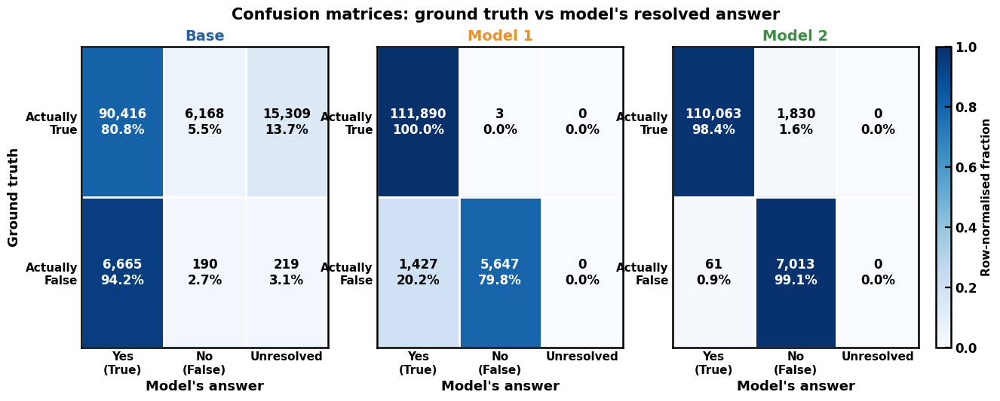

In [126]:
# ============================================================================
# PLOT 2: Confusion matrices: ground truth vs model's resolved answer
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import re
import os

# Configuration
PATH_BASE = "judge_results_base_resolved_common.csv"
PATH_FT3 = "judge_results_3_2_resolved_common.csv"
PATH_FT4 = "judge_results_4_2_resolved_common.csv"
OUTDIR = "outputs"
os.makedirs(OUTDIR, exist_ok=True)

MODEL_ORDER = ["Base", "Model 1", "Model 2"]
MODEL_COLORS = {"Base": "#2C5F9E", "Model 1": "#E8912D", "Model 2": "#3C8C42"}

mpl.rcParams.update({
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.linewidth": 1.8,
    "axes.edgecolor": "black",
    "xtick.major.width": 1.6,
    "ytick.major.width": 1.6,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.fontsize": 11,
    "legend.edgecolor": "black",
    "legend.framealpha": 1.0,
})

def resolve_prediction(row):
    pred = str(row.get("resolved_answer", "")).upper().strip()
    if pred in {"TRUE", "FALSE"}:
        return pred
    raw = str(row.get("judge_raw_response", "")).upper()
    has_true = bool(re.search(r"\bTRUE\b", raw))
    has_false = bool(re.search(r"\bFALSE\b", raw))
    if has_true and not has_false:
        return "TRUE"
    if has_false and not has_true:
        return "FALSE"
    return "OTHER"

def load_judge_csv(path):
    df = pd.read_csv(path)
    if df["ground_truth"].dtype != bool:
        df["ground_truth"] = df["ground_truth"].astype(str).str.upper().map({"TRUE": True, "FALSE": False})
    df["prediction"] = df.apply(resolve_prediction, axis=1)
    df["answer_cat"] = df["prediction"].map({"TRUE": "Yes", "FALSE": "No", "OTHER": "Unresolved"})
    return df

def compute_model_stats(df):
    n = len(df)
    committed = df[df["answer_cat"] != "Unresolved"]
    cols = ["Yes", "No", "Unresolved"]
    conf_counts = df.groupby(["ground_truth", "answer_cat"]).size().unstack(fill_value=0).reindex(index=[True, False], columns=cols, fill_value=0)
    conf_frac = conf_counts.div(conf_counts.sum(axis=1), axis=0)
    resolved_frac = len(committed) / n
    true_committed = committed[committed["ground_truth"] == True]
    false_committed = committed[committed["ground_truth"] == False]
    recall_true = (true_committed["answer_cat"] == "Yes").mean() * 100
    recall_false = (false_committed["answer_cat"] == "No").mean() * 100
    affirm_frac = (committed["answer_cat"] == "Yes").mean() * 100
    edge_accuracy = df["accuracy"].mean()
    prevalence = committed["ground_truth"].mean() * 100
    return {"n": n, "conf_counts": conf_counts, "conf_frac": conf_frac, "resolved_frac": resolved_frac,
            "recall_true": recall_true, "recall_false": recall_false, "affirm_frac": affirm_frac,
            "edge_accuracy": edge_accuracy, "prevalence": prevalence}

dfs = {"Base": load_judge_csv(PATH_BASE), "Model 1": load_judge_csv(PATH_FT3), "Model 2": load_judge_csv(PATH_FT4)}
stats = {name: compute_model_stats(df) for name, df in dfs.items()}

# Plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
row_labels = ["Actually\nTrue", "Actually\nFalse"]
col_labels = ["Yes\n(True)", "No\n(False)", "Unresolved"]
im = None
for ax, name in zip(axes, MODEL_ORDER):
    frac = stats[name]["conf_frac"].values
    counts = stats[name]["conf_counts"].values
    im = ax.imshow(frac, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(2):
        for j in range(3):
            val = frac[i, j]
            txt_color = "white" if val > 0.6 else "black"
            ax.text(j, i, f"{counts[i, j]:,}\n{val*100:.1f}%", ha="center", va="center", 
                    fontsize=12, fontweight="bold", color=txt_color)
    ax.set_xticks(range(3))
    ax.set_xticklabels(col_labels, fontsize=11)
    ax.set_yticks(range(2))
    ax.set_yticklabels(row_labels, fontsize=11)
    ax.set_title(name, color=MODEL_COLORS[name], fontsize=14, fontweight="bold")
    ax.set_xlabel("Model's answer")
    if name == "Base":
        ax.set_ylabel("Ground truth")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.8)
        spine.set_color("black")
    ax.tick_params(length=0)
    ax.set_xticks(np.arange(-0.5, 3, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)

fig.suptitle("Confusion matrices: ground truth vs model's resolved answer", fontsize=15, fontweight="bold")
cbar = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02)
cbar.set_label("Row-normalised fraction", fontsize=11, fontweight="bold")
fig.savefig(f"{OUTDIR}/fig2_confusion_matrices.svg", bbox_inches="tight")
plt.show()
plt.close(fig)

## 4h

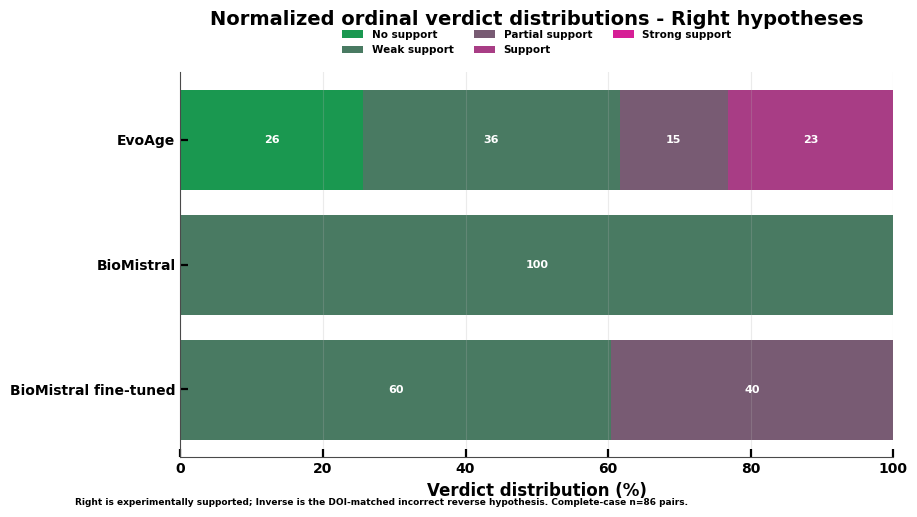

✅ Plot 8: Ordinal Distributions - Alternative Models (Right)


In [208]:
# ============================================================
# Plot 8: Ordinal distributions - Alternative Models (Right)
# ============================================================
models = ALT_MODELS
direction = 'Right'
matrix = ordinal_percent_matrix(models, direction, retained_dois)

fig, ax = plt.subplots(figsize=(9.2, 5.0))
y = np.arange(len(models))
left = np.zeros(len(models))
for j, (label, color) in enumerate(zip(VERDICT_LABELS, VERDICT_COLORS)):
    ax.barh(y, matrix[:, j], left=left, label=label, color=color)
    for i in range(len(models)):
        value = matrix[i, j]
        if value >= 4.0:
            ax.text(left[i] + value / 2, i, f'{value:.0f}', ha='center', va='center', fontsize=8, color='white')
    left += matrix[:, j]
ax.set_yticks(y, [DISPLAY[m] for m in models])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Verdict distribution (%)')
ax.set_title(f'Normalized ordinal verdict distributions - {direction} hypotheses', pad=34)
ax.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.02))
ax.grid(axis='x', alpha=0.25)
footer(fig, f'Right is experimentally supported; Inverse is the DOI-matched incorrect reverse hypothesis. Complete-case n={len(retained_dois)} pairs.')
plt.show()
print("✅ Plot 8: Ordinal Distributions - Alternative Models (Right)")

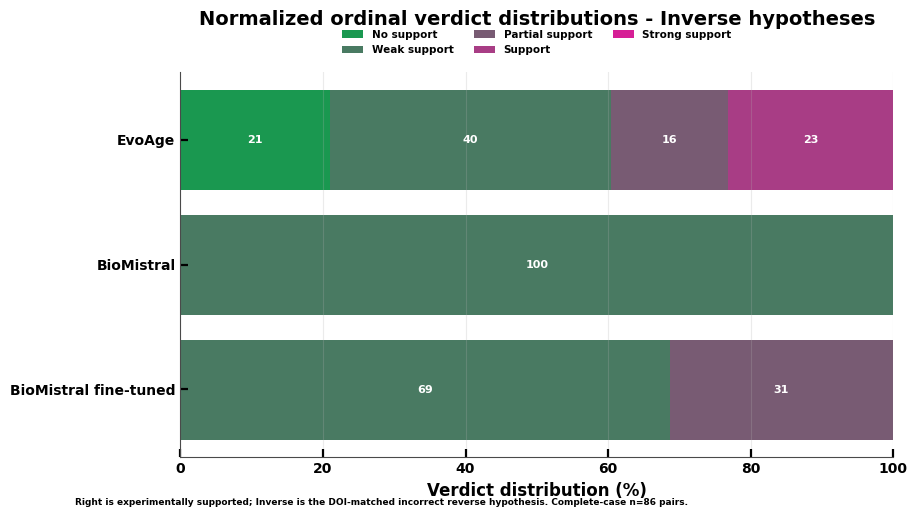

✅ Plot 9: Ordinal Distributions - Alternative Models (Inverse)


In [209]:
# ============================================================
# Plot 9: Ordinal distributions - Alternative Models (Inverse)
# ============================================================
models = ALT_MODELS
direction = 'Inverse'
matrix = ordinal_percent_matrix(models, direction, retained_dois)

fig, ax = plt.subplots(figsize=(9.2, 5.0))
y = np.arange(len(models))
left = np.zeros(len(models))
for j, (label, color) in enumerate(zip(VERDICT_LABELS, VERDICT_COLORS)):
    ax.barh(y, matrix[:, j], left=left, label=label, color=color)
    for i in range(len(models)):
        value = matrix[i, j]
        if value >= 4.0:
            ax.text(left[i] + value / 2, i, f'{value:.0f}', ha='center', va='center', fontsize=8, color='white')
    left += matrix[:, j]
ax.set_yticks(y, [DISPLAY[m] for m in models])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Verdict distribution (%)')
ax.set_title(f'Normalized ordinal verdict distributions - {direction} hypotheses', pad=34)
ax.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.02))
ax.grid(axis='x', alpha=0.25)
footer(fig, f'Right is experimentally supported; Inverse is the DOI-matched incorrect reverse hypothesis. Complete-case n={len(retained_dois)} pairs.')
plt.show()
print("✅ Plot 9: Ordinal Distributions - Alternative Models (Inverse)")

## 4i

BioChatter file: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/FIG_4/biochatter_hypothesis_results_medgemma.csv
Escargot file: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/FIG_4/escargot_hypothesis_results_medgemma.csv
EvoAge file: /storage/Arushi/090526_EvoAge/multiagent_hypo/evoage_100_right_inverse/Right_hypothesis_Extract_entities/hypothesis_pipeline_results_final_with_percentile_buckets_full.csv
joined 101 hypotheses on DOI
  EvoAge      any support: 73/101 (72%)
  Escargot    any support: 12/101 (12%)
  BioChatter  any support: 2/101 (2%)


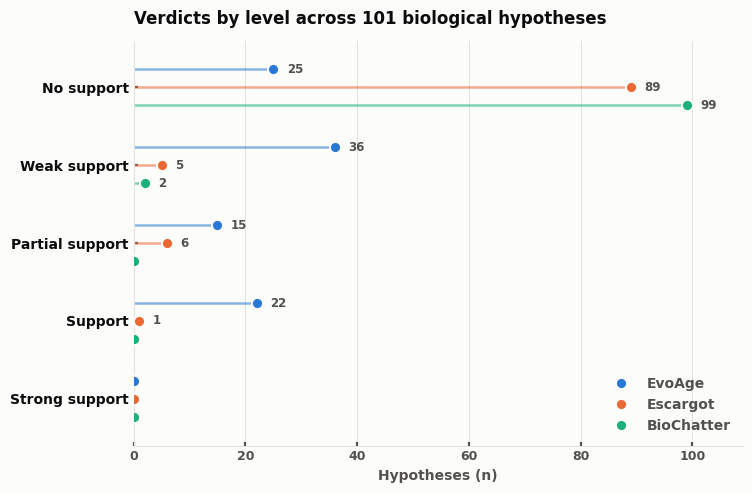


wrote /storage/Arushi/090526_EvoAge/kg_formation/all_figures/verdict_analysis/figure4_verdict_lollipop.svg
wrote /storage/Arushi/090526_EvoAge/kg_formation/all_figures/verdict_analysis/figure4_verdict_lollipop.png


In [120]:
"""
Single-plot version: verdicts by level, drawn as a lollipop (dot) plot.
"""
%matplotlib inline
import ast
import os

# Remove matplotlib.use("Agg") - let it use default backend
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Fix for __file__ not being defined in interactive environments
try:
    HERE = os.path.dirname(os.path.abspath(__file__))
except NameError:
    HERE = os.getcwd()

OUTDIR = os.path.join(HERE, "verdict_analysis")

# Updated paths for BioChatter and Escargot
BASE_PATH = "/storage/Arushi/090526_EvoAge/kg_formation/all_figures/FIG_4"

BIOCHATTER_CSV = os.path.join(BASE_PATH, "biochatter_hypothesis_results_medgemma.csv")
ESCARGOT_CSV = os.path.join(BASE_PATH, "escargot_hypothesis_results_medgemma.csv")
EVOAGE_CSV = ("/storage/Arushi/090526_EvoAge/multiagent_hypo/"
              "evoage_100_right_inverse/Right_hypothesis_Extract_entities/"
              "hypothesis_pipeline_results_final_with_percentile_buckets_full.csv")

LADDER = ["no_support", "weak_support", "partial_support", "support", "strong_support"]
LABEL = ["No\nsupport", "Weak\nsupport", "Partial\nsupport", "Support", "Strong\nsupport"]
RANK = {v: i for i, v in enumerate(LADDER)}
SYSTEMS = ["EvoAge", "Escargot", "BioChatter"]

COLOR = {"EvoAge": "#2a78d6", "Escargot": "#eb6834", "BioChatter": "#1baf7a"}
INK, INK_SOFT, GRID, SURFACE = "#0b0b0b", "#52514e", "#e3e2de", "#fcfcfb"


def parse_evoage_verdict(value):
    try:
        return (ast.literal_eval(value) or {}).get("verdict")
    except (ValueError, SyntaxError, TypeError):
        return None


def load() -> pd.DataFrame:
    def key(series):
        return series.astype(str).str.strip().str.lower().str.rstrip("/")

    def clean(series):
        cleaned = series.astype(str).str.strip().str.lower()
        return cleaned.where(cleaned.isin(LADDER))

    for csv_path in [EVOAGE_CSV, ESCARGOT_CSV, BIOCHATTER_CSV]:
        if not os.path.exists(csv_path):
            print(f"Warning: File not found: {csv_path}")
    
    evo = pd.read_csv(EVOAGE_CSV)
    esc = pd.read_csv(ESCARGOT_CSV)
    bio = pd.read_csv(BIOCHATTER_CSV)

    evo = evo.assign(EvoAge=evo["EvoAge_hypothesis_response"].apply(parse_evoage_verdict),
                     _key=key(evo["DOI"]))
    esc = esc.assign(Escargot=esc["Medgemma_verdict"], _key=key(esc["DOI"]))
    bio = bio.assign(BioChatter=bio["Medgemma_verdict"], _key=key(bio["DOI"]))

    merged = (evo[["_key", "Title", "DOI", "Right Hypothesis", "EvoAge"]]
              .merge(esc[["_key", "Escargot"]], on="_key", how="inner", validate="1:1")
              .merge(bio[["_key", "BioChatter"]], on="_key", how="inner", validate="1:1"))

    for system in SYSTEMS:
        merged[system] = clean(merged[system])
    return merged.drop(columns="_key")


def plot_lollipop(frame):
    fig, ax = plt.subplots(figsize=(7.6, 5.0), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)

    counts = {s: frame[s].value_counts().reindex(LADDER).fillna(0).astype(int)
              for s in SYSTEMS}
    y_base = np.arange(len(LADDER))[::-1]
    offsets = {"EvoAge": 0.23, "Escargot": 0.0, "BioChatter": -0.23}

    for system in SYSTEMS:
        y = y_base + offsets[system]
        values = counts[system].values
        ax.hlines(y, 0, values, color=COLOR[system], linewidth=1.8, alpha=0.55)
        ax.plot(values, y, "o", markersize=8, color=COLOR[system],
                markeredgecolor=SURFACE, markeredgewidth=1.4,
                label=system, linestyle="none", zorder=3)
        for yi, value in zip(y, values):
            if value > 0:
                ax.text(value + 2.4, yi, str(value), va="center",
                        fontsize=8.5, color=INK_SOFT)

    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_SOFT, labelsize=9, length=3)
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color=GRID, linewidth=0.7)

    ax.set_yticks(y_base)
    ax.set_yticklabels([l.replace("\n", " ") for l in LABEL], fontsize=10, color=INK)
    ax.set_ylim(-0.6, len(LADDER) - 0.4)
    ax.set_xlim(0, max(108, len(frame) * 1.08))
    ax.set_xlabel("Hypotheses (n)", fontsize=10, color=INK_SOFT)
    ax.set_title(f"Verdicts by level across {len(frame)} biological hypotheses",
                 loc="left", fontsize=12, color=INK, pad=12, fontweight="bold")
    ax.legend(frameon=False, fontsize=10, loc="lower right", labelcolor=INK_SOFT)

    fig.tight_layout()
    return fig


def main() -> None:
    os.makedirs(OUTDIR, exist_ok=True)
    
    print(f"BioChatter file: {BIOCHATTER_CSV}")
    print(f"Escargot file: {ESCARGOT_CSV}")
    print(f"EvoAge file: {EVOAGE_CSV}")
    
    frame = load()
    print(f"joined {len(frame)} hypotheses on DOI")
    for system in SYSTEMS:
        n = frame[system].isin(LADDER[1:]).sum()
        print(f"  {system:<11} any support: {n}/{len(frame)} ({100*n/len(frame):.0f}%)")

    fig = plot_lollipop(frame)
    svg = os.path.join(OUTDIR, "figure4_verdict_lollipop.svg")
    png = os.path.join(OUTDIR, "figure4_verdict_lollipop.png")
    fig.savefig(svg, format="svg", facecolor=SURFACE, bbox_inches="tight")
    fig.savefig(png, dpi=200, facecolor=SURFACE, bbox_inches="tight")
    
    plt.show()  # This will display the plot
    plt.close(fig)
    print(f"\nwrote {svg}\nwrote {png}")


if __name__ == "__main__":
    main()

## Main Figure 5

## 5b

Loading data from: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/03_log2fc_coherence/input_EvoAge_log2FC_merged_data.csv
Loaded 976 genes


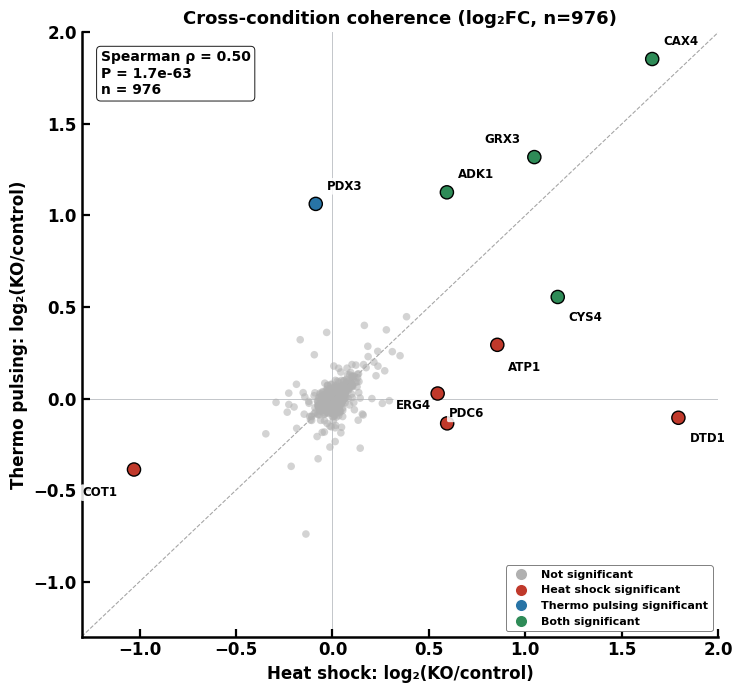

✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/03_log2fc_coherence/coherence_log2fc.png
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/03_log2fc_coherence/coherence_log2fc.svg

📊 Statistics:
Spearman ρ = 0.50221, P = 1.72e-63
Genes: n=976
  Not significant: 966
  Heat shock only: 5
  Thermo pulsing only: 1
  Both significant: 4

✅ All done! Plots saved in: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/03_log2fc_coherence


In [143]:
# This magic command makes plots appear in the notebook
%matplotlib inline

"""
log2fc_coherence_plot.py

Cross-condition coherence plot using log2 fold change (log2FC) instead of
difference scores.

For each gene:
    log2FC_c1 = log2(Mean_KO_ratio_c1 / Mean_Control_ratio_c1)   # Heat shock 37C vs 30C
    log2FC_c2 = log2(Mean_KO_ratio_c2 / Mean_Control_ratio_c2)   # Thermo pulsing vs 30C

Color = significance status (BH-FDR q <= 0.05), NOT EvoAge verdict:
    grey  = not significant
    red   = heat shock significant only
    blue  = thermo pulsing significant only
    green = significant in both conditions

Spearman rho computed across all 976 genes (no filtering).

INPUT : /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/03_log2fc_coherence/input_EvoAge_log2FC_merged_data.csv
OUTPUT: coherence_log2fc.png / .svg in the same directory
"""

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats
import os
from pathlib import Path

# ── Configuration ──────────────────────────────────────────────────────
# Input file path
INPUT_FILE = '/storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/03_log2fc_coherence/input_EvoAge_log2FC_merged_data.csv'

# Output directory (same as input file location)
OUTPUT_DIR = os.path.dirname(INPUT_FILE)
OUTPUT_BASE = 'coherence_log2fc'

# ── Gene name mapping (verified from EvoAge_complete_merged_data.csv) ──
GENE_NAMES = {
    "YGR036C": "CAX4", "YDL219W": "DTD1", "YDR098C": "GRX3", "YGR155W": "CYS4",
    "YDR226W": "ADK1", "YBR035C": "PDX3", "YBL099W": "ATP1", "YGL012W": "ERG4",
    "YGR087C": "PDC6", "YOR316C": "COT1",
}

# Label offsets to prevent text overlap
LABEL_OFFSETS = {
    "CAX4": (8, 8), "DTD1": (8, -10), "GRX3": (-10, 8), "CYS4": (8, -10), "ADK1": (8, 8),
    "PDX3": (8, 8), "ATP1": (8, -12), "ERG4": (-12, 8), "PDC6": (8, -10), "COT1": (-12, -12),
}

# Significance-based colors
COLORS = {
    "not_sig": "#B0B0B0",   # grey
    "heat_only": "#C0392B",  # red
    "pulse_only": "#2874A6", # blue
    "both": "#2E8B57",       # green
}

def load_and_compute(csv_path):
    """Load merged data and compute log2FC if not already present."""
    print(f"Loading data from: {csv_path}")
    df = pd.read_csv(csv_path)
    print(f"Loaded {len(df)} genes")

    # Compute log2FC if the columns don't already exist
    if "log2FC_c1" not in df.columns:
        df["log2FC_c1"] = np.log2(df["Mean_KO_ratio_c1"] / df["Mean_Control_ratio_c1"])
    if "log2FC_c2" not in df.columns:
        df["log2FC_c2"] = np.log2(df["Mean_KO_ratio_c2"] / df["Mean_Control_ratio_c2"])

    # Significance from BH-FDR q-values (these are NOT changed by log2FC)
    df["sig37"] = df["q_value_c1"] <= 0.05
    df["sigPul"] = df["q_value_c2"] <= 0.05
    df["sig_any"] = df["sig37"] | df["sigPul"]

    # Significance category for coloring
    df["color"] = COLORS["not_sig"]
    df.loc[df["sig37"] & ~df["sigPul"], "color"] = COLORS["heat_only"]
    df.loc[df["sigPul"] & ~df["sig37"], "color"] = COLORS["pulse_only"]
    df.loc[df["sig37"] & df["sigPul"], "color"] = COLORS["both"]

    return df.dropna(subset=["log2FC_c1", "log2FC_c2"])

def make_plot(df, output_dir, output_base, show_plot=True):
    """Create the log2FC cross-condition coherence plot."""
    x = df["log2FC_c1"]
    y = df["log2FC_c2"]
    sig_any = df["sig_any"]

    fig, ax = plt.subplots(figsize=(7.5, 7))

    # All genes (grey majority, colored minority)
    ax.scatter(x, y, c=df["color"], s=30, alpha=0.55,
               edgecolors="none", rasterized=True, zorder=2)

    # Significant genes on top with black outline
    ax.scatter(x[sig_any], y[sig_any], s=90,
               facecolors=df.loc[sig_any, "color"],
               edgecolors="black", linewidths=1.0, zorder=5)

    # Label the 10 significant genes
    for gid, name in GENE_NAMES.items():
        row = df[df["Gene"] == gid]
        if len(row):
            r = row.iloc[0]
            dx, dy = LABEL_OFFSETS.get(name, (8, 8))
            ax.annotate(
                name, (r["log2FC_c1"], r["log2FC_c2"]),
                fontsize=8.5, fontweight="bold",
                ha="left" if dx >= 0 else "right",
                va="bottom" if dy >= 0 else "top",
                xytext=(dx, dy), textcoords="offset points",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white",
                          edgecolor="none", alpha=0.85),
                zorder=6,
            )

    # y=x diagonal + zero lines
    lo, hi = -1.3, 2.0
    ax.plot([lo, hi], [lo, hi], "k--", alpha=0.35, lw=0.8, zorder=1)
    ax.axhline(0, color="#C3C6CA", lw=0.7, zorder=1)
    ax.axvline(0, color="#C3C6CA", lw=0.7, zorder=1)

    # Spearman (all genes, no filtering)
    rho, p = stats.spearmanr(x, y)
    ax.text(
        0.03, 0.97,
        f"Spearman ρ = {rho:.2f}\nP = {p:.1e}\nn = {len(df)}",
        transform=ax.transAxes, va="top", ha="left", fontsize=10,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9), zorder=7,
    )

    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xlabel("Heat shock: log₂(KO/control)", fontsize=12)
    ax.set_ylabel("Thermo pulsing: log₂(KO/control)", fontsize=12)
    ax.set_title("Cross-condition coherence (log₂FC, n=976)", fontsize=13, fontweight="bold")

    # Legend
    legend_elems = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor=COLORS["not_sig"], markersize=9, label="Not significant"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor=COLORS["heat_only"], markersize=9, label="Heat shock significant"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor=COLORS["pulse_only"], markersize=9, label="Thermo pulsing significant"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor=COLORS["both"], markersize=9, label="Both significant"),
    ]
    ax.legend(handles=legend_elems, loc="lower right", fontsize=8,
              frameon=True, edgecolor="grey")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()

    # Show plot in notebook
    if show_plot:
        plt.show()
    
    # Save figures
    for ext in ['png', 'svg']:
        output_path = os.path.join(output_dir, f"{output_base}.{ext}")
        plt.savefig(output_path, dpi=200, bbox_inches="tight")
        print(f"✅ Saved: {output_path}")

    plt.close()

    print(f"\n📊 Statistics:")
    print(f"Spearman ρ = {rho:.5f}, P = {p:.2e}")
    print(f"Genes: n={len(df)}")
    print(f"  Not significant: {(~sig_any).sum()}")
    print(f"  Heat shock only: {(df['sig37'] & ~df['sigPul']).sum()}")
    print(f"  Thermo pulsing only: {(df['sigPul'] & ~df['sig37']).sum()}")
    print(f"  Both significant: {(df['sig37'] & df['sigPul']).sum()}")

# ── Main execution ──────────────────────────────────────────────────────
# Load data
df = load_and_compute(INPUT_FILE)

# Generate plot (will show in notebook and save to files)
make_plot(df, OUTPUT_DIR, OUTPUT_BASE, show_plot=True)

print(f"\n✅ All done! Plots saved in: {OUTPUT_DIR}")

## 5c

✅ Loading data from: EvoAge_effect_FDR_input.csv
✅ Data loaded. Shape: (976, 12)
✅ Significant genes at 37°C: 9


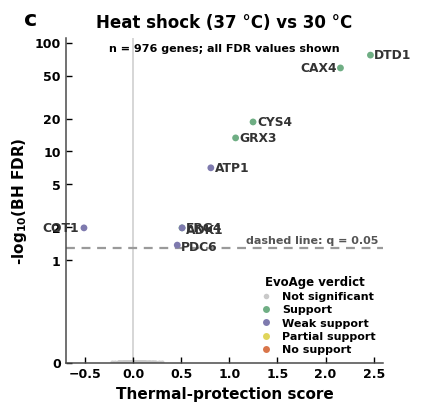

In [217]:
# ============================================
# PLOT 1: Heat Shock (37 °C) vs 30 °C
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.ticker as ticker
import os
import warnings

# Suppress font warnings
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')

# Set font to a standard one that exists in most systems
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Helvetica', 'sans-serif']

# Enable inline plotting in Jupyter
%matplotlib inline

# Define colors and labels
VERDICT_COLORS = {
    'support': '#6FAE84',
    'weak_support': '#7E7AAE',
    'partial_support': '#E0D55A',
    'no_support': '#D9754A',
}
VERDICT_LABELS = {
    'support': 'Support',
    'weak_support': 'Weak support',
    'partial_support': 'Partial support',
    'no_support': 'No support',
}

def to_bool(s):
    return str(s).strip().lower() in {'true','1','yes'}

def prep(df):
    out = df.copy()
    out['Sig_37C'] = out['Sig_37C'].map(to_bool)
    out['Sig_Pulser'] = out['Sig_Pulser'].map(to_bool)
    out['neglog10_q_37C'] = -np.log10(pd.to_numeric(out['q_value_c1'], errors='coerce').clip(lower=1e-300))
    out['neglog10_q_Pulser'] = -np.log10(pd.to_numeric(out['q_value_c2'], errors='coerce').clip(lower=1e-300))
    out['Score_c1'] = pd.to_numeric(out['Score_c1'], errors='coerce')
    out['Score_c2'] = pd.to_numeric(out['Score_c2'], errors='coerce')
    # Use standard names like ERG4, ATP1; fall back to systematic names if needed
    out['label_name'] = out['Standard_Name'].fillna('').astype(str)
    out.loc[out['label_name'].str.strip()=='', 'label_name'] = out.loc[out['label_name'].str.strip()=='', 'Gene']
    return out

def style_axis_heatshock(ax):
    """Style the axis for heat shock plot"""
    ax.set_title('Heat shock (37 °C) vs 30 °C', fontsize=12, pad=8)
    ax.text(0.5, 0.985, 'n = 976 genes; all FDR values shown', transform=ax.transAxes,
            ha='center', va='top', fontsize=8)
    ax.set_xlabel('Thermal-protection score', fontsize=11)
    ax.set_ylabel(r'-log$_{10}$(BH FDR)', fontsize=11)
    ax.axvline(0, color='#D0D0D0', lw=1.2, zorder=0)
    qline = -np.log10(0.05)
    ax.axhline(qline, color='#9A9A9A', lw=1.6, ls=(0,(4,3)), zorder=0)
    ax.text(0.985, qline+0.05, 'dashed line: q = 0.05', transform=ax.get_yaxis_transform(),
            ha='right', va='bottom', fontsize=8, color='#555555')
    ax.set_xlim(-0.7, 2.6)
    ax.set_xticks([-0.5, 0, 0.5, 1, 1.5, 2, 2.5])
    ax.set_ylim(0, 110)
    ax.set_yscale('symlog', linthresh=1.0, linscale=0.85, base=10)
    ax.set_yticks([0, 1, 2, 5, 10, 20, 50, 100])
    ax.get_yaxis().set_major_formatter(ticker.ScalarFormatter())
    ax.tick_params(width=1.0, length=4, labelsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for s in ['left','bottom']:
        ax.spines[s].set_linewidth(1.1)

def make_handles():
    handles = [Line2D([0],[0], marker='o', linestyle='None', markersize=4,
                      markerfacecolor='#C9C9C9', markeredgecolor='none', label='Not significant')]
    for key in ['support','weak_support','partial_support','no_support']:
        handles.append(Line2D([0],[0], marker='o', linestyle='None', markersize=5,
                              markerfacecolor=VERDICT_COLORS[key], markeredgecolor='none',
                              label=VERDICT_LABELS[key]))
    return handles

def label_points_heatshock(ax, subdf):
    """Label points for heat shock plot"""
    offsets = {
        'YGR036C': (-0.04, 0.0, 'right'),   # CAX4
        'YDL219W': (0.04, 0.0, 'left'),     # DTD1
        'YDR098C': (0.04, 0.0, 'left'),     # GRX3
        'YGR155W': (0.04, 0.0, 'left'),     # CYS4
        'YDR226W': (0.04, -0.08, 'left'),   # ADK1
        'YBR035C': (0.04, -0.06, 'left'),   # PDX3
        'YBL099W': (0.04, 0.0, 'left'),     # ATP1
        'YGL012W': (0.04, 0.02, 'left'),    # ERG4
        'YGR087C': (0.04, -0.06, 'left'),   # PDC6
        'YOR316C': (-0.05, 0.02, 'right'),  # COT1
    }
    for _, r in subdf.iterrows():
        dx, dy, ha = offsets.get(r['Gene'], (0.04, 0.0, 'left'))
        ax.text(r['Score_c1']+dx, r['neglog10_q_37C']+dy, r['label_name'], 
                fontsize=8.8, ha=ha, va='center', color='#333333')

# ============================================
# LOAD DATA AND CREATE HEAT SHOCK PLOT
# ============================================

# Update this path to your CSV file
input_file = 'EvoAge_effect_FDR_input.csv'

if not os.path.exists(input_file):
    print(f"⚠️ Error: File '{input_file}' not found!")
    print(f"Current directory: {os.getcwd()}")
else:
    # Load and prepare data
    print(f"✅ Loading data from: {input_file}")
    df = prep(pd.read_csv(input_file))
    print(f"✅ Data loaded. Shape: {df.shape}")
    print(f"✅ Significant genes at 37°C: {df['Sig_37C'].sum()}")
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(4.1,4.0), constrained_layout=True)
    
    # Style the axis
    style_axis_heatshock(ax)
    
    # Plot all points in grey
    ax.scatter(df['Score_c1'], df['neglog10_q_37C'], s=10, color='#C9C9C9', 
               alpha=0.85, edgecolors='none', zorder=1)
    
    # Plot significant points with colors based on verdict
    sig = df[df['Sig_37C']].copy()
    for key in ['support','weak_support','partial_support','no_support']:
        ss = sig[sig['verdict'] == key]
        if len(ss):
            ax.scatter(ss['Score_c1'], ss['neglog10_q_37C'], s=24, 
                      color=VERDICT_COLORS[key], edgecolors='none', zorder=3)
    
    # Add labels
    label_points_heatshock(ax, sig)
    
    # Add legend
    ax.legend(handles=make_handles(), title='EvoAge verdict', loc='lower right', 
              frameon=False, fontsize=8, title_fontsize=8.5, 
              handletextpad=0.4, borderpad=0.2, labelspacing=0.3)
    
    # Add panel label
    ax.text(-0.13, 1.04, 'c', transform=ax.transAxes, fontsize=16, fontweight='bold')
    
    # Display the plot
    plt.show()
    
    # Optional: Save the figure (uncomment to use)
    # fig.savefig('heatshock_panel.png', bbox_inches='tight', dpi=300)
    # fig.savefig('heatshock_panel.pdf', bbox_inches='tight')
    # print("✅ Figure saved!")
    
    plt.close(fig)

## 5d

✅ Loading data from: EvoAge_effect_FDR_input.csv
✅ Data loaded. Shape: (976, 12)
✅ Significant genes in pulser: 5


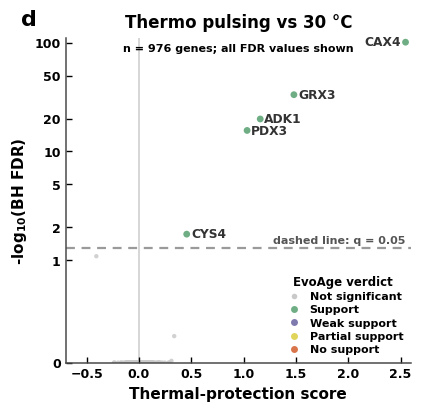

In [218]:
# ============================================
# PLOT 2: Thermo Pulsing vs 30 °C
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.ticker as ticker
import os
import warnings

# Suppress font warnings
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')

# Set font to a standard one that exists in most systems
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Helvetica', 'sans-serif']

# Enable inline plotting in Jupyter
%matplotlib inline

# Define colors and labels
VERDICT_COLORS = {
    'support': '#6FAE84',
    'weak_support': '#7E7AAE',
    'partial_support': '#E0D55A',
    'no_support': '#D9754A',
}
VERDICT_LABELS = {
    'support': 'Support',
    'weak_support': 'Weak support',
    'partial_support': 'Partial support',
    'no_support': 'No support',
}

def to_bool(s):
    return str(s).strip().lower() in {'true','1','yes'}

def prep(df):
    out = df.copy()
    out['Sig_37C'] = out['Sig_37C'].map(to_bool)
    out['Sig_Pulser'] = out['Sig_Pulser'].map(to_bool)
    out['neglog10_q_37C'] = -np.log10(pd.to_numeric(out['q_value_c1'], errors='coerce').clip(lower=1e-300))
    out['neglog10_q_Pulser'] = -np.log10(pd.to_numeric(out['q_value_c2'], errors='coerce').clip(lower=1e-300))
    out['Score_c1'] = pd.to_numeric(out['Score_c1'], errors='coerce')
    out['Score_c2'] = pd.to_numeric(out['Score_c2'], errors='coerce')
    # Use standard names like ERG4, ATP1; fall back to systematic names if needed
    out['label_name'] = out['Standard_Name'].fillna('').astype(str)
    out.loc[out['label_name'].str.strip()=='', 'label_name'] = out.loc[out['label_name'].str.strip()=='', 'Gene']
    return out

def style_axis_thermopulsing(ax):
    """Style the axis for thermo pulsing plot"""
    ax.set_title('Thermo pulsing vs 30 °C', fontsize=12, pad=8)
    ax.text(0.5, 0.985, 'n = 976 genes; all FDR values shown', transform=ax.transAxes,
            ha='center', va='top', fontsize=8)
    ax.set_xlabel('Thermal-protection score', fontsize=11)
    ax.set_ylabel(r'-log$_{10}$(BH FDR)', fontsize=11)
    ax.axvline(0, color='#D0D0D0', lw=1.2, zorder=0)
    qline = -np.log10(0.05)
    ax.axhline(qline, color='#9A9A9A', lw=1.6, ls=(0,(4,3)), zorder=0)
    ax.text(0.985, qline+0.05, 'dashed line: q = 0.05', transform=ax.get_yaxis_transform(),
            ha='right', va='bottom', fontsize=8, color='#555555')
    ax.set_xlim(-0.7, 2.6)
    ax.set_xticks([-0.5, 0, 0.5, 1, 1.5, 2, 2.5])
    ax.set_ylim(0, 110)
    ax.set_yscale('symlog', linthresh=1.0, linscale=0.85, base=10)
    ax.set_yticks([0, 1, 2, 5, 10, 20, 50, 100])
    ax.get_yaxis().set_major_formatter(ticker.ScalarFormatter())
    ax.tick_params(width=1.0, length=4, labelsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for s in ['left','bottom']:
        ax.spines[s].set_linewidth(1.1)

def make_handles():
    handles = [Line2D([0],[0], marker='o', linestyle='None', markersize=4,
                      markerfacecolor='#C9C9C9', markeredgecolor='none', label='Not significant')]
    for key in ['support','weak_support','partial_support','no_support']:
        handles.append(Line2D([0],[0], marker='o', linestyle='None', markersize=5,
                              markerfacecolor=VERDICT_COLORS[key], markeredgecolor='none',
                              label=VERDICT_LABELS[key]))
    return handles

def label_points_thermopulsing(ax, subdf):
    """Label points for thermo pulsing plot"""
    offsets = {
        'YGR036C': (-0.04, 0.0, 'right'),   # CAX4
        'YDL219W': (0.04, 0.0, 'left'),     # DTD1
        'YDR098C': (0.04, 0.0, 'left'),     # GRX3
        'YGR155W': (0.04, 0.0, 'left'),     # CYS4
        'YDR226W': (0.04, -0.08, 'left'),   # ADK1
        'YBR035C': (0.04, -0.06, 'left'),   # PDX3
        'YBL099W': (0.04, 0.0, 'left'),     # ATP1
        'YGL012W': (0.04, 0.02, 'left'),    # ERG4
        'YGR087C': (0.04, -0.06, 'left'),   # PDC6
        'YOR316C': (-0.05, 0.02, 'right'),  # COT1
    }
    for _, r in subdf.iterrows():
        dx, dy, ha = offsets.get(r['Gene'], (0.04, 0.0, 'left'))
        ax.text(r['Score_c2']+dx, r['neglog10_q_Pulser']+dy, r['label_name'], 
                fontsize=8.8, ha=ha, va='center', color='#333333')

# ============================================
# LOAD DATA AND CREATE THERMO PULSING PLOT
# ============================================

# Update this path to your CSV file
input_file = 'EvoAge_effect_FDR_input.csv'

if not os.path.exists(input_file):
    print(f"⚠️ Error: File '{input_file}' not found!")
    print(f"Current directory: {os.getcwd()}")
else:
    # Load and prepare data
    print(f"✅ Loading data from: {input_file}")
    df = prep(pd.read_csv(input_file))
    print(f"✅ Data loaded. Shape: {df.shape}")
    print(f"✅ Significant genes in pulser: {df['Sig_Pulser'].sum()}")
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(4.1,4.0), constrained_layout=True)
    
    # Style the axis
    style_axis_thermopulsing(ax)
    
    # Plot all points in grey
    ax.scatter(df['Score_c2'], df['neglog10_q_Pulser'], s=10, color='#C9C9C9', 
               alpha=0.85, edgecolors='none', zorder=1)
    
    # Plot significant points with colors based on verdict
    sig = df[df['Sig_Pulser']].copy()
    for key in ['support','weak_support','partial_support','no_support']:
        ss = sig[sig['verdict'] == key]
        if len(ss):
            ax.scatter(ss['Score_c2'], ss['neglog10_q_Pulser'], s=24, 
                      color=VERDICT_COLORS[key], edgecolors='none', zorder=3)
    
    # Add labels
    label_points_thermopulsing(ax, sig)
    
    # Add legend
    ax.legend(handles=make_handles(), title='EvoAge verdict', loc='lower right', 
              frameon=False, fontsize=8, title_fontsize=8.5, 
              handletextpad=0.4, borderpad=0.2, labelspacing=0.3)
    
    # Add panel label
    ax.text(-0.13, 1.04, 'd', transform=ax.transAxes, fontsize=16, fontweight='bold')
    
    # Display the plot
    plt.show()
    
    # Optional: Save the figure (uncomment to use)
    # fig.savefig('thermopulsing_panel.png', bbox_inches='tight', dpi=300)
    # fig.savefig('thermopulsing_panel.pdf', bbox_inches='tight')
    # print("✅ Figure saved!")
    
    plt.close(fig)

## 5e

Loading data from: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/overlap/EvoAge_complete_merged_data.csv
Loaded 976 genes

Significant genes:
  37°C Heat shock only: 5 genes
  Thermo pulsing only: 1 genes
  Both conditions: 4 genes
  Total unique significant genes: 10


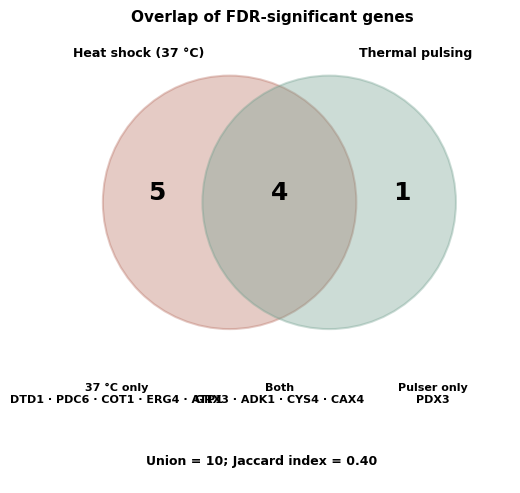

✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/overlap/03_overlap_venn.svg
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/overlap/03_overlap_venn.png

✅ All done! Venn diagram saved in: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/overlap


In [145]:
# This magic command makes plots appear in the notebook
%matplotlib inline

"""
EvoAge Overlap Venn Diagram
---------------------------
Creates a Venn diagram showing overlap of significant genes between conditions.

INPUT : /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/overlap/EvoAge_complete_merged_data.csv
OUTPUT: 03_overlap_venn.svg / .png in the same directory
"""

import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# ── Configuration ──────────────────────────────────────────────────────
# Input directory and file
INPUT_DIR = '/storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/overlap'
INPUT_FILE = Path(INPUT_DIR) / 'EvoAge_complete_merged_data.csv'
OUTPUT_DIR = INPUT_DIR

# ── Constants (from common.py) ──────────────────────────────────────
VERDICT_MAP = {
    'support': 'Support',
    'weak_support': 'Weak support',
    'partial_support': 'Partial support',
    'no_support': 'No support',
}
VERDICT_ORDER = ['Support', 'Weak support', 'Partial support', 'No support', 'Unresolved']
COLORS = {
    'Support': '#5B4B8A',
    'Weak support': '#6FAE9B',
    'Partial support': '#D8B65C',
    'No support': '#C97B63',
    'Unresolved': '#CFCFD4',
    '37C': '#B66A5B',
    'Pulser': '#6E9D8C',
    'neutral': '#C9CDD2',
}

def configure():
    plt.rcParams.update({
        'font.family': 'DejaVu Sans', 
        'font.size': 9,
        'axes.titlesize': 11, 
        'axes.labelsize': 10,
        'xtick.labelsize': 8.5, 
        'ytick.labelsize': 8.5,
        'legend.fontsize': 8, 
        'axes.linewidth': 0.8,
        'svg.fonttype': 'none', 
        'pdf.fonttype': 42, 
        'ps.fonttype': 42,
    })

def to_bool(x):
    return str(x).strip().lower() in {'true', '1', 'yes'}

def load_data(path):
    """Load and prepare data for Venn diagram."""
    print(f"Loading data from: {path}")
    df = pd.read_csv(path)
    print(f"Loaded {len(df)} genes")
    
    # Create boolean columns for significance
    df['sig_37C'] = df['Sig_37C'].apply(to_bool)
    df['sig_Pulser'] = df['Sig_Pulser'].apply(to_bool)
    df['sig_both'] = df['sig_37C'] & df['sig_Pulser']
    
    # Get display names
    df['display_name'] = df['Standard_Name'].fillna(df['Gene'])
    
    return df

def create_venn(df, output_dir, show_plot=True):
    """Create Venn diagram showing overlap of significant genes."""
    
    # Get gene lists for each category
    only37 = df[df['sig_37C'] & ~df['sig_Pulser']]['display_name'].tolist()
    both = df[df['sig_both']]['display_name'].tolist()
    onlyp = df[df['sig_Pulser'] & ~df['sig_37C']]['display_name'].tolist()
    
    # Print statistics
    print(f"\nSignificant genes:")
    print(f"  37°C Heat shock only: {len(only37)} genes")
    print(f"  Thermo pulsing only: {len(onlyp)} genes")
    print(f"  Both conditions: {len(both)} genes")
    print(f"  Total unique significant genes: {len(only37) + len(both) + len(onlyp)}")
    
    # Create figure
    fig, ax = plt.subplots(figsize=(6.2, 5))
    ax.set_aspect('equal')
    ax.axis('off')
    
    # Draw circles
    ax.add_patch(Circle((.43, .62), .28, 
                        facecolor=COLORS['37C'], 
                        edgecolor=COLORS['37C'], 
                        alpha=.35, lw=1.5))
    ax.add_patch(Circle((.65, .62), .28, 
                        facecolor=COLORS['Pulser'], 
                        edgecolor=COLORS['Pulser'], 
                        alpha=.35, lw=1.5))
    
    # Add numbers
    ax.text(.27, .64, len(only37), ha='center', va='center', 
            fontsize=18, fontweight='bold')
    ax.text(.54, .64, len(both), ha='center', va='center', 
            fontsize=18, fontweight='bold')
    ax.text(.81, .64, len(onlyp), ha='center', va='center', 
            fontsize=18, fontweight='bold')
    
    # Add labels
    ax.text(.23, .94, 'Heat shock (37 °C)', ha='center', fontweight='bold')
    ax.text(.84, .94, 'Thermal pulsing', ha='center', fontweight='bold')
    
    # Add gene lists (truncated if too long)
    max_genes_display = 10
    gene_lists = []
    for gene_list in [only37, both, onlyp]:
        if len(gene_list) > max_genes_display:
            gene_lists.append(' · '.join(gene_list[:max_genes_display]) + f'\n... and {len(gene_list) - max_genes_display} more')
        elif len(gene_list) > 0:
            gene_lists.append(' · '.join(gene_list))
        else:
            gene_lists.append('(none)')
    
    ax.text(.18, .22, '37 °C only\n' + gene_lists[0], 
            ha='center', va='top', fontsize=8)
    ax.text(.54, .22, 'Both\n' + gene_lists[1], 
            ha='center', va='top', fontsize=8)
    ax.text(.88, .22, 'Pulser only\n' + gene_lists[2], 
            ha='center', va='top', fontsize=8)
    
    # Add statistics
    union = len(only37) + len(both) + len(onlyp)
    jaccard = len(both) / union if union > 0 else 0
    ax.text(.5, .04, f'Union = {union}; Jaccard index = {jaccard:.2f}', 
            ha='center', fontsize=9)
    
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, 1)
    ax.set_title('Overlap of FDR-significant genes', fontweight='bold')
    
    plt.tight_layout()
    
    # Show in notebook
    if show_plot:
        plt.show()
    
    # Save figures
    output_stem = Path(output_dir) / '03_overlap_venn'
    for ext in ['svg', 'png']:
        output_path = output_stem.with_suffix(f'.{ext}')
        plt.savefig(output_path, dpi=300, bbox_inches='tight')
        print(f"✅ Saved: {output_path}")
    
    plt.close()
    return fig

# ── Main execution ──────────────────────────────────────────────────────
# Setup
configure()

# Load data
df = load_data(INPUT_FILE)

# Create Venn diagram
fig = create_venn(df, OUTPUT_DIR, show_plot=True)

print(f"\n✅ All done! Venn diagram saved in: {OUTPUT_DIR}")

## 5f

Loading data from: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/01_boxplot_verdict_vs_effectsize/input_boxplot_verdict_data.csv
Loaded 878 genes


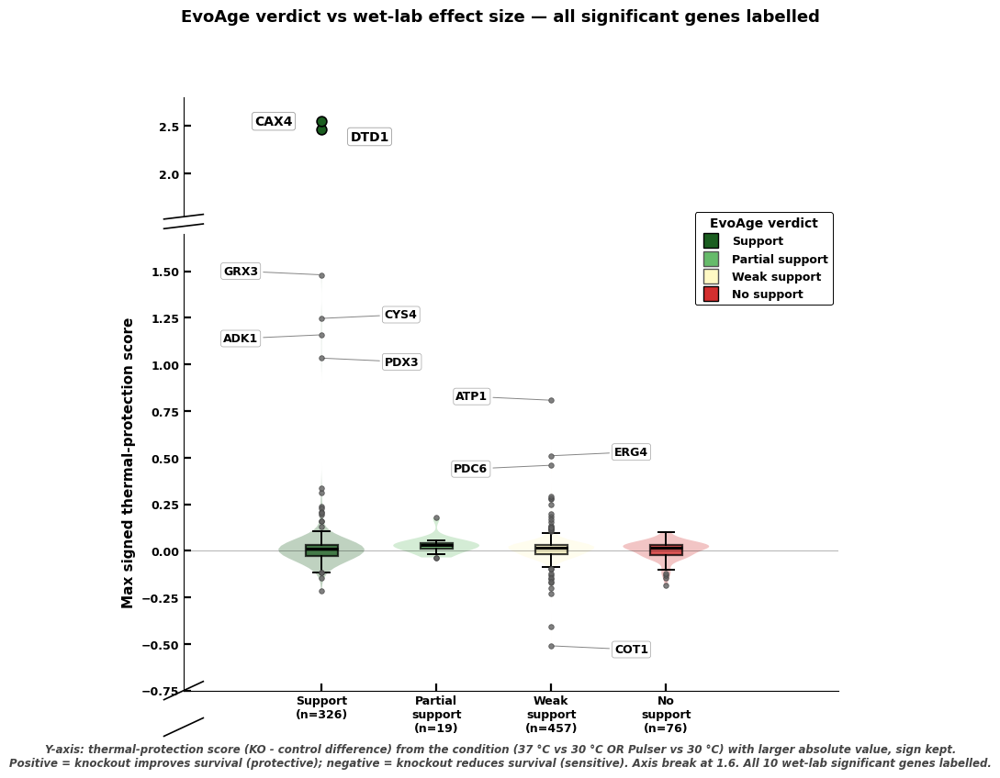

✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/01_boxplot_verdict_vs_effectsize/boxplot_verdict_vs_effectsize_brokenaxis.svg
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/01_boxplot_verdict_vs_effectsize/boxplot_verdict_vs_effectsize_brokenaxis.png
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/01_boxplot_verdict_vs_effectsize/boxplot_verdict_vs_effectsize_brokenaxis.pdf

📊 Summary statistics:

Support:
  Total: 326 genes
  Below break (≤1.6): 324 genes
  Above break (>1.6): 2 genes
  Median: 0.012
  Mean: 0.037

Partial
support:
  Total: 19 genes
  Below break (≤1.6): 19 genes
  Above break (>1.6): 0 genes
  Median: 0.030
  Mean: 0.028

Weak
support:
  Total: 457 genes
  Below break (≤1.6): 457 genes
  Above break (>1.6): 0 genes
  Median: 0.016
  Mean: 0.012

No
support:
  Total: 76 genes
  Below break (≤1.6): 76 genes
  Above break (>1.6): 0 genes
  Median: 0.014


In [146]:
# This magic command makes plots appear in the notebook
%matplotlib inline

"""
01_boxplot_verdict_vs_effectsize
--------------------------------
Broken-axis violin + box plot: EvoAge verdict vs max signed thermal-protection score.

INPUT : /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/01_boxplot_verdict_vs_effectsize/input_boxplot_verdict_data.csv
OUTPUT: boxplot_verdict_vs_effectsize_brokenaxis.svg / .png / .pdf

Y-axis: ms = score from the condition (37C or Pulser vs 30C) with larger |value|,
        sign kept. Positive = protective; negative = sensitising.
Axis break at 1.6 isolates CAX4 (+2.55) and DTD1 (+2.47) from the main distribution.
"""

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── Configuration ──────────────────────────────────────────────────────
# Input file path
INPUT_FILE = '/storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/01_boxplot_verdict_vs_effectsize/input_boxplot_verdict_data.csv'

# Output directory (same as input file location)
OUTPUT_DIR = os.path.dirname(INPUT_FILE)
DPI = 600

# ── Load data ──────────────────────────────────────────────────────────
print(f"Loading data from: {INPUT_FILE}")
df = pd.read_csv(INPUT_FILE)
print(f"Loaded {len(df)} genes")

# ── Prepare data ──────────────────────────────────────────────────────
groups = ['support', 'partial_support', 'weak_support', 'no_support']
data = [df[df['vg'] == g]['ms'].dropna().values for g in groups]
n = [len(d) for d in data]
labels = ['Support', 'Partial\nsupport', 'Weak\nsupport', 'No\nsupport']
colors = ['#1b5e20', '#66bb6a', '#fff9c4', '#d32f2f']

# Significant genes mapping
sig_genes = {'YGR036C': 'CAX4', 'YDL219W': 'DTD1', 'YDR098C': 'GRX3',
             'YGR155W': 'CYS4', 'YDR226W': 'ADK1', 'YBR035C': 'PDX3',
             'YBL099W': 'ATP1', 'YGL012W': 'ERG4', 'YOR316C': 'COT1',
             'YGR087C': 'PDC6'}

# Get positions for significant genes
key_pos = {}
for gene, nm in sig_genes.items():
    r = df[df['Gene'] == gene]
    if len(r) > 0:
        r = r.iloc[0]
        key_pos[nm] = (groups.index(r['vg']) if r['vg'] in groups else 0, r['ms'])

BREAK = 1.6

# ── Create figure ──────────────────────────────────────────────────────
fig = plt.figure(figsize=(9.2, 8.4))
gs = fig.add_gridspec(2, 1, height_ratios=[1.1, 4.2], hspace=0.06)

# ── TOP PANEL: extreme outliers (> BREAK) ────────────────────────────────
ax_top = fig.add_subplot(gs[0])
for i, (d, color) in enumerate(zip(data, colors)):
    hi = d[d > BREAK]
    if len(hi):
        ax_top.scatter([i] * len(hi), hi, s=60, c=color, edgecolors='black',
                       linewidth=1.2, zorder=5)

# Label CAX4 and DTD1 in top panel
ax_top.annotate('CAX4', key_pos['CAX4'],
                xytext=(key_pos['CAX4'][0] - 0.25, key_pos['CAX4'][1]),
                fontsize=10, fontweight='bold', ha='right', va='center',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          edgecolor='#999', linewidth=0.6, alpha=0.95), zorder=10)
ax_top.annotate('DTD1', key_pos['DTD1'],
                xytext=(key_pos['DTD1'][0] + 0.25, key_pos['DTD1'][1] - 0.08),
                fontsize=10, fontweight='bold', ha='left', va='center',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          edgecolor='#999', linewidth=0.6, alpha=0.95), zorder=10)

ax_top.set_ylim(BREAK - 0.05, 2.8)
ax_top.set_xlim(-1.2, 4.5)
ax_top.set_xticks([])
ax_top.spines['top'].set_visible(False)
ax_top.spines['right'].set_visible(False)
ax_top.spines['bottom'].set_visible(False)
ax_top.tick_params(labelsize=9)
ax_top.yaxis.set_major_locator(plt.MultipleLocator(0.5))

# ── BOTTOM PANEL: main distribution (<= BREAK) ───────────────────────────
ax = fig.add_subplot(gs[1])

# Violin plots
for i, (d, color) in enumerate(zip(data, colors)):
    d_below = d[d <= BREAK]
    if len(d_below) > 0:
        vp = ax.violinplot(d_below, positions=[i], showextrema=False, widths=0.75)
        for body in vp['bodies']:
            body.set_facecolor(color)
            body.set_alpha(0.28)
            body.set_edgecolor('none')

# Box plots
bp = ax.boxplot([d[d <= BREAK] for d in data], positions=[0, 1, 2, 3], widths=0.28,
                patch_artist=True, medianprops=dict(color='black', linewidth=2.2),
                flierprops=dict(marker='o', markerfacecolor='#616161', markersize=4,
                                markeredgecolor='#424242', markeredgewidth=0.6, alpha=0.8),
                whiskerprops=dict(linewidth=1.4), capprops=dict(linewidth=1.4))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.6)

ax.axhline(0, color='black', linewidth=0.6, linestyle='-', alpha=0.35)

# Staggered labels for all 8 bottom-panel significant genes
bottom_labels = [
    ('GRX3', 0, 1.481, -0.55, 0.02), ('CYS4', 0, 1.247, 0.55, 0.02),
    ('ADK1', 0, 1.159, -0.55, -0.02), ('PDX3', 0, 1.034, 0.55, -0.02),
    ('ATP1', 2, 0.808, -0.55, 0.02), ('ERG4', 2, 0.510, 0.55, 0.02),
    ('PDC6', 2, 0.459, -0.55, -0.02), ('COT1', 2, -0.510, 0.55, -0.02),
]
for nm, gi, val, dx, dy in bottom_labels:
    ax.annotate(nm, xy=(gi, val), xytext=(gi + dx, val + dy),
                fontsize=9, fontweight='bold',
                ha='right' if dx < 0 else 'left', va='center',
                arrowprops=dict(arrowstyle='-', color='#333', lw=0.7,
                                shrinkA=2, shrinkB=2, alpha=0.6),
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          edgecolor='#999', linewidth=0.5, alpha=0.9), zorder=10)

ax.set_ylim(-0.75, BREAK + 0.1)
ax.set_xlim(-1.2, 4.5)
ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels([f'{l}\n(n={n[i]})' for i, l in enumerate(labels)],
                   fontsize=11, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(labelsize=9)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))

# ── BREAK SYMBOLS ────────────────────────────────────────────────────────
for ax_i in [ax_top, ax]:
    ax_i.plot([-0.03, 0.03], [-0.02, 0.02], transform=ax_i.transAxes,
              color='black', linewidth=1.2, clip_on=False)
    ax_i.plot([-0.03, 0.03], [-0.10, -0.06], transform=ax_i.transAxes,
              color='black', linewidth=1.2, clip_on=False)

ax.set_ylabel('Max signed thermal-protection score', fontsize=11, fontweight='bold')

fig.suptitle('EvoAge verdict vs wet-lab effect size — all significant genes labelled',
             fontsize=13, fontweight='bold', y=0.995)
fig.text(0.5, 0.012,
         'Y-axis: thermal-protection score (KO - control difference) from the condition '
         '(37 °C vs 30 °C OR Pulser vs 30 °C) with larger absolute value, sign kept.\n'
         'Positive = knockout improves survival (protective); negative = knockout reduces '
         'survival (sensitive). Axis break at 1.6. All 10 wet-lab significant genes labelled.',
         ha='center', fontsize=8.5, style='italic', color='#444')

# Legend
leg = [Line2D([0], [0], marker='s', color='w', markerfacecolor=c,
              markeredgecolor='black' if c not in ['#fff9c4', '#66bb6a'] else '#555',
              markersize=12, label=l)
       for l, c in [('Support', '#1b5e20'), ('Partial support', '#66bb6a'),
                    ('Weak support', '#fff9c4'), ('No support', '#d32f2f')]]
ax.legend(handles=leg, fontsize=9, loc='upper right', title='EvoAge verdict',
          title_fontsize=10, bbox_to_anchor=(1.0, 1.06))

plt.tight_layout()

# ── Show in notebook ──────────────────────────────────────────────────
plt.show()

# ── Save figures ──────────────────────────────────────────────────────
for ext in ['svg', 'png', 'pdf']:
    output_path = os.path.join(OUTPUT_DIR, f'boxplot_verdict_vs_effectsize_brokenaxis.{ext}')
    plt.savefig(output_path, dpi=DPI, bbox_inches='tight')
    print(f"✅ Saved: {output_path}")

plt.close()

# ── Print statistics ──────────────────────────────────────────────────
print("\n📊 Summary statistics:")
for i, (group, d) in enumerate(zip(labels, data)):
    d_below = d[d <= BREAK]
    d_above = d[d > BREAK]
    print(f"\n{group.strip()}:")
    print(f"  Total: {len(d)} genes")
    print(f"  Below break (≤{BREAK}): {len(d_below)} genes")
    print(f"  Above break (>{BREAK}): {len(d_above)} genes")
    if len(d) > 0:
        print(f"  Median: {np.median(d):.3f}")
        print(f"  Mean: {np.mean(d):.3f}")

print(f"\n✅ All done! Plots saved in: {OUTPUT_DIR}")

## 5g

Loading data from: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/04_bubble_table/input_key_genes_evidence.csv
Loaded 10 key genes


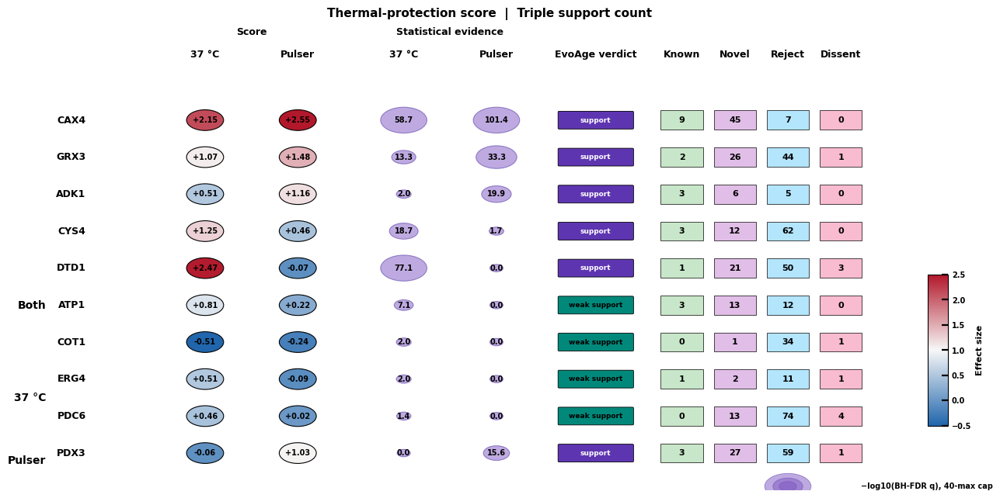

✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/04_bubble_table/EvoAge_Significant_Gene_Bubble_Table.svg
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/04_bubble_table/EvoAge_Significant_Gene_Bubble_Table.png
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/04_bubble_table/EvoAge_Significant_Gene_Bubble_Table.pdf

📊 Bubble Table Summary:
Total key genes: 10

Genes by group:
  Both: 4 genes
  37 °C: 5 genes
  Pulser: 1 genes

Verdict distribution:
  support: 6 genes
  weak_support: 4 genes

✅ All done! Plots saved in: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/04_bubble_table


In [147]:
# This magic command makes plots appear in the notebook
%matplotlib inline

"""
04_bubble_table
---------------
Integrated evidence matrix (bubble table) for the ten FDR-significant genes:
  - Effect sizes (circle colour, diverging blue-red, -0.5 to +2.5)
  - Statistical evidence (circle size, -log10 q, capped at 40 for display)
  - EvoAge verdict pills
  - Known / Novel / Reject / Dissent evidence counts

INPUT : /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/04_bubble_table/input_key_genes_evidence.csv
OUTPUT: EvoAge_Significant_Gene_Bubble_Table.svg / .png / .pdf in the same directory
"""

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, FancyBboxPatch
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap

# ── Configuration ──────────────────────────────────────────────────────
# Input file path
INPUT_FILE = '/storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/04_bubble_table/input_key_genes_evidence.csv'

# Output directory (same as input file location)
OUTPUT_DIR = os.path.dirname(INPUT_FILE)
DPI = 600

# ── Load data ──────────────────────────────────────────────────────────
print(f"Loading data from: {INPUT_FILE}")
df = pd.read_csv(INPUT_FILE)
print(f"Loaded {len(df)} key genes")

# Check required columns
required_cols = ['Name', 'Score_37C', 'Score_Pulser', 'neglog10q_37C', 'neglog10q_Pulser', 
                 'verdict', 'known', 'novel', 'reject', 'dissent']
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    print(f"Warning: Missing columns: {missing_cols}")
    print("Available columns:", df.columns.tolist())

# ── Prepare data ──────────────────────────────────────────────────────
# Order: both / 37C / pulser groups
order = ['CAX4', 'GRX3', 'ADK1', 'CYS4', 'DTD1', 'ATP1', 'COT1', 'ERG4', 'PDC6', 'PDX3']
group_of = {'CAX4': 'Both', 'GRX3': 'Both', 'ADK1': 'Both', 'CYS4': 'Both',
            'DTD1': '37 °C', 'ATP1': '37 °C', 'COT1': '37 °C', 'ERG4': '37 °C',
            'PDC6': '37 °C', 'PDX3': 'Pulser'}

# Ensure all genes are in the dataframe
for gene in order:
    if gene not in df['Name'].values:
        print(f"Warning: Gene {gene} not found in data")

df['order'] = df['Name'].map({n: i for i, n in enumerate(order)})
df = df.sort_values('order')

verdict_colors = {'support': '#5E35B1', 'weak_support': '#00897B',  # dark purple, teal
                  'partial_support': '#C0CA33', 'no_support': '#BDBDBD'}  # muted yellow, grey

# ── Create figure ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 6.5))
ax.set_xlim(0, 13)
ax.set_ylim(-1, len(df) + 1.5)

# Column centres
col_score37, col_scoreP = 2.2, 3.6
col_q37, col_qP = 5.2, 6.6
col_verdict = 8.1
col_known, col_novel, col_reject, col_dissent = 9.4, 10.2, 11.0, 11.8

# Headers
for x, label in [(col_score37, '37 °C'), (col_scoreP, 'Pulser'),
                 (col_q37, '37 °C'), (col_qP, 'Pulser'),
                 (col_verdict, 'EvoAge verdict'),
                 (col_known, 'Known'), (col_novel, 'Novel'),
                 (col_reject, 'Reject'), (col_dissent, 'Dissent')]:
    ax.text(x, len(df) + 0.7, label, ha='center', fontsize=9, fontweight='bold')
ax.text(2.9, len(df) + 1.3, 'Score', ha='center', fontsize=9, fontweight='bold')
ax.text(5.9, len(df) + 1.3, 'Statistical evidence', ha='center', fontsize=9, fontweight='bold')

# Group labels
group_y = {'Both': 4, '37 °C': 1.5, 'Pulser': -0.2}
for grp, y in group_y.items():
    ax.text(-0.2, y, grp, ha='right', va='center', fontsize=10, fontweight='bold')

# Diverging colormap for effect size
cmap = LinearSegmentedColormap.from_list('div', ['#2166AC', '#F7F7F7', '#B2182B'])
norm_eff = plt.Normalize(-0.5, 2.5)

# ── Plot data ──────────────────────────────────────────────────────────
for i, (_, r) in enumerate(df.iterrows()):
    y = len(df) - 1 - i  # top-down
    nm = r['Name']
    ax.text(0.4, y, nm, ha='right', va='center', fontsize=9, fontweight='bold')

    # Effect scores
    for x, score in [(col_score37, r['Score_37C']), (col_scoreP, r['Score_Pulser'])]:
        if pd.notna(score):
            c = cmap(norm_eff(score))
            ax.add_patch(Circle((x, y), 0.28, facecolor=c, edgecolor='black', lw=0.8, zorder=3))
            ax.text(x, y, f'{score:+.2f}', ha='center', va='center', fontsize=7, fontweight='bold')

    # Statistical evidence (-log10 q, capped at 40 for display)
    for x, q in [(col_q37, r['neglog10q_37C']), (col_qP, r['neglog10q_Pulser'])]:
        if pd.notna(q):
            size = min(q, 40)
            radius = 0.1 + 0.25 * (size / 40)
            ax.add_patch(Circle((x, y), radius, facecolor='#7E57C2', alpha=0.5,
                                edgecolor='#4527A0', lw=0.8, zorder=3))
            ax.text(x, y, f'{q:.1f}', ha='center', va='center', fontsize=7, fontweight='bold')

    # Verdict pill
    v = r['verdict']
    vc = verdict_colors.get(v, '#BDBDBD')
    ax.add_patch(FancyBboxPatch((col_verdict - 0.55, y - 0.22), 1.1, 0.44,
                                boxstyle='round,pad=0.02', facecolor=vc,
                                edgecolor='black', lw=0.6, zorder=3))
    text_color = 'white' if v == 'support' else 'black'
    ax.text(col_verdict, y, v.replace('_', ' '), ha='center', va='center',
            fontsize=6.5, fontweight='bold', color=text_color)

    # Evidence counts
    for x, val, color in [(col_known, r['known'], '#C8E6C9'),
                          (col_novel, r['novel'], '#E1BEE7'),
                          (col_reject, r['reject'], '#B3E5FC'),
                          (col_dissent, r['dissent'], '#F8BBD0')]:
        ax.add_patch(Rectangle((x - 0.32, y - 0.26), 0.64, 0.52, facecolor=color,
                               edgecolor='black', lw=0.5, zorder=3))
        txt = str(int(val)) if pd.notna(val) else 'NA'
        ax.text(x, y, txt, ha='center', va='center', fontsize=8, fontweight='bold')

ax.axis('off')
ax.set_title('Thermal-protection score  |  Triple support count',
             fontsize=11, fontweight='bold', pad=10)

# Legend for q-size
for q in [5, 20, 40]:
    ax.add_patch(Circle((11.0, -0.9), 0.1 + 0.25 * (q / 40), facecolor='#7E57C2',
                        alpha=0.5, edgecolor='#4527A0', lw=0.6))
ax.text(12.1, -0.9, '−log10(BH-FDR q), 40-max cap', fontsize=7, va='center')

# Add effect size colorbar legend
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.3])
cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm_eff, cmap=cmap), 
                    cax=cbar_ax, orientation='vertical')
cbar.set_label('Effect size', fontsize=8)
cbar.ax.tick_params(labelsize=7)

plt.tight_layout()

# ── Show in notebook ──────────────────────────────────────────────────
plt.show()

# ── Save figures ──────────────────────────────────────────────────────
output_stem = os.path.join(OUTPUT_DIR, 'EvoAge_Significant_Gene_Bubble_Table')
for ext in ['svg', 'png', 'pdf']:
    output_path = f"{output_stem}.{ext}"
    plt.savefig(output_path, dpi=DPI, bbox_inches='tight')
    print(f"✅ Saved: {output_path}")

plt.close()

# ── Print summary ──────────────────────────────────────────────────────
print("\n📊 Bubble Table Summary:")
print(f"Total key genes: {len(df)}")
print("\nGenes by group:")
for grp in ['Both', '37 °C', 'Pulser']:
    count = sum([1 for gene in df['Name'] if group_of.get(gene) == grp])
    print(f"  {grp}: {count} genes")

print("\nVerdict distribution:")
for verdict in ['support', 'weak_support', 'partial_support', 'no_support']:
    count = sum(df['verdict'] == verdict)
    if count > 0:
        print(f"  {verdict}: {count} genes")

print(f"\n✅ All done! Plots saved in: {OUTPUT_DIR}")

## Supplementary Figure 1

## Supp 1a

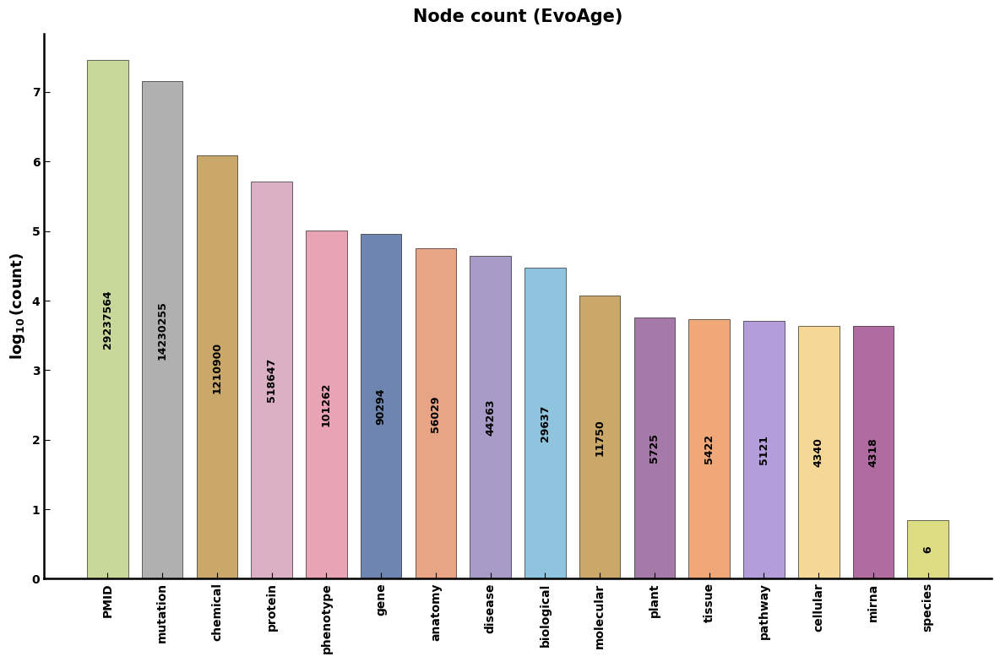

Plot saved successfully!


In [105]:
# Make sure inline plotting is enabled
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Optional: If you don't need circlify anymore, remove the import
# import circlify

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
df = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/NodeType_AllKGs_1to1_and_121_12M.csv")

# -----------------------------------------------------------------------------
# 2. PRETTY SHORT LABELS + COLOR PALETTE
# -----------------------------------------------------------------------------
short_names = {
    "PMID": "PMID",
    "Mutation": "mutation",
    "ChemicalEntity": "chemical",
    "Protein": "protein",
    "Phenotype": "phenotype",
    "Gene": "gene",
    "Disease": "disease",
    "BiologicalProcess": "biological",
    "AnatomicalEntity": "anatomy",
    "MolecularFunction": "molecular",
    "PlantSpecies": "plant",
    "Tissue": "tissue",
    "Pathway": "pathway",
    "CellularComponent": "cellular",
    "Mirna": "mirna",
    "Species": "species",
}

nodetype_colors = {
    "PMID": "#c8d89a",
    "Mutation": "#b0b0b0",
    "ChemicalEntity": "#c9a86a",
    "Protein": "#dcb0c4",
    "Phenotype": "#e8a4b5",
    "Gene": "#6e85b0",
    "Disease": "#a89bc8",
    "BiologicalProcess": "#8ec4de",
    "AnatomicalEntity": "#e8a586",
    "MolecularFunction": "#c9a86a",
    "PlantSpecies": "#a67aa8",
    "Tissue": "#f0a878",
    "Pathway": "#b39ddb",
    "CellularComponent": "#f5d896",
    "Mirna": "#b06ba0",
    "Species": "#dcdc82",
}

# -----------------------------------------------------------------------------
# 3. CREATE THE PLOT
# -----------------------------------------------------------------------------
# Clear any existing figures
plt.close('all')

# Create figure and axis
fig, ax1 = plt.subplots(1, 1, figsize=(12, 8))

# =============================================================================
# BAR PLOT — EvoAge_121_12M
# =============================================================================
evo = df[["NodeType", "EvoAge_121_12M"]].copy()
evo = evo[evo["EvoAge_121_12M"] > 0].sort_values("EvoAge_121_12M", ascending=False).reset_index(drop=True)
evo["log"] = np.log10(evo["EvoAge_121_12M"] + 1)

x = np.arange(len(evo))
bar_colors = [nodetype_colors.get(nt, "#cccccc") for nt in evo["NodeType"]]

# Create the bars
bars = ax1.bar(x, evo["log"], color=bar_colors, edgecolor="black", linewidth=0.4, width=0.75)

# Count labels rotated 90° inside/on each bar
for xi, (_, row) in zip(x, evo.iterrows()):
    ax1.text(xi, row["log"] * 0.5, f"{int(row['EvoAge_121_12M'])}",
             ha="center", va="center", rotation=90, fontsize=9, color="black")

# Set labels and title
ax1.set_xticks(x)
ax1.set_xticklabels([short_names.get(nt, nt) for nt in evo["NodeType"]],
                    rotation=90, fontsize=10)
ax1.set_ylabel(r"$\log_{10}$(count)", fontsize=13)
ax1.set_title("Node count (EvoAge)", fontsize=15, pad=10)

# Remove top and right spines
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.tick_params(axis="both", which="major", length=5, width=0.8, color="black", labelsize=10)
ax1.grid(False)

# Adjust layout
plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. DISPLAY THE PLOT
# -----------------------------------------------------------------------------
# Show the plot
plt.show()

# -----------------------------------------------------------------------------
# 5. SAVE AS PDF (after showing)
# -----------------------------------------------------------------------------
# Save the figure
fig.savefig("FIG1/Fig1_supp_evoage_bar.pdf", format="pdf", bbox_inches="tight")
print("Plot saved successfully!")

## Supp 1b

Saved EvoAge_ChordDiagram_log10_matched.svg and preview png


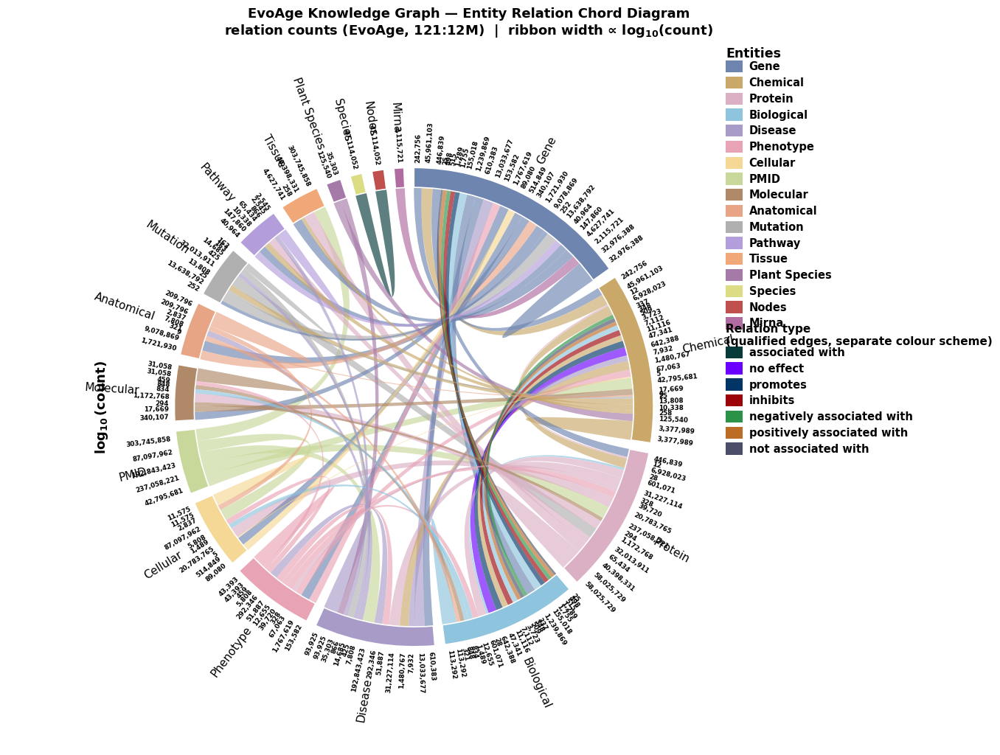

In [149]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Wedge, Rectangle
import matplotlib as mpl

# ------------------------------------------------------------------
# 0. Editable SVG text
# ------------------------------------------------------------------
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family'] = 'DejaVu Sans'

# ------------------------------------------------------------------
# 1. Load & parse
# ------------------------------------------------------------------
CSV_PATH = 'RelationType_AllKGs_1to1_and_121_12M.csv'
VALUE_COL = 'EvoAge_121_12M'

df = pd.read_csv(CSV_PATH)
df = df[df['Relation'] != 'Total Triples'].copy()
df = df[df[VALUE_COL] > 0].reset_index(drop=True)

def parse_relation(relation):
    parts = relation.split('_')
    if len(parts) == 2:
        return parts[0], None, parts[1], 'entity'
    else:
        # first token = source, LAST token = target, everything in between = verb
        return parts[0], '_'.join(parts[1:-1]), parts[-1], 'verb'

parsed = df['Relation'].apply(parse_relation)
df['src']  = parsed.apply(lambda x: x[0])
df['verb'] = parsed.apply(lambda x: x[1])
df['tgt']  = parsed.apply(lambda x: x[2])
df['edge_type'] = parsed.apply(lambda x: x[3])

# camel-case -> "spaced lower case" for nice legend text, e.g.
# "NegativelyAssociatedWith" -> "negatively associated with"
def humanize(camel):
    out = []
    for ch in camel:
        if ch.isupper() and out:
            out.append(' ')
        out.append(ch.lower())
    return ''.join(out)

# ------------------------------------------------------------------
# 2. log10 weight used for ribbon/arc geometry (raw count kept for labels)
# ------------------------------------------------------------------
df['raw'] = df[VALUE_COL]
df['logw'] = np.log10(df['raw'] + 1)

# ------------------------------------------------------------------
# 3. Entities & node ordering
# ------------------------------------------------------------------
entities = sorted(set(df['src']) | set(df['tgt']))
idx = {e: i for i, e in enumerate(entities)}
n = len(entities)

# total log-weighted flux touching each entity (for arc size)
flux = np.zeros(n)
for _, row in df.iterrows():
    flux[idx[row['src']]] += row['logw']
    flux[idx[row['tgt']]] += row['logw']

order = np.argsort(-flux)
entities = [entities[i] for i in order]
idx = {e: i for i, e in enumerate(entities)}
flux = flux[order]

# ------------------------------------------------------------------
# 4. Colour palettes
#    - entity palette: pastel, one colour per entity (used for entity-entity
#      ribbons AND node wedges)
#    - relation-type palette: separate, more saturated colours, used ONLY for
#      verb-qualified ribbons (Promotes / Inhibits / etc.)
# ------------------------------------------------------------------
# Colours matched (pixel-sampled) from the reference "EvoAge (Node count)"
# bar chart, so the entity colours are consistent across figures.
entity_hex = {
    'PMID':               '#C8D89A',  # olive-green
    'Mutation':           '#B0B0B0',  # grey
    'ChemicalEntity':     '#C9A86A',  # tan / gold-brown
    'Protein':            '#DCB0C4',  # pink
    'Phenotype':          '#E8A4B5',  # rose pink
    'Gene':               '#6E85B0',  # dark blue / navy
    'AnatomicalEntity':   '#E8A586',  # salmon / orange
    'Disease':            '#A89BC8',  # light purple
    'BiologicalProcess':  '#8EC4DE',  # sky blue
    'MolecularFunction':  '#B08968',  # muted brown (reference re-used the
                                      # chemical tan here; shifted slightly
                                      # darker so every entity stays
                                      # distinguishable, per your note)
    'PlantSpecies':       '#A67AA8',  # plum
    'Tissue':             '#F0A878',  # orange
    'Pathway':            '#B39DDB',  # lavender-purple
    'CellularComponent':  '#F5D896',  # cream / pale yellow
    'Mirna':              '#B06BA0',  # magenta-plum
    'Species':            '#DCDC82',  # yellow-green
    'Nodes':              '#C0504D',  # brick red (not in the reference
                                      # chart, so a new but equally
                                      # contrasting colour was added)
}
node_color = {e: entity_hex.get(e, '#CCCCCC') for e in entities}

# Relation-type (verb-qualified edge) palette: kept intentionally as
# saturated/dark "jewel tones" -- a different visual register from the
# pastel entity colours above -- so verb-qualified ribbons never get
# confused with a plain entity-entity ribbon, even where hue families
# are close (e.g. reds vs pinks, greens vs olive).
verb_palette = {
    'AssociatedWith':           '#073B3A',  # deep teal
    'NoEffect':                 '#6A00FF',  # vivid violet
    'Promotes':                 '#003566',  # dark navy
    'Inhibits':                 '#9D0208',  # dark red
    'NegativelyAssociatedWith': '#2B9348',  # deep green
    'PositivelyAssociatedWith': '#BC6C25',  # burnt amber
    'NotAssociatedWith':        '#4A4E69',  # slate grey-purple
}

def edge_color(row):
    if row['edge_type'] == 'entity':
        return node_color[row['src']]
    return verb_palette.get(row['verb'], '#999999')

df['color'] = df.apply(edge_color, axis=1)

# short display names for entity labels (match reference style, e.g.
# "BiologicalProcess" -> "Biological")
short_name = {
    'BiologicalProcess': 'Biological',
    'CellularComponent': 'Cellular',
    'MolecularFunction':  'Molecular',
    'AnatomicalEntity':   'Anatomical',
    'ChemicalEntity':     'Chemical',
    'PlantSpecies':       'Plant Species',
}
def short(e):
    return short_name.get(e, e)

# ------------------------------------------------------------------
# 5. Layout: angles for each node's arc (deg), clockwise from top
# ------------------------------------------------------------------
GAP_DEG = 2.4
total_gap = GAP_DEG * n
available_deg = 360 - total_gap
frac = flux / flux.sum()
node_span = frac * available_deg

start_ang = 90.0
node_start, node_end = {}, {}
cursor = start_ang
for e, span in zip(entities, node_span):
    node_start[e] = cursor - span
    node_end[e] = cursor
    cursor = cursor - span - GAP_DEG
node_center = {e: (node_start[e] + node_end[e]) / 2 for e in entities}

# ------------------------------------------------------------------
# 6. Slots (one per ribbon end) sized by log-weight
# ------------------------------------------------------------------
slots = {e: [] for e in entities}
for edge_id, row in df.iterrows():
    s, t, w = row['src'], row['tgt'], row['logw']
    slots[s].append(dict(partner=t, weight=w, edge_id=edge_id, end='src'))
    slots[t].append(dict(partner=s, weight=w, edge_id=edge_id, end='tgt'))

for e in entities:
    def sort_key(sl):
        p = sl['partner']
        return -1000 if p == e else node_center[p]
    slots[e].sort(key=sort_key)

edge_geom = {}
for e in entities:
    s_list = slots[e]
    wsum = sum(sl['weight'] for sl in s_list)
    if wsum == 0:
        continue
    span = node_end[e] - node_start[e]
    cur = node_start[e]
    for sl in s_list:
        w = span * (sl['weight'] / wsum)
        a0, a1 = cur, cur + w
        cur = a1
        edge_geom.setdefault(sl['edge_id'], {})[sl['end']] = (a0, a1)

# ------------------------------------------------------------------
# 7. Drawing helpers
# ------------------------------------------------------------------
R_IN = 1.0
R_OUT = 1.09
N_ARC_PTS = 40

def arc_points(a0, a1, r=R_IN):
    angs = np.linspace(np.radians(a0), np.radians(a1), N_ARC_PTS)
    return np.column_stack([r * np.cos(angs), r * np.sin(angs)])

def ribbon_path(srcA, srcB, tgtA, tgtB):
    p_src = arc_points(srcA, srcB)
    p_tgt = arc_points(tgtA, tgtB)
    verts = [p_src[0]]
    codes = [Path.MOVETO]
    for p in p_src[1:]:
        verts.append(p); codes.append(Path.LINETO)
    c1, c2 = p_src[-1] * 0.35, p_tgt[0] * 0.35
    verts += [c1, c2, p_tgt[0]]; codes += [Path.CURVE4]*3
    for p in p_tgt[1:]:
        verts.append(p); codes.append(Path.LINETO)
    c3, c4 = p_tgt[-1] * 0.35, p_src[0] * 0.35
    verts += [c3, c4, p_src[0]]; codes += [Path.CURVE4]*3
    return Path(verts, codes)

# ------------------------------------------------------------------
# 8. Plot
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 12), subplot_kw=dict(aspect='equal'))
ax.set_xlim(-1.85, 2.35)
ax.set_ylim(-1.55, 1.65)
ax.axis('off')

edges_sorted = df.sort_values('raw', ascending=False).index.tolist()
for eid in edges_sorted:
    row = df.loc[eid]
    if eid not in edge_geom or 'src' not in edge_geom[eid] or 'tgt' not in edge_geom[eid]:
        continue
    a0, a1 = edge_geom[eid]['src']
    b0, b1 = edge_geom[eid]['tgt']
    path = ribbon_path(a0, a1, b0, b1)
    patch = PathPatch(path, facecolor=row['color'], edgecolor='none', alpha=0.65,
                       linewidth=0, zorder=1)
    ax.add_patch(patch)

# node wedges
for e in entities:
    w = Wedge((0, 0), R_OUT, node_start[e], node_end[e], width=R_OUT - R_IN,
              facecolor=node_color[e], edgecolor='white', linewidth=1.2, zorder=3)
    ax.add_patch(w)

# raw-count numbers next to each ribbon slot
for eid, ends in edge_geom.items():
    raw = df.loc[eid, 'raw']
    label = f'{int(raw):,}'
    for end_key in ('src', 'tgt'):
        if end_key not in ends:
            continue
        a0, a1 = ends[end_key]
        mid = np.radians((a0 + a1) / 2)
        r_txt = R_OUT + 0.025
        x, y = r_txt * np.cos(mid), r_txt * np.sin(mid)
        rot = np.degrees(mid)
        ha = 'left'
        if 90 < (np.degrees(mid) % 360) < 270:
            rot += 180
            ha = 'right'
        ax.text(x, y, label, rotation=rot, rotation_mode='anchor',
                ha=ha, va='center', fontsize=6.3, zorder=5)

# entity name labels (outer ring)
for e in entities:
    ang = np.radians(node_center[e])
    r_label = R_OUT + 0.16
    x, y = r_label * np.cos(ang), r_label * np.sin(ang)
    rot = node_center[e]
    ha = 'left'
    if 90 < node_center[e] % 360 < 270:
        rot += 180
        ha = 'right'
    ax.text(x, y, short(e), rotation=rot, rotation_mode='anchor',
            ha=ha, va='center', fontsize=11, fontweight='medium', zorder=4)

# "log10(count)" radial axis label (reference-style)
ax.text(-1.42, 0, r'$\log_{10}(\mathrm{count})$', rotation=90, rotation_mode='anchor',
        ha='center', va='center', fontsize=13)

ax.set_title('EvoAge Knowledge Graph — Entity Relation Chord Diagram\n'
             'relation counts (EvoAge, 121:12M)  |  ribbon width \u221d log$_{10}$(count)',
             fontsize=13, pad=10)

# ------------------------------------------------------------------
# 9. Legend: entities block + relation-type block
# ------------------------------------------------------------------
leg_x = 1.42
leg_y = 1.55
box_w, box_h, gap = 0.075, 0.055, 0.018

ax.text(leg_x, leg_y + 0.06, 'Entities', fontsize=12.5, fontweight='bold', va='center')
y = leg_y
for e in entities:
    ax.add_patch(Rectangle((leg_x, y - box_h/2), box_w, box_h,
                            facecolor=node_color[e], edgecolor='none'))
    ax.text(leg_x + box_w + 0.03, y, short(e), fontsize=10.5, va='center')
    y -= (box_h + gap)

y -= 0.04
ax.text(leg_x, y + 0.06, 'Relation type\n(qualified edges, separate colour scheme)',
        fontsize=11, fontweight='bold', va='center')
y -= 0.02
for verb, col in verb_palette.items():
    if verb not in df.loc[df['edge_type']=='verb', 'verb'].unique():
        continue
    ax.add_patch(Rectangle((leg_x, y - box_h/2), box_w, box_h,
                            facecolor=col, edgecolor='none'))
    ax.text(leg_x + box_w + 0.03, y, humanize(verb), fontsize=10.5, va='center')
    y -= (box_h + gap)

plt.tight_layout()
plt.savefig('EvoAge_ChordDiagram_log10_matched.svg', format='svg', bbox_inches='tight')
plt.savefig('EvoAge_ChordDiagram_log10_matched_preview.png', format='png', dpi=170, bbox_inches='tight')
print("Saved EvoAge_ChordDiagram_log10_matched.svg and preview png")


## Supp 1c

In [155]:
import pandas as pd
import plotly.graph_objects as go

# Load data
df = pd.read_csv('orthology-mapping.csv')

print("Data loaded successfully!")
print(df)

# Prepare data
species_list = df['Species'].tolist()
labels = species_list + ['1-to-1\northolog', '1-to-M\northologs', 'Unmapped']

source = []
target = []
value = []

species_indices = {species: idx for idx, species in enumerate(species_list)}
category_indices = {
    'OneToOne': len(species_list),
    'OneToMany': len(species_list) + 1,
    'Unmapped': len(species_list) + 2
}

for idx, row in df.iterrows():
    species = row['Species']
    species_idx = species_indices[species]
    
    source.append(species_idx)
    target.append(category_indices['OneToOne'])
    value.append(row['OneToOne'])
    
    source.append(species_idx)
    target.append(category_indices['OneToMany'])
    value.append(row['OneToMany'])
    
    source.append(species_idx)
    target.append(category_indices['Unmapped'])
    value.append(row['Unmapped'])

total_1to1 = df['OneToOne'].sum()
total_1toM = df['OneToMany'].sum()
total_unmapped = df['Unmapped'].sum()

# Cleaner version with gray links
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=30,
        thickness=25,
        line=dict(color="white", width=1),
        label=labels,
        color=['#3498DB', '#E67E22', '#2ECC71', '#E74C3C', '#9B59B6', 
               '#2980B9', '#F39C12', '#C0392B'],
        x=[0.05, 0.05, 0.05, 0.05, 0.05, 0.82, 0.82, 0.82],
        y=[0.15, 0.32, 0.49, 0.66, 0.83, 0.25, 0.55, 0.80]
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color='rgba(180, 180, 180, 0.5)'  # Gray semi-transparent links
    )
)])

fig.update_layout(
    title=dict(
        text="<b>Ortholog Gene Mapping from Other Species to Human</b>",
        font=dict(size=22, family="Arial", color="#2C3E50"),
        x=0.5
    ),
    width=1200,
    height=700,
    margin=dict(t=80, b=120, l=60, r=60),
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Add annotations
fig.add_annotation(
    x=0.5,
    y=-0.10,
    xref="paper",
    yref="paper",
    text=(f"<b>Summary</b>  |  "
          f"<span style='color:#2980B9;'>●</span> 1-to-1: <b>{total_1to1:,}</b>  |  "
          f"<span style='color:#F39C12;'>●</span> 1-to-M: <b>{total_1toM:,}</b>  |  "
          f"<span style='color:#C0392B;'>●</span> Unmapped: <b>{total_unmapped:,}</b>"),
    showarrow=False,
    font=dict(size=14),
    align="center"
)

fig.show()
fig.write_html("sankey_ortholog_mapping_simple.html")
print("\n✅ Simple Sankey diagram saved as 'sankey_ortholog_mapping_simple.html'")

Data loaded successfully!
      Species  Total_Genes  OneToOne  OneToMany  Unmapped
0       Yeast         6998      1392        758      4848
1    Celegans        19019      2926       1568     14525
2  Drosophila        14897      3282       1782      9833
3       Mouse        33148     16583       1758     14807
4   Zebrafish        21584      9597       6389      5598



✅ Simple Sankey diagram saved as 'sankey_ortholog_mapping_simple.html'


## Supp 1e

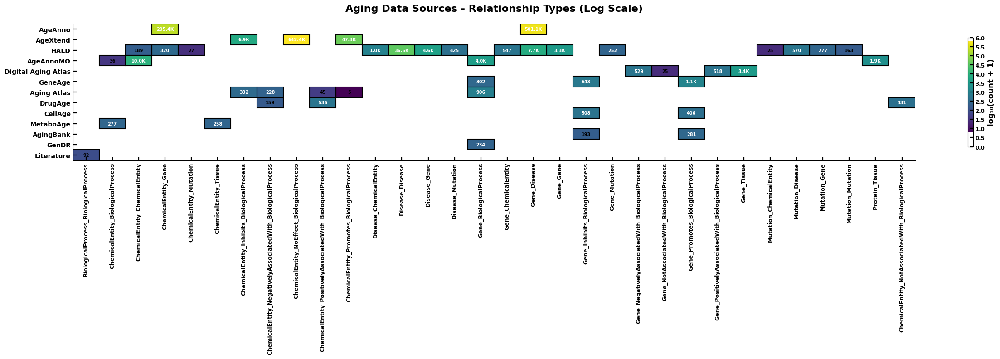

Aging Data Sources Summary:
Number of aging data sources: 13
Data sources: AgeAnno, AgeXtend, HALD, AgeAnnoMO, Digital Aging Atlas, GeneAge, Aging Atlas, DrugAge, CellAge, MetaboAge, AgingBank, GenDR, Literature

Number of relationship types with data: 32

Top relationship types by total count:
  ChemicalEntity_NoEffect_BiologicalProcess: 642,388
  Gene_Disease: 508,751
  ChemicalEntity_Gene: 205,698
  ChemicalEntity_Promotes_BiologicalProcess: 47,341
  Disease_Disease: 36,458
  ChemicalEntity_ChemicalEntity: 10,201
  ChemicalEntity_Inhibits_BiologicalProcess: 7,214
  Gene_BiologicalProcess: 5,430
  Disease_Gene: 4,574
  Gene_Tissue: 3,402


In [159]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
import matplotlib.colors as mcolors

# Read the CSV file
df = pd.read_csv('ALL_data_Source_Triple_source_databases_KG.csv')

# Filter for aging data sources only (KG_Type == 'Aging')
aging_df = df[df['KG_Type'] == 'Aging'].copy()

# Define all columns to check (all relationship types)
all_columns = aging_df.columns.tolist()
# Remove non-data columns
exclude_cols = ['Source', 'KG_Type', 'Total', 'Species_AssociatedWith', 'PlantSpecies_ChemicalEntity', 
                'PlantSpecies_Disease', 'PMID_CellularComponent', 'PMID_ChemicalEntity', 'PMID_Disease', 
                'PMID_Protein', 'PMID_Tissue', 'Phenotype_BiologicalProcess', 'Phenotype_CellularComponent',
                'Phenotype_MolecularFunction', 'Phenotype_Protein', 'Phenotype_Phenotype', 'Phenotype_Gene',
                'Phenotype_Disease', 'Phenotype_ChemicalEntity', 'Mirna_Gene']
columns_to_plot = [col for col in all_columns if col not in exclude_cols and col != 'Total']

# Filter to columns that have some data in aging sources
valid_columns = []
for col in columns_to_plot:
    if col in aging_df.columns and aging_df[col].sum() > 0:
        valid_columns.append(col)

# Prepare the data matrix
aging_data = aging_df[['Source'] + valid_columns].copy()
aging_data.set_index('Source', inplace=True)

# Remove sources that have no data in these columns
aging_data = aging_data[aging_data.sum(axis=1) > 0]

# Replace 0 with NaN (we don't want to display zeros)
aging_data = aging_data.replace(0, np.nan)

# Apply log10 transformation (adding small constant to avoid log(0) issues)
# We'll use log10(count + 1) for the color mapping
log_data = np.log10(aging_data.values + 1)
# The +1 ensures log(1)=0 for zero values, but we'll mask NaNs anyway

# Create the plot with the specific color gradient
fig, ax = plt.subplots(figsize=(25, 8))

# Define the colormap matching the screenshot (blue to red)
# This creates a diverging colormap from blue through white to red
cmap = plt.cm.viridis

# Create the heatmap
# We use log_data for color mapping but keep original values for text
im = ax.imshow(log_data, cmap=cmap, aspect='auto', 
               vmin=np.nanmin(log_data), vmax=np.nanmax(log_data))

# Set ticks and labels
ax.set_xticks(np.arange(len(aging_data.columns)))
ax.set_yticks(np.arange(len(aging_data.index)))
ax.set_xticklabels(aging_data.columns, rotation=90, ha='center', fontsize=9)
ax.set_yticklabels(aging_data.index, fontsize=10)

# Add colored boxes with borders for each cell
for i in range(len(aging_data.index)):
    for j in range(len(aging_data.columns)):
        value = aging_data.iloc[i, j]
        if not pd.isna(value):
            # Add rectangle border
            rect = Rectangle((j-0.5, i-0.5), 1, 1, fill=False, edgecolor='black', linewidth=1.5)
            ax.add_patch(rect)
            
            # Format the value
            if value >= 1000000:
                text = f'{value/1000000:.1f}M'
            elif value >= 1000:
                text = f'{value/1000:.1f}K'
            else:
                text = f'{int(value)}'
            
            # Choose text color based on background
            log_val = log_data[i, j]
            if log_val > np.nanmax(log_data) * 0.4:
                color = 'white'
            else:
                color = 'black'
            ax.text(j, i, text, ha='center', va='center', color=color, fontsize=7, weight='bold')

# Add colorbar with log scale labels
cbar = plt.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('log₁₀(count + 1)', fontsize=12)

# Add legend for log values
log_ticks = np.arange(0, np.nanmax(log_data) + 0.5, 0.5)
cbar.set_ticks(log_ticks)
cbar.set_ticklabels([f'{tick:.1f}' for tick in log_ticks])

# Set title
ax.set_title('Aging Data Sources - Relationship Types (Log Scale)', fontsize=16, pad=20)

# Adjust layout
plt.tight_layout()

# Save the figure (optional)
# plt.savefig('aging_data_heatmap.png', dpi=300, bbox_inches='tight')

plt.show()

# Print summary statistics
print("Aging Data Sources Summary:")
print("=" * 60)
print(f"Number of aging data sources: {len(aging_data.index)}")
print(f"Data sources: {', '.join(aging_data.index)}")
print(f"\nNumber of relationship types with data: {len(aging_data.columns)}")
print("\nTop relationship types by total count:")
totals = aging_data.sum(axis=0).sort_values(ascending=False)
for col, val in totals.head(10).items():
    print(f"  {col}: {int(val):,}")

# Alternative: Create a version that only shows columns where any source has data
def create_filtered_heatmap():
    """Create a more focused heatmap with only active relationship types"""
    
    # Get columns where at least one source has data
    active_columns = []
    for col in valid_columns:
        if aging_df[col].sum() > 0:
            active_columns.append(col)
    
    # Prepare data
    filtered_data = aging_df[['Source'] + active_columns].copy()
    filtered_data.set_index('Source', inplace=True)
    filtered_data = filtered_data.replace(0, np.nan)
    filtered_data = filtered_data[filtered_data.sum(axis=1) > 0]
    
    # Log transform
    log_filtered = np.log10(filtered_data.values + 1)
    
    # Plot
    fig, ax = plt.subplots(figsize=(20, 8))
    
    im = ax.imshow(log_filtered, cmap='RdYlBu_r', aspect='auto', 
                   vmin=0, vmax=np.nanmax(log_filtered))
    
    ax.set_xticks(np.arange(len(filtered_data.columns)))
    ax.set_yticks(np.arange(len(filtered_data.index)))
    ax.set_xticklabels(filtered_data.columns, rotation=90, ha='center', fontsize=8)
    ax.set_yticklabels(filtered_data.index, fontsize=10)
    
    # Add boxes and text
    for i in range(len(filtered_data.index)):
        for j in range(len(filtered_data.columns)):
            value = filtered_data.iloc[i, j]
            if not pd.isna(value):
                rect = Rectangle((j-0.5, i-0.5), 1, 1, fill=False, edgecolor='black', linewidth=1.5)
                ax.add_patch(rect)
                
                if value >= 1000000:
                    text = f'{value/1000000:.1f}M'
                elif value >= 1000:
                    text = f'{value/1000:.1f}K'
                else:
                    text = f'{int(value)}'
                
                log_val = log_filtered[i, j]
                color = 'white' if log_val > np.nanmax(log_filtered) * 0.4 else 'black'
                ax.text(j, i, text, ha='center', va='center', color=color, fontsize=7, weight='bold')
    
    cbar = plt.colorbar(im, ax=ax, shrink=0.8)
    cbar.set_label('log₁₀(count + 1)', fontsize=12)
    
    ax.set_title('Aging Data Sources - Active Relationship Types (Log Scale)', fontsize=14, pad=15)
    
    plt.tight_layout()
    plt.show()

# Uncomment to see the filtered version
# create_filtered_heatmap()

# Create a table version showing only the non-zero values
def create_table_view():
    """Create a table view similar to the screenshot"""
    
    # Get the data
    table_data = aging_df[['Source'] + valid_columns].copy()
    table_data.set_index('Source', inplace=True)
    
    # Only keep columns with data
    cols_with_data = table_data.columns[table_data.sum(axis=0) > 0]
    table_data = table_data[cols_with_data]
    
    # Only keep rows with data
    rows_with_data = table_data.index[table_data.sum(axis=1) > 0]
    table_data = table_data.loc[rows_with_data]
    
    # Display as a styled table
    fig, ax = plt.subplots(figsize=(20, len(table_data) * 0.5 + 1))
    ax.axis('off')
    
    # Create the table
    table = ax.table(cellText=table_data.values.astype(str).tolist(),
                     rowLabels=table_data.index,
                     colLabels=table_data.columns,
                     cellLoc='center',
                     rowLoc='center',
                     loc='center')
    
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1.2, 1.5)
    
    # Color the cells based on values
    for i in range(len(table_data.index)):
        for j in range(len(table_data.columns)):
            value = table_data.iloc[i, j]
            if value > 0:
                # Get cell
                cell = table[(i+1, j)]
                # Color based on log value
                log_val = np.log10(value + 1)
                max_log = np.log10(table_data.max().max() + 1)
                if log_val / max_log > 0.6:
                    cell.set_facecolor('#e74c3c')  # Red
                    cell.set_text_props(color='white')
                elif log_val / max_log > 0.3:
                    cell.set_facecolor('#f39c12')  # Orange
                    cell.set_text_props(color='white')
                else:
                    cell.set_facecolor('#3498db')  # Blue
                    cell.set_text_props(color='white')
            else:
                cell = table[(i+1, j)]
                cell.set_facecolor('#f0f0f0')
                cell.set_text_props(color='gray')
    
    plt.title('Aging Data Sources - Relationship Counts', fontsize=14, pad=20)
    plt.tight_layout()
    plt.show()

# Uncomment to see the table view
# create_table_view()

## Supp 1f

Found 37 sources out of 37 specified
Auto-detected non-data columns to exclude: ['KG_Type', 'Source', 'Total']


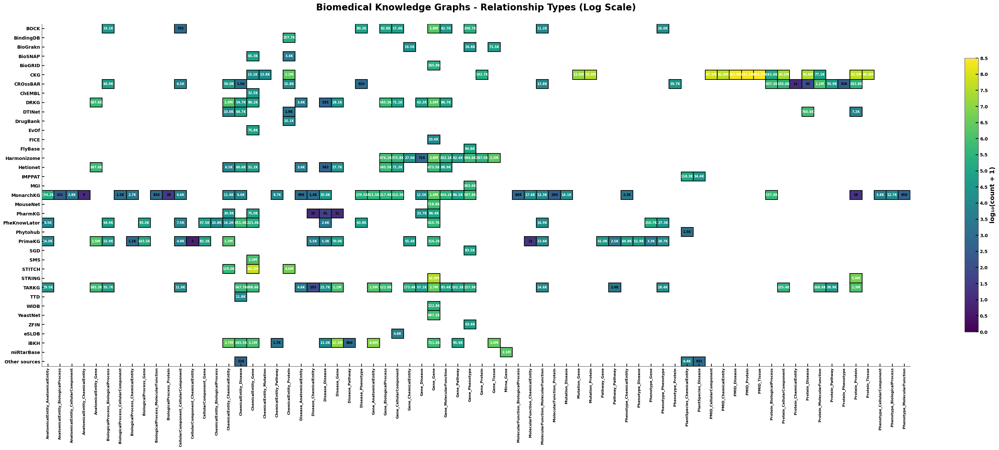


BIOMEDICAL KNOWLEDGE GRAPHS SUMMARY
Number of biomedical knowledge graphs: 37
Data sources in order: BOCK, BindingDB, BioGrakn, BioSNAP, BioGRID, CKG, CROssBAR, ChEMBL, DRKG, DTINet, DrugBank, EvOf, FICE, FlyBase, Harmonizome, Hetionet, IMPPAT, MGI, MonarchKG, MouseNet, PharmKG, PheKnowLator, Phytohub, PrimeKG, SGD, SMS, STITCH, STRING, TARKG, TTD, WIDB, YeastNet, ZFIN, eSLDB, iBKH, miRtarBase, Other sources

Number of relationship types with data: 72

Top 15 relationship types by total count:
  PMID_Tissue: 303,745,858
  PMID_Protein: 237,058,221
  PMID_Disease: 192,843,423
  PMID_CellularComponent: 87,097,962
  ChemicalEntity_Gene: 63,429,668
  Protein_Protein: 59,115,256
  Gene_Gene: 47,726,504
  PMID_ChemicalEntity: 42,795,681
  Protein_Tissue: 40,397,233
  Mutation_Protein: 32,013,911
  Protein_Disease: 31,364,775
  Protein_CellularComponent: 21,190,017
  Mutation_Gene: 13,638,515
  Disease_Gene: 13,532,033
  Gene_AnatomicalEntity: 10,732,623

Top 5 sources by total relationships

In [198]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
import matplotlib.colors as mcolors

# Read the CSV file
df = pd.read_csv('Triple_source_databases_KG.csv')

# Filter for generalised data sources only (KG_Type == 'Generalised')
generalised_df = df[df['KG_Type'] == 'Generalised'].copy()

# Define the exact order of sources from the screenshot
source_order = [
    'BOCK',
    'BindingDB',
    'BioGrakn',
    'BioSNAP',
    'Biogrid',  # Note: BioGRID in the list
    'CKG',
    'CROssBAR',
    'Chembl',   # Note: ChEMBL in the list
    'DRKG',
    'DTINet',
    'DrugBank',
    'Evolf',    # Note: EvOf in the list
    'FICE',
    'FlyBase',
    'Harmonizome',
    'Hetionet',
    'IMPPAT',
    'MGI_DO',   # Note: MGI in the list
    'MonarchKG',
    'Mouse_Net', # Note: MouseNet in the list
    'PharmKG',
    'PheKnowLator',
    'Phytohub',
    'PrimeKG',
    'SGD',
    'SMS',
    'STITCH',
    'STRING',
    'TARKG',
    'TTD',
    'Worm_Interactome_Database', # Note: WIDB in the list
    'YeastNet',
    'ZFIN',
    'eSLDB',
    'iBKH',
    'miRTarBase',  # Note: miRtarBase in the list
    'other_sources'
]

# Create a mapping for display names (to match the screenshot exactly)
display_names = {
    'BOCK': 'BOCK',
    'BindingDB': 'BindingDB',
    'BioGrakn': 'BioGrakn',
    'BioSNAP': 'BioSNAP',
    'Biogrid': 'BioGRID',
    'CKG': 'CKG',
    'CROssBAR': 'CROssBAR',
    'Chembl': 'ChEMBL',
    'DRKG': 'DRKG',
    'DTINet': 'DTINet',
    'DrugBank': 'DrugBank',
    'Evolf': 'EvOf',
    'FICE': 'FICE',
    'FlyBase': 'FlyBase',
    'Harmonizome': 'Harmonizome',
    'Hetionet': 'Hetionet',
    'IMPPAT': 'IMPPAT',
    'MGI_DO': 'MGI',
    'MonarchKG': 'MonarchKG',
    'Mouse_Net': 'MouseNet',
    'PharmKG': 'PharmKG',
    'PheKnowLator': 'PheKnowLator',
    'Phytohub': 'Phytohub',
    'PrimeKG': 'PrimeKG',
    'SGD': 'SGD',
    'SMS': 'SMS',
    'STITCH': 'STITCH',
    'STRING': 'STRING',
    'TARKG': 'TARKG',
    'TTD': 'TTD',
    'Worm_Interactome_Database': 'WIDB',
    'YeastNet': 'YeastNet',
    'ZFIN': 'ZFIN',
    'eSLDB': 'eSLDB',
    'iBKH': 'iBKH',
    'miRTarBase': 'miRtarBase',
    'other_sources': 'Other sources'
}

# Filter to only include sources that exist in the dataframe and are in our order list
available_sources = [s for s in source_order if s in generalised_df['Source'].values]
print(f"Found {len(available_sources)} sources out of {len(source_order)} specified")

# --- Dynamically detect non-data columns instead of hardcoding them ---
# 1. Any column that isn't numeric can't be a relationship-count column
#    (this automatically catches things like 'Source', 'KG_Type')
non_numeric_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

# 2. 'Total' (case-insensitive) is an aggregate column, not a relationship type
aggregate_cols = [col for col in df.columns if col.strip().lower() == 'total']

exclude_cols = set(non_numeric_cols) | set(aggregate_cols)
print(f"Auto-detected non-data columns to exclude: {sorted(exclude_cols)}")

all_columns = generalised_df.columns.tolist()
columns_to_plot = [col for col in all_columns if col not in exclude_cols]

# Filter to columns that have some data in generalised sources
# (this naturally drops any relationship-type columns that are all-zero
# for the Generalised subset, so nothing needs to be hand-listed)
valid_columns = []
for col in columns_to_plot:
    if col in generalised_df.columns and generalised_df[col].sum() > 0:
        valid_columns.append(col)

# Prepare the data matrix with the specified source order
generalised_data = generalised_df[generalised_df['Source'].isin(available_sources)][['Source'] + valid_columns].copy()
generalised_data.set_index('Source', inplace=True)

# Reindex to the specified order
generalised_data = generalised_data.reindex(available_sources)

# Replace 0 with NaN (we don't want to display zeros)
generalised_data = generalised_data.replace(0, np.nan)

# Remove columns that have no data at all
generalised_data = generalised_data.dropna(axis=1, how='all')

# Apply log10 transformation (adding small constant to avoid log(0) issues)
log_data = np.log10(generalised_data.values + 1)

# Create the plot with the specific color gradient
fig, ax = plt.subplots(figsize=(35, 14))

# Define the colormap matching the screenshot (blue to red)
cmap = plt.cm.viridis

# Create the heatmap
im = ax.imshow(log_data, cmap=cmap, aspect='auto', 
               vmin=0, vmax=np.nanmax(log_data))

# Set ticks and labels
ax.set_xticks(np.arange(len(generalised_data.columns)))
ax.set_yticks(np.arange(len(generalised_data.index)))
# Use display names for y-axis labels
y_labels = [display_names.get(source, source) for source in generalised_data.index]
ax.set_yticklabels(y_labels, fontsize=10)
ax.set_xticklabels(generalised_data.columns, rotation=90, ha='center', fontsize=8)

# Add colored boxes with borders for each cell
for i in range(len(generalised_data.index)):
    for j in range(len(generalised_data.columns)):
        value = generalised_data.iloc[i, j]
        if not pd.isna(value):
            # Add rectangle border
            rect = Rectangle((j-0.5, i-0.5), 1, 1, fill=False, edgecolor='black', linewidth=1.5)
            ax.add_patch(rect)
            
            # Format the value
            if value >= 1000000:
                text = f'{value/1000000:.1f}M'
            elif value >= 1000:
                text = f'{value/1000:.1f}K'
            else:
                text = f'{int(value)}'
            
            # Choose text color based on background
            log_val = log_data[i, j]
            if log_val > np.nanmax(log_data) * 0.4:
                color = 'white'
            else:
                color = 'black'
            ax.text(j, i, text, ha='center', va='center', color=color, fontsize=7, weight='bold')

# Add colorbar with log scale labels
cbar = plt.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('log₁₀(count + 1)', fontsize=14)

# Add legend for log values
log_ticks = np.arange(0, np.nanmax(log_data) + 0.5, 0.5)
cbar.set_ticks(log_ticks)
cbar.set_ticklabels([f'{tick:.1f}' for tick in log_ticks])

# Set title
ax.set_title('Biomedical Knowledge Graphs - Relationship Types (Log Scale)', fontsize=20, pad=30, weight='bold')

# Adjust layout
plt.tight_layout()

# Save the figure (optional)
# plt.savefig('biomedical_knowledge_graphs_heatmap_ordered.png', dpi=300, bbox_inches='tight')

plt.show()

# Print summary statistics
print("\n" + "="*80)
print("BIOMEDICAL KNOWLEDGE GRAPHS SUMMARY")
print("="*80)
print(f"Number of biomedical knowledge graphs: {len(generalised_data.index)}")
print(f"Data sources in order: {', '.join([display_names.get(s, s) for s in generalised_data.index])}")
print(f"\nNumber of relationship types with data: {len(generalised_data.columns)}")
print("\nTop 15 relationship types by total count:")
totals = generalised_data.sum(axis=0).sort_values(ascending=False)
for col, val in totals.head(15).items():
    print(f"  {col}: {int(val):,}")

print("\nTop 5 sources by total relationships:")
source_totals = generalised_data.sum(axis=1).sort_values(ascending=False)
for source, val in source_totals.head(5).items():
    display_name = display_names.get(source, source)
    print(f"  {display_name}: {int(val):,}")

# Check for missing sources
missing_sources = [s for s in source_order if s not in generalised_df['Source'].values]
if missing_sources:
    print(f"\nWarning: The following sources were not found in the data: {missing_sources}")

# Alternative: Create a version with source grouping for better readability
def create_grouped_heatmap():
    """Create a heatmap with source names grouped and color-coded"""
    
    # Create a copy of the data
    grouped_data = generalised_data.copy()
    
    # Create a figure with a different layout
    fig, ax = plt.subplots(figsize=(32, 14))
    
    # Use a slightly different colormap for better contrast
    cmap_grouped = mcolors.LinearSegmentedColormap.from_list('custom_cmap2', 
                                                             ['#053061', '#2166ac', '#4393c3', '#92c5de', 
                                                              '#d1e5f0', '#f7f7f7', '#fddbc7', '#f4a582', 
                                                              '#d6604d', '#b2182b', '#67001f'])
    
    log_data_grouped = np.log10(grouped_data.values + 1)
    im = ax.imshow(log_data_grouped, cmap=cmap_grouped, aspect='auto', 
                   vmin=0, vmax=np.nanmax(log_data_grouped))
    
    ax.set_xticks(np.arange(len(grouped_data.columns)))
    ax.set_yticks(np.arange(len(grouped_data.index)))
    y_labels = [display_names.get(source, source) for source in grouped_data.index]
    ax.set_yticklabels(y_labels, fontsize=10)
    ax.set_xticklabels(grouped_data.columns, rotation=90, ha='center', fontsize=8)
    
    # Add boxes and text
    for i in range(len(grouped_data.index)):
        for j in range(len(grouped_data.columns)):
            value = grouped_data.iloc[i, j]
            if not pd.isna(value):
                rect = Rectangle((j-0.5, i-0.5), 1, 1, fill=False, edgecolor='black', linewidth=1.2)
                ax.add_patch(rect)
                
                if value >= 1000000:
                    text = f'{value/1000000:.1f}M'
                elif value >= 1000:
                    text = f'{value/1000:.1f}K'
                else:
                    text = f'{int(value)}'
                
                log_val = log_data_grouped[i, j]
                color = 'white' if log_val > np.nanmax(log_data_grouped) * 0.4 else 'black'
                ax.text(j, i, text, ha='center', va='center', color=color, fontsize=7, weight='bold')
    
    cbar = plt.colorbar(im, ax=ax, shrink=0.8)
    cbar.set_label('log₁₀(count + 1)', fontsize=14)
    
    ax.set_title('Biomedical Knowledge Graphs - Relationship Types (Log Scale)', 
                 fontsize=20, pad=30, weight='bold')
    
    plt.tight_layout()
    plt.show()

# Uncomment to see the grouped version
# create_grouped_heatmap()

## Supp 1g


Unknown node types found:
['miRNA', 'PlantSpecies']


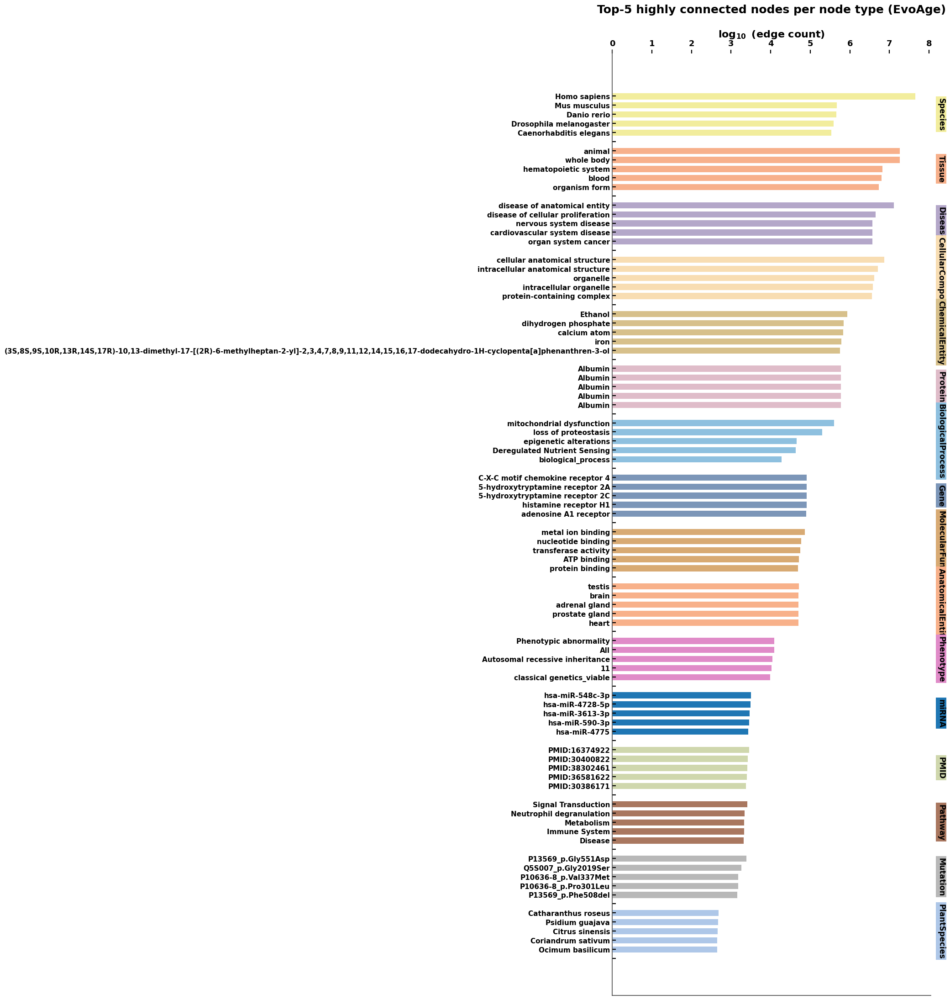

In [229]:
#!/usr/bin/env python3

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "none"
})
# ==========================================================
# Plot settings
# ==========================================================

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ==========================================================
# Read file
# ==========================================================

plot_df = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/top_10_nodeWise/EvoAge_top_5nodes_nodetype_wise.csv")

# remove accidental spaces
plot_df["EvoAge_nodeType"] = plot_df["EvoAge_nodeType"].astype(str).str.strip()

# ==========================================================
# Color palette
# ==========================================================

type_colors = {
    "AnatomicalEntity": "#f8b18a",
    "BiologicalProcess": "#8ec0df",
    "CellularComponent": "#f8ddb2",
    "ChemicalEntity": "#d7c08b",
    "Disease": "#b4a7c9",
    "Gene": "#7c96b8",
    "MolecularFunction": "#d8aa73",
    "Mutation": "#b8b8b8",
    "PMID": "#cfd7ad",
    "Pathway": "#a9775f",
    "Phenotype": "#e08bc8",
    "PlantExtract": "#c59bbd",
    "Protein": "#dfbcc9",
    "Species": "#f2ed9d",
    "Tissue": "#f7b08b",
    "Mirna": "#90d7c7",
}

# Automatically assign colors to any unknown node types
extra_colors = plt.cm.tab20(np.linspace(0, 1, 20))

missing = [
    t for t in plot_df["EvoAge_nodeType"].unique()
    if t not in type_colors
]

if missing:
    print("\nUnknown node types found:")
    print(missing)

for i, t in enumerate(missing):
    type_colors[t] = extra_colors[i]

# ==========================================================
# Prepare dataframe
# ==========================================================

plot_df["log_count"] = np.log10(plot_df["countofedge"])

# order node types by largest degree
order = (
    plot_df.groupby("EvoAge_nodeType")["countofedge"]
    .max()
    .sort_values(ascending=False)
    .index
    .tolist()
)

plot_df["EvoAge_nodeType"] = pd.Categorical(
    plot_df["EvoAge_nodeType"],
    categories=order,
    ordered=True,
)

plot_df = (
    plot_df
    .sort_values(
        ["EvoAge_nodeType", "countofedge"],
        ascending=[True, False]
    )
)

# ==========================================================
# Insert blank rows between groups
# ==========================================================

rows = []

for node_type in order:

    tmp = plot_df[
        plot_df["EvoAge_nodeType"] == node_type
    ]

    rows.append(tmp)

    # blank row for spacing
    rows.append(
        pd.DataFrame({
            "detailed_name": [""],
            "log_count": [np.nan],
            "EvoAge_nodeType": [node_type]
        })
    )

plot_df = pd.concat(rows, ignore_index=True)

# ==========================================================
# Plot
# ==========================================================

fig_height = max(12, len(plot_df) * 0.28)

fig, ax = plt.subplots(figsize=(9, fig_height))

y = np.arange(len(plot_df))

colors = plot_df["EvoAge_nodeType"].map(type_colors)

mask = plot_df["log_count"].notna()

ax.barh(
    y[mask],
    plot_df.loc[mask, "log_count"],
    color=colors[mask],
    edgecolor="white",
    linewidth=0.7,
    height=0.72,
)

# ==========================================================
# Labels
# ==========================================================

ax.set_yticks(y)
ax.set_yticklabels(
    plot_df["detailed_name"],
    fontsize=11
)

ax.invert_yaxis()

# ==========================================================
# Top axis
# ==========================================================

ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

ax.set_xlabel(
    r'$\log_{10}$ (edge count)',
    fontsize=16
)

ax.set_title(
    "Top-5 highly connected nodes per node type (EvoAge)",
    fontsize=18,
    pad=25
)

# ==========================================================
# Node type labels
# ==========================================================

for node_type in order:

    idx = plot_df.index[
        plot_df["EvoAge_nodeType"] == node_type
    ]

    idx = idx[
        plot_df.loc[idx, "log_count"].notna()
    ]

    if len(idx) == 0:
        continue

    ymid = (idx.min() + idx.max()) / 2

    ax.text(
        1.02,
        ymid,
        node_type,
        rotation=-90,
        va="center",
        ha="left",
        fontsize=12,
        transform=ax.get_yaxis_transform(),
        bbox=dict(
            facecolor=type_colors[node_type],
            edgecolor="none",
            pad=2,
        ),
    )

# ==========================================================
# Cosmetics
# ==========================================================

ax.spines["top"].set_linewidth(1.2)
ax.spines["right"].set_linewidth(1.2)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)

ax.tick_params(axis="x", labelsize=13)
ax.tick_params(axis="y", labelsize=11)

plt.tight_layout()

plt.savefig(
    "Top5_connected_nodes_per_type_EvoAge.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

## Supplementary Figure 2 a, b, c, d, e

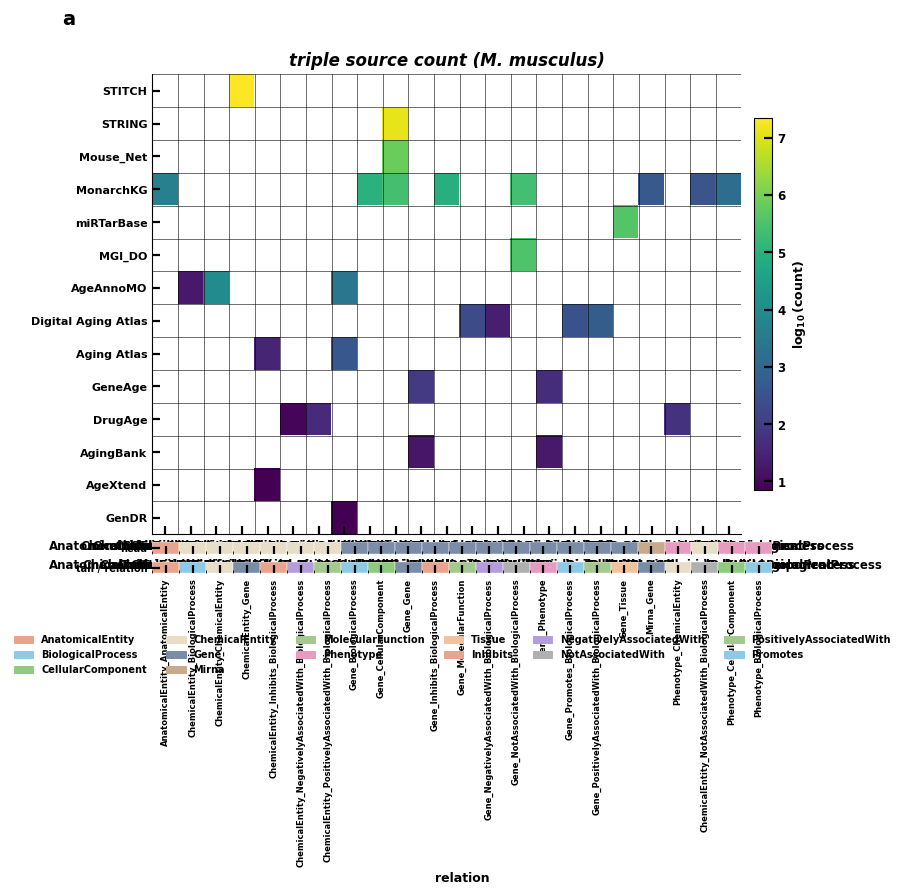

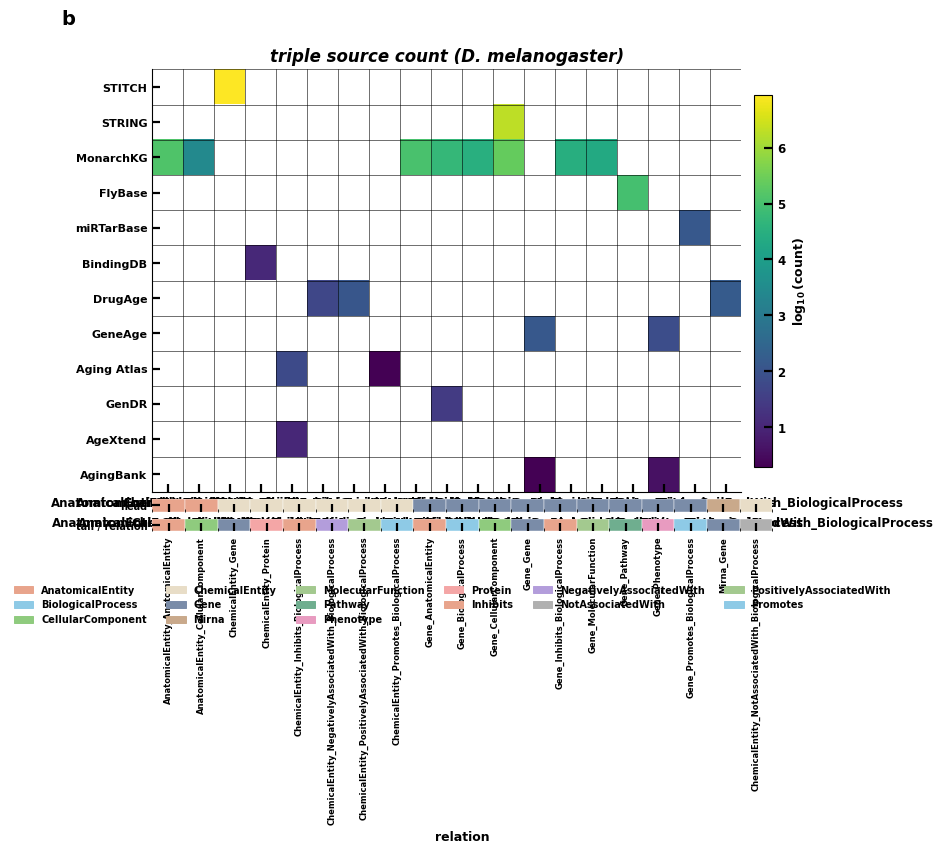

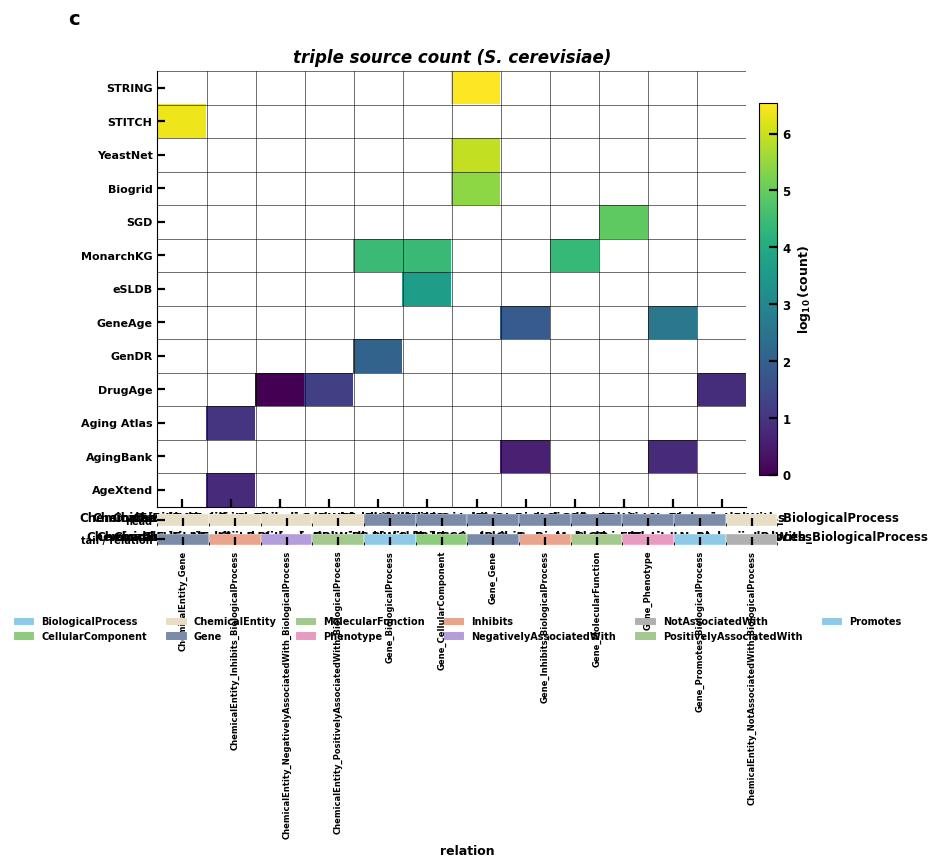

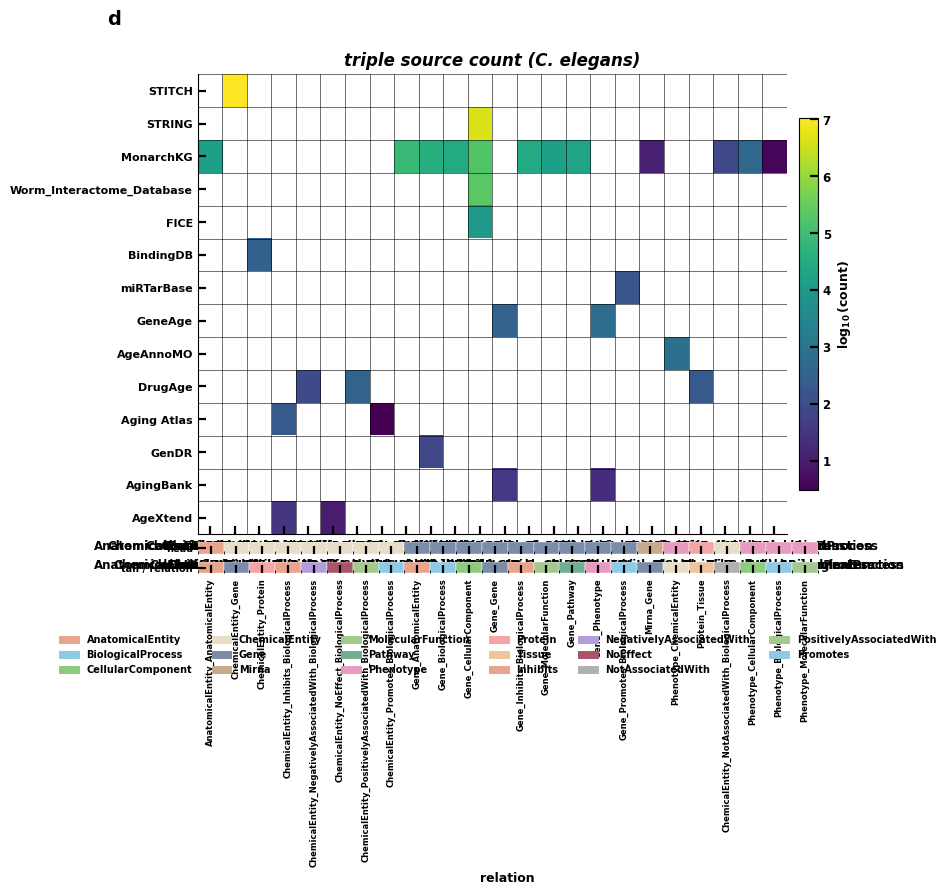

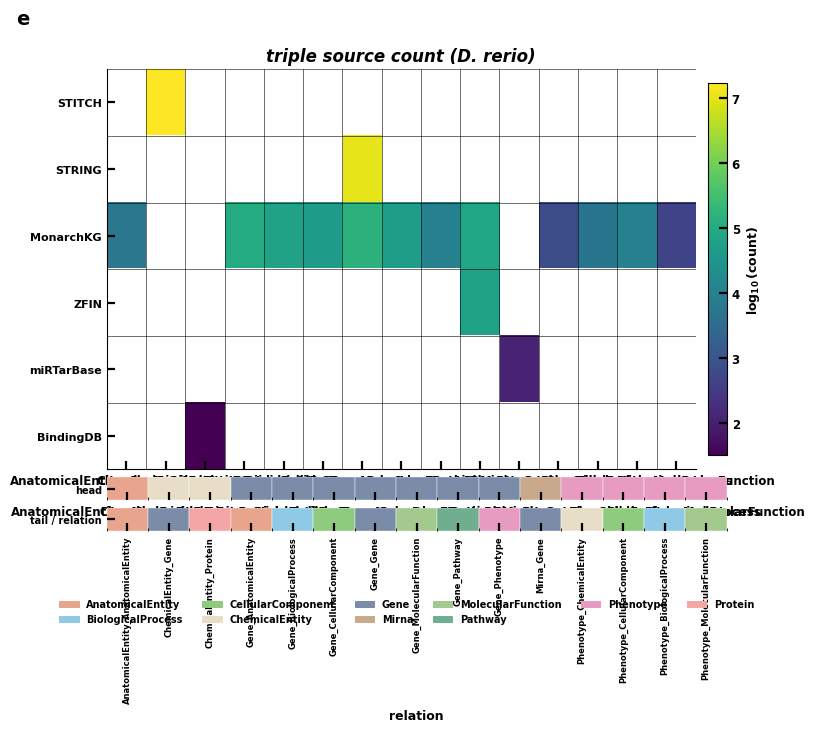

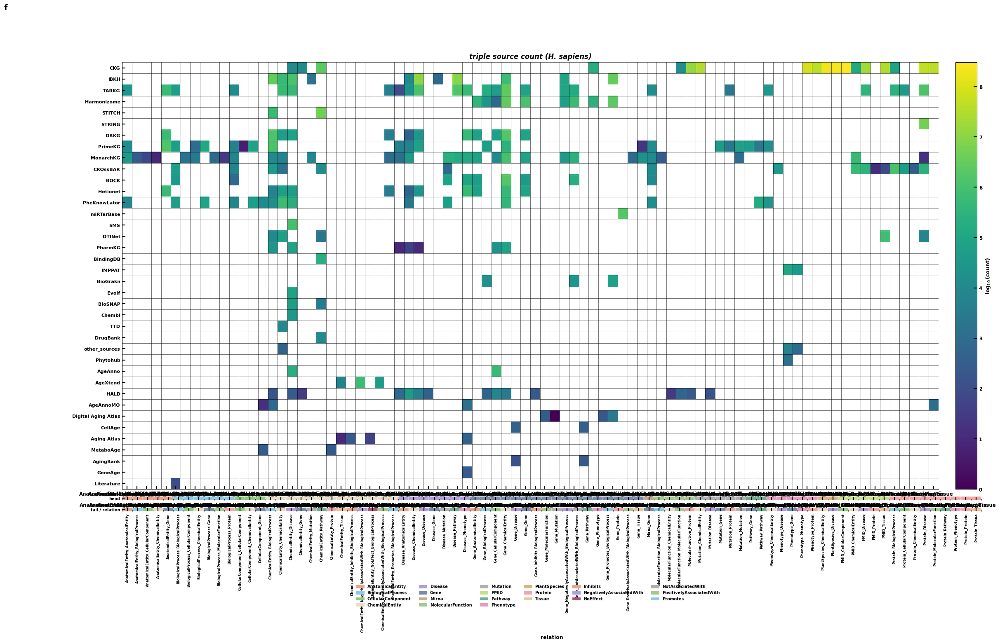

In [162]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap

# =============================================================================
# 0. CONFIG — one CSV per species, in the same wide format
#    (rows = source database, columns = HeadEntity_[Relation_]TailEntity, values = triple counts)
# =============================================================================
species_files = {
    'M. musculus':      'Mouse_only_source_databases_KG.csv',
    'D. melanogaster':  'Drosophila_only_source_databases_KG.csv',
    'S. cerevisiae':    'Yeast_only_source_databases_KG.csv',
    'C. elegans':       'Celegans_only_source_databases_KG.csv',
    'D. rerio':         'zebrafish_only_source_databases_KG.csv',
    'H. sapiens':       'Human_only_source_databases_KG.csv',
}
# ^ update these paths to your actual storage locations

NON_DATA_COLS = ['Source', 'KG_Type', 'Total']

# relation keywords that appear as the MIDDLE token in 3-part columns
# (e.g. "ChemicalEntity_Inhibits_BiologicalProcess"), or as the 2nd token
# in some 2-part columns (e.g. "Species_AssociatedWith")
RELATION_KEYWORDS = {
    'Inhibits', 'Promotes', 'NoEffect', 'NotAssociatedWith',
    'PositivelyAssociatedWith', 'NegativelyAssociatedWith', 'AssociatedWith',
}

# =============================================================================
# 1. Entity-type colour palette (head/tail annotation strip)
# =============================================================================
entity_colors = {
    'AnatomicalEntity':   '#e8a48c',
    'BiologicalProcess':  '#8ecae6',
    'CellularComponent':  '#8fcb7e',
    'ChemicalEntity':     '#e8ddc7',
    'Disease':            '#b39ddb',
    'Gene':                '#7a8ca8',
    'MolecularFunction':  '#a3c98f',
    'Mutation':           '#b0b0b0',
    'Pathway':             '#6fae8f',
    'Phenotype':           '#e89bc0',
    'Protein':              '#f4a6a6',
    'PlantSpecies':        '#d9b382',
    'Mirna':                '#c9a98b',
    'PMID':                 '#c8e08a',
    'Tissue':               '#f0c39e',
    'Species':              '#f2e3a0',
}

# relation-type colours (for 3-part / self-relation columns) -- same palette
# family used elsewhere in the project (Fig1 sunburst) for consistency
relation_colors = {
    'Inhibits':                  '#e8a48c',
    'Promotes':                  '#8ecae6',
    'NoEffect':                  '#a8546b',
    'NotAssociatedWith':         '#b0b0b0',
    'PositivelyAssociatedWith':  '#a3c98f',
    'NegativelyAssociatedWith':  '#b39ddb',
    'AssociatedWith':            '#a8546b',
}

def parse_column(col):
    """Return (head_entity, relation_or_None, tail_entity) for a triple-count column name."""
    parts = col.split('_')
    if len(parts) == 3 and parts[1] in RELATION_KEYWORDS:
        return parts[0], parts[1], parts[2]
    if len(parts) == 2 and parts[1] in RELATION_KEYWORDS:
        return parts[0], parts[1], parts[0]
    if len(parts) == 2:
        return parts[0], None, parts[1]
    # fallback: treat whole thing as a single entity self-loop
    return col, None, col

# =============================================================================
# 2. Build one heatmap per species
# =============================================================================
def plot_species_heatmap(csv_path, species_name, panel_label):
    df = pd.read_csv(csv_path)
    df = df.set_index('Source')

    data_cols = [c for c in df.columns if c not in NON_DATA_COLS]
    mat_df = df[data_cols]

    # drop columns that are all-zero for this species (no triples of that type)
    nonzero_cols = [c for c in data_cols if mat_df[c].sum() > 0]
    mat_df = mat_df[nonzero_cols]

    # drop sources with zero total across the remaining columns
    mat_df = mat_df.loc[mat_df.sum(axis=1) > 0]

    # log10(count), mask zeros as NaN so they render white (no data / no triples from that source)
    log_mat = mat_df.apply(lambda col: np.where(col > 0, np.log10(col), np.nan))
    log_mat = pd.DataFrame(log_mat, index=mat_df.index, columns=mat_df.columns)

    n_rows, n_cols = log_mat.shape

    fig = plt.figure(figsize=(max(8, n_cols * 0.32), max(4, n_rows * 0.32) + 2))
    gs = fig.add_gridspec(3, 1, height_ratios=[n_rows, 0.35, 0.35], hspace=0.05)

    ax_heat = fig.add_subplot(gs[0])
    ax_head = fig.add_subplot(gs[1], sharex=ax_heat)
    ax_tail = fig.add_subplot(gs[2], sharex=ax_heat)

    cmap = plt.cm.viridis.copy()
    cmap.set_bad('white')
    masked = np.ma.masked_invalid(log_mat.values)

    im = ax_heat.imshow(masked, cmap=cmap, aspect='auto')
    ax_heat.set_xticks([])
    ax_heat.set_yticks(range(n_rows))
    ax_heat.set_yticklabels(log_mat.index, fontsize=8)
    ax_heat.set_xticks(np.arange(-0.5, n_cols, 1), minor=True)
    ax_heat.set_yticks(np.arange(-0.5, n_rows, 1), minor=True)
    ax_heat.grid(which='minor', color='black', linewidth=0.4)
    ax_heat.tick_params(which='minor', length=0)
    ax_heat.set_title(f'triple source count ({species_name})', fontsize=12, style='italic')

    cbar = fig.colorbar(im, ax=ax_heat, fraction=0.03, pad=0.02)
    cbar.set_label(r'$\log_{10}$(count)', fontsize=9)

    # ── head/tail entity-type + relation-type annotation strips ──────────────
    parsed = [parse_column(c) for c in log_mat.columns]
    head_colors = [entity_colors.get(h, '#dddddd') for h, r, t in parsed]
    tail_colors = [relation_colors.get(r, entity_colors.get(t, '#dddddd')) for h, r, t in parsed]

    for ax, colors, label in [(ax_head, head_colors, 'head'), (ax_tail, tail_colors, 'tail / relation')]:
        for i, color in enumerate(colors):
            ax.add_patch(mpatches.Rectangle((i - 0.5, 0), 1, 1, facecolor=color, edgecolor='white', linewidth=0.3))
        ax.set_xlim(-0.5, n_cols - 0.5)
        ax.set_ylim(0, 1)
        ax.set_yticks([0.5])
        ax.set_yticklabels([label], fontsize=7)
        ax.set_xticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    ax_tail.set_xticks(range(n_cols))
    ax_tail.set_xticklabels(log_mat.columns, rotation=90, fontsize=6)
    ax_tail.set_xlabel('relation', fontsize=9)

    # ── legend: entity types + relation types actually used in this panel ────
    used_entities = sorted({h for h, r, t in parsed} | {t for h, r, t in parsed if not r})
    used_relations = sorted({r for h, r, t in parsed if r})
    legend_handles = [mpatches.Patch(color=entity_colors.get(e, '#dddddd'), label=e) for e in used_entities]
    legend_handles += [mpatches.Patch(color=relation_colors.get(r, '#dddddd'), label=r) for r in used_relations]
    fig.legend(handles=legend_handles, loc='lower center', ncol=min(6, len(legend_handles)),
               fontsize=7, bbox_to_anchor=(0.5, -0.06), frameon=False)

    fig.suptitle(panel_label, x=0.02, y=0.98, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'FIG1/Fig1_{panel_label}_{species_name.replace(". ", "_")}_source_heatmap.png',
                dpi=300, bbox_inches='tight')
    plt.savefig(f'FIG1/Fig1_{panel_label}_{species_name.replace(". ", "_")}_source_heatmap.svg',
                bbox_inches='tight')
    plt.show()


panel_labels = {
    'M. musculus': 'a', 'D. melanogaster': 'b', 'S. cerevisiae': 'c',
    'C. elegans': 'd', 'D. rerio': 'e', 'H. sapiens': 'f',
}

for species_name, path in species_files.items():
    plot_species_heatmap(path, species_name, panel_labels[species_name])

## Supplementary Figure 3

## Supp 3a

Saved.


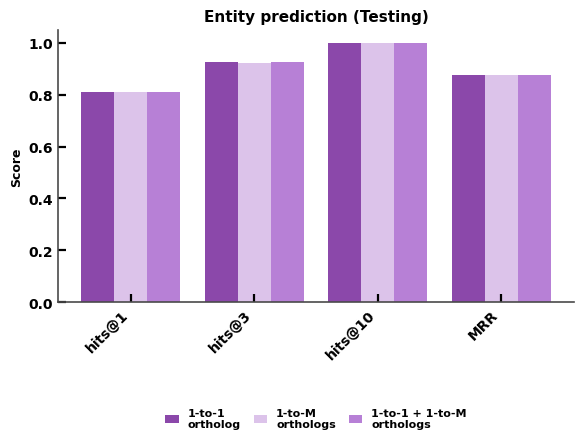

In [231]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# Editable text in Illustrator/Inkscape
mpl.rcParams['svg.fonttype'] = 'none'

# ---- Load data ----
df = pd.read_csv('Evoage_orthology_comp_Valid_test.csv')

# Keep only Testing rows
df_test = df[df['Data_Type'] == 'Testing'].copy()

# Map KG codes -> display labels (order matters for legend/bars)
kg_order = ['EvoAge_121', 'EvoAge_12M', 'EvoAge_12112M']
kg_labels = {
    'EvoAge_121': '1-to-1\northolog',
    'EvoAge_12M': '1-to-M\northologs',
    'EvoAge_12112M': '1-to-1 + 1-to-M\northologs',
}

# EvoAge purple family (light -> dark)
kg_colors = {
    'EvoAge_121': '#8b48aa',   # dark purple
    'EvoAge_12M': '#dcc3ea',   # light purple
    'EvoAge_12112M': '#b780d6', # mid purple
}

metrics = ['Hit@1', 'Hit@3', 'Hit@10', 'MRR']
metric_labels = ['hits@1', 'hits@3', 'hits@10', 'MRR']

# Build a metric x kg matrix
data = {kg: df_test.set_index('KG').loc[kg, metrics].values.astype(float) for kg in kg_order}

# ---- Plot ----
fig, ax = plt.subplots(figsize=(6, 5))

n_groups = len(metrics)
n_bars = len(kg_order)
bar_width = 0.8 / n_bars
x = np.arange(n_groups)

for i, kg in enumerate(kg_order):
    offset = (i - (n_bars - 1) / 2) * bar_width
    ax.bar(x + offset, data[kg], width=bar_width,
           color=kg_colors[kg], label=kg_labels[kg],
           edgecolor='none')

ax.set_xticks(x)
ax.set_xticklabels(metric_labels, rotation=45, ha='right')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('Entity prediction (Testing)')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.35),
          ncol=3, frameon=False, handlelength=1.2, columnspacing=1.2)

plt.tight_layout()
plt.savefig('EvoAge_Testing_EntityPrediction.svg', format='svg', bbox_inches='tight')
plt.savefig('EvoAge_Testing_EntityPrediction.png', format='png', dpi=300, bbox_inches='tight')
print("Saved.")

Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/FIG2/orthology_evoage_edgetype_comparison.svg


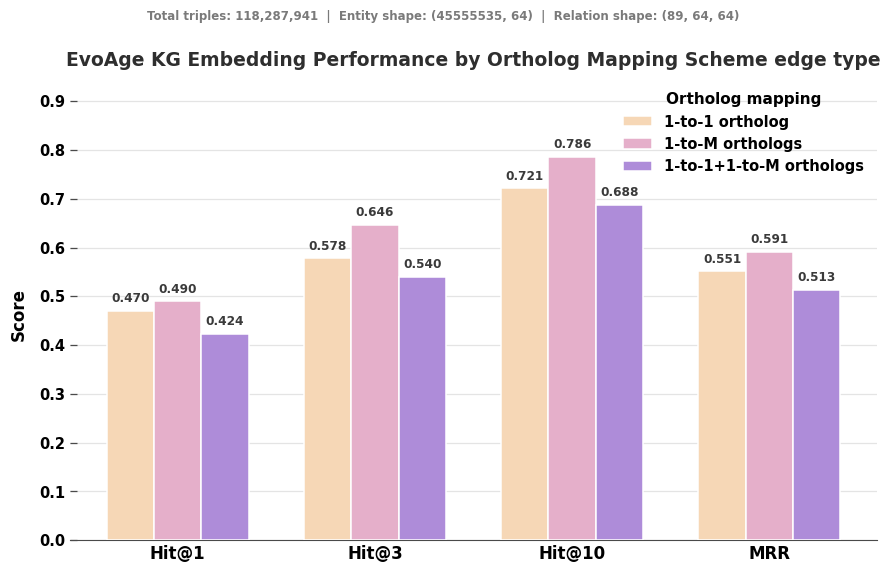

In [206]:
"""
Plot 1: Ortholog mapping scheme comparison — Edgetype / KG embedding results
Input : Evoage_orthology_comp_Edgetype.csv
Output: evoage_edgetype_comparison.svg

Simple grouped bar chart: metrics (Hit@1, Hit@3, Hit@10, MRR) on the x-axis,
grouped by ortholog mapping scheme (1:1, 1:Many, 1:1 + 1:N).
"""

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# keep text as real <text> elements in the SVG (not converted to paths)
matplotlib.rcParams['svg.fonttype'] = 'none'

# ----- COLOR GRADIENT: 5 stops, pastel purple end -----
C1 = '#F7DFB4'   # soft sand
C2 = '#F2BCBE'   # soft pink
C3 = '#DBA6D2'   # soft mauve
C4 = '#C79BE0'   # pastel violet
C5 = '#AE8CD9'   # muted purple

cmap = LinearSegmentedColormap.from_list('custom5', [
    (0.00, C1),
    (0.20, C2),
    (0.80, C3),
    (0.90, C4),
    (1.00, C5),
])

# ---------------- paths (edit if needed) ----------------
IN_CSV  = "/storage/Arushi/090526_EvoAge/kg_formation/training_3/Training_Stats/Evoage_orthology_comp_Edgetype.csv"
OUT_SVG = "/storage/Arushi/090526_EvoAge/kg_formation/all_figures/FIG2/orthology_evoage_edgetype_comparison.svg"
# ---------------- load & tidy ----------------
df = pd.read_csv(IN_CSV)
df.columns = df.columns.str.strip()  # guard against stray whitespace in headers

dataset_col_candidates = ["Dataset", "dataset", "KG", "Scheme", "Name"]
dataset_col = next((c for c in dataset_col_candidates if c in df.columns), None)
if dataset_col is None:
    raise KeyError(
        f"Could not find a dataset/scheme column. Looked for {dataset_col_candidates}. "
        f"Columns actually present in {IN_CSV}: {df.columns.tolist()}"
    )

label_map = {
    "EvoAge_1to1":     "1-to-1 ortholog",
    "EvoAge_1tomany":  "1-to-M orthologs",
    "EvoAge_121_12M":  "1-to-1+1-to-M orthologs",
}
order = ["1-to-1 ortholog", "1-to-M orthologs", "1-to-1+1-to-M orthologs"]
df["Scheme"] = df[dataset_col].map(label_map)

missing = df.loc[df["Scheme"].isna(), dataset_col].tolist()
if missing:
    raise ValueError(
        f"These values in '{dataset_col}' didn't match label_map and need to be added: {missing}"
    )

df = df.set_index("Scheme").loc[order].reset_index()

metrics = ["Hit@1", "Hit@3", "Hit@10", "MRR"]

# discrete colors sampled from the 5-stop gradient (purple-leaning)
scheme_colors = {
    "1-to-1 ortholog":        cmap(0.05),
    "1-to-M orthologs":     cmap(0.55),
    "1-to-1+1-to-M orthologs":  cmap(1.00),
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.edgecolor": "#4A4A4A",
    "axes.linewidth": 0.8,
})

fig, ax = plt.subplots(figsize=(9, 5.8))

n_groups = len(metrics)
n_bars   = len(order)
bar_w    = 0.24
x        = np.arange(n_groups)

for i, scheme in enumerate(order):
    vals = df.loc[df["Scheme"] == scheme, metrics].values.flatten()
    offset = (i - (n_bars - 1) / 2) * bar_w
    bars = ax.bar(
        x + offset, vals, width=bar_w,
        color=scheme_colors[scheme],
        edgecolor="white", linewidth=1.1,
        label=scheme, zorder=3
    )
    for rect, v in zip(bars, vals):
        ax.text(rect.get_x() + rect.get_width() / 2, v + 0.012,
                f"{v:.3f}", ha="center", va="bottom",
                fontsize=8.7, color="#3A3A3A")

# ---------------- styling ----------------
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylabel("Score", fontsize=12, labelpad=8)
ax.set_ylim(0, max(df[metrics].values.max() * 1.18, 0.9))
ax.set_yticks(np.arange(0, ax.get_ylim()[1], 0.1))
ax.tick_params(axis="y", length=5, width=0.9, color="#4A4A4A", labelsize=10.5)
ax.tick_params(axis="x", length=5, width=0.9, color="#4A4A4A")

ax.set_title(
    "EvoAge KG Embedding Performance by Ortholog Mapping Scheme edge type",
    fontsize=13.5, fontweight="bold", pad=16, color="#2E2E2E"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.yaxis.grid(True, color="#E4E4E4", linewidth=0.9, zorder=0)
ax.set_axisbelow(True)

legend = ax.legend(
    title="Ortholog mapping", loc="upper right",
    frameon=False, fontsize=10.5, title_fontsize=11,
    bbox_to_anchor=(1.0, 1.02)
)
legend.get_title().set_fontweight("bold")

footer_parts = []
if "Total_Triples" in df.columns and df["Total_Triples"].notna().any():
    total_triples = int(df["Total_Triples"].dropna().iloc[0])
    footer_parts.append(f"Total triples: {total_triples:,}")
if "Entity_Shape" in df.columns and df["Entity_Shape"].notna().any():
    footer_parts.append(f"Entity shape: {df['Entity_Shape'].dropna().iloc[0]}")
if "Relation_Shape" in df.columns and df["Relation_Shape"].notna().any():
    footer_parts.append(f"Relation shape: {df['Relation_Shape'].dropna().iloc[0]}")

if footer_parts:
    fig.text(0.5, 0.965, "  |  ".join(footer_parts),
              ha="center", fontsize=8.5, color="#7A7A7A")

plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(OUT_SVG, format="svg", bbox_inches="tight", transparent=True)
print(f"Saved: {OUT_SVG}")

## Supp 3b

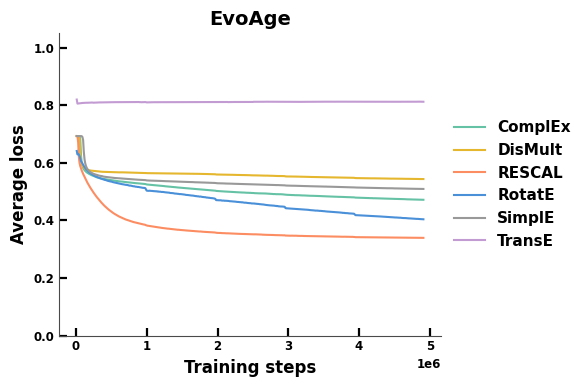

In [175]:
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
Aging_all_loss  = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/Training_Stats/Aging_121_12M_64Emb_loss.csv')
EvoAge_all_loss = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/Training_Stats/EvoAge_121_12M_64Emb_loss.csv')

# ----------------------------------------------------------------------
# 2. Column -> display name mapping (order matches legend in reference figure)
# ----------------------------------------------------------------------
col_to_model = {
    'Complex_Avloss': 'ComplEx',
    'Dismult_Avloss': 'DisMult',
    'Rescal_Avloss':  'RESCAL',
    'RotatE_Avloss':  'RotatE',
    'Simple_Avloss':  'SimplE',
    'TransE_Avloss':  'TransE',
}
model_order = ['ComplEx', 'DisMult', 'RESCAL', 'RotatE', 'SimplE', 'TransE']

# same palette as used in the heatmap/bar figures — kept consistent per model
model_colors = {
    'ComplEx': '#66C2A5',  # teal-green
    'DisMult': '#E5B72F',  # mustard/gold
    'RESCAL':  '#FC8D62',  # coral/red-orange
    'RotatE':  '#4A90D9',  # blue
    'SimplE':  '#999999',  # gray
    'TransE':  '#C39BD3',  # lavender/purple
}

# ----------------------------------------------------------------------
# 3. FIGURE — only EvoAge loss curves (Aging removed)
# ----------------------------------------------------------------------
fig, ax = plt.subplots(1, 1, figsize=(6, 4))  # Single panel

# Plot only EvoAge data
for col, model in col_to_model.items():
    ax.plot(EvoAge_all_loss['Step'], EvoAge_all_loss[col],
            color=model_colors[model], label=model, linewidth=1.5)

ax.set_title('EvoAge', fontsize=14)
ax.set_xlabel('Training steps', fontsize=12)
ax.set_ylabel('Average loss', fontsize=12)
ax.set_ylim(0, 1.05)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# legend on the right, ordered same as model_order, colors matching each line
handles, labels = ax.get_legend_handles_labels()
label_to_handle = dict(zip(labels, handles))
ordered_handles = [label_to_handle[m] for m in model_order]
ax.legend(ordered_handles, model_order, loc='center left',
          bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=11)

# Removed the suptitle with 'd' label
plt.tight_layout()
plt.savefig('FIG2/Fig2d_lossplot.pdf', dpi=300, bbox_inches='tight')
plt.show()

## Supp 3c

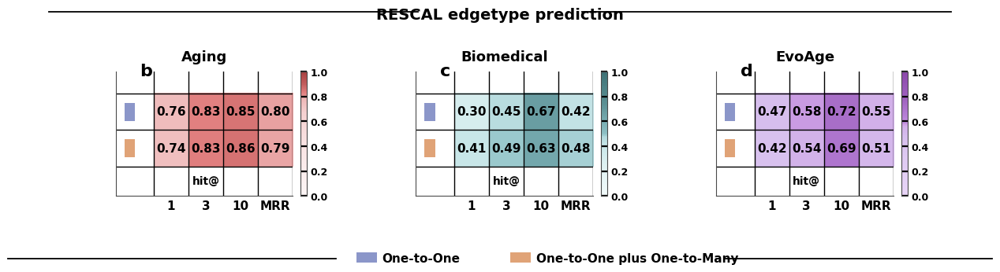

done


In [176]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
EvoAge_Aging_biomed_edgeType = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/Training_Stats/RESCAL_all_KGtype_edgetype_results.csv')

df = EvoAge_Aging_biomed_edgeType.copy()

def get_category(name):
    if name.startswith('Aging'):
        return 'Aging'
    elif name.startswith('Biomedical'):
        return 'Biomedical'
    elif name.startswith('EvoAge'):
        return 'EvoAge'

def get_ortholog_type(name):
    return '1:1' if '1to1' in name else '1:N'

df['Category'] = df['Dataset'].apply(get_category)
df['OrthologType'] = df['Dataset'].apply(get_ortholog_type)
cols = ['Hit@1', 'Hit@3', 'Hit@10', 'MRR']
row_order = ['1:1', '1:N']

# ----------------------------------------------------------------------
# 2. Hex palettes -- FULL 5-stop gradient per panel, but concentrated
#    into that panel's own narrow data range while the colourbar axis
#    stays fixed 0.0-1.0 (matches your original legend style).
# ----------------------------------------------------------------------
panels = {
    "Aging":      ["#fdf6f6", "#f5d0d0", "#e8a0a0", "#e17f7f", "#a83f3f"],
    "Biomedical": ["#f2fafa", "#c8e6e8", "#9ccbcf", "#7fb3b8", "#3d7175"],
    "EvoAge":     ["#e8d5f7", "#d6beed", "#cea1e5", "#b67fd6", "#8b48aa"],
}
panel_titles = {'Aging': 'Aging', 'Biomedical': 'Biomedical', 'EvoAge': 'EvoAge'}
panel_letters = {'Aging': 'b', 'Biomedical': 'c', 'EvoAge': 'd'}
row_swatch_colors = ['#8b96c9', '#e0a377']  # blue = 1:1, orange = 1:1+1:N

def _hex_to_rgb(h):
    h = h.lstrip('#')
    return tuple(int(h[i:i + 2], 16) for i in (0, 2, 4))

def _rgb_to_hex(rgb):
    return '#%02x%02x%02x' % tuple(int(round(max(0, min(255, v)))) for v in rgb)

def _interp_hex(c1, c2, t):
    r1, g1, b1 = _hex_to_rgb(c1)
    r2, g2, b2 = _hex_to_rgb(c2)
    return _rgb_to_hex((r1 + (r2 - r1) * t, g1 + (g2 - g1) * t, b1 + (b2 - b1) * t))

def expand_palette(colors):
    """Add an in-between shade of the same hue family between every
    consecutive pair, so we have finer, more diverse steps to work with
    (e.g. 5 colours -> 9 colours), all still clearly 'family members' of
    the originals."""
    expanded = [colors[0]]
    for i in range(len(colors) - 1):
        expanded.append(_interp_hex(colors[i], colors[i + 1], 0.5))
        expanded.append(colors[i + 1])
    return expanded

def build_concentrated_cmap(vmin_data, vmax_data, colors, name, power=2.6):
    """
    Smooth, fully continuous colormap across 0.0-1.0 (no flat/white
    dead-zone anywhere -- legend still reads as one uniform gradient).
    The extra colour stops (from expand_palette) are packed more densely
    around this panel's own data midpoint using a cubic-style warp, and
    spread out more sparsely toward the tails where there's no data.
    That concentrates visible colour change exactly where the real
    values sit, without ever going flat.
    """
    mid = (vmin_data + vmax_data) / 2.0
    n = len(colors)
    ts = np.linspace(-1.0, 1.0, n)
    positions = []
    for t in ts:
        if t <= 0:
            frac = (abs(t)) ** power
            pos = mid - frac * mid
        else:
            frac = t ** power
            pos = mid + frac * (1.0 - mid)
        positions.append(pos)

    stops = list(zip(positions, colors))
    cleaned = []
    last_pos = -1.0
    for pos, color in stops:
        pos = round(float(pos), 6)
        if pos <= last_pos:
            pos = last_pos + 1e-6
        cleaned.append((min(pos, 1.0), color))
        last_pos = pos
    if cleaned[0][0] > 0.0:
        cleaned.insert(0, (0.0, colors[0]))
    if cleaned[-1][0] < 1.0:
        cleaned.append((1.0, colors[-1]))
    return LinearSegmentedColormap.from_list(name, cleaned)

# ----------------------------------------------------------------------
# 3. Build one combined figure with 3 panels
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
plt.subplots_adjust(wspace=0.55, top=0.72, bottom=0.28)

for ax, category in zip(axes, ['Aging', 'Biomedical', 'EvoAge']):
    sub = df[df['Category'] == category].set_index('OrthologType').loc[row_order]
    mat = sub[cols].values.astype(float)

    expanded_colors = expand_palette(panels[category])
    cmap = build_concentrated_cmap(mat.min(), mat.max(), expanded_colors, f'{category}_concentrated')
    im = ax.imshow(mat, cmap=cmap, vmin=0.0, vmax=1.0, aspect='auto')

    for r in range(mat.shape[0]):
        for c in range(mat.shape[1]):
            ax.text(c, r, f'{mat[r, c]:.2f}', ha='center', va='center', fontsize=11)

    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(['1', '3', '10', 'MRR'], fontsize=11)
    ax.set_yticks([])
    ax.tick_params(length=0)

    ax.set_xticks(np.arange(-0.5, len(cols), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(row_order), 1), minor=True)
    ax.grid(which='minor', color='black', linewidth=1)
    ax.tick_params(which='minor', length=0)

    ax.set_title(panel_titles[category], fontsize=13, pad=10)

    # panel letter, top-left of panel
    ax.text(-0.9, -0.9, panel_letters[category], fontsize=16, fontweight='bold',
            ha='left', va='bottom', transform=ax.transData, clip_on=False)

    # row swatches to the left of the heatmap (1:1 blue, 1:1+1:N orange)
    for i, rc in enumerate(row_swatch_colors):
        rect = Rectangle((-1.35, i - 0.25), 0.3, 0.5, transform=ax.transData,
                          facecolor=rc, edgecolor='none', clip_on=False)
        ax.add_patch(rect)

    # "hit@" underline below x tick labels
    ax.annotate('', xy=(-0.4, 1.9), xytext=(2.4, 1.9),
                xycoords=('data', 'axes fraction'), textcoords=('data', 'axes fraction'),
                arrowprops=dict(arrowstyle='-', color='black', lw=1.2),
                annotation_clip=False)
    ax.text(1.0, 2.05, 'hit@', ha='center', va='bottom', fontsize=10,
            transform=ax.transData)

    # colorbar fixed 0.0 - 1.0
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    cbar.ax.tick_params(labelsize=9)

    ax.set_xlim(-1.6, 3.5)
    ax.set_ylim(2.3, -1.1)

# top overall title with flanking lines
fig.text(0.5, 0.92, 'RESCAL edgetype prediction', ha='center', va='center',
          fontsize=14, fontweight='bold')
fig.add_artist(Line2D([0.06, 0.42], [0.93, 0.93], color='black', lw=1.3, transform=fig.transFigure))
fig.add_artist(Line2D([0.58, 0.94], [0.93, 0.93], color='black', lw=1.3, transform=fig.transFigure))

# bottom legend: One-to-One / One-to-One plus One-to-Many
legend_y = 0.06
fig.add_artist(Rectangle((0.36, legend_y - 0.015), 0.02, 0.035, transform=fig.transFigure,
                          facecolor=row_swatch_colors[0], edgecolor='none'))
fig.text(0.385, legend_y, 'One-to-One', ha='left', va='center', fontsize=11)
fig.add_artist(Rectangle((0.51, legend_y - 0.015), 0.02, 0.035, transform=fig.transFigure,
                          facecolor=row_swatch_colors[1], edgecolor='none'))
fig.text(0.535, legend_y, 'One-to-One plus One-to-Many', ha='left', va='center', fontsize=11)

fig.add_artist(Line2D([0.02, 0.34], [legend_y, legend_y], color='black', lw=1.3, transform=fig.transFigure))
fig.add_artist(Line2D([0.72, 0.98], [legend_y, legend_y], color='black', lw=1.3, transform=fig.transFigure))

plt.savefig('FIG2/Fig2_bcd_RESCAL_combined.svg', dpi=300, bbox_inches='tight')
plt.savefig('FIG2/Fig2_bcd_RESCAL_combined.png', dpi=300, bbox_inches='tight')
plt.show()

print("done")

## Supp 3d

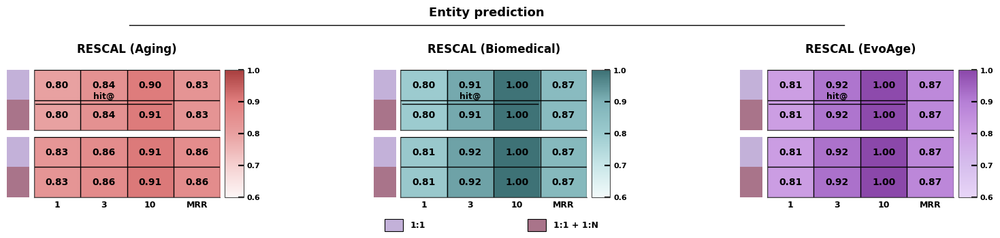

In [179]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle

# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
EvoAge_Aging_biomed = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/Training_Stats/EA_A_B_Rescal_selected_metrics.csv')

# ----------------------------------------------------------------------
# 2. Clean up labels
# ----------------------------------------------------------------------
df = EvoAge_Aging_biomed.copy()
ortholog_label = {'1-to-1': '1:1', '121_12M': '1:1 + 1:N'}
df['OrthologLabel'] = df['Ortholog'].map(ortholog_label).fillna(df['Ortholog'])
df['Split'] = df['Split'].str.strip().str.title()  # Validation / Testing

metrics = ['Hit@1', 'Hit@3', 'Hit@10', 'MRR']
metric_ticklabels = ['1', '3', '10', 'MRR']
ortholog_order = ['1:1', '1:1 + 1:N']       # rows, top -> bottom
split_order = ['Validation', 'Testing']     # stacked blocks, top -> bottom

# ----------------------------------------------------------------------
# 3. Colour schemes
# ----------------------------------------------------------------------
panels = {
    "Aging":      ["#fdf6f6", "#f5d0d0", "#e8a0a0", "#e17f7f", "#a83f3f"],
    "Biomedical": ["#f2fafa", "#c8e6e8", "#9ccbcf", "#7fb3b8", "#3d7175"],
    "EvoAge":     ["#e8d5f7", "#d6beed", "#cea1e5", "#b67fd6", "#8b48aa"],
}
kg_cmaps = {kg: LinearSegmentedColormap.from_list(f'{kg}_cmap', cols) for kg, cols in panels.items()}
kg_titles = {'Aging': 'RESCAL (Aging)', 'Biomedical': 'RESCAL (Biomedical)', 'EvoAge': 'RESCAL (EvoAge)'}
kg_order = ['Aging', 'Biomedical', 'EvoAge']

# fixed legend-square colours for the two ortholog-mapping rows (same across all 3 panels)
row_square_colors = {'1:1': '#c3b1d9', '1:1 + 1:N': '#a9748a'}
row_square_cmap = ListedColormap([row_square_colors[o] for o in ortholog_order])

VMIN, VMAX = 0.6, 1.0

# ----------------------------------------------------------------------
# 4. Helper: build a KG's 2 (split) x 2 (ortholog) x 4 (metric) matrix
# ----------------------------------------------------------------------
def get_matrix(kg, split):
    sub = df[(df['KG'] == kg) & (df['Split'] == split)]
    mat = np.full((len(ortholog_order), len(metrics)), np.nan)
    for r, ortho in enumerate(ortholog_order):
        row = sub[sub['OrthologLabel'] == ortho]
        if not row.empty:
            for c, m in enumerate(metrics):
                mat[r, c] = row[m].values[0]
    return mat

# ----------------------------------------------------------------------
# 5. Figure layout: 1 outer row x 3 KG panels
#    Each KG panel: 2 stacked (Validation/Testing) heatmaps, a thin row-colour
#    strip on the left of each, and one shared colourbar per panel on the right.
# ----------------------------------------------------------------------
fig = plt.figure(figsize=(15, 3.6))
gs_outer = GridSpec(1, 3, figure=fig, wspace=0.55, left=0.03, right=0.98, top=0.72, bottom=0.20)

for i, kg in enumerate(kg_order):
    gs_kg = gs_outer[i].subgridspec(
        2, 3, width_ratios=[0.12, 1, 0.10], height_ratios=[1, 1],
        hspace=0.12, wspace=0.06
    )
    cmap = kg_cmaps[kg]
    axes_heat = []

    for r_block, split in enumerate(split_order):
        ax_sq = fig.add_subplot(gs_kg[r_block, 0])
        ax_hm = fig.add_subplot(gs_kg[r_block, 1])
        axes_heat.append(ax_hm)

        mat = get_matrix(kg, split)
        im = ax_hm.imshow(mat, cmap=cmap, vmin=VMIN, vmax=VMAX, aspect='auto')

        # annotate values
        for rr in range(mat.shape[0]):
            for cc in range(mat.shape[1]):
                val = mat[rr, cc]
                if not np.isnan(val):
                    ax_hm.text(cc, rr, f'{val:.2f}', ha='center', va='center', fontsize=10)

        # gridlines between cells
        ax_hm.set_xticks(np.arange(-0.5, len(metrics), 1), minor=True)
        ax_hm.set_yticks(np.arange(-0.5, len(ortholog_order), 1), minor=True)
        ax_hm.grid(which='minor', color='black', linewidth=1)
        ax_hm.tick_params(which='minor', length=0)
        ax_hm.set_yticks([])
        ax_hm.set_xticks([])

        # metric labels only under bottom (Testing) block
        if split == split_order[-1]:
            ax_hm.set_xticks(range(len(metrics)))
            ax_hm.set_xticklabels(metric_ticklabels, fontsize=9)
            ax_hm.tick_params(axis='x', length=0)
            # "hit@" underbrace, centred under Hit@1/3/10 (first 3 cols)
            ax_hm.annotate('', xy=(-0.5, 1.55), xytext=(2.5, 1.55),
                            xycoords=('data', 'axes fraction'),
                            arrowprops=dict(arrowstyle='-', color='black', lw=1))
            ax_hm.text(1.0, 1.75, 'hit@', ha='center', va='top',
                       transform=ax_hm.get_xaxis_transform(), fontsize=9)

        # Validation / Testing label to the right of the heatmap
        ax_hm.text(len(metrics) - 0.3, (len(ortholog_order) - 1) / 2, split,
                   rotation=-90, va='center', ha='left', fontsize=9, clip_on=False)

        # row-colour squares (ortholog type) to the left
        ax_sq.imshow(np.arange(len(ortholog_order)).reshape(-1, 1),
                     cmap=row_square_cmap, aspect='auto',
                     vmin=0, vmax=len(ortholog_order) - 1)
        ax_sq.set_xticks([])
        ax_sq.set_yticks([])
        for spine in ax_sq.spines.values():
            spine.set_visible(False)

    # shared colourbar spanning both blocks
    ax_cbar = fig.add_subplot(gs_kg[:, 2])
    cbar = fig.colorbar(im, cax=ax_cbar)
    cbar.set_ticks([0.6, 0.7, 0.8, 0.9, 1.0])
    cbar.ax.tick_params(labelsize=8)

    # panel title
    top_pos = axes_heat[0].get_position()
    fig.text((top_pos.x0 + top_pos.x1) / 2, top_pos.y1 + 0.06, kg_titles[kg],
             ha='center', va='bottom', fontsize=12)

# ----------------------------------------------------------------------
# 6. Overall title + bottom legend
# ----------------------------------------------------------------------
fig.text(0.5, 0.93, 'Entity prediction', ha='center', va='bottom', fontsize=13)
fig.add_artist(plt.Line2D([0.15, 0.85], [0.905, 0.905], transform=fig.transFigure,
                           color='black', linewidth=1))

# Removed the "e" label from here

legend_y = 0.06
legend_x = 0.5
for j, ortho in enumerate(ortholog_order):
    x = legend_x - 0.10 + j * 0.14
    fig.patches.append(Rectangle((x, legend_y), 0.018, 0.05,
                                  transform=fig.transFigure,
                                  facecolor=row_square_colors[ortho],
                                  edgecolor='black', linewidth=0.8))
    fig.text(x + 0.025, legend_y + 0.025, ortho, va='center', ha='left', fontsize=9)

plt.savefig('FIG2/Fig_link_prediction_horizontal.svg', dpi=300, bbox_inches='tight')
plt.show()

## Supp 3e

Saved: RESCAL_triple_classification_heatmap.svg RESCAL_triple_classification_heatmap.png


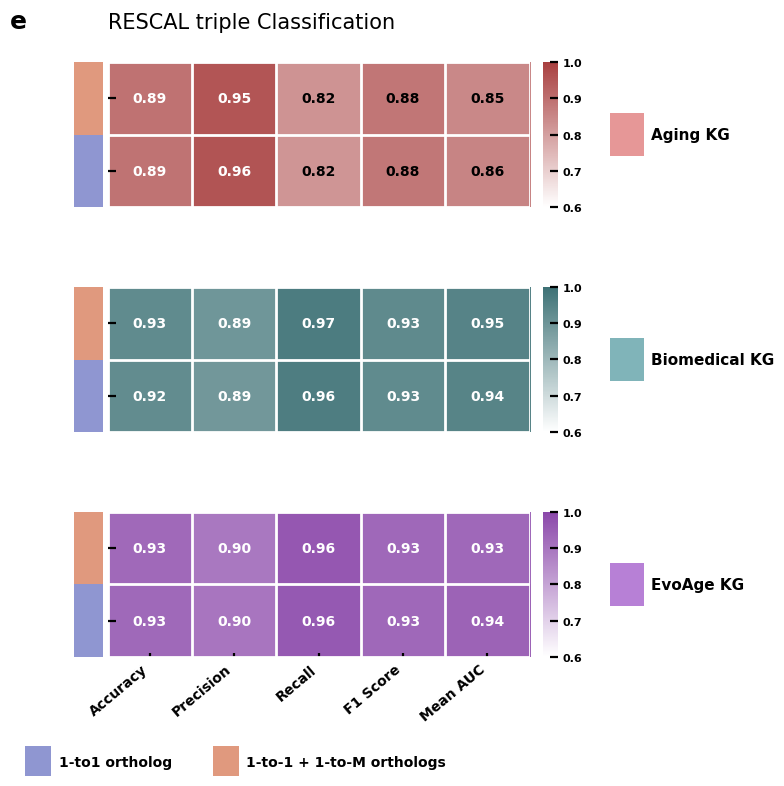

In [180]:
"""
RESCAL Triple Classification heatmap — Aging / Biomedical / EvoAge KGs
Two rows per block: 1-to-1 orthologs vs 1-to-1 + 1-to-Many orthologs
Recreates the style of the uploaded reference screenshot.
"""

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
import pandas as pd
import numpy as np

# Editable text in SVG (Illustrator/Inkscape friendly)
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']

# ---------------------------------------------------------------
# 1. Load & reshape data
# ---------------------------------------------------------------
df = pd.read_csv('combined_classification_accuracy_R4.csv')

metrics = ['Accuracy', 'Precision', 'Recall', 'F1_Score', 'Mean_AUC']

def parse_graph(g):
    if g.endswith('_12M'):
        kg = g[:-len('_121_12M')]
        ortholog = '1-to-1 + 1-to-M'
    else:
        kg = g[:-len('_121')]
        ortholog = '1-to-1'
    return kg, ortholog

df[['KG', 'Ortholog']] = df['Graph'].apply(lambda g: pd.Series(parse_graph(g)))

kg_order = ['Aging', 'Biomedical', 'EvoAge']
ortholog_order = ['1-to-1 + 1-to-M', '1-to-1']  # top row = combined, bottom row = 1:1 (matches reference image)

# ---------------------------------------------------------------
# 2. Color conventions (established EvoAge project palette)
# ---------------------------------------------------------------
kg_colors = {
    'Aging':      {'light': '#ffffff', 'dark': '#a83f3f', 'mid': '#e69797'},
    'Biomedical': {'light': '#ffffff', 'dark': '#3d7175', 'mid': '#80b4b9'},
    'EvoAge':     {'light': '#ffffff', 'dark': '#8b48aa', 'mid': '#b780d6'},
}

# ortholog row-label swatch colors (matches reference: salmon = combined, blue-purple = 1:1)
ortholog_label_colors = {
    '1-to-1 + 1-to-M': '#e0997e',
    '1-to-1':          '#8f96d1',
}

# ---------------------------------------------------------------
# 3. Figure layout
# ---------------------------------------------------------------
n_kg = len(kg_order)
n_rows_per_block = len(ortholog_order)
n_cols = len(metrics)

fig = plt.figure(figsize=(7.5, 8.5))

# gridspec: one row per KG block (heatmap + its own colorbar), plus spacing
gs = fig.add_gridspec(
    n_kg, 2,
    width_ratios=[1, 0.035],
    height_ratios=[1, 1, 1],
    hspace=0.55, wspace=0.06,
    left=0.16, right=0.76, top=0.90, bottom=0.20
)

vmin, vmax = 0.6, 1.0
kg_labels_map = {'Aging': 'Aging KG', 'Biomedical': 'Biomedical KG', 'EvoAge': 'EvoAge KG'}

for i, kg in enumerate(kg_order):
    ax = fig.add_subplot(gs[i, 0])
    cax = fig.add_subplot(gs[i, 1])

    sub = df[df['KG'] == kg].set_index('Ortholog').loc[ortholog_order, metrics]
    data = sub.values.astype(float)

    cmap = LinearSegmentedColormap.from_list(
        f'{kg}_cmap', [kg_colors[kg]['light'], kg_colors[kg]['dark']]
    )

    im = ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')

    # annotate cell values
    for r in range(data.shape[0]):
        for c in range(data.shape[1]):
            val = data[r, c]
            # choose text color for contrast
            norm_val = (val - vmin) / (vmax - vmin)
            txt_color = 'white' if norm_val > 0.72 else 'black'
            ax.text(c, r, f'{val:.2f}', ha='center', va='center',
                     fontsize=10, color=txt_color)

    # gridlines between cells
    ax.set_xticks(np.arange(-0.5, n_cols, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_rows_per_block, 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='minor', bottom=False, left=False)

    # column labels only on bottom-most block
    ax.set_xticks(range(n_cols))
    if i == n_kg - 1:
        labels = [m.replace('_', ' ') for m in metrics]
        ax.set_xticklabels(labels, rotation=40, ha='right', fontsize=10)
        ax.tick_params(axis='x', length=3)
    else:
        ax.set_xticklabels([])
        ax.tick_params(axis='x', length=0)

    # y row labels: colored swatches instead of text, like reference
    ax.set_yticks(range(n_rows_per_block))
    ax.set_yticklabels([])
    ax.set_ylim(n_rows_per_block - 0.5, -0.5)

    for spine in ax.spines.values():
        spine.set_visible(False)

    # add small colored swatch to the left of each row
    for r, ortho in enumerate(ortholog_order):
        swatch = Rectangle((-0.9, r - 0.5), 0.35, 1.0,
                             transform=ax.transData,
                             clip_on=False,
                             facecolor=ortholog_label_colors[ortho],
                             edgecolor='none')
        ax.add_patch(swatch)
    ax.set_xlim(-0.5, n_cols - 0.5)

    # colorbar for this block
    cb = fig.colorbar(im, cax=cax)
    cb.set_ticks([0.6, 0.7, 0.8, 0.9, 1.0])
    cb.ax.tick_params(labelsize=8)
    cb.outline.set_visible(False)

    # KG legend swatch, vertically centered on this block, placed right of colorbar
    pos = ax.get_position()
    y_center = (pos.y0 + pos.y1) / 2
    sw_h = 0.05
    fig.patches.append(Rectangle((0.83, y_center - sw_h / 2), 0.045, sw_h,
                                   transform=fig.transFigure,
                                   facecolor=kg_colors[kg]['mid'],
                                   edgecolor='none'))
    fig.text(0.885, y_center, kg_labels_map[kg], fontsize=11, va='center')

# ---------------------------------------------------------------
# 4. Title
# ---------------------------------------------------------------
fig.text(0.16, 0.94, 'RESCAL triple Classification', fontsize=15, fontweight='normal')
fig.text(0.03, 0.94, 'e', fontsize=18, fontweight='bold')

# ortholog type legend (bottom, like reference image)
legend_y = 0.06
fig.patches.append(Rectangle((0.05, legend_y), 0.035, 0.035,
                               transform=fig.transFigure,
                               facecolor=ortholog_label_colors['1-to-1'],
                               edgecolor='none'))
fig.text(0.095, legend_y + 0.017, '1-to1 ortholog', fontsize=10, va='center')

fig.patches.append(Rectangle((0.30, legend_y), 0.035, 0.035,
                               transform=fig.transFigure,
                               facecolor=ortholog_label_colors['1-to-1 + 1-to-M'],
                               edgecolor='none'))
fig.text(0.345, legend_y + 0.017, '1-to-1 + 1-to-M orthologs', fontsize=10, va='center')

# ---------------------------------------------------------------
# 6. Save
# ---------------------------------------------------------------
out_svg = 'RESCAL_triple_classification_heatmap.svg'
out_png = 'RESCAL_triple_classification_heatmap.png'
fig.savefig(out_svg, format='svg', bbox_inches=None)
fig.savefig(out_png, format='png', dpi=300, bbox_inches=None)
print('Saved:', out_svg, out_png)

## Supp 3f,g,h

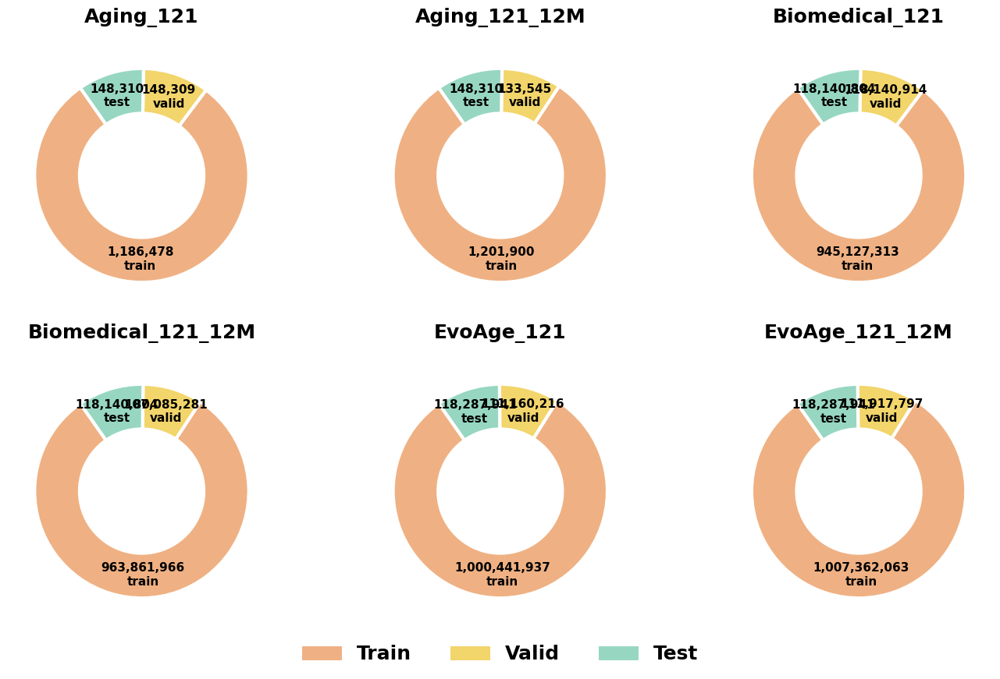

In [232]:
#!/usr/bin/env python3

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# -------------------------------------------------------
# Data
# -------------------------------------------------------

df = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/training_3/Training_Stats/All_KG_split_summary.csv')

# -------------------------------------------------------
# Plot settings
# -------------------------------------------------------

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

colors = [
    "#efb183",   # Train
    "#f2d56b",   # Valid
    "#97d7c2"    # Test
]

labels = ["train", "valid", "test"]

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

axes = axes.flatten()

# -------------------------------------------------------
# Draw donuts
# -------------------------------------------------------

for ax, (_, row) in zip(axes, df.iterrows()):

    values = [row["Train"], row["Valid"], row["Test"]]

    wedges, _ = ax.pie(
        values,
        startangle=125,
        colors=colors,
        counterclock=True,
        wedgeprops=dict(width=0.42,
                        edgecolor="white",
                        linewidth=3)
    )

    # Labels inside wedges
    for w, value, name in zip(wedges, values, labels):

        angle = (w.theta1 + w.theta2) / 2

        r = 0.78

        x = r * np.cos(np.deg2rad(angle))
        y = r * np.sin(np.deg2rad(angle))

        ax.text(
            x,
            y,
            f"{value:,}\n{name}",
            ha="center",
            va="center",
            fontsize=11
        )

    ax.set_title(
        row["KG"],
        fontsize=18,
        fontweight="bold",
        pad=18
    )

    ax.set_aspect("equal")

# -------------------------------------------------------
# Legend
# -------------------------------------------------------

handles = [
    plt.Rectangle((0, 0), 1, 1, color=c)
    for c in colors
]

fig.legend(
    handles,
    ["Train", "Valid", "Test"],
    loc="lower center",
    ncol=3,
    fontsize=18,
    frameon=False,
    bbox_to_anchor=(0.5, 0.02)
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    "FIG2/Fig2_supp_d_KG_split_donut_plots.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

## Supplementary Figure 4 a,b,c,d,e,f,g

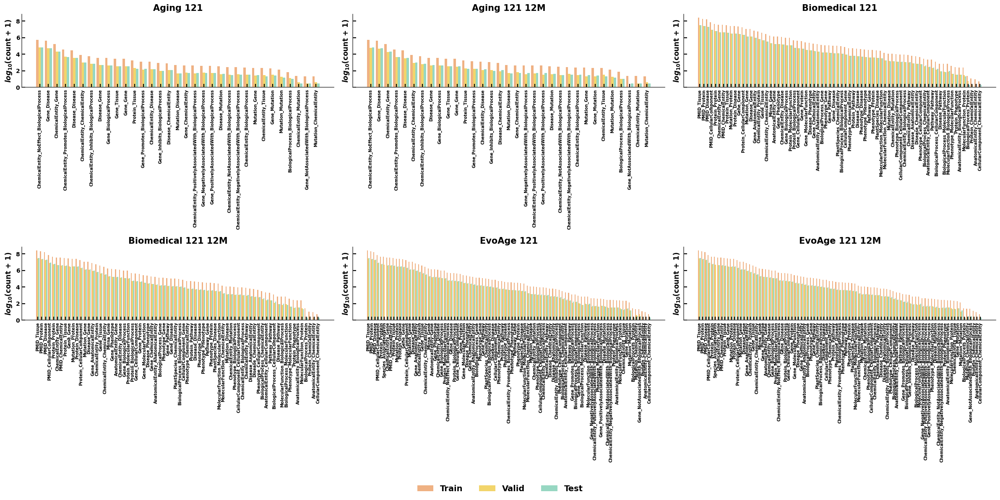

In [233]:
#!/usr/bin/env python3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# Input
# ==========================================================

# Your dataframe
df = pd.read_csv("/storage/Arushi//090526_EvoAge/kg_formation/training_3/Training_Stats/KG_relation_counts.csv")

# ----------------------------------------------------------
# Plot settings
# ----------------------------------------------------------

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

colors = {
    "Train": "#efb183",
    "Valid": "#f2d56b",
    "Test": "#97d7c2"
}

kgs = [
    "Aging_121",
    "Aging_121_12M",
    "Biomedical_121",
    "Biomedical_121_12M",
    "EvoAge_121",
    "EvoAge_121_12M"
]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(24, 12),
    sharey=True
)

axes = axes.flatten()

# ==========================================================
# Plot each KG
# ==========================================================

for ax, kg in zip(axes, kgs):

    tmp = df[df["KG"] == kg].copy()

    pivot = (
        tmp.pivot(
            index="Relation",
            columns="Split",
            values="Count"
        )
        .fillna(0)
    )

    # sort by training count
    pivot = pivot.sort_values("Train", ascending=False)

    # log10(count+1)
    train = np.log10(pivot["Train"] + 1)
    valid = np.log10(pivot["Valid"] + 1)
    test  = np.log10(pivot["Test"] + 1)

    x = np.arange(len(pivot))

    width = 0.28

    ax.bar(
        x - width,
        train,
        width,
        color=colors["Train"],
        label="Train"
    )

    ax.bar(
        x,
        valid,
        width,
        color=colors["Valid"],
        label="Valid"
    )

    ax.bar(
        x + width,
        test,
        width,
        color=colors["Test"],
        label="Test"
    )

    ax.set_title(
        kg.replace("_", " "),
        fontsize=15,
        weight="bold"
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        pivot.index,
        rotation=90,
        fontsize=7
    )

    ax.set_ylabel(r"$log_{10}$(count + 1)", fontsize=12)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ==========================================================
# Legend
# ==========================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    fontsize=14,
    frameon=False
)

plt.tight_layout(rect=[0,0.06,1,1])

plt.savefig(
    "All_KG_relation_distribution.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

## Supplementary Figure 5

## Supp 5e

Saved: /storage/Arushi/090526_EvoAge/kg_formation/hypothesis_testing/18072026_new_cutoff/youdenJ_cutoff_by_relation.svg  (88 relations plotted)


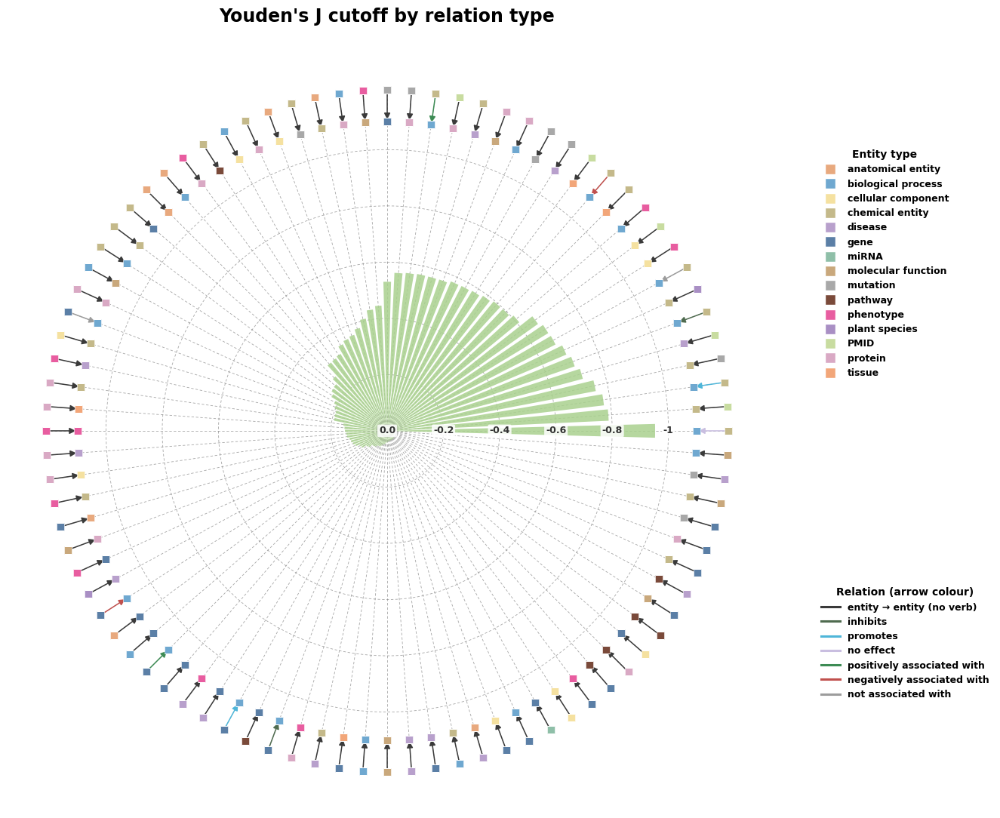

In [106]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Circular "Youden J cutoff by relation type" plot for the NEW relation-level
cutoff table (relation_cutoff_summary.csv), matching the style of the
original relation-samples plot but rebuilt for the new data/columns.

For every row in the CSV:
  - `relation` is parsed into (head_entity, [relation_verb], tail_entity),
    split on '_'. Entity type names never contain an underscore in this
    dataset, so a 2-token relation is entity_entity, and a 3-token relation
    is entity_verb_entity (e.g. chemicalentity_inhibits_biologicalprocess).
  - the green radial bar height = abs(cutoff_youdenJ) (values are all
    negative in the table, so the radial axis is labelled with negative
    ticks growing outward, exactly like the original figure).
  - two small squares sit just outside the bar ring: the outer square is
    coloured by the head entity type, the inner square by the tail entity
    type, with an arrow drawn from head -> tail (pointing inward), coloured
    by the relation verb when present (inhibits / promotes / no-effect /
    positively|negatively|not associated with), or a neutral dark grey for
    plain entity-entity relations.

Output: a single self-contained, publication-quality SVG.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ========= CONFIG (edit paths as needed) =========
INPUT_CSV  = Path("/storage/Arushi/090526_EvoAge/kg_formation/hypothesis_testing/18072026_new_cutoff/relation_cutoff_summary.csv")
OUTPUT_SVG = Path("/storage/Arushi/090526_EvoAge/kg_formation/hypothesis_testing/18072026_new_cutoff/youdenJ_cutoff_by_relation.svg")
FIGSIZE    = (13, 11)
DPI        = 300
# ==================================================

# Fallback for local testing if the server path above isn't mounted here.
if not INPUT_CSV.exists():
    INPUT_CSV = Path("kg_cutoff/relation_cutoff_summary.csv")
    OUTPUT_SVG = Path("kg_cutoff/youdenJ_cutoff_by_relation.svg")

# ---------- colour palette ----------
ENTITY_COLORS = {
    "anatomicalentity":  "#E8A97E",
    "biologicalprocess": "#6FA8D0",
    "cellularcomponent": "#F5E1A0",
    "chemicalentity":    "#C4B98A",
    "disease":           "#B8A0CC",
    "gene":              "#5B7FA6",
    "mirna":             "#8FBFA8",
    "molecularfunction": "#C9A87C",
    "mutation":          "#A8A8A8",
    "pathway":           "#7A4A3A",
    "phenotype":         "#E85DA0",
    "plantspecies":      "#A98FC4",
    "pmid":              "#C8DCA0",
    "protein":           "#D9A9C4",
    "tissue":            "#F2A679",
}
ENTITY_LABELS = {
    "anatomicalentity":  "anatomical entity",
    "biologicalprocess": "biological process",
    "cellularcomponent": "cellular component",
    "chemicalentity":    "chemical entity",
    "disease":           "disease",
    "gene":              "gene",
    "mirna":             "miRNA",
    "molecularfunction": "molecular function",
    "mutation":          "mutation",
    "pathway":           "pathway",
    "phenotype":         "phenotype",
    "plantspecies":      "plant species",
    "pmid":              "PMID",
    "protein":           "protein",
    "tissue":            "tissue",
}

VERB_COLORS = {
    None:                       "#3A3A3A",  # plain entity-entity relation
    "inhibits":                 "#4F6B4F",
    "promotes":                 "#4FB6D9",
    "noeffect":                 "#C9BEE0",
    "positivelyassociatedwith": "#3D8B54",
    "negativelyassociatedwith": "#C0504D",
    "notassociatedwith":        "#9C9C9C",
}
VERB_LABELS = {
    None:                       "entity \u2192 entity (no verb)",
    "inhibits":                 "inhibits",
    "promotes":                 "promotes",
    "noeffect":                 "no effect",
    "positivelyassociatedwith": "positively associated with",
    "negativelyassociatedwith": "negatively associated with",
    "notassociatedwith":        "not associated with",
}

BAR_COLOR = "#A9D18E"  # green radial bars, matching original figure


def parse_relation(relation: str):
    """Split 'head[_verb]_tail' -> (head_entity, verb_or_None, tail_entity)."""
    parts = relation.split("_")
    if len(parts) == 2:
        return parts[0], None, parts[1]
    elif len(parts) == 3:
        return parts[0], parts[1], parts[2]
    else:
        # Should not happen with this dataset, but fail safe: first token is
        # head, last is tail, everything in between joined as the verb.
        return parts[0], "_".join(parts[1:-1]), parts[-1]


def main():
    df = pd.read_csv(INPUT_CSV)
    # Arrange bars from smallest to largest cutoff value (ascending), like the
    # original figure, instead of alphabetically by relation name. Because
    # cutoff_youdenJ is negative, ascending numeric order (-0.95 -> -0.01)
    # also means largest-magnitude bar first, tapering down around the circle.
    df = df.sort_values("cutoff_youdenJ", ascending=True).reset_index(drop=True)

    heads, verbs, tails = zip(*(parse_relation(r) for r in df["relation"]))
    df["head_entity"], df["relation_verb"], df["tail_entity"] = heads, verbs, tails

    n = len(df)
    theta = np.linspace(0, 2 * np.pi, n, endpoint=False)
    # start at top (12 o'clock), go clockwise, like the original figure
    theta_plot = (np.pi / 2 - theta) % (2 * np.pi)

    values = df["cutoff_youdenJ"].to_numpy(dtype=float)
    bar_heights = np.abs(values)  # all cutoffs are negative -> plot magnitude, label ticks negative

    axis_max = np.ceil(bar_heights.max() * 10) / 10.0  # round up to nearest 0.1 (~1.0 here)
    R_BAR = 4.0                      # radius of the outer edge of the bar ring
    R_SQ_OUTER = R_BAR + 0.85         # head-entity square radius
    R_SQ_INNER = R_BAR + 0.40         # tail-entity square radius
    bar_scale = R_BAR / axis_max

    bar_r = bar_heights * bar_scale
    width = (2 * np.pi / n) * 0.72

    fig = plt.figure(figsize=FIGSIZE)
    ax = fig.add_subplot(111, projection="polar")
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_ylim(0, R_SQ_OUTER + 0.55)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines["polar"].set_visible(False)
    ax.grid(False)

    # ---- radial gridlines + tick labels (drawn only along the vertical, like original) ----
    n_ticks = 5
    tick_vals = np.linspace(0, axis_max, n_ticks + 1)
    for tv in tick_vals:
        r = tv * bar_scale
        circle_theta = np.linspace(0, 2 * np.pi, 400)
        ax.plot(circle_theta, np.full_like(circle_theta, r),
                color="grey", lw=0.6, ls=(0, (4, 3)), zorder=1, alpha=0.7)
    for i, tv in enumerate(tick_vals):
        if i == 0:
            continue
        r = tv * bar_scale
        ax.text(np.pi / 2, r, f"-{tv:.2f}".rstrip("0").rstrip(".") if tv != 0 else "0.0",
                ha="center", va="center", fontsize=9, color="#333333",
                zorder=6, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    ax.text(np.pi / 2, 0, "0.0", ha="center", va="center", fontsize=9,
            color="#333333", zorder=6,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))

    # ---- radial spokes (dashed lines from centre out to each relation) ----
    for th in theta_plot:
        ax.plot([th, th], [0, R_SQ_OUTER], color="grey", lw=0.6,
                 ls=(0, (4, 3)), alpha=0.7, zorder=1)

    # ---- green radial bars ----
    ax.bar(theta_plot, bar_r, width=width, bottom=0.0,
           color=BAR_COLOR, edgecolor="none", alpha=0.85, zorder=2)

    # ---- head/tail entity squares + directional arrow per relation ----
    for th, head, verb, tail in zip(theta_plot, heads, verbs, tails):
        c_head = ENTITY_COLORS.get(head, "#CCCCCC")
        c_tail = ENTITY_COLORS.get(tail, "#CCCCCC")
        c_verb = VERB_COLORS.get(verb, "#3A3A3A")

        # arrow: head (outer) -> tail (inner), pointing toward centre
        ax.annotate("", xy=(th, R_SQ_INNER), xytext=(th, R_SQ_OUTER),
                    arrowprops=dict(arrowstyle="-|>", color=c_verb,
                                    lw=1.1, shrinkA=2, shrinkB=2), zorder=4)

        ax.scatter([th], [R_SQ_OUTER], s=55, marker="s", color=c_head,
                   edgecolor="white", linewidth=0.4, zorder=5)
        ax.scatter([th], [R_SQ_INNER], s=55, marker="s", color=c_tail,
                   edgecolor="white", linewidth=0.4, zorder=5)

    ax.set_title("Youden's J cutoff by relation type", fontsize=17, pad=28, weight="bold")

    # ---- legends ----
    entity_handles = [
        plt.Line2D([0], [0], marker="s", color="none", markerfacecolor=c,
                   markeredgecolor="white", markersize=10, label=ENTITY_LABELS[e])
        for e, c in ENTITY_COLORS.items()
    ]
    verb_handles = [
        plt.Line2D([0], [0], color=c, lw=2.2, label=VERB_LABELS[v])
        for v, c in VERB_COLORS.items()
    ]

    leg1 = ax.legend(handles=entity_handles, title="Entity type",
                      loc="center left", bbox_to_anchor=(1.06, 0.72),
                      frameon=False, fontsize=9, title_fontsize=10)
    ax.add_artist(leg1)
    ax.legend(handles=verb_handles, title="Relation (arrow colour)",
              loc="center left", bbox_to_anchor=(1.06, 0.22),
              frameon=False, fontsize=9, title_fontsize=10)

    fig.tight_layout()
    fig.savefig(OUTPUT_SVG, format="svg", bbox_inches="tight")
    print(f"Saved: {OUTPUT_SVG}  ({n} relations plotted)")


if __name__ == "__main__":
    main()

## Supplementary Figure 6

## Supp 6b

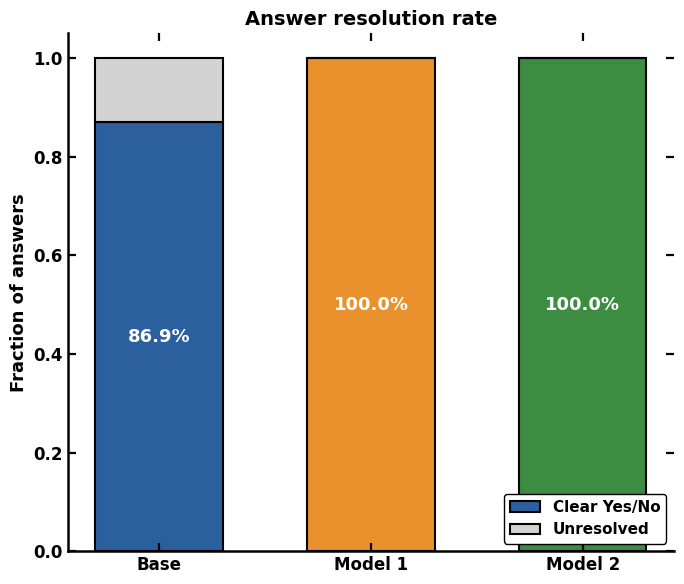

In [94]:
# ============================================================================
# PLOT 3: Answer resolution rate
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import re
import os

# Configuration
PATH_BASE = "judge_results_base_resolved_common.csv"
PATH_FT3 = "judge_results_3_2_resolved_common.csv"
PATH_FT4 = "judge_results_4_2_resolved_common.csv"
OUTDIR = "outputs"
os.makedirs(OUTDIR, exist_ok=True)

MODEL_ORDER = ["Base", "Model 1", "Model 2"]
MODEL_COLORS = {"Base": "#2C5F9E", "Model 1": "#E8912D", "Model 2": "#3C8C42"}

mpl.rcParams.update({
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.linewidth": 1.8,
    "axes.edgecolor": "black",
    "xtick.major.width": 1.6,
    "ytick.major.width": 1.6,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.fontsize": 11,
    "legend.edgecolor": "black",
    "legend.framealpha": 1.0,
})

def style_axes(ax):
    ax.tick_params(which="both", top=True, right=True, direction="in")
    for spine in ax.spines.values():
        spine.set_linewidth(1.8)
        spine.set_color("black")

def resolve_prediction(row):
    pred = str(row.get("resolved_answer", "")).upper().strip()
    if pred in {"TRUE", "FALSE"}:
        return pred
    raw = str(row.get("judge_raw_response", "")).upper()
    has_true = bool(re.search(r"\bTRUE\b", raw))
    has_false = bool(re.search(r"\bFALSE\b", raw))
    if has_true and not has_false:
        return "TRUE"
    if has_false and not has_true:
        return "FALSE"
    return "OTHER"

def load_judge_csv(path):
    df = pd.read_csv(path)
    if df["ground_truth"].dtype != bool:
        df["ground_truth"] = df["ground_truth"].astype(str).str.upper().map({"TRUE": True, "FALSE": False})
    df["prediction"] = df.apply(resolve_prediction, axis=1)
    df["answer_cat"] = df["prediction"].map({"TRUE": "Yes", "FALSE": "No", "OTHER": "Unresolved"})
    return df

def compute_model_stats(df):
    n = len(df)
    committed = df[df["answer_cat"] != "Unresolved"]
    cols = ["Yes", "No", "Unresolved"]
    conf_counts = df.groupby(["ground_truth", "answer_cat"]).size().unstack(fill_value=0).reindex(index=[True, False], columns=cols, fill_value=0)
    conf_frac = conf_counts.div(conf_counts.sum(axis=1), axis=0)
    resolved_frac = len(committed) / n
    true_committed = committed[committed["ground_truth"] == True]
    false_committed = committed[committed["ground_truth"] == False]
    recall_true = (true_committed["answer_cat"] == "Yes").mean() * 100
    recall_false = (false_committed["answer_cat"] == "No").mean() * 100
    affirm_frac = (committed["answer_cat"] == "Yes").mean() * 100
    edge_accuracy = df["accuracy"].mean()
    prevalence = committed["ground_truth"].mean() * 100
    return {"n": n, "conf_counts": conf_counts, "conf_frac": conf_frac, "resolved_frac": resolved_frac,
            "recall_true": recall_true, "recall_false": recall_false, "affirm_frac": affirm_frac,
            "edge_accuracy": edge_accuracy, "prevalence": prevalence}

dfs = {"Base": load_judge_csv(PATH_BASE), "Model 1": load_judge_csv(PATH_FT3), "Model 2": load_judge_csv(PATH_FT4)}
stats = {name: compute_model_stats(df) for name, df in dfs.items()}

# Plot
fig, ax = plt.subplots(figsize=(7, 6))
x = np.arange(len(MODEL_ORDER))
resolved = [stats[m]["resolved_frac"] for m in MODEL_ORDER]
unresolved = [1 - r for r in resolved]

bars_r = ax.bar(x, resolved, width=0.6, color=[MODEL_COLORS[m] for m in MODEL_ORDER],
                edgecolor="black", linewidth=1.5, label="Clear Yes/No")
bars_u = ax.bar(x, unresolved, width=0.6, bottom=resolved, color="lightgray",
                edgecolor="black", linewidth=1.5, label="Unresolved")

for xi, r in zip(x, resolved):
    color = "white" if r > 0.15 else "black"
    va = "center" if r > 0.1 else "bottom"
    ypos = r / 2 if r > 0.1 else r + 0.02
    ax.text(xi, ypos, f"{r*100:.1f}%", ha="center", va=va, fontsize=13, fontweight="bold", color=color)

ax.set_xticks(x)
ax.set_xticklabels(MODEL_ORDER, fontsize=12, fontweight="bold")
ax.set_ylabel("Fraction of answers")
ax.set_title("Answer resolution rate")
ax.set_ylim(0, 1.05)
style_axes(ax)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(f"{OUTDIR}/fig3_resolution_rate.svg")
plt.show()
plt.close(fig)

## Supp 6c

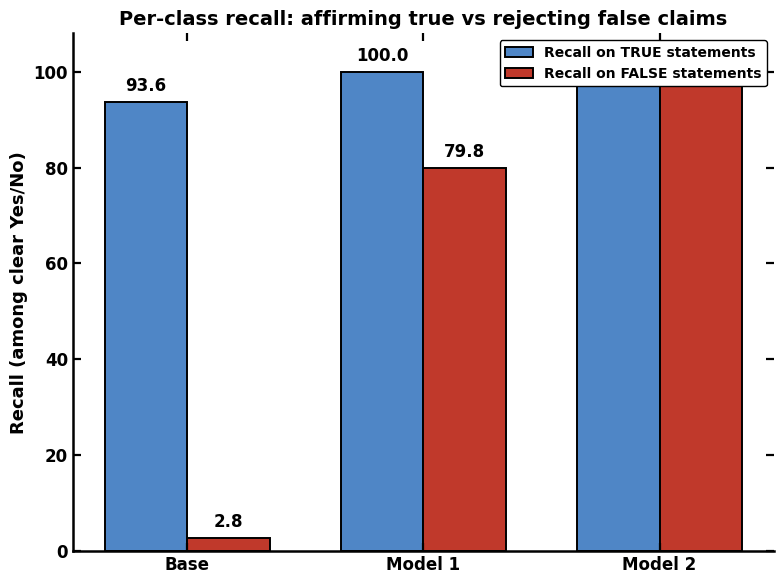

In [97]:
# ============================================================================
# PLOT 4: Per-class recall: affirming true vs rejecting false claims
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import re
import os

# Configuration
PATH_BASE = "judge_results_base_resolved_common.csv"
PATH_FT3 = "judge_results_3_2_resolved_common.csv"
PATH_FT4 = "judge_results_4_2_resolved_common.csv"
OUTDIR = "outputs"
os.makedirs(OUTDIR, exist_ok=True)

MODEL_ORDER = ["Base", "Model 1", "Model 2"]
MODEL_COLORS = {"Base": "#2C5F9E", "Model 1": "#E8912D", "Model 2": "#3C8C42"}

mpl.rcParams.update({
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.linewidth": 1.8,
    "axes.edgecolor": "black",
    "xtick.major.width": 1.6,
    "ytick.major.width": 1.6,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.fontsize": 11,
    "legend.edgecolor": "black",
    "legend.framealpha": 1.0,
})

def style_axes(ax):
    ax.tick_params(which="both", top=True, right=True, direction="in")
    for spine in ax.spines.values():
        spine.set_linewidth(1.8)
        spine.set_color("black")

def resolve_prediction(row):
    pred = str(row.get("resolved_answer", "")).upper().strip()
    if pred in {"TRUE", "FALSE"}:
        return pred
    raw = str(row.get("judge_raw_response", "")).upper()
    has_true = bool(re.search(r"\bTRUE\b", raw))
    has_false = bool(re.search(r"\bFALSE\b", raw))
    if has_true and not has_false:
        return "TRUE"
    if has_false and not has_true:
        return "FALSE"
    return "OTHER"

def load_judge_csv(path):
    df = pd.read_csv(path)
    if df["ground_truth"].dtype != bool:
        df["ground_truth"] = df["ground_truth"].astype(str).str.upper().map({"TRUE": True, "FALSE": False})
    df["prediction"] = df.apply(resolve_prediction, axis=1)
    df["answer_cat"] = df["prediction"].map({"TRUE": "Yes", "FALSE": "No", "OTHER": "Unresolved"})
    return df

def compute_model_stats(df):
    n = len(df)
    committed = df[df["answer_cat"] != "Unresolved"]
    cols = ["Yes", "No", "Unresolved"]
    conf_counts = df.groupby(["ground_truth", "answer_cat"]).size().unstack(fill_value=0).reindex(index=[True, False], columns=cols, fill_value=0)
    conf_frac = conf_counts.div(conf_counts.sum(axis=1), axis=0)
    resolved_frac = len(committed) / n
    true_committed = committed[committed["ground_truth"] == True]
    false_committed = committed[committed["ground_truth"] == False]
    recall_true = (true_committed["answer_cat"] == "Yes").mean() * 100
    recall_false = (false_committed["answer_cat"] == "No").mean() * 100
    affirm_frac = (committed["answer_cat"] == "Yes").mean() * 100
    edge_accuracy = df["accuracy"].mean()
    prevalence = committed["ground_truth"].mean() * 100
    return {"n": n, "conf_counts": conf_counts, "conf_frac": conf_frac, "resolved_frac": resolved_frac,
            "recall_true": recall_true, "recall_false": recall_false, "affirm_frac": affirm_frac,
            "edge_accuracy": edge_accuracy, "prevalence": prevalence}

dfs = {"Base": load_judge_csv(PATH_BASE), "Model 1": load_judge_csv(PATH_FT3), "Model 2": load_judge_csv(PATH_FT4)}
stats = {name: compute_model_stats(df) for name, df in dfs.items()}

# Plot
fig, ax = plt.subplots(figsize=(8, 6))

x = np.arange(len(MODEL_ORDER))
w = 0.35
recall_true = [stats[m]["recall_true"] for m in MODEL_ORDER]
recall_false = [stats[m]["recall_false"] for m in MODEL_ORDER]

b1 = ax.bar(x - w/2, recall_true, width=w, color="#4F86C6", edgecolor="black", 
            linewidth=1.4, label="Recall on TRUE statements")
b2 = ax.bar(x + w/2, recall_false, width=w, color="#C0392B", edgecolor="black",
            linewidth=1.4, label="Recall on FALSE statements")

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 1.5, f"{h:.1f}", 
                ha="center", va="bottom", fontsize=12, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(MODEL_ORDER, fontsize=12, fontweight="bold")
ax.set_ylabel("Recall (among clear Yes/No)")
ax.set_title("Per-class recall: affirming true vs rejecting false claims")
ax.set_ylim(0, 108)
style_axes(ax)
ax.legend(loc="upper right", fontsize=10)

fig.tight_layout()
fig.savefig(f"{OUTDIR}/fig4_recall_and_affirmation.svg")
plt.show()
plt.close(fig)

## Supplementary Figure 7

## Supp 7a

Loading data from: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/05_assay_QC_heatmap/input_qc_pass_rate_by_round_condition.csv
Loaded 15 rows

Data preview:
   Round Condition  n_measurements  n_pass  n_fail  pass_rate_pct
0      1        30            1026     999      27           97.4
1      1        37            1026    1001      25           97.6
2      1         P            1026     988      38           96.3
3      2        30            1026     984      42           95.9
4      2        37            1026     986      40           96.1

QC pass rate matrix (rows=rounds, columns=Pulser, 30°C, 37°C):
Condition    P   30   37
Round                   
1         96.3 97.4 97.6
2         95.7 95.9 96.1
3           96 95.9 96.2
4         97.9 97.9 97.9
5         97.8 97.9   98


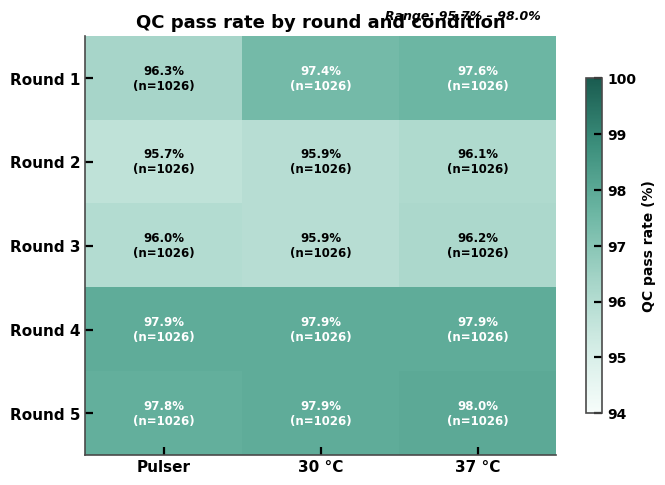

✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/05_assay_QC_heatmap/assay_qc_heatmap.svg
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/05_assay_QC_heatmap/assay_qc_heatmap.png
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/05_assay_QC_heatmap/assay_qc_heatmap.pdf

📊 QC Heatmap Summary:
Total measurements across all rounds & conditions: 15,390
Overall QC pass rate: 97.0%
Range: 95.7% – 98.0%

QC pass rate by condition (Pulser, 30°C, 37°C):
  Pulser: mean=96.7%, min=95.7%, max=97.9%
  30 °C: mean=97.0%, min=95.9%, max=97.9%
  37 °C: mean=97.2%, min=96.1%, max=98.0%

QC pass rate by round:
  Round 1: mean=97.1%, min=96.3%, max=97.6%
  Round 2: mean=95.9%, min=95.7%, max=96.1%
  Round 3: mean=96.0%, min=95.9%, max=96.2%
  Round 4: mean=97.9%, min=97.9%, max=97.9%
  Round 5: mean=97.9%, min=97.8%, max=98.0%

✅ All done! Plots saved in: /storage/Arushi/090526_EvoAge/kg_form

In [234]:
# This magic command makes plots appear in the notebook


"""
05_assay_QC_heatmap
-------------------
QC pass-rate heatmap across 5 experimental rounds x 3 conditions (P, 30, 37).

INPUT : /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/05_assay_QC_heatmap/input_qc_pass_rate_by_round_condition.csv
OUTPUT: assay_qc_heatmap.svg / .png / .pdf in the same directory
"""

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "none",
    "pdf.fonttype": 42
})
# ── Configuration ──────────────────────────────────────────────────────
# Input file path
INPUT_FILE = '/storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/05_assay_QC_heatmap/input_qc_pass_rate_by_round_condition.csv'

# Output directory (same as input file location)
OUTPUT_DIR = os.path.dirname(INPUT_FILE)
DPI = 600

# ── Custom teal colormap (matches reference colorbar: pale -> deep teal) ─
TEAL_COLORS = ["#f7fdfb", "#d3ece5", "#a4d4c7", "#6cb6a3", "#3c8f7c", "#1a5c50"]
teal_cmap = LinearSegmentedColormap.from_list("custom_teal", TEAL_COLORS, N=256)

# ── Load data ──────────────────────────────────────────────────────────
print(f"Loading data from: {INPUT_FILE}")
rc = pd.read_csv(INPUT_FILE)
print(f"Loaded {len(rc)} rows")
print("\nData preview:")
print(rc.head())

# Check required columns
required_cols = ['Round', 'Condition', 'pass_rate_pct', 'n_measurements']
missing_cols = [col for col in required_cols if col not in rc.columns]
if missing_cols:
    print(f"Warning: Missing columns: {missing_cols}")
    print("Available columns:", rc.columns.tolist())

# ── Pivot data ──────────────────────────────────────────────────────────
# Pivot to round x condition matrix with columns ordered: P, 30, 37
# First pivot, then reorder columns
pivot = rc.pivot(index='Round', columns='Condition', values='pass_rate_pct')
# Reorder columns: P, 30, 37 (Pulser first, then 30°C, then 37°C)
pivot = pivot[['P', '30', '37']]
n_pivot = rc.pivot(index='Round', columns='Condition', values='n_measurements')
n_pivot = n_pivot[['P', '30', '37']]

print(f"\nQC pass rate matrix (rows=rounds, columns=Pulser, 30°C, 37°C):")
print(pivot)

# ── Create heatmap ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pivot.values, cmap=teal_cmap, vmin=94, vmax=100, aspect='auto')

# Set x-axis labels (conditions) - now in order: Pulser, 30°C, 37°C
ax.set_xticks(range(3))
ax.set_xticklabels(['Pulser', '30 °C', '37 °C'], fontsize=11, fontweight='bold')
ax.set_yticks(range(5))
ax.set_yticklabels([f'Round {i}' for i in range(1, 6)], fontsize=11, fontweight='bold')

# Add text annotations with values and n
for i in range(5):
    for j in range(3):
        val = pivot.values[i, j]
        nmeas = int(n_pivot.values[i, j])
        # Choose text color based on background (sequential cmap: dark at high end)
        norm_val = (val - 94) / (100 - 94)
        text_color = 'white' if norm_val > 0.55 else 'black'
        ax.text(j, i, f'{val:.1f}%\n(n={nmeas})', ha='center', va='center',
                fontsize=8.5, fontweight='bold', color=text_color)

ax.set_title('QC pass rate by round and condition', fontsize=13, fontweight='bold')

# Colorbar
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('QC pass rate (%)', fontsize=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Range annotation
lo, hi = pivot.values.min(), pivot.values.max()
ax.text(2.4, -0.7, f'Range: {lo:.1f}% – {hi:.1f}%', ha='right', fontsize=9,
        fontstyle='italic', transform=ax.transData)

plt.tight_layout()

# ── Show in notebook ──────────────────────────────────────────────────
plt.show()

# ── Save figures ──────────────────────────────────────────────────────
output_stem = os.path.join(OUTPUT_DIR, 'assay_qc_heatmap')
for ext in ['svg', 'png', 'pdf']:
    output_path = f"{output_stem}.{ext}"
    plt.savefig(output_path, dpi=DPI, bbox_inches='tight')
    print(f"✅ Saved: {output_path}")

plt.close()

# ── Print summary statistics ────────────────────────────────────────────
print(f"\n📊 QC Heatmap Summary:")
print(f"Total measurements across all rounds & conditions: {n_pivot.values.sum():,}")
print(f"Overall QC pass rate: {pivot.values.mean():.1f}%")
print(f"Range: {lo:.1f}% – {hi:.1f}%")

print("\nQC pass rate by condition (Pulser, 30°C, 37°C):")
for cond in ['P', '30', '37']:
    cond_vals = pivot[cond].values
    label = 'Pulser' if cond == 'P' else f'{cond} °C'
    print(f"  {label}: mean={cond_vals.mean():.1f}%, min={cond_vals.min():.1f}%, max={cond_vals.max():.1f}%")

print("\nQC pass rate by round:")
for i in range(5):
    round_vals = pivot.iloc[i].values
    print(f"  Round {i+1}: mean={round_vals.mean():.1f}%, min={round_vals.min():.1f}%, max={round_vals.max():.1f}%")

print(f"\n✅ All done! Plots saved in: {OUTPUT_DIR}")

## Supp 7b, c

Loading data from: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/fdr/final_FDR_plot/EvoAge_FDR_plot_input.csv
Loaded 976 genes


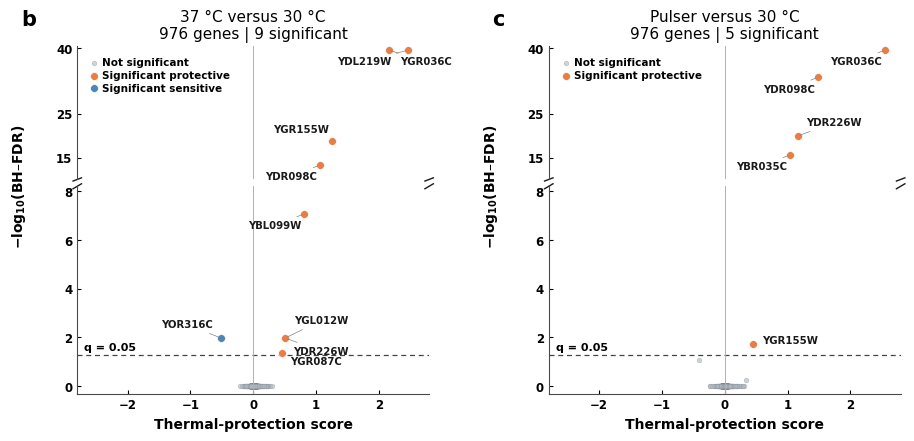

✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/fdr/final_FDR_plot/EvoAge_37C_Pulser_broken_axis.svg
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/fdr/final_FDR_plot/EvoAge_37C_Pulser_broken_axis.png
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/fdr/final_FDR_plot/EvoAge_37C_Pulser_broken_axis.pdf

📊 FDR Plot Summary:
Input genes: 976
37 °C significant: 9
Pulser significant: 5
Both conditions significant: 4

✅ All done! Plots saved in: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/fdr/final_FDR_plot


In [186]:
# This magic command makes plots appear in the notebook
%matplotlib inline

"""
EvoAge Score-FDR Plot with Broken Y-Axis
----------------------------------------
Creates side-by-side EvoAge score–FDR panels with a broken y axis.

INPUT : /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/fdr/final_FDR_plot/input_data.csv
OUTPUT: EvoAge_37C_Pulser_broken_axis.svg / .png / .pdf in the same directory
"""

import warnings
warnings.filterwarnings('ignore')

import math
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

# ── Configuration ──────────────────────────────────────────────────────
# Input file path
INPUT_FILE = '/storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/fdr/final_FDR_plot/EvoAge_FDR_plot_input.csv'

# Output directory (same as input file location)
OUTPUT_DIR = os.path.dirname(INPUT_FILE)
DPI = 600

# ── Constants ──────────────────────────────────────────────────────────
NEUTRAL = "#AEB8BE"
PROTECTIVE = "#E67E45"
SENSITIVE = "#4C86B7"
TEXT = "#1A1A1A"

def configure() -> None:
    plt.rcParams.update({
        "font.family": "DejaVu Sans",
        "font.size": 9,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "legend.fontsize": 7.5,
        "axes.linewidth": 0.8,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

def as_bool(value) -> bool:
    return str(value).strip().lower() in {"true", "1", "yes"}

def load_data(path):
    """Load and prepare data for FDR plot."""
    print(f"Loading data from: {path}")
    df = pd.read_csv(path)
    print(f"Loaded {len(df)} genes")
    
    # Check required columns
    required = {
        "Gene", "Score_c1", "q_value_c1", "Sig_37C",
        "Score_c2", "q_value_c2", "Sig_Pulser",
    }
    missing = sorted(required - set(df.columns))
    if missing:
        print(f"Warning: Missing columns: {', '.join(missing)}")
        print("Available columns:", df.columns.tolist())
    
    df["score_37C"] = pd.to_numeric(df["Score_c1"], errors="coerce")
    df["score_Pulser"] = pd.to_numeric(df["Score_c2"], errors="coerce")
    df["q_37C"] = pd.to_numeric(df["q_value_c1"], errors="coerce").clip(lower=1e-300)
    df["q_Pulser"] = pd.to_numeric(df["q_value_c2"], errors="coerce").clip(lower=1e-300)
    df["neglog10_q_37C"] = -np.log10(df["q_37C"])
    df["neglog10_q_Pulser"] = -np.log10(df["q_Pulser"])
    df["sig_37C"] = df["Sig_37C"].map(as_bool)
    df["sig_Pulser"] = df["Sig_Pulser"].map(as_bool)
    
    return df.dropna(subset=["score_37C", "score_Pulser", "q_37C", "q_Pulser"])

def style_axis(ax):
    ax.spines["right"].set_visible(False)
    ax.tick_params(length=3, width=0.8)
    ax.grid(False)

def add_break_marks(ax_top, ax_bottom):
    """Draw diagonal marks at the y-axis break on both left and right edges."""
    d = 0.012
    kwargs_top = dict(transform=ax_top.transAxes, color=TEXT, clip_on=False, linewidth=1.0)
    kwargs_bottom = dict(transform=ax_bottom.transAxes, color=TEXT, clip_on=False, linewidth=1.0)
    ax_top.plot((-d, +d), (-d, +d), **kwargs_top)
    ax_top.plot((1 - d, 1 + d), (-d, +d), **kwargs_top)
    ax_bottom.plot((-d, +d), (1 - d, 1 + d), **kwargs_bottom)
    ax_bottom.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs_bottom)

def scatter_on_axis(ax, x, y, sig):
    """Create scatter plot on a single axis."""
    # Cap extreme −log10(q) values at 39.5 for visualization only.
    y = np.minimum(np.asarray(y, dtype=float), 39.5)
    not_sig = ~sig
    positive = sig & (x > 0)
    negative = sig & (x < 0)
    
    ax.scatter(
        x[not_sig], y[not_sig], s=12, c=NEUTRAL, alpha=0.62,
        edgecolors="#7C878D", linewidths=0.25, label="Not significant", zorder=2,
    )
    ax.scatter(
        x[positive], y[positive], s=32, c=PROTECTIVE,
        edgecolors="white", linewidths=0.45,
        label="Significant protective", zorder=4,
    )
    ax.scatter(
        x[negative], y[negative], s=32, c=SENSITIVE,
        edgecolors="white", linewidths=0.45,
        label="Significant sensitive", zorder=4,
    )

def annotate_hits(ax_top, ax_bottom, df, condition):
    """Annotate significant genes on the plot."""
    if condition == "37C":
        xcol, ycol, sigcol = "score_37C", "neglog10_q_37C", "sig_37C"
        offsets = {
            "YDL219W": (-12, -12), "YGR036C": (8, -12), "YGR155W": (-2, 5),
            "YDR098C": (-2, -12), "YBL099W": (-2, -12), "YOR316C": (-6, 6),
            "YGL012W": (6, 9), "YGR087C": (6, -10), "YDR226W": (6, -13),
        }
    else:
        xcol, ycol, sigcol = "score_Pulser", "neglog10_q_Pulser", "sig_Pulser"
        offsets = {
            "YDR098C": (-2, -12), "YGR036C": (-2, -12), "YDR226W": (6, 6),
            "YBR035C": (-2, -12), "YGR155W": (6, -1),
        }
    
    for _, row in df.loc[df[sigcol]].iterrows():
        x, y_raw, gene = row[xcol], row[ycol], str(row["Gene"])
        y = min(float(y_raw), 39.5)
        ax = ax_top if y >= 10 else ax_bottom
        dx, dy = offsets.get(gene, (5 if x >= 0 else -5, 5))
        ax.annotate(
            gene, (x, y), xytext=(dx, dy), textcoords="offset points",
            fontsize=7.3, color=TEXT,
            ha="left" if dx >= 0 else "right", va="bottom",
            arrowprops={"arrowstyle": "-", "lw": 0.45, "color": "#777777"}
            if abs(dx) >= 6 or abs(dy) >= 8 else None,
            zorder=6,
        )

def draw_broken_panel(fig, spec, df, condition, panel_label):
    """Create a broken-axis panel for one condition."""
    inner = GridSpecFromSubplotSpec(
        2, 1, subplot_spec=spec, height_ratios=[1.0, 1.55], hspace=0.04
    )
    ax_top = fig.add_subplot(inner[0])
    ax_bottom = fig.add_subplot(inner[1], sharex=ax_top)
    
    if condition == "37C":
        x = df["score_37C"]
        y = df["neglog10_q_37C"]
        sig = df["sig_37C"]
        title = "37 °C versus 30 °C"
    else:
        x = df["score_Pulser"]
        y = df["neglog10_q_Pulser"]
        sig = df["sig_Pulser"]
        title = "Pulser versus 30 °C"
    
    scatter_on_axis(ax_top, x, y, sig)
    scatter_on_axis(ax_bottom, x, y, sig)
    
    threshold = -math.log10(0.05)
    ax_bottom.axhline(threshold, linestyle=(0, (4, 3)), linewidth=0.9, color="#444444")
    ax_bottom.axvline(0, linewidth=0.7, color="#B0B0B0")
    ax_top.axvline(0, linewidth=0.7, color="#B0B0B0")
    ax_bottom.text(
        0.02, threshold + 0.10, "q = 0.05",
        transform=ax_bottom.get_yaxis_transform(), ha="left", va="bottom", fontsize=8,
    )
    
    # Broken-axis limits
    ax_bottom.set_ylim(-0.3, 8.2)
    ax_top.set_ylim(10, 40.5)
    ax_bottom.set_yticks([0, 2, 4, 6, 8])
    ax_top.set_yticks([15, 25, 40])
    ax_bottom.set_xlim(-2.8, 2.8)
    ax_bottom.set_xticks([-2, -1, 0, 1, 2])
    
    ax_top.spines["bottom"].set_visible(False)
    ax_bottom.spines["top"].set_visible(False)
    ax_top.tick_params(labelbottom=False, bottom=False)
    style_axis(ax_top)
    style_axis(ax_bottom)
    add_break_marks(ax_top, ax_bottom)
    
    ax_top.set_title(
        f"{title}\n{len(df)} genes | {int(sig.sum())} significant",
        fontweight="normal", pad=5,
    )
    ax_bottom.set_xlabel("Thermal-protection score")
    ax_bottom.set_ylabel("−log$_{10}$(BH–FDR)")
    # Move y label to center of the complete broken panel.
    ax_bottom.yaxis.set_label_coords(-0.14, 1.0)
    
    annotate_hits(ax_top, ax_bottom, df, condition)
    
    handles, labels = ax_top.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    order = ["Not significant", "Significant protective", "Significant sensitive"]
    if condition == "37C":
        ax_top.legend(
            [unique[k] for k in order], order,
            frameon=False, loc="upper left", bbox_to_anchor=(0.01, 0.98),
            handlelength=0.8, handletextpad=0.35, labelspacing=0.25,
        )
    else:
        available = [k for k in order if k in unique and not (k == "Significant sensitive" and not (sig & (x < 0)).any())]
        ax_top.legend(
            [unique[k] for k in available], available,
            frameon=False, loc="upper left", bbox_to_anchor=(0.01, 0.98),
            handlelength=0.8, handletextpad=0.35, labelspacing=0.25,
        )
    
    ax_top.text(
        -0.16, 1.27, panel_label, transform=ax_top.transAxes,
        fontsize=15, fontweight="bold", va="top", ha="left",
    )
    return ax_top, ax_bottom

# ── Main execution ──────────────────────────────────────────────────────
# Setup
configure()

# Load data
df = load_data(INPUT_FILE)

# Create figure
fig = plt.figure(figsize=(9.2, 4.9))
outer = GridSpec(1, 2, figure=fig, wspace=0.34, left=0.09, right=0.985, bottom=0.15, top=0.86)

# Draw panels
draw_broken_panel(fig, outer[0], df, "37C", "b")
draw_broken_panel(fig, outer[1], df, "Pulser", "c")

plt.tight_layout()

# ── Show in notebook ──────────────────────────────────────────────────
plt.show()

# ── Save figures ──────────────────────────────────────────────────────
output_stem = os.path.join(OUTPUT_DIR, 'EvoAge_37C_Pulser_broken_axis')
for ext in ['svg', 'png', 'pdf']:
    output_path = f"{output_stem}.{ext}"
    if ext == 'png':
        plt.savefig(output_path, dpi=600, bbox_inches='tight')
    else:
        plt.savefig(output_path, bbox_inches='tight')
    print(f"✅ Saved: {output_path}")

plt.close()

# ── Print summary statistics ────────────────────────────────────────────
print(f"\n📊 FDR Plot Summary:")
print(f"Input genes: {len(df)}")
print(f"37 °C significant: {int(df['sig_37C'].sum())}")
print(f"Pulser significant: {int(df['sig_Pulser'].sum())}")
print(f"Both conditions significant: {int((df['sig_37C'] & df['sig_Pulser']).sum())}")

print(f"\n✅ All done! Plots saved in: {OUTPUT_DIR}")

## Supp 7d

Loading bar counts from: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/07_evoage_support_sign/EvoAge_support_significance_bar_counts.csv
Loaded 12 records

Loading enrichment data from: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/07_evoage_support_sign/EvoAge_support_enrichment.csv
Contingency table:
  Significance status | Support | Other
  Significant in either condition |       6 |     4
  Not significant in either condition |     320 |   646
  Odds ratio: 3.03
  P-value: 9.30e-02


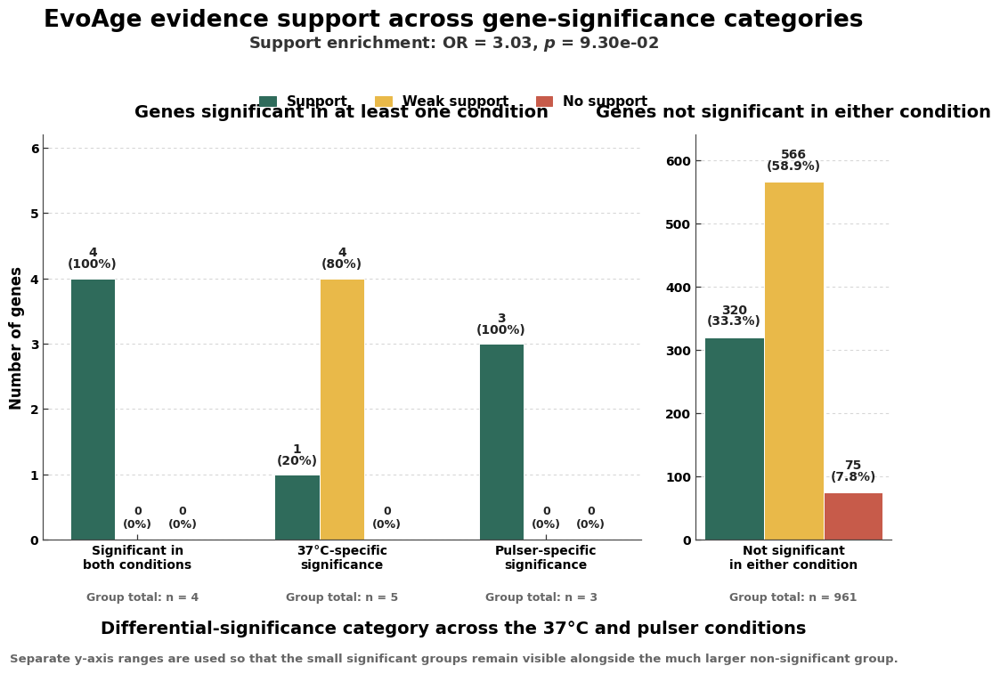

✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/07_evoage_support_sign/EvoAge_support_significance_plot.svg
✅ Saved: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/07_evoage_support_sign/EvoAge_support_significance_plot.png

📊 EvoAge Support Significance Summary:
Total significant genes: 12
Total non-significant genes: 961

Support classification breakdown (significant genes):
  Support: 8 genes
  Weak support: 4 genes
  No support: 0 genes

Support classification breakdown (non-significant genes):
  Support: 320 genes (33.3%)
  Weak support: 566 genes (58.9%)
  No support: 75 genes (7.8%)

✅ All done! Plots saved in: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/07_evoage_support_sign


In [187]:
# This magic command makes plots appear in the notebook
%matplotlib inline

"""
EvoAge Support-by-Significance Grouped Bar Plot
-----------------------------------------------
Reproduces the EvoAge support-by-significance grouped bar plot with Fisher exact test.

INPUT 1: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/07_evoage_support_sign/EvoAge_support_significance_bar_counts.csv
INPUT 2: /storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/07_evoage_support_sign/EvoAge_support_enrichment.csv
OUTPUT: EvoAge_support_significance_plot.svg / .png in the same directory
"""

import warnings
warnings.filterwarnings('ignore')

import csv
from collections import defaultdict
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import fisher_exact

# ── Configuration ──────────────────────────────────────────────────────
# Input file paths
BAR_INPUT = '/storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/07_evoage_support_sign/EvoAge_support_significance_bar_counts.csv'
ENRICHMENT_INPUT = '/storage/Arushi/090526_EvoAge/kg_formation/all_figures/yeast-exp/EvoAge_plots/07_evoage_support_sign/EvoAge_support_enrichment.csv'

# Output directory (same as input file location)
OUTPUT_DIR = os.path.dirname(BAR_INPUT)
DPI = 600

# ── Constants ──────────────────────────────────────────────────────────
COLORS = {
    "Support": "#2F6B5B",
    "Weak support": "#E9B949",
    "No support": "#C75B4A",
}
CLASS_ORDER = ["Support", "Weak support", "No support"]
SIG_ORDER = [
    "Significant in both conditions",
    "37°C-specific significance",
    "Pulser-specific significance",
]

def read_bar_counts(path):
    """Read bar count data from CSV."""
    print(f"Loading bar counts from: {path}")
    records = []
    with open(path, newline='', encoding='utf-8-sig') as handle:
        for row in csv.DictReader(handle):
            records.append({
                "panel": row["panel"],
                "category": row["significance_category"],
                "support_class": row["support_class"],
                "count": int(row["count"]),
                "group_total": int(row["group_total"]),
                "percentage": float(row["percentage"]),
            })
    print(f"Loaded {len(records)} records")
    return records

def read_enrichment(path):
    """Read enrichment data and perform Fisher exact test."""
    print(f"\nLoading enrichment data from: {path}")
    rows = []
    with open(path, newline='', encoding='utf-8-sig') as handle:
        for row in csv.DictReader(handle):
            rows.append({
                "status": row["significance_status"],
                "support": int(row["support"]),
                "other": int(row["other"]),
            })
    
    if len(rows) != 2:
        raise ValueError("The enrichment input must contain exactly two rows.")
    
    table = [[rows[0]["support"], rows[0]["other"]],
             [rows[1]["support"], rows[1]["other"]]]
    odds_ratio, p_value = fisher_exact(table, alternative="two-sided")
    
    print(f"Contingency table:")
    print(f"  Significance status | Support | Other")
    print(f"  {rows[0]['status']:20} | {rows[0]['support']:7} | {rows[0]['other']:5}")
    print(f"  {rows[1]['status']:20} | {rows[1]['support']:7} | {rows[1]['other']:5}")
    print(f"  Odds ratio: {odds_ratio:.2f}")
    print(f"  P-value: {p_value:.2e}")
    
    return odds_ratio, p_value, table

def format_category(label):
    """Format category labels for display."""
    mapping = {
        "Significant in both conditions": "Significant in\nboth conditions",
        "37°C-specific significance": "37°C-specific\nsignificance",
        "Pulser-specific significance": "Pulser-specific\nsignificance",
        "Not significant in either condition": "Not significant\nin either condition",
    }
    return mapping.get(label, label)

def annotate_bar(ax, bar, count, pct, large_panel=False):
    """Add annotation text to bars."""
    x = bar.get_x() + bar.get_width() / 2
    if count == 0:
        ax.text(x, 0.14 if not large_panel else 5, "0\n(0%)",
                ha="center", va="bottom", fontsize=9, color="#222222")
        return
    offset = 0.12 if not large_panel else 15
    # Format percentage display
    if pct in {0, 20, 80, 100}:
        label = f"{count}\n({pct:.0f}%)"
    else:
        label = f"{count}\n({pct:.1f}%)"
    ax.text(x, count + offset, label, ha="center", va="bottom",
            fontsize=10, fontweight="bold", color="#222222", linespacing=0.9)

def build_plot():
    """Create the grouped bar plot."""
    # Read data
    records = read_bar_counts(BAR_INPUT)
    odds_ratio, p_value, table = read_enrichment(ENRICHMENT_INPUT)
    
    # Organize data
    by_key = {(r["category"], r["support_class"]): r for r in records}
    totals = {r["category"]: r["group_total"] for r in records}
    
    # Configure matplotlib
    plt.rcParams.update({
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 14,
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "axes.linewidth": 0.9,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })
    
    # Create figure
    fig = plt.figure(figsize=(10.25, 7.78))
    ax_left = fig.add_axes([0.050, 0.215, 0.655, 0.585])
    ax_right = fig.add_axes([0.765, 0.215, 0.215, 0.585])
    
    # ── Left panel: significant genes ──────────────────────────────────
    width = 0.22
    x = np.arange(len(SIG_ORDER), dtype=float)
    offsets = [-width, 0, width]
    
    for cls, off in zip(CLASS_ORDER, offsets):
        vals = [by_key[(cat, cls)]["count"] for cat in SIG_ORDER]
        bars = ax_left.bar(x + off, vals, width=width, color=COLORS[cls],
                          edgecolor="white", linewidth=0.7, label=cls)
        for cat, bar, val in zip(SIG_ORDER, bars, vals):
            annotate_bar(ax_left, bar, val, by_key[(cat, cls)]["percentage"])
    
    ax_left.set_ylim(0, 6.2)
    ax_left.set_yticks(np.arange(0, 7, 1))
    ax_left.set_ylabel("Number of genes")
    ax_left.set_xticks(x)
    ax_left.set_xticklabels([format_category(c) for c in SIG_ORDER])
    ax_left.set_title("Genes significant in at least one condition", fontweight="bold", pad=14)
    ax_left.grid(axis="y", linestyle=(0, (3, 3)), color="#D7D7D7", linewidth=0.8)
    ax_left.set_axisbelow(True)
    ax_left.spines["top"].set_visible(False)
    ax_left.spines["right"].set_visible(False)
    ax_left.tick_params(width=0.9, length=4, color="#333333")
    
    # ── Right panel: non-significant genes ──────────────────────────────
    nonsig = "Not significant in either condition"
    xr = np.array([0.0])
    for cls, off in zip(CLASS_ORDER, offsets):
        rec = by_key[(nonsig, cls)]
        bars = ax_right.bar(xr + off, [rec["count"]], width=width,
                           color=COLORS[cls], edgecolor="white", linewidth=0.7)
        annotate_bar(ax_right, bars[0], rec["count"], rec["percentage"], large_panel=True)
    
    ax_right.set_ylim(0, 640)
    ax_right.set_yticks(np.arange(0, 601, 100))
    ax_right.set_xticks([0])
    ax_right.set_xticklabels([format_category(nonsig)])
    ax_right.set_title("Genes not significant in either condition", fontweight="bold", pad=14)
    ax_right.grid(axis="y", linestyle=(0, (3, 3)), color="#D7D7D7", linewidth=0.8)
    ax_right.set_axisbelow(True)
    ax_right.spines["top"].set_visible(False)
    ax_right.spines["right"].set_visible(False)
    ax_right.tick_params(width=0.9, length=4, color="#333333")
    
    # ── Figure title and labels ──────────────────────────────────────────
    fig.suptitle("EvoAge evidence support across gene-significance categories",
                 x=0.5, y=0.982, fontsize=19, fontweight="bold")
    fig.text(0.5, 0.925,
             rf"Support enrichment: OR = {odds_ratio:.2f}, $p$ = {p_value:.2e}",
             ha="center", fontsize=13, color="#333333")
    
    # Legend
    handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[c]) for c in CLASS_ORDER]
    fig.legend(handles, CLASS_ORDER, ncol=3, frameon=False, loc="upper center",
               bbox_to_anchor=(0.5, 0.875), fontsize=11, handlelength=1.2,
               columnspacing=2.0)
    
    # Group totals
    left_centres = [0.050 + 0.655 * ((i + 0.5) / 3.0) for i in range(3)]
    for xpos, cat in zip(left_centres, SIG_ORDER):
        fig.text(xpos, 0.132, f"Group total: n = {totals[cat]}",
                 ha="center", va="center", fontsize=9, color="#666666")
    fig.text(0.765 + 0.215 / 2, 0.132, f"Group total: n = {totals[nonsig]}",
             ha="center", va="center", fontsize=9, color="#666666")
    
    fig.text(0.5, 0.080,
             "Differential-significance category across the 37°C and pulser conditions",
             ha="center", fontsize=14, fontweight="bold")
    fig.text(0.5, 0.038,
             "Separate y-axis ranges are used so that the small significant groups remain visible alongside the much larger non-significant group.",
             ha="center", fontsize=9.5, color="#666666")
    
    plt.tight_layout()
    
    # ── Show in notebook ──────────────────────────────────────────────────
    plt.show()
    
    # ── Save figures ──────────────────────────────────────────────────────
    output_stem = os.path.join(OUTPUT_DIR, 'EvoAge_support_significance_plot')
    for ext in ['svg', 'png']:
        output_path = f"{output_stem}.{ext}"
        if ext == 'png':
            plt.savefig(output_path, dpi=300, bbox_inches='tight')
        else:
            plt.savefig(output_path, bbox_inches='tight')
        print(f"✅ Saved: {output_path}")
    
    plt.close()
    
    # ── Print summary statistics ──────────────────────────────────────────
    print(f"\n📊 EvoAge Support Significance Summary:")
    print(f"Total significant genes: {sum(totals[cat] for cat in SIG_ORDER)}")
    print(f"Total non-significant genes: {totals[nonsig]}")
    
    print("\nSupport classification breakdown (significant genes):")
    for cls in CLASS_ORDER:
        total = sum(by_key[(cat, cls)]["count"] for cat in SIG_ORDER)
        print(f"  {cls}: {total} genes")
    
    print("\nSupport classification breakdown (non-significant genes):")
    for cls in CLASS_ORDER:
        count = by_key[(nonsig, cls)]["count"]
        pct = by_key[(nonsig, cls)]["percentage"]
        print(f"  {cls}: {count} genes ({pct:.1f}%)")
    
    print(f"\n✅ All done! Plots saved in: {OUTPUT_DIR}")

# ── Main execution ──────────────────────────────────────────────────────
# Run the plot
build_plot()

##Fig1b

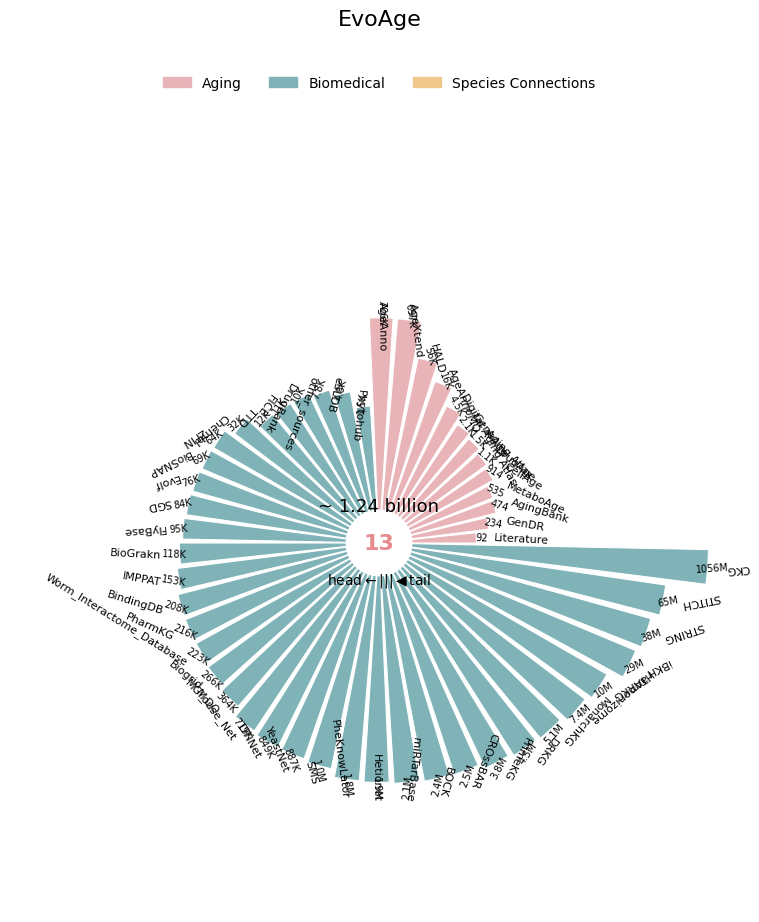

In [10]:
"""
EvoAge circular barplot (Fig 1b style) — reordered so 'Species Connections'
wedge sits before CKG, with CKG/STITCH shifted right after it.

Colors:
    Aging             -> #e8b4b8
    Biomedical/General -> #7fb3b8
    Species Connections -> #f1c88b  (override, regardless of its KG_Type)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.path import Path

# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
datasource = pd.read_csv(
    "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/EvoAge_datasource_fig1b.csv"
)

# If you have a separate Aging-side CSV, load and concat it here, e.g.:
# aging_df = pd.read_csv(".../EvoAge_aging_fig1b.csv")
# datasource = pd.concat([aging_df, datasource], ignore_index=True)

# ------------------------------------------------------------------
# 2. Reorder: pull 'Species Connections' out and place it FIRST
#    among the biomedical block (i.e. immediately before CKG),
#    everything else (CKG, STITCH, STRING, ...) keeps its order
#    and simply shifts down after it.
# ------------------------------------------------------------------
mask_species = datasource["Source"].str.strip() == "Species Connections"
species_row  = datasource[mask_species]
rest_rows    = datasource[~mask_species]

# Keep Aging rows (if present) at the very front, then Species Connections,
# then everything else in its original order.
if "KG_Type" in datasource.columns and datasource["KG_Type"].str.contains("Aging", case=False).any():
    aging_rows      = rest_rows[rest_rows["KG_Type"].str.contains("Aging", case=False)]
    biomedical_rows = rest_rows[~rest_rows["KG_Type"].str.contains("Aging", case=False)]
    datasource = pd.concat([aging_rows, species_row, biomedical_rows], ignore_index=True)
else:
    datasource = pd.concat([species_row, rest_rows], ignore_index=True)

# ------------------------------------------------------------------
# 3. Colors
# ------------------------------------------------------------------
COLOR_AGING      = "#e8b4b8"
COLOR_BIOMEDICAL = "#7fb3b8"
COLOR_SPECIES    = "#f1c88b"

def assign_color(row):
    if row["Source"].strip() == "Species Connections":
        return COLOR_SPECIES
    if "KG_Type" in row and isinstance(row["KG_Type"], str) and "aging" in row["KG_Type"].lower():
        return COLOR_AGING
    return COLOR_BIOMEDICAL

datasource["color"] = datasource.apply(assign_color, axis=1)

# ------------------------------------------------------------------
# 4. Circular (polar) barplot
# ------------------------------------------------------------------
n = len(datasource)
values = datasource["Total"].values.astype(float)
log_values = np.log10(values.clip(min=1))

# angle per wedge, small gap between bars
gap = 0.02  # radians of padding between bars
total_angle = 2 * np.pi
theta_width = (total_angle / n) - gap
theta = np.linspace(0, total_angle, n, endpoint=False) + gap / 2

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_offset(np.pi / 2)   # start at top
ax.set_theta_direction(-1)       # clockwise, matches original figure

inner_r = 1.0
bar_heights = log_values  # radial length ~ log10(Total)

bars = ax.bar(
    theta,
    bar_heights,
    width=theta_width,
    bottom=inner_r,
    color=datasource["color"],
    edgecolor="white",
    linewidth=0.8,
)

# ------------------------------------------------------------------
# 5. Value labels + rotated source-name labels
# ------------------------------------------------------------------
def format_value(v):
    if v >= 1_000_000:
        return f"{v/1_000_000:.1f}M" if v < 10_000_000 else f"{v/1_000_000:.0f}M"
    if v >= 1_000:
        return f"{v/1_000:.1f}K" if v < 10_000 else f"{v/1_000:.0f}K"
    return f"{v:.0f}"

for angle, h, val, name in zip(theta, bar_heights, values, datasource["Source"]):
    # value label at bar tip
    ax.text(
        angle, inner_r + h + 0.15, format_value(val),
        rotation=np.degrees(angle) - 90 if np.degrees(angle) < 180 else np.degrees(angle) + 90,
        rotation_mode="anchor",
        ha="center", va="center", fontsize=7,
    )
    # source name further out, rotated to follow the wedge
    rot = np.degrees(angle)
    if 90 < rot < 270:
        rot = rot + 180
        ha = "right"
    else:
        ha = "left"
    ax.text(
        angle, inner_r + h + 0.55, name,
        rotation=rot - 90, rotation_mode="anchor",
        ha=ha, va="center", fontsize=8,
    )

# ------------------------------------------------------------------
# 6. Clean up polar axes (hide default ticks/grid/spines)
# ------------------------------------------------------------------
ax.set_ylim(0, inner_r + log_values.max() + 1.2)
ax.set_yticklabels([])
ax.set_xticklabels([])
ax.grid(False)
ax.spines["polar"].set_visible(False)

# ------------------------------------------------------------------
# 7. Center annotation (counts + head/tail arrow, like original)
# ------------------------------------------------------------------
n_aging = (datasource["color"] == COLOR_AGING).sum()
n_bio   = ((datasource["color"] == COLOR_BIOMEDICAL) | (datasource["color"] == COLOR_SPECIES)).sum()
total_records = int(values.sum())

ax.text(0, 0, f"{n_aging}", ha="center", va="center",
        fontsize=16, fontweight="bold", color=COLOR_AGING.replace("b4b8","8b8f"))
ax.annotate(
    f"~ {total_records/1e9:.2f} billion",
    xy=(0.5, 0.55), xycoords="axes fraction",
    ha="center", va="center", fontsize=13,
)
ax.annotate(
    "head" + r"$\leftarrow$" + "|||" + r"$\blacktriangleleft$" + "tail",
    xy=(0.5, 0.45), xycoords="axes fraction",
    ha="center", va="center", fontsize=10,
)

# ------------------------------------------------------------------
# 8. Legend
# ------------------------------------------------------------------
legend_handles = [
    mpatches.Patch(color=COLOR_AGING, label="Aging"),
    mpatches.Patch(color=COLOR_BIOMEDICAL, label="Biomedical"),
    mpatches.Patch(color=COLOR_SPECIES, label="Species Connections"),
]
ax.legend(
    handles=legend_handles, loc="upper center",
    bbox_to_anchor=(0.5, 1.15), ncol=3, frameon=False, fontsize=10
)

fig.suptitle("EvoAge", fontsize=16, y=1.02)

plt.tight_layout()
plt.savefig("FIG1/evoage_circular_species_reordered.svg", format="svg", bbox_inches="tight")
plt.savefig("FIG1/evoage_circular_species_reordered.pdf", format="pdf", bbox_inches="tight")
plt.show()

## Fig 1 d

In [26]:
# evoage = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/EvoAge_Store_House/Stats/Species_NodeType_unique_counts.csv")
# evoage
# aging = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/Aging_Store_House/Stats/Species_NodeType_unique_counts.csv")


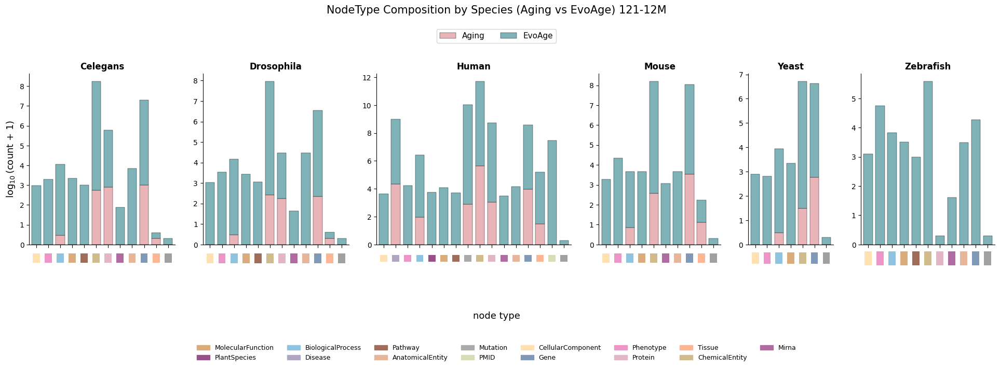

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# -----------------------------------------------------------------------------
# 1. LOAD BOTH CSVs
# -----------------------------------------------------------------------------
evoage = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/EvoAge_Store_House/Stats/Species_NodeType_unique_counts.csv")
aging = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/Aging_Store_House/Stats/Species_NodeType_unique_counts.csv")

drop_rows = ["TOTAL", "Nodes"]
evoage = evoage[~evoage["NodeType"].isin(drop_rows)]
aging = aging[~aging["NodeType"].isin(drop_rows)]

species_cols = sorted(set(evoage.columns) | set(aging.columns) - {"NodeType"})
species_cols = [c for c in species_cols if c != "NodeType"]

for col in species_cols:
    if col not in evoage.columns:
        evoage[col] = 0
    if col not in aging.columns:
        aging[col] = 0

# -----------------------------------------------------------------------------
# 2. RESHAPE TO LONG FORMAT AND MERGE
# -----------------------------------------------------------------------------
evoage_long = evoage.melt(id_vars="NodeType", value_vars=species_cols,
                           var_name="Species", value_name="Count")
evoage_long["KG_type"] = "EvoAge"

aging_long = aging.melt(id_vars="NodeType", value_vars=species_cols,
                         var_name="Species", value_name="Count")
aging_long["KG_type"] = "Aging"

plot_data = pd.concat([aging_long, evoage_long], ignore_index=True)
plot_data["LOG"] = np.log10(plot_data["Count"] + 1)

totals = plot_data.groupby(["NodeType", "Species"])["Count"].sum().reset_index()
keep = totals[totals["Count"] > 0][["NodeType", "Species"]]
plot_data = plot_data.merge(keep, on=["NodeType", "Species"])

# -----------------------------------------------------------------------------
# 3. GLOBAL NODETYPE -> COLOR MAP (matches reference image legend)
# -----------------------------------------------------------------------------
nodetype_colors = {
    "MolecularFunction": "#DAAB7B",   # molecular
    "PlantSpecies": "#985188",        # plant
    "BiologicalProcess": "#90C3E0",   # biological
    "Disease": "#B1A5C4",             # disease
    "Pathway": "#9F6D59",             # pathway
    "AnatomicalEntity": "#E7B59A",    # anatomy
    "Mutation": "#AAAAAA",            # mutation
    "PMID": "#D5DEB5",                # PMID
    "CellularComponent": "#FFE1B1",   # cellular
    "Gene": "#7F99B6",                # gene
    "Phenotype": "#EC95C6",           # phenotype
    "Protein": "#E2B6C2",             # protein
    "Tissue": "#FDB593",              # tissue
    "ChemicalEntity": "#D0BB8D",      # chemical
    "Mirna": "#B06BA0",               # (not shown in legend; kept as your previous value)
    "Species": "#A0A0A0",             # (not shown in legend; kept as your previous value)
}

custom_colors = {"Aging": "#e8b4b8ff", "EvoAge": "#7fb3b8ff"}

# -----------------------------------------------------------------------------
# 4. PLOT (faceted by species, stacked bars, colored-square x labels + ticks)
# -----------------------------------------------------------------------------
n_bars_per_species = [
    plot_data[plot_data["Species"] == sp]["NodeType"].nunique()
    for sp in species_cols
]

fig, axes = plt.subplots(
    1, len(species_cols), figsize=(24, 5.5), sharey=False,
    gridspec_kw={"width_ratios": n_bars_per_species}
)

square_size = 0.6  # size of colored square markers below axis

for ax, sp in zip(axes, species_cols):
    subset = plot_data[plot_data["Species"] == sp]
    node_types = subset["NodeType"].unique()

    aging_vals = subset[subset["KG_type"] == "Aging"].set_index("NodeType").reindex(node_types)["LOG"].fillna(0)
    evoage_vals = subset[subset["KG_type"] == "EvoAge"].set_index("NodeType").reindex(node_types)["LOG"].fillna(0)

    x = np.arange(len(node_types))

    ax.bar(x, aging_vals, color=custom_colors["Aging"], edgecolor="black",
           linewidth=0.3, width=0.75, label="Aging")
    ax.bar(x, evoage_vals, bottom=aging_vals, color=custom_colors["EvoAge"],
           edgecolor="black", linewidth=0.3, width=0.75, label="EvoAge")

    ax.set_title(sp, fontsize=12, fontweight="bold")

    # Real tick positions (so tick marks show), but blank text labels
    ax.set_xticks(x)
    ax.set_xticklabels([])
    ax.tick_params(axis="x", which="major", length=4, width=0.8, color="black")

    ax.set_xlim(-0.6, len(node_types) - 0.4)
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_position(("data", 0))

    y_min = ax.get_ylim()[0]
    y_range = ax.get_ylim()[1] - y_min
    square_y = -0.08 * y_range  # position squares just below axis/ticks

    for xi, nt in zip(x, node_types):
        color = nodetype_colors.get(nt, "#cccccc")
        rect = mpatches.Rectangle(
            (xi - square_size / 2, square_y - square_size * 0.4),
            square_size, square_size * 0.8,
            facecolor=color, edgecolor="none",
            transform=ax.transData, clip_on=False
        )
        ax.add_patch(rect)

    ax.set_ylim(y_min, ax.get_ylim()[1])

axes[0].set_ylabel(r"$\log_{10}$(count + 1)", fontsize=13)

# Shared "node type" axis label centered below all squares
fig.text(0.5, 0.02, "node type", ha="center", fontsize=13)


# Shared legend for Aging/EvoAge
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=11, bbox_to_anchor=(0.5, 1.05))

# Shared legend for NodeType colors (bottom)
nodetype_handles = [mpatches.Patch(color=c, label=nt) for nt, c in nodetype_colors.items() if nt != "Species"]
fig.legend(handles=nodetype_handles, loc="lower center", ncol=8, fontsize=9,
           bbox_to_anchor=(0.5, -0.15), frameon=False)

fig.suptitle("NodeType Composition by Species (Aging vs EvoAge) 121-12M", fontsize=15, y=1.12)

plt.subplots_adjust(bottom=0.28)

# -----------------------------------------------------------------------------
# 5. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_d_MAIN_Species_NodeType_Aging_EvoAge.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
# /storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/EvoAge_Store_House/Stats/EvoAge_121_Species_NodeType_unique_counts.csv
# 090526_EvoAge/kg_formation/species_wise_kg_building/Aging_Store_House/Stats/Aging_121_Species_NodeType_unique_counts.csv

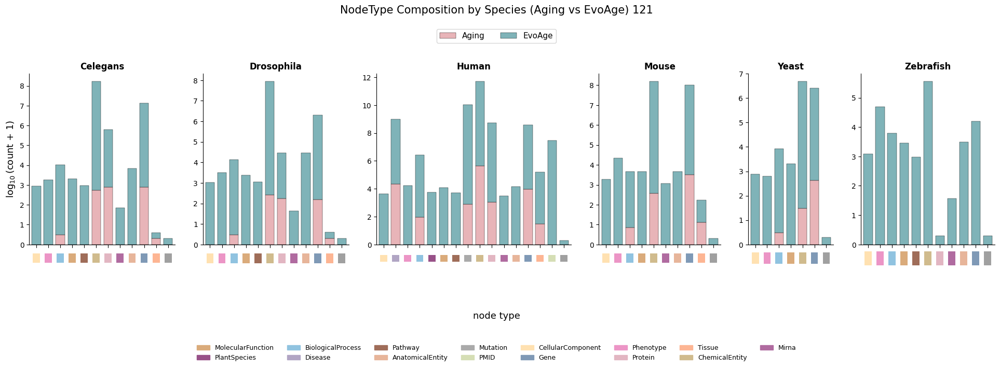

In [46]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# -----------------------------------------------------------------------------
# 1. LOAD BOTH CSVs
# -----------------------------------------------------------------------------
evoage = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/EvoAge_Store_House/Stats/EvoAge_121_Species_NodeType_unique_counts.csv")
aging = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/Aging_Store_House/Stats/Aging_121_Species_NodeType_unique_counts.csv")

drop_rows = ["TOTAL", "Nodes"]
evoage = evoage[~evoage["NodeType"].isin(drop_rows)]
aging = aging[~aging["NodeType"].isin(drop_rows)]

species_cols = sorted(set(evoage.columns) | set(aging.columns) - {"NodeType"})
species_cols = [c for c in species_cols if c != "NodeType"]

for col in species_cols:
    if col not in evoage.columns:
        evoage[col] = 0
    if col not in aging.columns:
        aging[col] = 0

# -----------------------------------------------------------------------------
# 2. RESHAPE TO LONG FORMAT AND MERGE
# -----------------------------------------------------------------------------
evoage_long = evoage.melt(id_vars="NodeType", value_vars=species_cols,
                           var_name="Species", value_name="Count")
evoage_long["KG_type"] = "EvoAge"

aging_long = aging.melt(id_vars="NodeType", value_vars=species_cols,
                         var_name="Species", value_name="Count")
aging_long["KG_type"] = "Aging"

plot_data = pd.concat([aging_long, evoage_long], ignore_index=True)
plot_data["LOG"] = np.log10(plot_data["Count"] + 1)

totals = plot_data.groupby(["NodeType", "Species"])["Count"].sum().reset_index()
keep = totals[totals["Count"] > 0][["NodeType", "Species"]]
plot_data = plot_data.merge(keep, on=["NodeType", "Species"])

# -----------------------------------------------------------------------------
# 3. GLOBAL NODETYPE -> COLOR MAP (matches reference image legend)
# -----------------------------------------------------------------------------
nodetype_colors = {
    "MolecularFunction": "#DAAB7B",  
    "PlantSpecies": "#985188",        
    "BiologicalProcess": "#90C3E0",  
    "Disease": "#B1A5C4",             # disease
    "Pathway": "#9F6D59",             # pathway
    "AnatomicalEntity": "#E7B59A",    # anatomy
    "Mutation": "#AAAAAA",            # mutation
    "PMID": "#D5DEB5",                # PMID
    "CellularComponent": "#FFE1B1",   # cellular
    "Gene": "#7F99B6",                # gene
    "Phenotype": "#EC95C6",           # phenotype
    "Protein": "#E2B6C2",             # protein
    "Tissue": "#FDB593",              # tissue
    "ChemicalEntity": "#D0BB8D",      # chemical
    "Mirna": "#B06BA0",              
    "Species": "#A0A0A0",            
}

custom_colors = {"Aging": "#e8b4b8ff", "EvoAge": "#7fb3b8ff"}

# -----------------------------------------------------------------------------
# 4. PLOT (faceted by species, stacked bars, colored-square x labels + ticks)
# -----------------------------------------------------------------------------
n_bars_per_species = [
    plot_data[plot_data["Species"] == sp]["NodeType"].nunique()
    for sp in species_cols
]

fig, axes = plt.subplots(
    1, len(species_cols), figsize=(24, 5.5), sharey=False,
    gridspec_kw={"width_ratios": n_bars_per_species}
)

square_size = 0.6  # size of colored square markers below axis

for ax, sp in zip(axes, species_cols):
    subset = plot_data[plot_data["Species"] == sp]
    node_types = subset["NodeType"].unique()

    aging_vals = subset[subset["KG_type"] == "Aging"].set_index("NodeType").reindex(node_types)["LOG"].fillna(0)
    evoage_vals = subset[subset["KG_type"] == "EvoAge"].set_index("NodeType").reindex(node_types)["LOG"].fillna(0)

    x = np.arange(len(node_types))

    ax.bar(x, aging_vals, color=custom_colors["Aging"], edgecolor="black",
           linewidth=0.3, width=0.75, label="Aging")
    ax.bar(x, evoage_vals, bottom=aging_vals, color=custom_colors["EvoAge"],
           edgecolor="black", linewidth=0.3, width=0.75, label="EvoAge")

    ax.set_title(sp, fontsize=12, fontweight="bold")

    # Real tick positions (so tick marks show), but blank text labels
    ax.set_xticks(x)
    ax.set_xticklabels([])
    ax.tick_params(axis="x", which="major", length=4, width=0.8, color="black")

    ax.set_xlim(-0.6, len(node_types) - 0.4)
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_position(("data", 0))

    y_min = ax.get_ylim()[0]
    y_range = ax.get_ylim()[1] - y_min
    square_y = -0.08 * y_range  # position squares just below axis/ticks

    for xi, nt in zip(x, node_types):
        color = nodetype_colors.get(nt, "#cccccc")
        rect = mpatches.Rectangle(
            (xi - square_size / 2, square_y - square_size * 0.4),
            square_size, square_size * 0.8,
            facecolor=color, edgecolor="none",
            transform=ax.transData, clip_on=False
        )
        ax.add_patch(rect)

    ax.set_ylim(y_min, ax.get_ylim()[1])

axes[0].set_ylabel(r"$\log_{10}$(count + 1)", fontsize=13)

# Shared "node type" axis label centered below all squares
fig.text(0.5, 0.02, "node type", ha="center", fontsize=13)

# Shared legend for Aging/EvoAge
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=11, bbox_to_anchor=(0.5, 1.05))

# Shared legend for NodeType colors (bottom)
nodetype_handles = [mpatches.Patch(color=c, label=nt) for nt, c in nodetype_colors.items() if nt != "Species"]
fig.legend(handles=nodetype_handles, loc="lower center", ncol=8, fontsize=9,
           bbox_to_anchor=(0.5, -0.15), frameon=False)

fig.suptitle("NodeType Composition by Species (Aging vs EvoAge) 121", fontsize=15, y=1.12)

plt.subplots_adjust(bottom=0.28)

# -----------------------------------------------------------------------------
# 5. SAVE AS PDF

plt.savefig("FIG1/Fig1_d_SUPP_Species_NodeType_Aging_EvoAge_main.pdf", format="pdf", bbox_inches="tight")
plt.show()

## Fig 1e

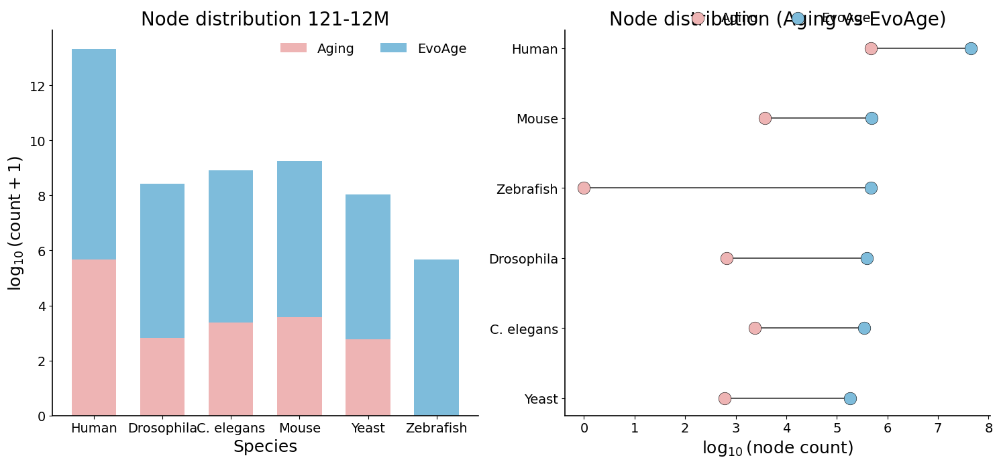

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
evoage = pd.read_csv(
    "/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/EvoAge_Store_House/Stats/Species_NodeType_unique_counts.csv"
)
aging = pd.read_csv(
    "/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/Aging_Store_House/Stats/Species_NodeType_unique_counts.csv"
)

# -----------------------------------------------------------------------------
# 2. EXTRACT TOTAL ROW
# -----------------------------------------------------------------------------
evo_total = evoage.loc[evoage["NodeType"] == "TOTAL"].iloc[0].drop("NodeType")
aging_total = aging.loc[aging["NodeType"] == "TOTAL"].iloc[0].drop("NodeType")

evo_total = pd.to_numeric(evo_total, errors="coerce")
aging_total = pd.to_numeric(aging_total, errors="coerce")

species_order = [
    "Human",
    "Drosophila",
    "Celegans",
    "Mouse",
    "Yeast",
    "Zebrafish",
]

raw_data = pd.DataFrame({
    "Species": species_order,
    "Aging": [aging_total.get(s, 0) for s in species_order],
    "EvoAge": [evo_total.get(s, 0) for s in species_order],
})

raw_data["Aging"] = pd.to_numeric(raw_data["Aging"], errors="coerce").fillna(0)
raw_data["EvoAge"] = pd.to_numeric(raw_data["EvoAge"], errors="coerce").fillna(0)

raw_data["Species"] = raw_data["Species"].replace({"Celegans": "C. elegans"})

# -----------------------------------------------------------------------------
# 3. PREPARE DATA
# -----------------------------------------------------------------------------
plot_data = raw_data.melt(
    id_vars="Species",
    value_vars=["Aging", "EvoAge"],
    var_name="Category",
    value_name="Count"
)

species_labels = [
    "Human",
    "Drosophila",
    "C. elegans",
    "Mouse",
    "Yeast",
    "Zebrafish",
]

plot_data["Species"] = pd.Categorical(plot_data["Species"], categories=species_labels, ordered=True)
plot_data["Category"] = pd.Categorical(plot_data["Category"], categories=["Aging", "EvoAge"], ordered=True)
plot_data["Count"] = pd.to_numeric(plot_data["Count"], errors="coerce").fillna(0)
plot_data["log_count"] = np.log10(plot_data["Count"] + 1)

pivot = (
    plot_data.pivot(index="Species", columns="Category", values="log_count")
    .loc[species_labels]
)

# -----------------------------------------------------------------------------
# 4. PLOT — 2 SUBPLOTS: stacked bar + lollipop
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "EvoAge": "#7ebcdb"}

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 7))

# =============================================================================
# LEFT: STACKED BAR
# =============================================================================
bottom = np.zeros(len(pivot))
for cat in ["Aging", "EvoAge"]:
    ax.bar(
        pivot.index,
        pivot[cat],
        bottom=bottom,
        width=0.65,
        color=colors[cat],
        edgecolor="none",
        label=cat,
    )
    bottom += pivot[cat].values

ax.set_title("Node distribution 121-12M", fontsize=20)
ax.set_xlabel("Species", fontsize=18)
ax.set_ylabel(r"$\log_{10}(\mathrm{count}+1)$", fontsize=18)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis="x", labelsize=14)
ax.tick_params(axis="y", labelsize=14)
ax.legend(frameon=False, fontsize=14, ncol=2, loc="upper right")

# =============================================================================
# RIGHT: LOLLIPOP — Aging vs EvoAge per species
# =============================================================================
# Order y-axis so Human is on top (descending by EvoAge)
lolli_data = pivot.sort_values("EvoAge", ascending=True)
y = np.arange(len(lolli_data))

# Horizontal connecting lines
for i, sp in enumerate(lolli_data.index):
    ax2.plot(
        [lolli_data.loc[sp, "Aging"], lolli_data.loc[sp, "EvoAge"]],
        [i, i],
        color="#4a4a4a", linewidth=1.3, zorder=1,
    )

# Dots
ax2.scatter(lolli_data["Aging"], y, color=colors["Aging"],
            s=180, edgecolor="black", linewidth=0.4, zorder=3, label="Aging")
ax2.scatter(lolli_data["EvoAge"], y, color=colors["EvoAge"],
            s=180, edgecolor="black", linewidth=0.4, zorder=3, label="EvoAge")

ax2.set_yticks(y)
ax2.set_yticklabels(lolli_data.index, fontsize=14)
ax2.set_xlabel(r"$\log_{10}(\mathrm{node\ count})$", fontsize=18)
ax2.set_title("Node distribution (Aging vs EvoAge)", fontsize=20)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_linewidth(1.2)
ax2.spines["bottom"].set_linewidth(1.2)
ax2.tick_params(axis="x", labelsize=14)
ax2.tick_params(axis="y", labelsize=14)
ax2.legend(frameon=False, fontsize=14, ncol=2, loc="upper center",
           bbox_to_anchor=(0.5, 1.08))

plt.tight_layout()

# -----------------------------------------------------------------------------
# 5. SAVE
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_e_main.pdf", dpi=300, bbox_inches="tight")
plt.show()

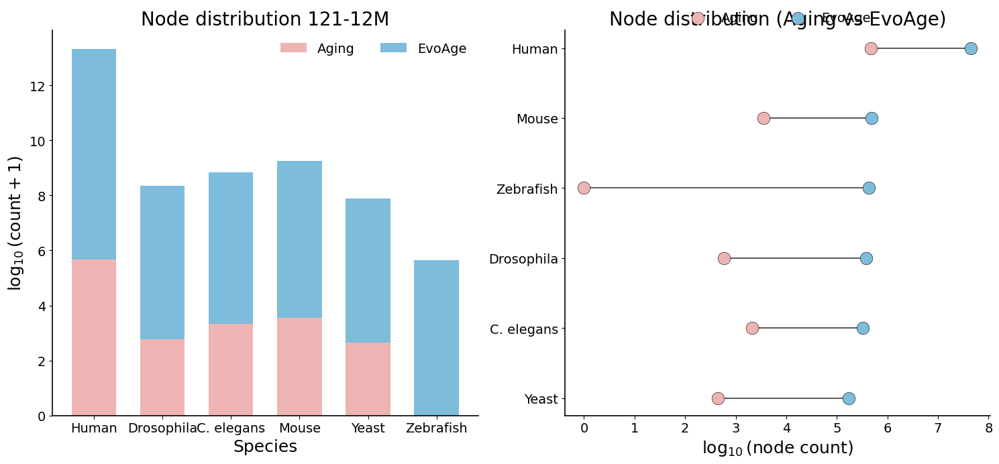

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------


evoage = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/EvoAge_Store_House/Stats/EvoAge_121_Species_NodeType_unique_counts.csv")
aging = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/species_wise_kg_building/Aging_Store_House/Stats/Aging_121_Species_NodeType_unique_counts.csv")


# -----------------------------------------------------------------------------
# 2. EXTRACT TOTAL ROW
# -----------------------------------------------------------------------------
evo_total = evoage.loc[evoage["NodeType"] == "TOTAL"].iloc[0].drop("NodeType")
aging_total = aging.loc[aging["NodeType"] == "TOTAL"].iloc[0].drop("NodeType")

evo_total = pd.to_numeric(evo_total, errors="coerce")
aging_total = pd.to_numeric(aging_total, errors="coerce")

species_order = [
    "Human",
    "Drosophila",
    "Celegans",
    "Mouse",
    "Yeast",
    "Zebrafish",
]

raw_data = pd.DataFrame({
    "Species": species_order,
    "Aging": [aging_total.get(s, 0) for s in species_order],
    "EvoAge": [evo_total.get(s, 0) for s in species_order],
})

raw_data["Aging"] = pd.to_numeric(raw_data["Aging"], errors="coerce").fillna(0)
raw_data["EvoAge"] = pd.to_numeric(raw_data["EvoAge"], errors="coerce").fillna(0)

raw_data["Species"] = raw_data["Species"].replace({"Celegans": "C. elegans"})

# -----------------------------------------------------------------------------
# 3. PREPARE DATA
# -----------------------------------------------------------------------------
plot_data = raw_data.melt(
    id_vars="Species",
    value_vars=["Aging", "EvoAge"],
    var_name="Category",
    value_name="Count"
)

species_labels = [
    "Human",
    "Drosophila",
    "C. elegans",
    "Mouse",
    "Yeast",
    "Zebrafish",
]

plot_data["Species"] = pd.Categorical(plot_data["Species"], categories=species_labels, ordered=True)
plot_data["Category"] = pd.Categorical(plot_data["Category"], categories=["Aging", "EvoAge"], ordered=True)
plot_data["Count"] = pd.to_numeric(plot_data["Count"], errors="coerce").fillna(0)
plot_data["log_count"] = np.log10(plot_data["Count"] + 1)

pivot = (
    plot_data.pivot(index="Species", columns="Category", values="log_count")
    .loc[species_labels]
)

# -----------------------------------------------------------------------------
# 4. PLOT — 2 SUBPLOTS: stacked bar + lollipop
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "EvoAge": "#7ebcdb"}

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 7))

# =============================================================================
# LEFT: STACKED BAR
# =============================================================================
bottom = np.zeros(len(pivot))
for cat in ["Aging", "EvoAge"]:
    ax.bar(
        pivot.index,
        pivot[cat],
        bottom=bottom,
        width=0.65,
        color=colors[cat],
        edgecolor="none",
        label=cat,
    )
    bottom += pivot[cat].values

ax.set_title("Node distribution 121-12M", fontsize=20)
ax.set_xlabel("Species", fontsize=18)
ax.set_ylabel(r"$\log_{10}(\mathrm{count}+1)$", fontsize=18)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis="x", labelsize=14)
ax.tick_params(axis="y", labelsize=14)
ax.legend(frameon=False, fontsize=14, ncol=2, loc="upper right")

# =============================================================================
# RIGHT: LOLLIPOP — Aging vs EvoAge per species
# =============================================================================
# Order y-axis so Human is on top (descending by EvoAge)
lolli_data = pivot.sort_values("EvoAge", ascending=True)
y = np.arange(len(lolli_data))

# Horizontal connecting lines
for i, sp in enumerate(lolli_data.index):
    ax2.plot(
        [lolli_data.loc[sp, "Aging"], lolli_data.loc[sp, "EvoAge"]],
        [i, i],
        color="#4a4a4a", linewidth=1.3, zorder=1,
    )

# Dots
ax2.scatter(lolli_data["Aging"], y, color=colors["Aging"],
            s=180, edgecolor="black", linewidth=0.4, zorder=3, label="Aging")
ax2.scatter(lolli_data["EvoAge"], y, color=colors["EvoAge"],
            s=180, edgecolor="black", linewidth=0.4, zorder=3, label="EvoAge")

ax2.set_yticks(y)
ax2.set_yticklabels(lolli_data.index, fontsize=14)
ax2.set_xlabel(r"$\log_{10}(\mathrm{node\ count})$", fontsize=18)
ax2.set_title("Node distribution (Aging vs EvoAge)", fontsize=20)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_linewidth(1.2)
ax2.spines["bottom"].set_linewidth(1.2)
ax2.tick_params(axis="x", labelsize=14)
ax2.tick_params(axis="y", labelsize=14)
ax2.legend(frameon=False, fontsize=14, ncol=2, loc="upper center",
           bbox_to_anchor=(0.5, 1.08))

plt.tight_layout()

plt.savefig("FIG1/Fig1_e_supp.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Fig 1f 

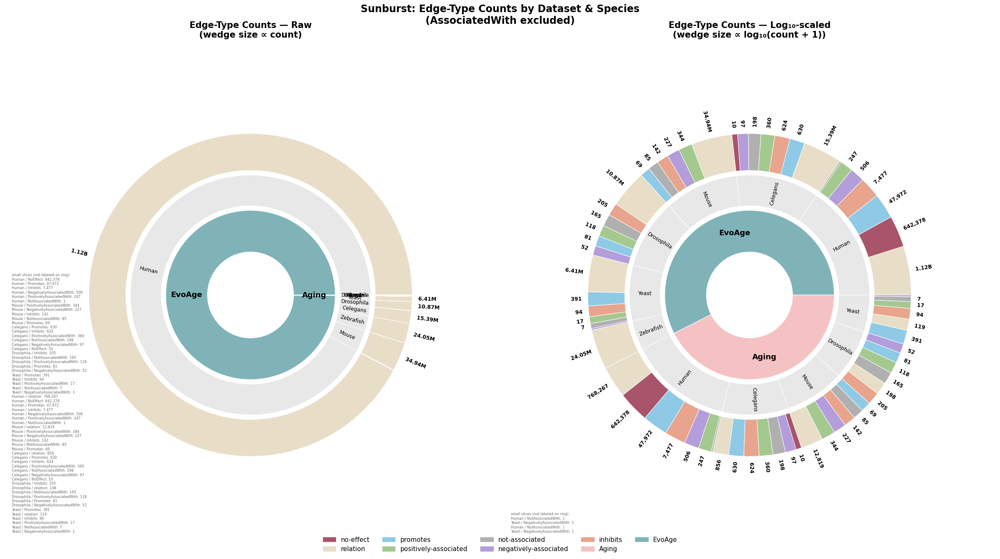

,Relation,Species,count,edge_type,dataset,log
0,PMID_Tissue,Human,303745858,relation,EvoAge,8.48251
1,PMID_Protein,Human,237058221,relation,EvoAge,8.37486
2,PMID_Disease,Human,192843423,relation,EvoAge,8.2852
3,PMID_CellularComponent,Human,87097962,relation,EvoAge,7.94001
4,Protein_Protein,Human,58025729,relation,EvoAge,7.76362


In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

# -----------------------------------------------------------------------------
# 1. LOAD & PREP
# -----------------------------------------------------------------------------
df = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Edgetype.csv")

# Remove AssociatedWith rows
df = df[df["edge_type"] != "AssociatedWith"].reset_index(drop=True)

df["log"] = np.log10(df["count"] + 1)

def format_count(n):
    if n >= 1_000_000_000:
        return f"{n/1_000_000_000:.2f}B"
    elif n >= 1_000_000:
        return f"{n/1_000_000:.2f}M"
    elif n >= 1_000:
        return f"{n:,.0f}"
    return str(int(n))

# -----------------------------------------------------------------------------
# 2. COLOR MAPS
# -----------------------------------------------------------------------------
dataset_colors = {"Aging": "#f4c2c2", "EvoAge": "#7fb3b8"}
species_colors = {sp: "#e8e8e8" for sp in
                  ["Human", "Yeast", "Celegans", "Drosophila", "Zebrafish", "Mouse"]}

edge_colors = {
    "NoEffect":                 "#a8546b",
    "relation":                 "#e8ddc7",
    "Promotes":                 "#8ecae6",
    "PositivelyAssociatedWith": "#a3c98f",
    "NotAssociatedWith":        "#b0b0b0",
    "NegativelyAssociatedWith": "#b39ddb",
    "Inhibits":                 "#e8a48c",
    # AssociatedWith intentionally excluded
}
edge_legend_labels = {
    "NoEffect":                 "no-effect",
    "relation":                 "relation",
    "Promotes":                 "promotes",
    "PositivelyAssociatedWith": "positively-associated",
    "NotAssociatedWith":        "not-associated",
    "NegativelyAssociatedWith": "negatively-associated",
    "Inhibits":                 "inhibits",
}

# -----------------------------------------------------------------------------
# 3. ANGLE ASSIGNMENT
#    Single global transform applied ONCE at the leaf level, then aggregated
#    bottom-up by plain summation for every parent level (dataset, Species).
#    This is deliberately NOT "renormalize independently at every level" --
#    doing that compounds distortion (a leaf gets log-compressed once at the
#    species level, then AGAIN at the edge_type level, so cross-species /
#    cross-edge_type comparisons stop meaning anything). Here there is exactly
#    one log transform and one normalization (divide by the grand total), so a
#    parent's wedge width is just the sum of its children's already-final
#    angles -- consistent all the way up, like a normal linear nested donut.
# -----------------------------------------------------------------------------
def assign_angles(data, group_cols, value_col="count", log_scale=False):
    # 1. aggregate down to one row per leaf combination (e.g. dataset+Species+edge_type)
    leaf = data.groupby(group_cols, sort=False)[value_col].sum().reset_index()
    leaf["weight"] = np.log10(leaf[value_col] + 1) if log_scale else leaf[value_col].astype(float)

    # 2. determine display order top-down (purely for visual grouping: which
    #    species/edge_type block comes first), ranking each level by its own
    #    total weight -- but this only decides ORDER, not the final angle math
    def order_rows(sub, cols):
        if not cols:
            return sub
        col = cols[0]
        totals = sub.groupby(col, sort=False)["weight"].sum().sort_values(ascending=False)
        return pd.concat([order_rows(sub[sub[col] == key], cols[1:]) for key in totals.index])

    leaf = order_rows(leaf, group_cols)

    # 3. single global normalization -> final leaf angles (one log, one divide, done)
    total = leaf["weight"].sum()
    leaf["angle_end"]   = leaf["weight"].cumsum() / total * 360
    leaf["angle_start"] = leaf["angle_end"] - leaf["weight"] / total * 360

    # 4. parent-level boundaries = min/max of their own children's angles
    #    (i.e. bottom-up sum, not a fresh log/renormalization at this level)
    for i, col in enumerate(group_cols):
        key_cols = group_cols[:i + 1]   # disambiguates repeated names (e.g. "Human" under both datasets)
        leaf[f"{col}_start"] = leaf.groupby(key_cols, sort=False)["angle_start"].transform("min")
        leaf[f"{col}_end"]   = leaf.groupby(key_cols, sort=False)["angle_end"].transform("max")

    return leaf

# -----------------------------------------------------------------------------
# 4. DRAWING HELPERS
# -----------------------------------------------------------------------------
r_hole    = 0.28
r_dataset = (r_hole, 0.55)
r_species = (0.58, 0.78)
r_edge    = (0.81, 1.05)
r_label   = 1.09

def draw_wedge(ax, t1, t2, r_inner, r_outer, color, edgecolor="white", lw=0.8):
    if t2 - t1 <= 0:
        return
    w = mpatches.Wedge((0, 0), r_outer, t1, t2, width=r_outer - r_inner,
                        facecolor=color, edgecolor=edgecolor, linewidth=lw)
    ax.add_patch(w)

def draw_sunburst(ax, df, title):
    # ── Ring 1: dataset ──────────────────────────────────────────────────────
    for dataset, grp in df.groupby("dataset", sort=False):
        t1 = grp["dataset_start"].iloc[0]
        t2 = grp["dataset_end"].iloc[0]
        draw_wedge(ax, t1, t2, r_dataset[0], r_dataset[1],
                   dataset_colors.get(dataset, "#cccccc"))
        mid = np.deg2rad((t1 + t2) / 2)
        r_t = (r_dataset[0] + r_dataset[1]) / 2
        ax.text(r_t * np.cos(mid), r_t * np.sin(mid), dataset,
                ha="center", va="center", fontsize=13, fontweight="bold")

    # ── Ring 2: species ───────────────────────────────────────────────────────
    for (dataset, sp), grp in df.groupby(["dataset", "Species"], sort=False):
        t1 = grp["Species_start"].iloc[0]
        t2 = grp["Species_end"].iloc[0]
        draw_wedge(ax, t1, t2, r_species[0], r_species[1],
                   species_colors.get(sp, "#e8e8e8"))
        mid_deg = (t1 + t2) / 2
        mid     = np.deg2rad(mid_deg)
        r_t     = (r_species[0] + r_species[1]) / 2
        norm    = mid_deg % 360
        rot     = mid_deg + 180 if 90 < norm < 270 else mid_deg
        ax.text(r_t * np.cos(mid), r_t * np.sin(mid), sp,
                ha="center", va="center", fontsize=9,
                rotation=rot, rotation_mode="anchor")

    # ── Ring 3: edge_type ─────────────────────────────────────────────────────
    for _, row in df.iterrows():
        t1, t2 = row["angle_start"], row["angle_end"]
        color  = edge_colors.get(row["edge_type"], "#cccccc")
        draw_wedge(ax, t1, t2, r_edge[0], r_edge[1], color)

    # ── Outer count labels ────────────────────────────────────────────────────
    # IMPORTANT: multiple raw rows can share the same edge_type wedge (e.g. many
    # different relation sub-types all rolled into the single "relation" wedge),
    # and they all share the same angle_start/angle_end. Looping over raw rows
    # here would draw one label per underlying row, all stacked at the same
    # midpoint -> garbled overlapping digits. Aggregate to one label per wedge first.
    label_df = (df.groupby(["Species", "edge_type", "angle_start", "angle_end"], sort=False)
                  ["count"].sum().reset_index())

    MIN_LABEL_DEG = 1.5
    skipped = []
    for _, row in label_df.iterrows():
        t1, t2 = row["angle_start"], row["angle_end"]
        if t2 - t1 <= 0:
            continue
        if (t2 - t1) < MIN_LABEL_DEG:
            skipped.append((row.get("Species", ""), row["edge_type"], row["count"]))
            continue
        mid_deg   = (t1 + t2) / 2
        mid       = np.deg2rad(mid_deg)
        norm      = mid_deg % 360
        rot       = mid_deg + 180 if 90 < norm < 270 else mid_deg
        ha        = "right"     if 90 < norm < 270 else "left"
        ax.text(r_label * np.cos(mid), r_label * np.sin(mid),
                format_count(row["count"]),
                ha=ha, va="center", fontsize=9, fontweight="bold", color="black",
                rotation=rot, rotation_mode="anchor",
                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

    # list skipped (too-thin-to-label) values in the corner so the exact
    # numbers are still available, just not crammed onto the wedge
    if skipped:
        lines = [f"{sp} / {et}: {format_count(c)}" for sp, et, c in skipped]
        ax.text(-1.55, -1.55, "small slices (not labeled on ring):\n" + "\n".join(lines),
                ha="left", va="bottom", fontsize=6, color="dimgray")

    ax.set_xlim(-1.6, 1.6)
    ax.set_ylim(-1.6, 1.6)
    ax.axis("off")
    ax.set_title(title, fontsize=15, fontweight="bold", pad=20)

# -----------------------------------------------------------------------------
# 5. BUILD BOTH DATAFRAMES
# -----------------------------------------------------------------------------
df_raw = assign_angles(df.copy(), ["dataset", "Species", "edge_type"], value_col="count", log_scale=False)
df_log = assign_angles(df.copy(), ["dataset", "Species", "edge_type"], value_col="count", log_scale=True)

# -----------------------------------------------------------------------------
# 6. PLOT — two side-by-side sunbursts
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(24, 13),
                          subplot_kw={"aspect": "equal"})

draw_sunburst(axes[0], df_raw,
              "Edge-Type Counts — Raw\n(wedge size ∝ count)")
draw_sunburst(axes[1], df_log,
              "Edge-Type Counts — Log₁₀-scaled\n(wedge size ∝ log₁₀(count + 1))")

# shared legend
legend_handles = [
    mpatches.Patch(color=c, label=edge_legend_labels.get(k, k))
    for k, c in edge_colors.items()
]
legend_handles += [
    mpatches.Patch(color=c, label=k)
    for k, c in dataset_colors.items()
]
fig.legend(handles=legend_handles, loc="lower center", ncol=5,
           fontsize=11, bbox_to_anchor=(0.5, -0.01), frameon=False)

fig.suptitle("Sunburst: Edge-Type Counts by Dataset & Species\n(AssociatedWith excluded)",
             fontsize=17, fontweight="bold", y=1.01)

plt.tight_layout()
plt.savefig("FIG1/Fig1_f_sunburst_raw_vs_log.pdf", format="pdf", bbox_inches="tight")
plt.savefig("FIG1/Fig1_f_sunburst_raw_vs_log.png", dpi=200, bbox_inches="tight")
plt.show()
df.head()

## Fig 1g

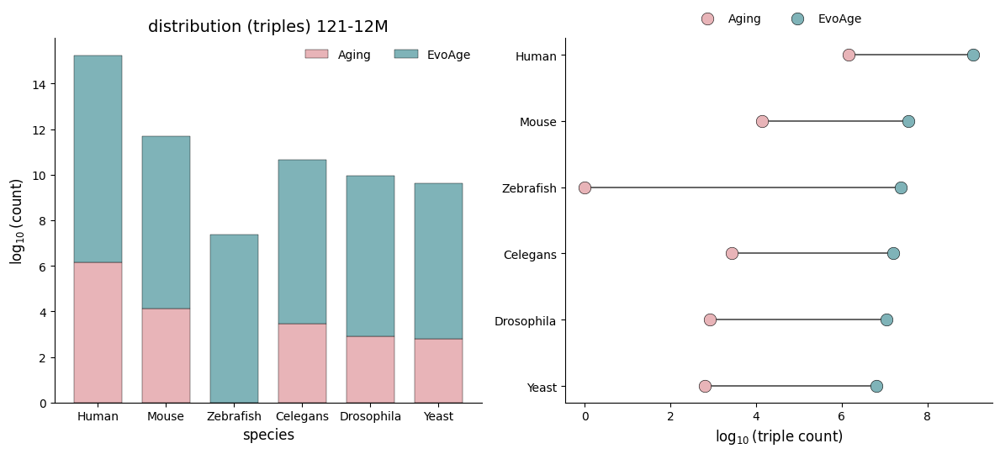

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
df = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Fig_1g.csv")

# Order species by EvoAge count (descending) — matches your reference image
df = df.sort_values("EvoAge_121_12M", ascending=False).reset_index(drop=True)

df["Aging_log"] = np.log10(df["Aging_121_12M"] + 1)
df["EvoAge_log"] = np.log10(df["EvoAge_121_12M"] + 1)

# -----------------------------------------------------------------------------
# 2. COLORS
# -----------------------------------------------------------------------------
colors = {"Aging": "#e8b4b8", "EvoAge": "#7fb3b8"}

# -----------------------------------------------------------------------------
# 3. FIGURE WITH 2 SUBPLOTS
# -----------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))

# =============================================================================
# PLOT g: STACKED BAR — distribution (triples)
# =============================================================================
x = np.arange(len(df))
width = 0.7

ax1.bar(x, df["Aging_log"], width=width, color=colors["Aging"],
        edgecolor="black", linewidth=0.3, label="Aging")
ax1.bar(x, df["EvoAge_log"], bottom=df["Aging_log"], width=width,
        color=colors["EvoAge"], edgecolor="black", linewidth=0.3, label="EvoAge")

ax1.set_xticks(x)
ax1.set_xticklabels(df["species"], fontsize=10)
ax1.set_ylabel(r"$\log_{10}$(count)", fontsize=12)
ax1.set_xlabel("species", fontsize=12)
ax1.set_title("distribution (triples) 121-12M", fontsize=14)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(False)
ax1.legend(loc="upper right", frameon=False, fontsize=10, ncol=2)

# =============================================================================
# PLOT (lollipop): Aging vs EvoAge per species
# =============================================================================
# Sort so Human is on top (matches your reference)
df_lolli = df.sort_values("EvoAge_log", ascending=True).reset_index(drop=True)
y = np.arange(len(df_lolli))

# Horizontal connecting lines
for i, row in df_lolli.iterrows():
    ax2.plot(
        [row["Aging_log"], row["EvoAge_log"]],
        [i, i],
        color="#4a4a4a", linewidth=1.2, zorder=1
    )

# Aging dots
ax2.scatter(df_lolli["Aging_log"], y, color=colors["Aging"],
            s=110, edgecolor="black", linewidth=0.4, zorder=3, label="Aging")
# EvoAge dots
ax2.scatter(df_lolli["EvoAge_log"], y, color=colors["EvoAge"],
            s=110, edgecolor="black", linewidth=0.4, zorder=3, label="EvoAge")

ax2.set_yticks(y)
ax2.set_yticklabels(df_lolli["species"], fontsize=10)
ax2.set_xlabel(r"$\log_{10}$(triple count)", fontsize=12)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(False)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, 1.10),
           ncol=2, frameon=False, fontsize=10)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. SAVE BOTH IN ONE PDF
# -----------------------------------------------------------------------------
plt.savefig("Fig1_g_Main_distribution_lollipop.pdf", format="pdf", bbox_inches="tight")
plt.show()

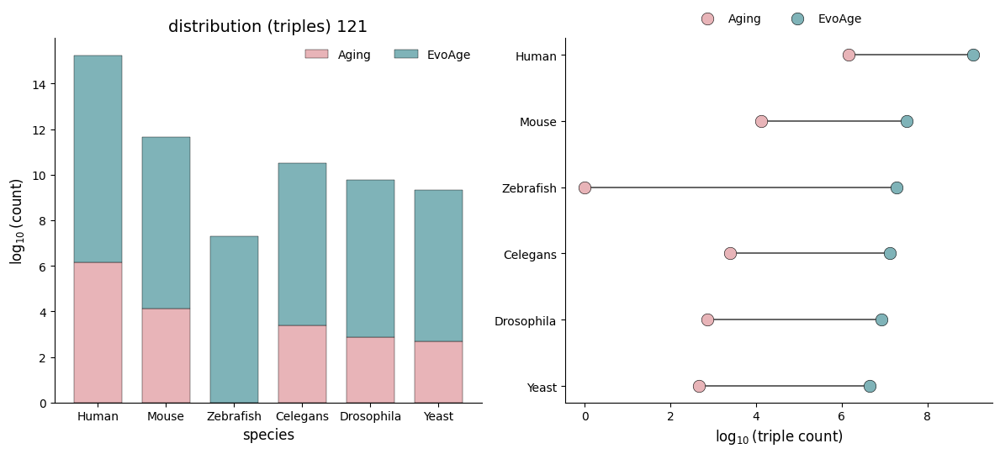

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
df = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Fig_1g_supp.csv")

# Order species by EvoAge count (descending) — matches your reference image
df = df.sort_values("EvoAge_121", ascending=False).reset_index(drop=True)

df["Aging_log"] = np.log10(df["Aging_121"] + 1)
df["EvoAge_log"] = np.log10(df["EvoAge_121"] + 1)

# -----------------------------------------------------------------------------
# 2. COLORS
# -----------------------------------------------------------------------------
colors = {"Aging": "#e8b4b8", "EvoAge": "#7fb3b8"}

# -----------------------------------------------------------------------------
# 3. FIGURE WITH 2 SUBPLOTS
# -----------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))

# =============================================================================
# PLOT g: STACKED BAR — distribution (triples)
# =============================================================================
x = np.arange(len(df))
width = 0.7

ax1.bar(x, df["Aging_log"], width=width, color=colors["Aging"],
        edgecolor="black", linewidth=0.3, label="Aging")
ax1.bar(x, df["EvoAge_log"], bottom=df["Aging_log"], width=width,
        color=colors["EvoAge"], edgecolor="black", linewidth=0.3, label="EvoAge")

ax1.set_xticks(x)
ax1.set_xticklabels(df["species"], fontsize=10)
ax1.set_ylabel(r"$\log_{10}$(count)", fontsize=12)
ax1.set_xlabel("species", fontsize=12)
ax1.set_title("distribution (triples) 121", fontsize=14)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(False)
ax1.legend(loc="upper right", frameon=False, fontsize=10, ncol=2)

# =============================================================================
# PLOT (lollipop): Aging vs EvoAge per species
# =============================================================================
# Sort so Human is on top (matches your reference)
df_lolli = df.sort_values("EvoAge_log", ascending=True).reset_index(drop=True)
y = np.arange(len(df_lolli))

# Horizontal connecting lines
for i, row in df_lolli.iterrows():
    ax2.plot(
        [row["Aging_log"], row["EvoAge_log"]],
        [i, i],
        color="#4a4a4a", linewidth=1.2, zorder=1
    )

# Aging dots
ax2.scatter(df_lolli["Aging_log"], y, color=colors["Aging"],
            s=110, edgecolor="black", linewidth=0.4, zorder=3, label="Aging")
# EvoAge dots
ax2.scatter(df_lolli["EvoAge_log"], y, color=colors["EvoAge"],
            s=110, edgecolor="black", linewidth=0.4, zorder=3, label="EvoAge")

ax2.set_yticks(y)
ax2.set_yticklabels(df_lolli["species"], fontsize=10)
ax2.set_xlabel(r"$\log_{10}$(triple count)", fontsize=12)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(False)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, 1.10),
           ncol=2, frameon=False, fontsize=10)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. SAVE BOTH IN ONE PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_g_Supp_distribution_lollipop.pdf", format="pdf", bbox_inches="tight")
plt.show()

## Fig 1h

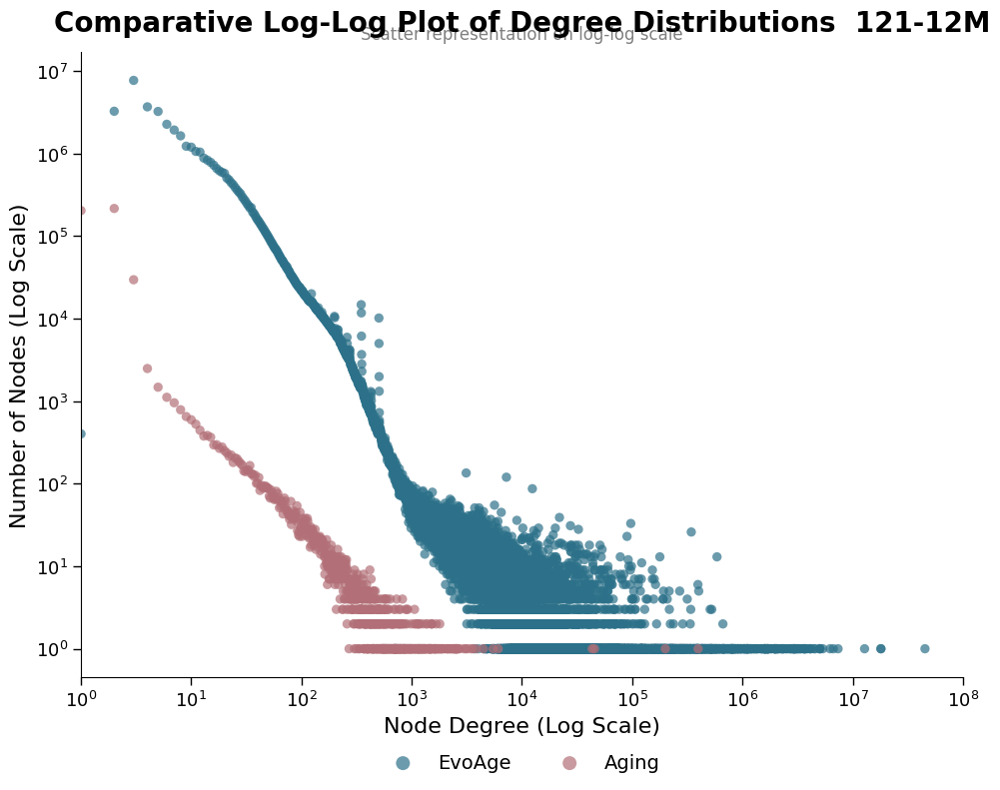

In [10]:
# /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_degree.csv
# /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_degree.csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_degree.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_degree.csv"

aging  = pd.read_csv(aging_path)
evoage = pd.read_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. BUILD DEGREE DISTRIBUTION: count nodes at each total_degree value
# -----------------------------------------------------------------------------
def to_distribution(df, model_name):
    dist = (
        df["total_degree"]
        .value_counts()
        .rename_axis("degree")
        .reset_index(name="num_nodes")
    )
    dist["Model"] = model_name
    return dist

aging_dist  = to_distribution(aging,  "Aging")
evoage_dist = to_distribution(evoage, "EvoAge")

data_long = pd.concat([evoage_dist, aging_dist], ignore_index=True)
data_long = data_long[(data_long["degree"] > 0) & (data_long["num_nodes"] > 0)]

# -----------------------------------------------------------------------------
# 3. PLOT (log-log scatter)
# -----------------------------------------------------------------------------
colors = {"EvoAge": "#2c7189", "Aging": "#b26f77"}

fig, ax = plt.subplots(figsize=(10, 8))

for model in ["EvoAge", "Aging"]:
    subset = data_long[data_long["Model"] == model]
    ax.scatter(
        subset["degree"], subset["num_nodes"],
        color=colors[model], s=45, alpha=0.7,
        edgecolor="none", label=model,
    )

ax.set_xscale("log")
ax.set_yscale("log")

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=15))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=15))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"$10^{{{int(np.log10(x))}}}$"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"$10^{{{int(np.log10(x))}}}$"))

# Auto-fit x limits to actual data (in case max degree > 1e5)
max_deg = data_long["degree"].max()
ax.set_xlim(1, 10 ** np.ceil(np.log10(max_deg)))

ax.set_title("Comparative Log-Log Plot of Degree Distributions  121-12M",
             fontsize=20, fontweight="bold", pad=15)
ax.text(0.5, 1.02, "Scatter representation on log-log scale",
        transform=ax.transAxes, ha="center", fontsize=12, color="gray")
ax.set_xlabel("Node Degree (Log Scale)", fontsize=16)
ax.set_ylabel("Number of Nodes (Log Scale)", fontsize=16)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="both", which="major", length=6, width=1, color="black", labelsize=13)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False, which="major")
ax.grid(False, which="minor")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.18),
          ncol=2, frameon=False, fontsize=14, markerscale=1.5)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_h_main.pdf", format="pdf", bbox_inches="tight")
plt.show()

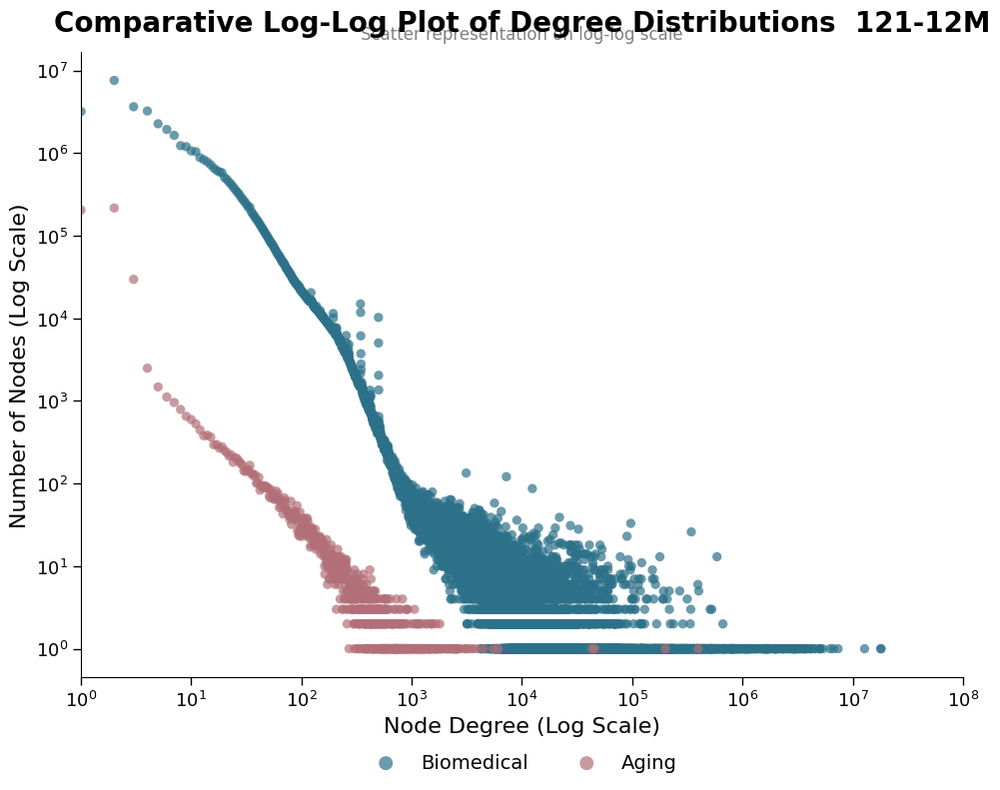

In [4]:
# /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_degree.csv
# /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_degree.csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_degree.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Biomedical_121_12M/Biomedical_121_12M_degree.csv"

aging  = pd.read_csv(aging_path)
evoage = pd.read_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. BUILD DEGREE DISTRIBUTION: count nodes at each total_degree value
# -----------------------------------------------------------------------------
def to_distribution(df, model_name):
    dist = (
        df["total_degree"]
        .value_counts()
        .rename_axis("degree")
        .reset_index(name="num_nodes")
    )
    dist["Model"] = model_name
    return dist

aging_dist  = to_distribution(aging,  "Aging")
evoage_dist = to_distribution(evoage, "Biomedical")

data_long = pd.concat([evoage_dist, aging_dist], ignore_index=True)
data_long = data_long[(data_long["degree"] > 0) & (data_long["num_nodes"] > 0)]

# -----------------------------------------------------------------------------
# 3. PLOT (log-log scatter)
# -----------------------------------------------------------------------------
colors = {"Biomedical": "#2c7189", "Aging": "#b26f77"}

fig, ax = plt.subplots(figsize=(10, 8))

for model in ["Biomedical", "Aging"]:
    subset = data_long[data_long["Model"] == model]
    ax.scatter(
        subset["degree"], subset["num_nodes"],
        color=colors[model], s=45, alpha=0.7,
        edgecolor="none", label=model,
    )

ax.set_xscale("log")
ax.set_yscale("log")

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=15))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=15))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"$10^{{{int(np.log10(x))}}}$"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"$10^{{{int(np.log10(x))}}}$"))

# Auto-fit x limits to actual data (in case max degree > 1e5)
max_deg = data_long["degree"].max()
ax.set_xlim(1, 10 ** np.ceil(np.log10(max_deg)))

ax.set_title("Comparative Log-Log Plot of Degree Distributions  121-12M",
             fontsize=20, fontweight="bold", pad=15)
ax.text(0.5, 1.02, "Scatter representation on log-log scale",
        transform=ax.transAxes, ha="center", fontsize=12, color="gray")
ax.set_xlabel("Node Degree (Log Scale)", fontsize=16)
ax.set_ylabel("Number of Nodes (Log Scale)", fontsize=16)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="both", which="major", length=6, width=1, color="black", labelsize=13)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False, which="major")
ax.grid(False, which="minor")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.18),
          ncol=2, frameon=False, fontsize=14, markerscale=1.5)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/aging-biomedical-degree.pdf", format="pdf", bbox_inches="tight")
plt.show()

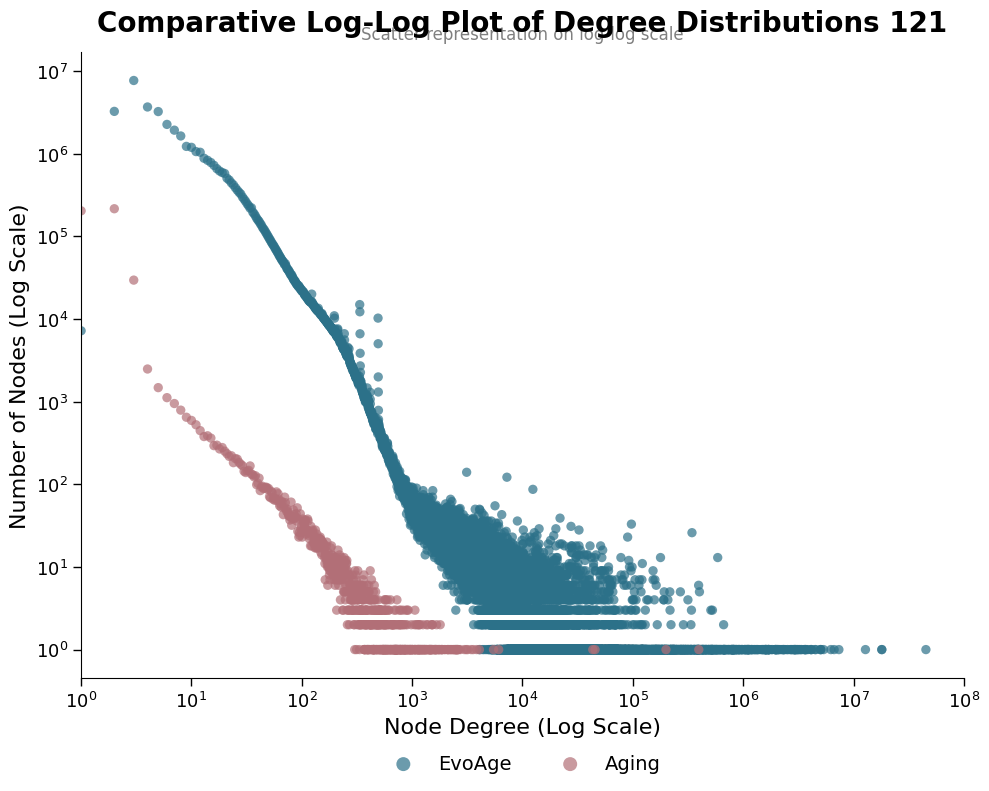

In [9]:
# /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_degree.csv
# /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_degree.csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121/Aging_121_degree.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121/EvoAge_121_degree.csv"

aging  = pd.read_csv(aging_path)
evoage = pd.read_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. BUILD DEGREE DISTRIBUTION: count nodes at each total_degree value
# -----------------------------------------------------------------------------
def to_distribution(df, model_name):
    dist = (
        df["total_degree"]
        .value_counts()
        .rename_axis("degree")
        .reset_index(name="num_nodes")
    )
    dist["Model"] = model_name
    return dist

aging_dist  = to_distribution(aging,  "Aging")
evoage_dist = to_distribution(evoage, "EvoAge")

data_long = pd.concat([evoage_dist, aging_dist], ignore_index=True)
data_long = data_long[(data_long["degree"] > 0) & (data_long["num_nodes"] > 0)]

# -----------------------------------------------------------------------------
# 3. PLOT (log-log scatter)
# -----------------------------------------------------------------------------
colors = {"EvoAge": "#2c7189", "Aging": "#b26f77"}

fig, ax = plt.subplots(figsize=(10, 8))

for model in ["EvoAge", "Aging"]:
    subset = data_long[data_long["Model"] == model]
    ax.scatter(
        subset["degree"], subset["num_nodes"],
        color=colors[model], s=45, alpha=0.7,
        edgecolor="none", label=model,
    )

ax.set_xscale("log")
ax.set_yscale("log")

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=15))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=15))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"$10^{{{int(np.log10(x))}}}$"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"$10^{{{int(np.log10(x))}}}$"))

# Auto-fit x limits to actual data (in case max degree > 1e5)
max_deg = data_long["degree"].max()
ax.set_xlim(1, 10 ** np.ceil(np.log10(max_deg)))

ax.set_title("Comparative Log-Log Plot of Degree Distributions 121",
             fontsize=20, fontweight="bold", pad=15)
ax.text(0.5, 1.02, "Scatter representation on log-log scale",
        transform=ax.transAxes, ha="center", fontsize=12, color="gray")
ax.set_xlabel("Node Degree (Log Scale)", fontsize=16)
ax.set_ylabel("Number of Nodes (Log Scale)", fontsize=16)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="both", which="major", length=6, width=1, color="black", labelsize=13)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False, which="major")
ax.grid(False, which="minor")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.18),
          ncol=2, frameon=False, fontsize=14, markerscale=1.5)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_h_Supp.pdf", format="pdf", bbox_inches="tight")
plt.show()

## FIg i

In [ ]:
/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_betweenness_centrality_sorted.csv
/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_betweenness_centrality_sorted.csv

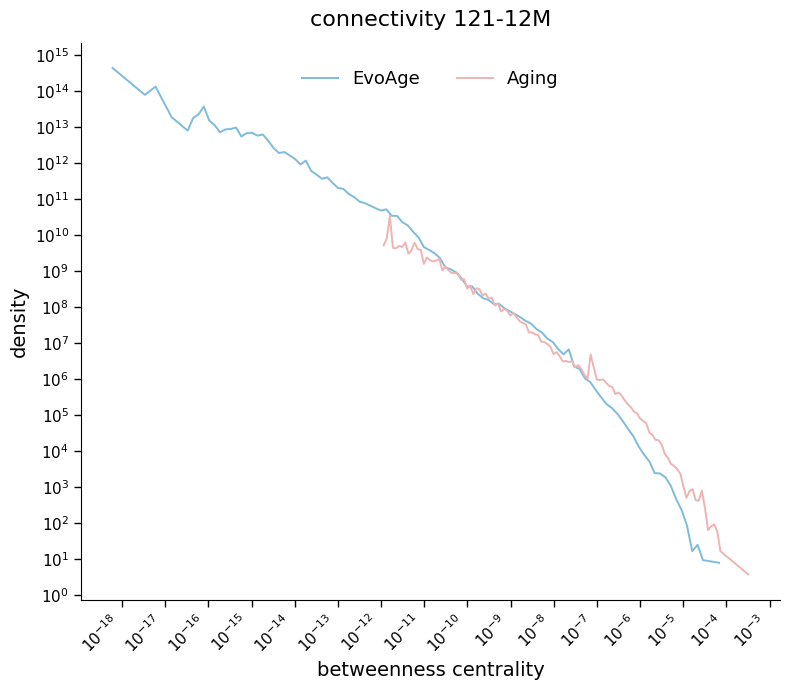

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_betweenness_centrality_sorted.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_betweenness_centrality_sorted.csv"

df_aging  = pd.read_csv(aging_path)
df_evoage = pd.read_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. CONFIG
# -----------------------------------------------------------------------------
TARGET_ROWS = 2_000_000
NBINS_PDF   = 120
SEED        = 42

# -----------------------------------------------------------------------------
# 3. HELPERS
# -----------------------------------------------------------------------------
def positive_vec(x, min_positive=1e-12):
    """Keep only finite, positive values (required for log-scale)."""
    x = pd.to_numeric(x, errors="coerce").to_numpy()
    x = x[np.isfinite(x)]
    x = x[x > 0]
    return x if len(x) else np.array([min_positive])

def log_binned_pdf(arr, nbins=120):
    """Width-corrected PDF using log-spaced bins."""
    lo, hi = arr.min(), arr.max()
    if hi <= lo:
        return np.array([hi]), np.array([1.0])
    bins = np.logspace(np.log10(lo), np.log10(hi), nbins + 1)
    counts, edges = np.histogram(arr, bins=bins)
    widths = np.diff(edges)
    total = counts.sum()
    pdf = np.where(widths > 0, (counts / total) / widths, 0)
    centers = np.sqrt(edges[:-1] * edges[1:])   # geometric mean of bin edges
    # keep only bins with non-zero density (log axis can't plot 0)
    mask = pdf > 0
    return centers[mask], pdf[mask]

# -----------------------------------------------------------------------------
# 4. PREP
# -----------------------------------------------------------------------------
# Subsample EvoAge if too large (matches R's TARGET_ROWS = 2e6 on df2)
if len(df_evoage) > TARGET_ROWS:
    df_evoage = df_evoage.sample(n=TARGET_ROWS, random_state=SEED)

a_aging  = positive_vec(df_aging["betweenness_centrality"])
a_evoage = positive_vec(df_evoage["betweenness_centrality"])

x_aging,  y_aging  = log_binned_pdf(a_aging,  NBINS_PDF)
x_evoage, y_evoage = log_binned_pdf(a_evoage, NBINS_PDF)

# -----------------------------------------------------------------------------
# 5. PLOT
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "EvoAge": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(x_evoage, y_evoage, color=colors["EvoAge"], linewidth=1.4, label="EvoAge")
ax.plot(x_aging,  y_aging,  color=colors["Aging"],  linewidth=1.4, label="Aging")

ax.set_xscale("log")
ax.set_yscale("log")

# 10^n tick formatting
def sci_fmt(x, _):
    return f"$10^{{{int(np.log10(x))}}}$"

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(sci_fmt))

# Labels
ax.set_title("connectivity 121-12M", fontsize=16, pad=12)
ax.set_xlabel("betweenness centrality", fontsize=14)
ax.set_ylabel("density", fontsize=14)

# Rotate x tick labels a bit (matches your reference image)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# Clean minimal look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", length=5, width=1, color="black", labelsize=11)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False)

# Legend top-center inside plot
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98),
          ncol=2, frameon=False, fontsize=13)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 6. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_j_main.pdf", format="pdf", bbox_inches="tight")
plt.show()

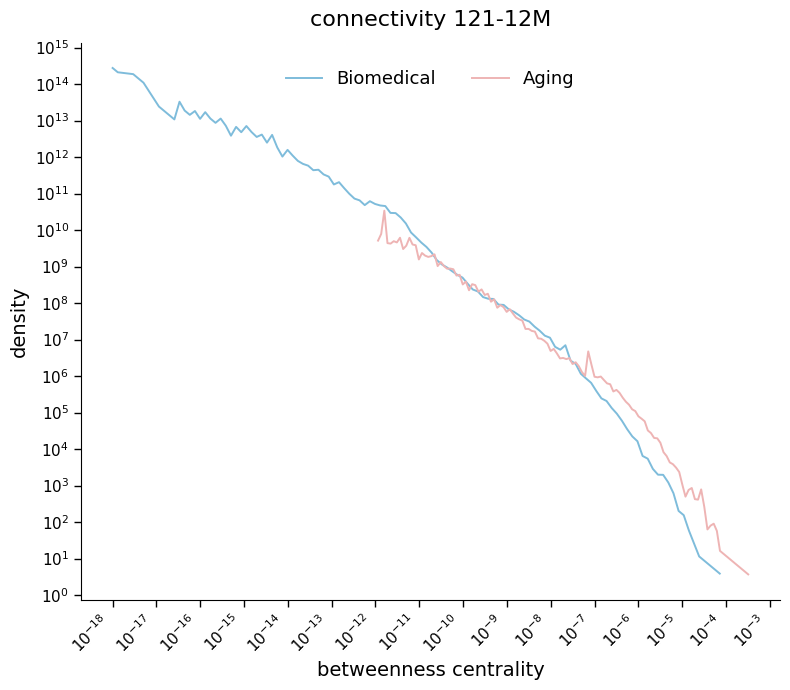

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_betweenness_centrality_sorted.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Biomedical_121_12M/Biomedical_121_12M_betweenness_centrality_sorted.csv"

df_aging  = pd.read_csv(aging_path)
df_evoage = pd.read_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. CONFIG
# -----------------------------------------------------------------------------
TARGET_ROWS = 2_000_000
NBINS_PDF   = 120
SEED        = 42

# -----------------------------------------------------------------------------
# 3. HELPERS
# -----------------------------------------------------------------------------
def positive_vec(x, min_positive=1e-12):
    """Keep only finite, positive values (required for log-scale)."""
    x = pd.to_numeric(x, errors="coerce").to_numpy()
    x = x[np.isfinite(x)]
    x = x[x > 0]
    return x if len(x) else np.array([min_positive])

def log_binned_pdf(arr, nbins=120):
    """Width-corrected PDF using log-spaced bins."""
    lo, hi = arr.min(), arr.max()
    if hi <= lo:
        return np.array([hi]), np.array([1.0])
    bins = np.logspace(np.log10(lo), np.log10(hi), nbins + 1)
    counts, edges = np.histogram(arr, bins=bins)
    widths = np.diff(edges)
    total = counts.sum()
    pdf = np.where(widths > 0, (counts / total) / widths, 0)
    centers = np.sqrt(edges[:-1] * edges[1:])   # geometric mean of bin edges
    # keep only bins with non-zero density (log axis can't plot 0)
    mask = pdf > 0
    return centers[mask], pdf[mask]

# -----------------------------------------------------------------------------
# 4. PREP
# -----------------------------------------------------------------------------
# Subsample EvoAge if too large (matches R's TARGET_ROWS = 2e6 on df2)
if len(df_evoage) > TARGET_ROWS:
    df_evoage = df_evoage.sample(n=TARGET_ROWS, random_state=SEED)

a_aging  = positive_vec(df_aging["betweenness_centrality"])
a_evoage = positive_vec(df_evoage["betweenness_centrality"])

x_aging,  y_aging  = log_binned_pdf(a_aging,  NBINS_PDF)
x_evoage, y_evoage = log_binned_pdf(a_evoage, NBINS_PDF)

# -----------------------------------------------------------------------------
# 5. PLOT
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "Biomedical": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(x_evoage, y_evoage, color=colors["Biomedical"], linewidth=1.4, label="Biomedical")
ax.plot(x_aging,  y_aging,  color=colors["Aging"],  linewidth=1.4, label="Aging")

ax.set_xscale("log")
ax.set_yscale("log")

# 10^n tick formatting
def sci_fmt(x, _):
    return f"$10^{{{int(np.log10(x))}}}$"

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(sci_fmt))

# Labels
ax.set_title("connectivity 121-12M", fontsize=16, pad=12)
ax.set_xlabel("betweenness centrality", fontsize=14)
ax.set_ylabel("density", fontsize=14)

# Rotate x tick labels a bit (matches your reference image)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# Clean minimal look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", length=5, width=1, color="black", labelsize=11)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False)

# Legend top-center inside plot
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98),
          ncol=2, frameon=False, fontsize=13)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 6. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/aging-biomedical-centrality.pdf", format="pdf", bbox_inches="tight")
plt.show()

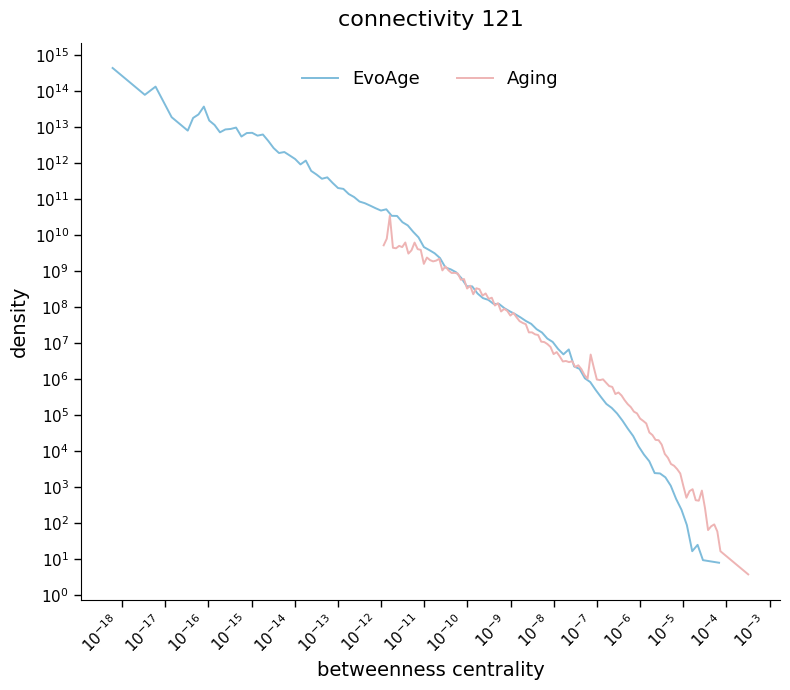

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_betweenness_centrality_sorted.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_betweenness_centrality_sorted.csv"

df_aging  = pd.read_csv(aging_path)
df_evoage = pd.read_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. CONFIG
# -----------------------------------------------------------------------------
TARGET_ROWS = 2_000_000
NBINS_PDF   = 120
SEED        = 42

# -----------------------------------------------------------------------------
# 3. HELPERS
# -----------------------------------------------------------------------------
def positive_vec(x, min_positive=1e-12):
    """Keep only finite, positive values (required for log-scale)."""
    x = pd.to_numeric(x, errors="coerce").to_numpy()
    x = x[np.isfinite(x)]
    x = x[x > 0]
    return x if len(x) else np.array([min_positive])

def log_binned_pdf(arr, nbins=120):
    """Width-corrected PDF using log-spaced bins."""
    lo, hi = arr.min(), arr.max()
    if hi <= lo:
        return np.array([hi]), np.array([1.0])
    bins = np.logspace(np.log10(lo), np.log10(hi), nbins + 1)
    counts, edges = np.histogram(arr, bins=bins)
    widths = np.diff(edges)
    total = counts.sum()
    pdf = np.where(widths > 0, (counts / total) / widths, 0)
    centers = np.sqrt(edges[:-1] * edges[1:])   # geometric mean of bin edges
    # keep only bins with non-zero density (log axis can't plot 0)
    mask = pdf > 0
    return centers[mask], pdf[mask]

# -----------------------------------------------------------------------------
# 4. PREP
# -----------------------------------------------------------------------------
# Subsample EvoAge if too large (matches R's TARGET_ROWS = 2e6 on df2)
if len(df_evoage) > TARGET_ROWS:
    df_evoage = df_evoage.sample(n=TARGET_ROWS, random_state=SEED)

a_aging  = positive_vec(df_aging["betweenness_centrality"])
a_evoage = positive_vec(df_evoage["betweenness_centrality"])

x_aging,  y_aging  = log_binned_pdf(a_aging,  NBINS_PDF)
x_evoage, y_evoage = log_binned_pdf(a_evoage, NBINS_PDF)

# -----------------------------------------------------------------------------
# 5. PLOT
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "EvoAge": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(x_evoage, y_evoage, color=colors["EvoAge"], linewidth=1.4, label="EvoAge")
ax.plot(x_aging,  y_aging,  color=colors["Aging"],  linewidth=1.4, label="Aging")

ax.set_xscale("log")
ax.set_yscale("log")

# 10^n tick formatting
def sci_fmt(x, _):
    return f"$10^{{{int(np.log10(x))}}}$"

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(sci_fmt))

# Labels
ax.set_title("connectivity 121", fontsize=16, pad=12)
ax.set_xlabel("betweenness centrality", fontsize=14)
ax.set_ylabel("density", fontsize=14)

# Rotate x tick labels a bit (matches your reference image)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# Clean minimal look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", length=5, width=1, color="black", labelsize=11)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False)

# Legend top-center inside plot
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98),
          ncol=2, frameon=False, fontsize=13)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 6. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_j_supp.pdf", format="pdf", bbox_inches="tight")
plt.show()

## Fig 1j

In [ ]:
/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_louvain_partitions.csv
/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_louvain_partitions.csv


=== Summary ===
Aging   | Nodes: 472,833 | Communities: 100 | Largest: 78.71% | Entropy: 0.815
EvoAge  | Nodes: 45,555,534 | Communities: 311 | Largest: 35.17% | Entropy: 2.046



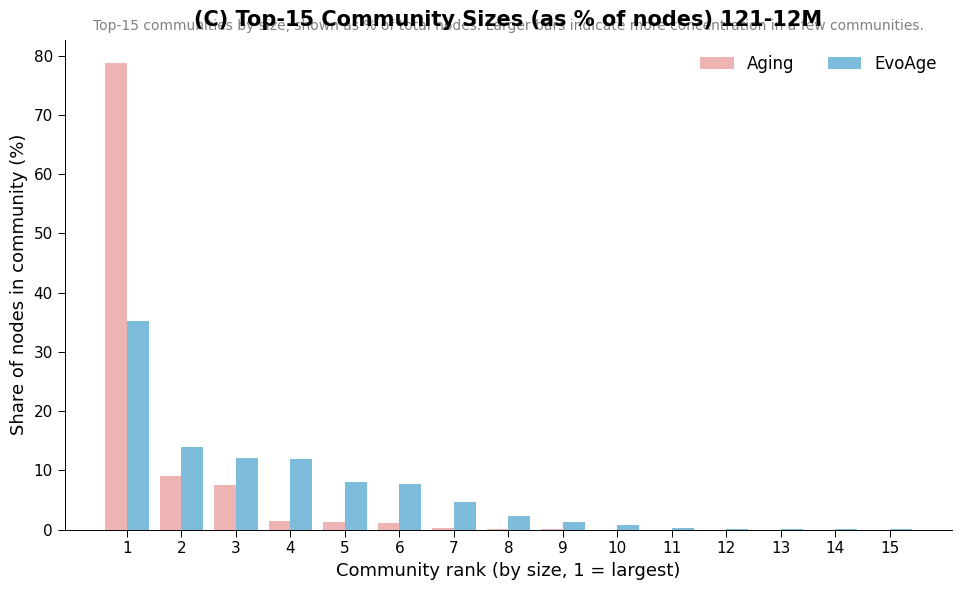

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_louvain_partitions.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_louvain_partitions.csv"

def read_louvain_csv(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.lower()
    if not {"vertex", "partition"}.issubset(df.columns):
        raise ValueError(f"Expected 'vertex' and 'partition' columns in {path}, got {list(df.columns)}")
    return df[["vertex", "partition"]]

aging_raw  = read_louvain_csv(aging_path)
evoage_raw = read_louvain_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. COMMUNITY SIZE TABLES
# -----------------------------------------------------------------------------
def community_sizes(df):
    return (
        df.groupby("partition")
          .size()
          .reset_index(name="size")
          .sort_values("size", ascending=False)
          .reset_index(drop=True)
    )

aging_sizes  = community_sizes(aging_raw)
evoage_sizes = community_sizes(evoage_raw)

N_aging  = len(aging_raw)
N_evoage = len(evoage_raw)

# -----------------------------------------------------------------------------
# 3. QUICK STATS (mirrors R's cat block)
# -----------------------------------------------------------------------------
def entropy(sizes):
    p = sizes / sizes.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log(p)))

print("\n=== Summary ===")
print(f"Aging   | Nodes: {N_aging:,} | Communities: {len(aging_sizes):,} | "
      f"Largest: {100*aging_sizes['size'].max()/N_aging:.2f}% | "
      f"Entropy: {entropy(aging_sizes['size'].values):.3f}")
print(f"EvoAge  | Nodes: {N_evoage:,} | Communities: {len(evoage_sizes):,} | "
      f"Largest: {100*evoage_sizes['size'].max()/N_evoage:.2f}% | "
      f"Entropy: {entropy(evoage_sizes['size'].values):.3f}\n")

# -----------------------------------------------------------------------------
# 4. TOP-K COMMUNITIES
# -----------------------------------------------------------------------------
K = 15

top_aging = aging_sizes.head(K).copy()
top_aging["rank"]  = np.arange(1, len(top_aging) + 1)
top_aging["pct"]   = 100 * top_aging["size"] / N_aging
top_aging["graph"] = "Aging"

top_evoage = evoage_sizes.head(K).copy()
top_evoage["rank"]  = np.arange(1, len(top_evoage) + 1)
top_evoage["pct"]   = 100 * top_evoage["size"] / N_evoage
top_evoage["graph"] = "EvoAge"

top_df = pd.concat([top_aging, top_evoage], ignore_index=True)

# -----------------------------------------------------------------------------
# 5. PLOT — grouped bar chart
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "EvoAge": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(10, 6))

ranks = np.arange(1, K + 1)
width = 0.4

aging_vals  = top_df[top_df["graph"] == "Aging"].set_index("rank").reindex(ranks)["pct"].fillna(0)
evoage_vals = top_df[top_df["graph"] == "EvoAge"].set_index("rank").reindex(ranks)["pct"].fillna(0)

ax.bar(ranks - width/2, aging_vals,  width=width, color=colors["Aging"],  label="Aging",
       edgecolor="none")
ax.bar(ranks + width/2, evoage_vals, width=width, color=colors["EvoAge"], label="EvoAge",
       edgecolor="none")

ax.set_xticks(ranks)
ax.set_xticklabels(ranks, fontsize=11)

ax.set_title(f"(C) Top-{K} Community Sizes (as % of nodes) 121-12M",
             fontsize=15, fontweight="bold", pad=10)
ax.text(0.5, 1.02,
        f"Top-{K} communities by size, shown as % of total nodes. "
        "Larger bars indicate more concentration in a few communities.",
        transform=ax.transAxes, ha="center", fontsize=10, color="gray")

ax.set_xlabel("Community rank (by size, 1 = largest)", fontsize=13)
ax.set_ylabel("Share of nodes in community (%)", fontsize=13)

# theme_classic-ish
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(0.7)
ax.spines["bottom"].set_linewidth(0.7)
ax.tick_params(axis="both", which="major", length=5, width=0.7, color="black", labelsize=11)
ax.grid(False)

ax.legend(loc="upper right", frameon=False, fontsize=12, ncol=2)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 6. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/fig1_i_main.pdf", format="pdf", bbox_inches="tight")
plt.show()


=== Summary ===
Aging   | Nodes: 472,833 | Communities: 100 | Largest: 78.71% | Entropy: 0.815
Biomedical  | Nodes: 45,228,611 | Communities: 3,223 | Largest: 26.07% | Entropy: 2.310



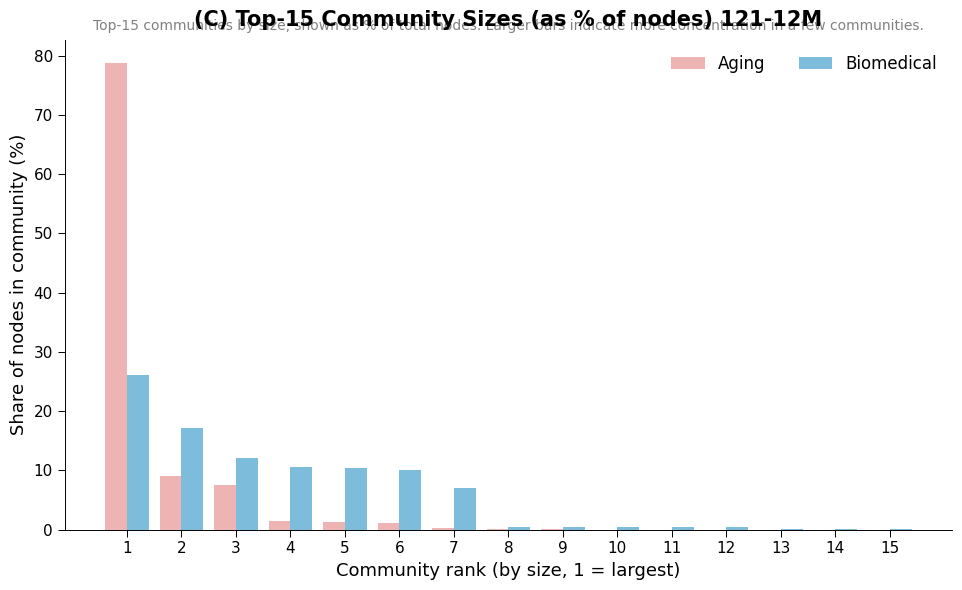

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M/Aging_121_12M_louvain_partitions.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Biomedical_121_12M/Biomedical_121_12M_louvain_partitions.csv"

def read_louvain_csv(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.lower()
    if not {"vertex", "partition"}.issubset(df.columns):
        raise ValueError(f"Expected 'vertex' and 'partition' columns in {path}, got {list(df.columns)}")
    return df[["vertex", "partition"]]

aging_raw  = read_louvain_csv(aging_path)
evoage_raw = read_louvain_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. COMMUNITY SIZE TABLES
# -----------------------------------------------------------------------------
def community_sizes(df):
    return (
        df.groupby("partition")
          .size()
          .reset_index(name="size")
          .sort_values("size", ascending=False)
          .reset_index(drop=True)
    )

aging_sizes  = community_sizes(aging_raw)
evoage_sizes = community_sizes(evoage_raw)

N_aging  = len(aging_raw)
N_evoage = len(evoage_raw)

# -----------------------------------------------------------------------------
# 3. QUICK STATS (mirrors R's cat block)
# -----------------------------------------------------------------------------
def entropy(sizes):
    p = sizes / sizes.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log(p)))

print("\n=== Summary ===")
print(f"Aging   | Nodes: {N_aging:,} | Communities: {len(aging_sizes):,} | "
      f"Largest: {100*aging_sizes['size'].max()/N_aging:.2f}% | "
      f"Entropy: {entropy(aging_sizes['size'].values):.3f}")
print(f"Biomedical  | Nodes: {N_evoage:,} | Communities: {len(evoage_sizes):,} | "
      f"Largest: {100*evoage_sizes['size'].max()/N_evoage:.2f}% | "
      f"Entropy: {entropy(evoage_sizes['size'].values):.3f}\n")

# -----------------------------------------------------------------------------
# 4. TOP-K COMMUNITIES
# -----------------------------------------------------------------------------
K = 15

top_aging = aging_sizes.head(K).copy()
top_aging["rank"]  = np.arange(1, len(top_aging) + 1)
top_aging["pct"]   = 100 * top_aging["size"] / N_aging
top_aging["graph"] = "Aging"

top_evoage = evoage_sizes.head(K).copy()
top_evoage["rank"]  = np.arange(1, len(top_evoage) + 1)
top_evoage["pct"]   = 100 * top_evoage["size"] / N_evoage
top_evoage["graph"] = "Biomedical"

top_df = pd.concat([top_aging, top_evoage], ignore_index=True)

# -----------------------------------------------------------------------------
# 5. PLOT — grouped bar chart
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "Biomedical": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(10, 6))

ranks = np.arange(1, K + 1)
width = 0.4

aging_vals  = top_df[top_df["graph"] == "Aging"].set_index("rank").reindex(ranks)["pct"].fillna(0)
evoage_vals = top_df[top_df["graph"] == "Biomedical"].set_index("rank").reindex(ranks)["pct"].fillna(0)

ax.bar(ranks - width/2, aging_vals,  width=width, color=colors["Aging"],  label="Aging",
       edgecolor="none")
ax.bar(ranks + width/2, evoage_vals, width=width, color=colors["Biomedical"], label="Biomedical",
       edgecolor="none")

ax.set_xticks(ranks)
ax.set_xticklabels(ranks, fontsize=11)

ax.set_title(f"(C) Top-{K} Community Sizes (as % of nodes) 121-12M",
             fontsize=15, fontweight="bold", pad=10)
ax.text(0.5, 1.02,
        f"Top-{K} communities by size, shown as % of total nodes. "
        "Larger bars indicate more concentration in a few communities.",
        transform=ax.transAxes, ha="center", fontsize=10, color="gray")

ax.set_xlabel("Community rank (by size, 1 = largest)", fontsize=13)
ax.set_ylabel("Share of nodes in community (%)", fontsize=13)

# theme_classic-ish
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(0.7)
ax.spines["bottom"].set_linewidth(0.7)
ax.tick_params(axis="both", which="major", length=5, width=0.7, color="black", labelsize=11)
ax.grid(False)

ax.legend(loc="upper right", frameon=False, fontsize=12, ncol=2)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 6. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/aging-biomedical-commmunity.pdf", format="pdf", bbox_inches="tight")
plt.show()


=== Summary ===
Aging   | Nodes: 472,614 | Communities: 100 | Largest: 78.74% | Entropy: 0.814
EvoAge  | Nodes: 45,555,531 | Communities: 297 | Largest: 36.46% | Entropy: 1.879



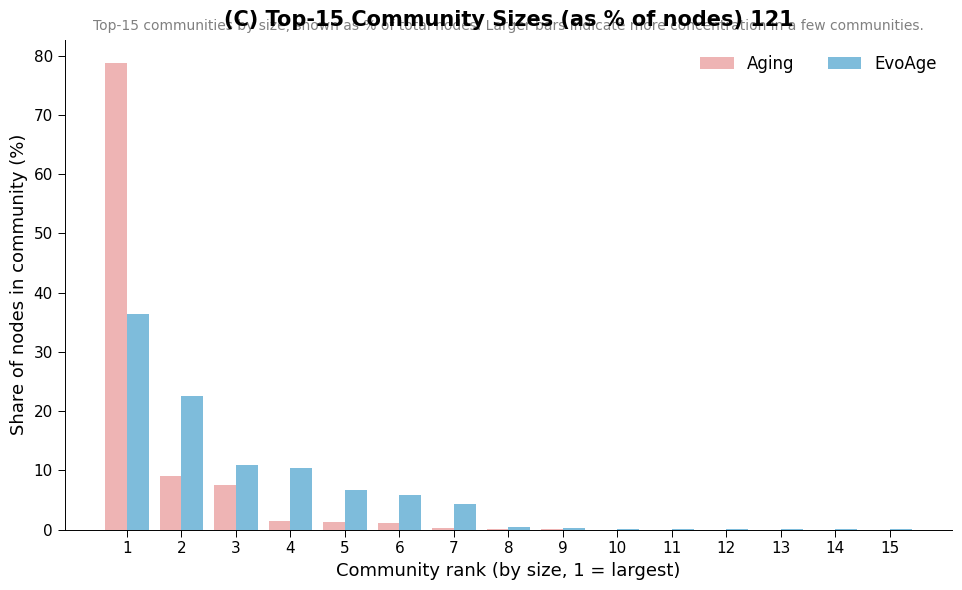

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121/Aging_121_louvain_partitions.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121/EvoAge_121_louvain_partitions.csv"

def read_louvain_csv(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.lower()
    if not {"vertex", "partition"}.issubset(df.columns):
        raise ValueError(f"Expected 'vertex' and 'partition' columns in {path}, got {list(df.columns)}")
    return df[["vertex", "partition"]]

aging_raw  = read_louvain_csv(aging_path)
evoage_raw = read_louvain_csv(evoage_path)

# -----------------------------------------------------------------------------
# 2. COMMUNITY SIZE TABLES
# -----------------------------------------------------------------------------
def community_sizes(df):
    return (
        df.groupby("partition")
          .size()
          .reset_index(name="size")
          .sort_values("size", ascending=False)
          .reset_index(drop=True)
    )

aging_sizes  = community_sizes(aging_raw)
evoage_sizes = community_sizes(evoage_raw)

N_aging  = len(aging_raw)
N_evoage = len(evoage_raw)

# -----------------------------------------------------------------------------
# 3. QUICK STATS (mirrors R's cat block)
# -----------------------------------------------------------------------------
def entropy(sizes):
    p = sizes / sizes.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log(p)))

print("\n=== Summary ===")
print(f"Aging   | Nodes: {N_aging:,} | Communities: {len(aging_sizes):,} | "
      f"Largest: {100*aging_sizes['size'].max()/N_aging:.2f}% | "
      f"Entropy: {entropy(aging_sizes['size'].values):.3f}")
print(f"EvoAge  | Nodes: {N_evoage:,} | Communities: {len(evoage_sizes):,} | "
      f"Largest: {100*evoage_sizes['size'].max()/N_evoage:.2f}% | "
      f"Entropy: {entropy(evoage_sizes['size'].values):.3f}\n")

# -----------------------------------------------------------------------------
# 4. TOP-K COMMUNITIES
# -----------------------------------------------------------------------------
K = 15

top_aging = aging_sizes.head(K).copy()
top_aging["rank"]  = np.arange(1, len(top_aging) + 1)
top_aging["pct"]   = 100 * top_aging["size"] / N_aging
top_aging["graph"] = "Aging"

top_evoage = evoage_sizes.head(K).copy()
top_evoage["rank"]  = np.arange(1, len(top_evoage) + 1)
top_evoage["pct"]   = 100 * top_evoage["size"] / N_evoage
top_evoage["graph"] = "EvoAge"

top_df = pd.concat([top_aging, top_evoage], ignore_index=True)

# -----------------------------------------------------------------------------
# 5. PLOT — grouped bar chart
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "EvoAge": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(10, 6))

ranks = np.arange(1, K + 1)
width = 0.4

aging_vals  = top_df[top_df["graph"] == "Aging"].set_index("rank").reindex(ranks)["pct"].fillna(0)
evoage_vals = top_df[top_df["graph"] == "EvoAge"].set_index("rank").reindex(ranks)["pct"].fillna(0)

ax.bar(ranks - width/2, aging_vals,  width=width, color=colors["Aging"],  label="Aging",
       edgecolor="none")
ax.bar(ranks + width/2, evoage_vals, width=width, color=colors["EvoAge"], label="EvoAge",
       edgecolor="none")

ax.set_xticks(ranks)
ax.set_xticklabels(ranks, fontsize=11)

ax.set_title(f"(C) Top-{K} Community Sizes (as % of nodes) 121",
             fontsize=15, fontweight="bold", pad=10)
ax.text(0.5, 1.02,
        f"Top-{K} communities by size, shown as % of total nodes. "
        "Larger bars indicate more concentration in a few communities.",
        transform=ax.transAxes, ha="center", fontsize=10, color="gray")

ax.set_xlabel("Community rank (by size, 1 = largest)", fontsize=13)
ax.set_ylabel("Share of nodes in community (%)", fontsize=13)

# theme_classic-ish
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(0.7)
ax.spines["bottom"].set_linewidth(0.7)
ax.tick_params(axis="both", which="major", length=5, width=0.7, color="black", labelsize=11)
ax.grid(False)

ax.legend(loc="upper right", frameon=False, fontsize=12, ncol=2)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 6. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/fig1_i_supp.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [19]:
!ls /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/

Aging_121			       Biomedical_121_12M_vertex_counts.csv
Aging_121_12M			       Biomedical_121_global_summary.txt
Aging_121_12M_global_summary.txt       Biomedical_121_vertex_counts.csv
Aging_121_12M_vertex_counts.csv        EvoAge_121
Aging_121_global_summary.txt	       EvoAge_121_12M
Aging_121_vertex_counts.csv	       EvoAge_121_12M_global_summary.txt
Biomedical_121			       EvoAge_121_12M_vertex_counts.csv
Biomedical_121_12M		       EvoAge_121_global_summary.txt
Biomedical_121_12M_global_summary.txt  EvoAge_121_vertex_counts.csv


## Fig1 k

In [ ]:
# /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M_vertex_counts.csv
# /storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M/EvoAge_121_12M_louvain_partitions.csv


=== Triangle Count Summary ===
Aging   | Nodes: 15,225  | zero-triangle nodes: 0.00%
EvoAge  | Nodes: 45,506,928 | zero-triangle nodes: 0.00%



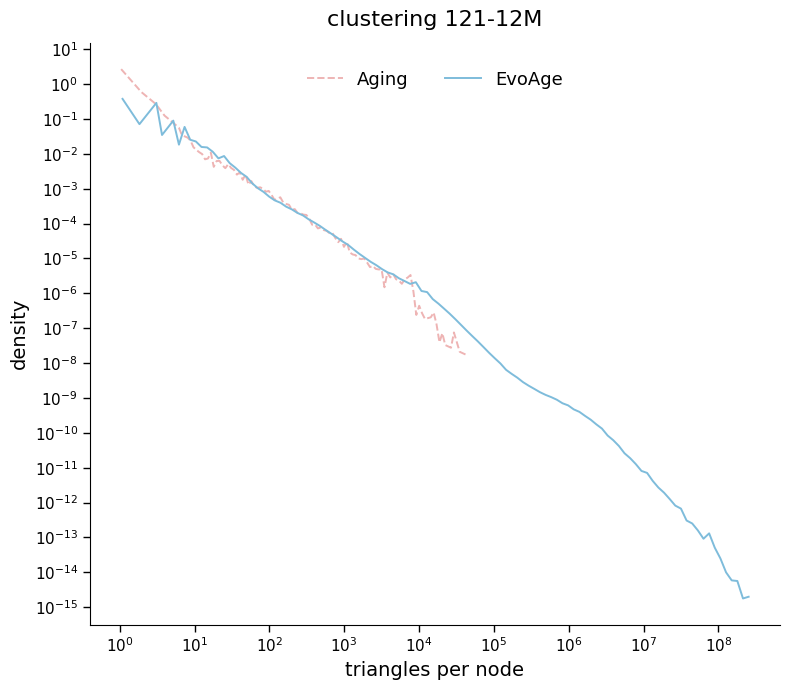

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M_vertex_counts.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_12M_vertex_counts.csv"

def read_tri_csv(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.lower()
    if not {"vertex", "counts"}.issubset(df.columns):
        raise ValueError(f"Expected 'vertex' and 'counts' columns in {path}, got {list(df.columns)}")
    return df[["vertex", "counts"]].apply(pd.to_numeric, errors="coerce")

aging_raw  = read_tri_csv(aging_path)
evoage_raw = read_tri_csv(evoage_path)

N_aging  = len(aging_raw)
N_evoage = len(evoage_raw)

# -----------------------------------------------------------------------------
# 2. QUICK STATS
# -----------------------------------------------------------------------------
aging_zero  = (aging_raw["counts"]  <= 0).mean()
evoage_zero = (evoage_raw["counts"] <= 0).mean()

print("\n=== Triangle Count Summary ===")
print(f"Aging   | Nodes: {N_aging:,}  | zero-triangle nodes: {100*aging_zero:.2f}%")
print(f"EvoAge  | Nodes: {N_evoage:,} | zero-triangle nodes: {100*evoage_zero:.2f}%\n")

# Keep positive counts for log-scale
pos_aging  = aging_raw.loc[aging_raw["counts"]  > 0, "counts"].to_numpy()
pos_evoage = evoage_raw.loc[evoage_raw["counts"] > 0, "counts"].to_numpy()

# -----------------------------------------------------------------------------
# 3. LOG-BINNED PDF (matches R's hist(..., include.lowest=TRUE, right=FALSE))
# -----------------------------------------------------------------------------
def log_binned_pdf(arr, nbins=120):
    arr = arr[np.isfinite(arr) & (arr > 0)]
    if len(arr) == 0:
        return np.array([1.0]), np.array([1.0])

    lo, hi = arr.min(), arr.max()
    if hi <= lo:
        return np.array([hi]), np.array([1.0])

    bins = np.logspace(np.log10(lo), np.log10(hi), nbins + 1)

    # Replicate R's right=FALSE, include.lowest=TRUE:
    # left-closed, right-open intervals [a,b); include max value in last bin
    idx = np.digitize(arr, bins, right=False)
    idx[arr == bins[-1]] = nbins   # include the maximum value in the last bin
    counts = np.bincount(idx, minlength=nbins + 2)[1:nbins + 1]

    widths = np.diff(bins)
    total = counts.sum()
    pdf = np.where(widths > 0, (counts / total) / widths, 0)
    centers = np.sqrt(bins[:-1] * bins[1:])

    mask = pdf > 0
    return centers[mask], pdf[mask]

x_aging,  y_aging  = log_binned_pdf(pos_aging,  nbins=120)
x_evoage, y_evoage = log_binned_pdf(pos_evoage, nbins=120)

# -----------------------------------------------------------------------------
# 4. PLOT
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "EvoAge": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(8, 7))

# Aging as dashed line (matches your reference image)
ax.plot(x_aging,  y_aging,  color=colors["Aging"],
        linewidth=1.4, linestyle="--", label="Aging")
ax.plot(x_evoage, y_evoage, color=colors["EvoAge"],
        linewidth=1.4, linestyle="-",  label="EvoAge")

ax.set_xscale("log")
ax.set_yscale("log")

def sci_fmt(x, _):
    return f"$10^{{{int(np.log10(x))}}}$"

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(sci_fmt))

ax.set_title("clustering 121-12M", fontsize=16, pad=12)
ax.set_xlabel("triangles per node", fontsize=14)
ax.set_ylabel("density", fontsize=14)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", length=5, width=1, color="black", labelsize=11)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98),
          ncol=2, frameon=False, fontsize=13)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 5. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_k_main.pdf", format="pdf", bbox_inches="tight")
plt.show()


=== Triangle Count Summary ===
Aging   | Nodes: 15,225  | zero-triangle nodes: 0.00%
Biomedical  | Nodes: 35,595,483 | zero-triangle nodes: 0.00%



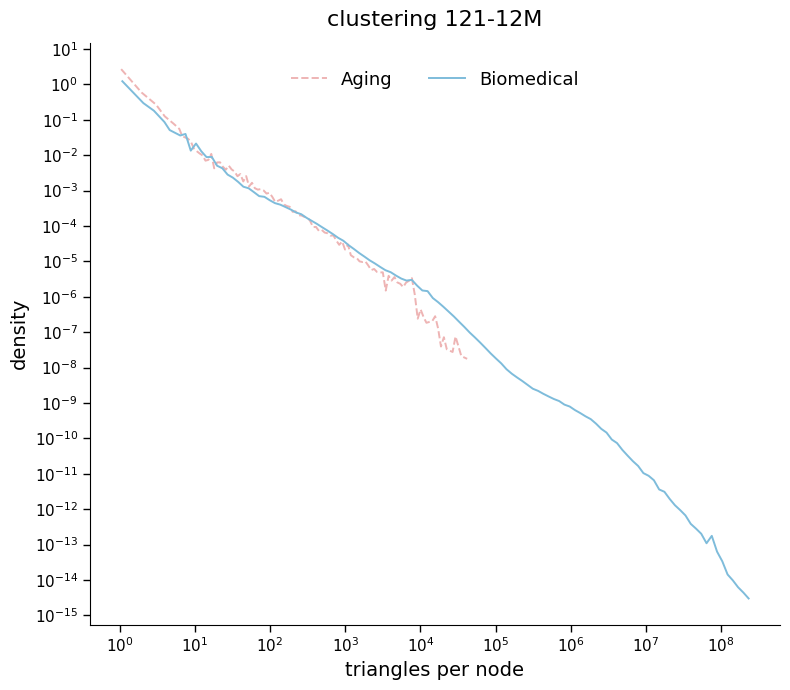

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_12M_vertex_counts.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Biomedical_121_12M/Biomedical_121_12M_vertex_counts.csv"

def read_tri_csv(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.lower()
    if not {"vertex", "counts"}.issubset(df.columns):
        raise ValueError(f"Expected 'vertex' and 'counts' columns in {path}, got {list(df.columns)}")
    return df[["vertex", "counts"]].apply(pd.to_numeric, errors="coerce")

aging_raw  = read_tri_csv(aging_path)
evoage_raw = read_tri_csv(evoage_path)

N_aging  = len(aging_raw)
N_evoage = len(evoage_raw)

# -----------------------------------------------------------------------------
# 2. QUICK STATS
# -----------------------------------------------------------------------------
aging_zero  = (aging_raw["counts"]  <= 0).mean()
evoage_zero = (evoage_raw["counts"] <= 0).mean()

print("\n=== Triangle Count Summary ===")
print(f"Aging   | Nodes: {N_aging:,}  | zero-triangle nodes: {100*aging_zero:.2f}%")
print(f"Biomedical  | Nodes: {N_evoage:,} | zero-triangle nodes: {100*evoage_zero:.2f}%\n")

# Keep positive counts for log-scale
pos_aging  = aging_raw.loc[aging_raw["counts"]  > 0, "counts"].to_numpy()
pos_evoage = evoage_raw.loc[evoage_raw["counts"] > 0, "counts"].to_numpy()

# -----------------------------------------------------------------------------
# 3. LOG-BINNED PDF (matches R's hist(..., include.lowest=TRUE, right=FALSE))
# -----------------------------------------------------------------------------
def log_binned_pdf(arr, nbins=120):
    arr = arr[np.isfinite(arr) & (arr > 0)]
    if len(arr) == 0:
        return np.array([1.0]), np.array([1.0])

    lo, hi = arr.min(), arr.max()
    if hi <= lo:
        return np.array([hi]), np.array([1.0])

    bins = np.logspace(np.log10(lo), np.log10(hi), nbins + 1)

    # Replicate R's right=FALSE, include.lowest=TRUE:
    # left-closed, right-open intervals [a,b); include max value in last bin
    idx = np.digitize(arr, bins, right=False)
    idx[arr == bins[-1]] = nbins   # include the maximum value in the last bin
    counts = np.bincount(idx, minlength=nbins + 2)[1:nbins + 1]

    widths = np.diff(bins)
    total = counts.sum()
    pdf = np.where(widths > 0, (counts / total) / widths, 0)
    centers = np.sqrt(bins[:-1] * bins[1:])

    mask = pdf > 0
    return centers[mask], pdf[mask]

x_aging,  y_aging  = log_binned_pdf(pos_aging,  nbins=120)
x_evoage, y_evoage = log_binned_pdf(pos_evoage, nbins=120)

# -----------------------------------------------------------------------------
# 4. PLOT
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "Biomedical": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(8, 7))

# Aging as dashed line (matches your reference image)
ax.plot(x_aging,  y_aging,  color=colors["Aging"],
        linewidth=1.4, linestyle="--", label="Aging")
ax.plot(x_evoage, y_evoage, color=colors["Biomedical"],
        linewidth=1.4, linestyle="-",  label="Biomedical")

ax.set_xscale("log")
ax.set_yscale("log")

def sci_fmt(x, _):
    return f"$10^{{{int(np.log10(x))}}}$"

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(sci_fmt))

ax.set_title("clustering 121-12M", fontsize=16, pad=12)
ax.set_xlabel("triangles per node", fontsize=14)
ax.set_ylabel("density", fontsize=14)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", length=5, width=1, color="black", labelsize=11)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98),
          ncol=2, frameon=False, fontsize=13)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 5. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/aging-biomedical-clustering.pdf", format="pdf", bbox_inches="tight")
plt.show()


=== Triangle Count Summary ===
Aging   | Nodes: 15,148  | zero-triangle nodes: 0.00%
EvoAge  | Nodes: 45,503,903 | zero-triangle nodes: 0.00%



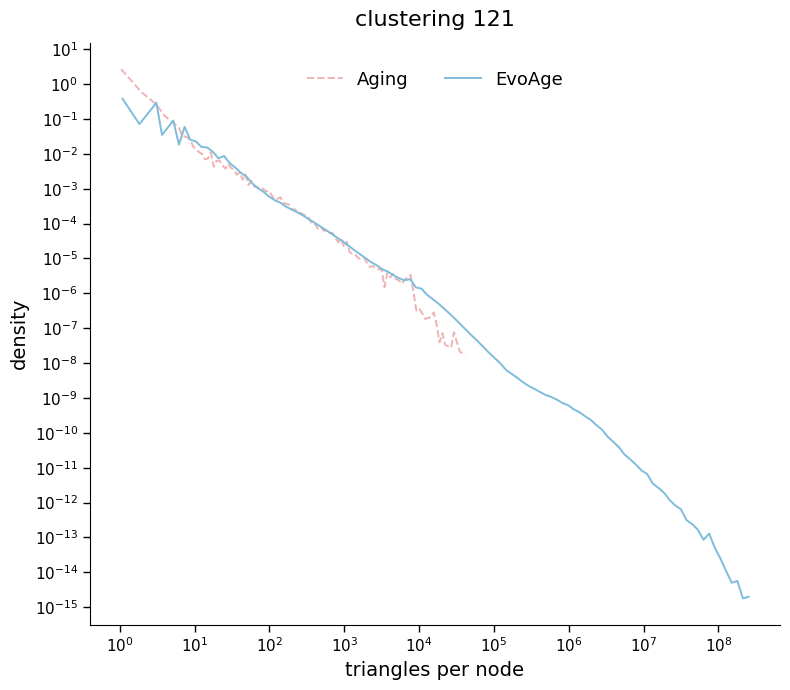

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
aging_path  = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/Aging_121_vertex_counts.csv"
evoage_path = "/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Graph_features/Output_csv/EvoAge_121_vertex_counts.csv"

def read_tri_csv(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.lower()
    if not {"vertex", "counts"}.issubset(df.columns):
        raise ValueError(f"Expected 'vertex' and 'counts' columns in {path}, got {list(df.columns)}")
    return df[["vertex", "counts"]].apply(pd.to_numeric, errors="coerce")

aging_raw  = read_tri_csv(aging_path)
evoage_raw = read_tri_csv(evoage_path)

N_aging  = len(aging_raw)
N_evoage = len(evoage_raw)

# -----------------------------------------------------------------------------
# 2. QUICK STATS
# -----------------------------------------------------------------------------
aging_zero  = (aging_raw["counts"]  <= 0).mean()
evoage_zero = (evoage_raw["counts"] <= 0).mean()

print("\n=== Triangle Count Summary ===")
print(f"Aging   | Nodes: {N_aging:,}  | zero-triangle nodes: {100*aging_zero:.2f}%")
print(f"EvoAge  | Nodes: {N_evoage:,} | zero-triangle nodes: {100*evoage_zero:.2f}%\n")

# Keep positive counts for log-scale
pos_aging  = aging_raw.loc[aging_raw["counts"]  > 0, "counts"].to_numpy()
pos_evoage = evoage_raw.loc[evoage_raw["counts"] > 0, "counts"].to_numpy()

# -----------------------------------------------------------------------------
# 3. LOG-BINNED PDF (matches R's hist(..., include.lowest=TRUE, right=FALSE))
# -----------------------------------------------------------------------------
def log_binned_pdf(arr, nbins=120):
    arr = arr[np.isfinite(arr) & (arr > 0)]
    if len(arr) == 0:
        return np.array([1.0]), np.array([1.0])

    lo, hi = arr.min(), arr.max()
    if hi <= lo:
        return np.array([hi]), np.array([1.0])

    bins = np.logspace(np.log10(lo), np.log10(hi), nbins + 1)

    # Replicate R's right=FALSE, include.lowest=TRUE:
    # left-closed, right-open intervals [a,b); include max value in last bin
    idx = np.digitize(arr, bins, right=False)
    idx[arr == bins[-1]] = nbins   # include the maximum value in the last bin
    counts = np.bincount(idx, minlength=nbins + 2)[1:nbins + 1]

    widths = np.diff(bins)
    total = counts.sum()
    pdf = np.where(widths > 0, (counts / total) / widths, 0)
    centers = np.sqrt(bins[:-1] * bins[1:])

    mask = pdf > 0
    return centers[mask], pdf[mask]

x_aging,  y_aging  = log_binned_pdf(pos_aging,  nbins=120)
x_evoage, y_evoage = log_binned_pdf(pos_evoage, nbins=120)

# -----------------------------------------------------------------------------
# 4. PLOT
# -----------------------------------------------------------------------------
colors = {"Aging": "#eeb4b4", "EvoAge": "#7ebcdb"}

fig, ax = plt.subplots(figsize=(8, 7))

# Aging as dashed line (matches your reference image)
ax.plot(x_aging,  y_aging,  color=colors["Aging"],
        linewidth=1.4, linestyle="--", label="Aging")
ax.plot(x_evoage, y_evoage, color=colors["EvoAge"],
        linewidth=1.4, linestyle="-",  label="EvoAge")

ax.set_xscale("log")
ax.set_yscale("log")

def sci_fmt(x, _):
    return f"$10^{{{int(np.log10(x))}}}$"

ax.xaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=20))
ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(sci_fmt))

ax.set_title("clustering 121", fontsize=16, pad=12)
ax.set_xlabel("triangles per node", fontsize=14)
ax.set_ylabel("density", fontsize=14)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", length=5, width=1, color="black", labelsize=11)
ax.tick_params(axis="both", which="minor", length=0)
ax.grid(False)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98),
          ncol=2, frameon=False, fontsize=13)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 5. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_k_supp.pdf", format="pdf", bbox_inches="tight")
plt.show()

## Fig 1 supplementary

In [27]:
evoage = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/NodeType_AllKGs_1to1_and_121_12M.csv")
evoage

,NodeType,EvoAge_1to1,Aging_1to1,Biomedical_1to1,EvoAge_121_12M,Aging_121_12M,Biomedical_121_12M
0,PMID,29237564,0,29237564,29237564,0,29237564
1,Mutation,14230255,746,14229509,14230255,746,14229509
2,ChemicalEntity,1210354,435363,896994,1210900,435363,897554
3,Protein,518647,2020,518545,518647,2020,518545
4,Phenotype,95010,0,95010,101262,0,101262
5,Gene,90226,12088,89315,90294,12307,89384
6,AnatomicalEntity,56029,0,56029,56029,0,56029
7,Disease,44263,22269,32860,44263,22269,32860
8,BiologicalProcess,29637,93,29629,29637,93,29629
9,MolecularFunction,11750,0,11750,11750,0,11750


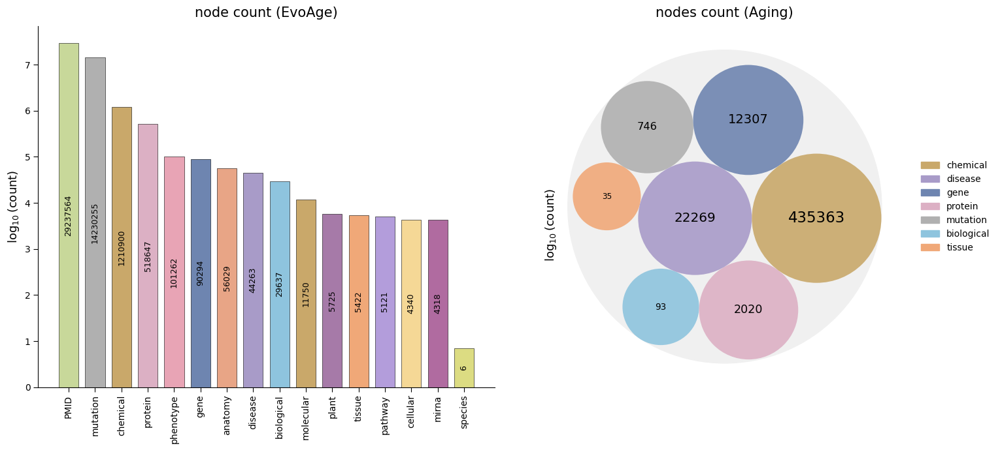

In [31]:
# pip install circlify   # <- one-time install for circle packing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import circlify

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
df = pd.read_csv("/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/NodeType_AllKGs_1to1_and_121_12M.csv")

# -----------------------------------------------------------------------------
# 2. PRETTY SHORT LABELS + COLOR PALETTE (consistent across both plots)
# -----------------------------------------------------------------------------
short_names = {
    "PMID": "PMID",
    "Mutation": "mutation",
    "ChemicalEntity": "chemical",
    "Protein": "protein",
    "Phenotype": "phenotype",
    "Gene": "gene",
    "Disease": "disease",
    "BiologicalProcess": "biological",
    "AnatomicalEntity": "anatomy",
    "MolecularFunction": "molecular",
    "PlantSpecies": "plant",
    "Tissue": "tissue",
    "Pathway": "pathway",
    "CellularComponent": "cellular",
    "Mirna": "mirna",
    "Species": "species",
}

nodetype_colors = {
    "PMID": "#c8d89a",
    "Mutation": "#b0b0b0",
    "ChemicalEntity": "#c9a86a",
    "Protein": "#dcb0c4",
    "Phenotype": "#e8a4b5",
    "Gene": "#6e85b0",
    "Disease": "#a89bc8",
    "BiologicalProcess": "#8ec4de",
    "AnatomicalEntity": "#e8a586",
    "MolecularFunction": "#c9a86a",
    "PlantSpecies": "#a67aa8",
    "Tissue": "#f0a878",
    "Pathway": "#b39ddb",
    "CellularComponent": "#f5d896",
    "Mirna": "#b06ba0",
    "Species": "#dcdc82",
}

# -----------------------------------------------------------------------------
# 3. FIGURE WITH 2 SUBPLOTS
# -----------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# =============================================================================
# LEFT: BAR PLOT — EvoAge_121_12M
# =============================================================================
evo = df[["NodeType", "EvoAge_121_12M"]].copy()
evo = evo[evo["EvoAge_121_12M"] > 0].sort_values("EvoAge_121_12M", ascending=False).reset_index(drop=True)
evo["log"] = np.log10(evo["EvoAge_121_12M"] + 1)

x = np.arange(len(evo))
bar_colors = [nodetype_colors.get(nt, "#cccccc") for nt in evo["NodeType"]]

ax1.bar(x, evo["log"], color=bar_colors, edgecolor="black", linewidth=0.4, width=0.75)

# Count labels rotated 90° inside/on each bar
for xi, (_, row) in zip(x, evo.iterrows()):
    ax1.text(xi, row["log"] * 0.5, f"{int(row['EvoAge_121_12M'])}",
             ha="center", va="center", rotation=90, fontsize=9, color="black")

ax1.set_xticks(x)
ax1.set_xticklabels([short_names.get(nt, nt) for nt in evo["NodeType"]],
                    rotation=90, fontsize=10)
ax1.set_ylabel(r"$\log_{10}$(count)", fontsize=13)
ax1.set_title("node count (EvoAge)", fontsize=15, pad=10)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.tick_params(axis="both", which="major", length=5, width=0.8, color="black", labelsize=10)
ax1.grid(False)

# =============================================================================
# RIGHT: BUBBLE PLOT — Aging_121_12M (circle packing inside a big circle)
# =============================================================================
aging = df[["NodeType", "Aging_121_12M"]].copy()
aging = aging[aging["Aging_121_12M"] > 0].sort_values("Aging_121_12M", ascending=False).reset_index(drop=True)

# Use log10(count+1) as the bubble size — otherwise huge counts (e.g. 435K) 
# would visually crush all smaller bubbles
aging["size_val"] = np.log10(aging["Aging_121_12M"] + 1)

# circlify expects data sorted descending by 'datum'
data_for_pack = [
    {"id": row["NodeType"], "datum": row["size_val"]}
    for _, row in aging.sort_values("size_val", ascending=False).iterrows()
]

circles = circlify.circlify(
    data_for_pack,
    show_enclosure=False,
    target_enclosure=circlify.Circle(x=0, y=0, r=1),
)

# Big background circle
bg = mpatches.Circle((0, 0), 1.0, facecolor="#f0f0f0", edgecolor="none", zorder=0)
ax2.add_patch(bg)

# Draw each packed bubble
for circle in circles:
    x_c, y_c, r_c = circle.x, circle.y, circle.r
    node_id = circle.ex["id"]
    count = int(aging.loc[aging["NodeType"] == node_id, "Aging_121_12M"].iloc[0])
    color = nodetype_colors.get(node_id, "#cccccc")

    ax2.add_patch(mpatches.Circle((x_c, y_c), r_c,
                                   facecolor=color, edgecolor="none", alpha=0.9, zorder=2))
    # Count label centered in the bubble
    ax2.text(x_c, y_c, f"{count}", ha="center", va="center",
             fontsize=max(6, r_c * 40), color="black", zorder=3)

ax2.set_xlim(-1.15, 1.15)
ax2.set_ylim(-1.15, 1.15)
ax2.set_aspect("equal")
ax2.axis("off")
ax2.set_title("nodes count (Aging)", fontsize=15, pad=10)
ax2.set_ylabel(r"$\log_{10}$(count)", fontsize=13)  # visible only if axis kept; can drop
# If you want the y-label to still show even with axis off:
fig.text(0.53, 0.5, r"$\log_{10}$(count)", ha="center", va="center",
         rotation=90, fontsize=13)

# Legend for bubble plot (color -> nodetype)
legend_handles = [
    mpatches.Patch(color=nodetype_colors[nt], label=short_names.get(nt, nt))
    for nt in aging["NodeType"]
]
ax2.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.02, 0.5),
           frameon=False, fontsize=10)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. SAVE AS PDF
# -----------------------------------------------------------------------------
plt.savefig("FIG1/Fig1_g_h_evoage_bar_aging_bubble_supp.pdf", format="pdf", bbox_inches="tight")
plt.show()

### Fig 1 S2 ab S3 abcde

In [32]:
EvoAge = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Triple_source_databases_KG.csv')
EvoAge

,Source,KG_Type,AnatomicalEntity_AnatomicalEntity,AnatomicalEntity_BiologicalProcess,AnatomicalEntity_CellularComponent,AnatomicalEntity_ChemicalEntity,AnatomicalEntity_Gene,BiologicalProcess_BiologicalProcess,BiologicalProcess_CellularComponent,BiologicalProcess_ChemicalEntity,...,Protein_Pathway,Protein_Phenotype,Protein_Protein,Protein_Tissue,ChemicalEntity_NotAssociatedWith_BiologicalProcess,Phenotype_CellularComponent,Phenotype_BiologicalProcess,Phenotype_MolecularFunction,Species_AssociatedWith,Total
0,CKG,Generalised,0,0,0,0,0,0,0,0,...,0,0,52520505,40397233,0,0,0,0,0,1055924560
1,STITCH,Generalised,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,65331289
2,STRING,Generalised,0,0,0,0,0,0,0,0,...,0,0,5035007,0,0,0,0,0,0,37937013
3,iBKH,Generalised,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,29282596
4,TARKG,Generalised,29519,0,0,0,585346,55673,0,0,...,38882,0,1259732,0,0,0,0,0,0,10085324
5,Harmonizome,Generalised,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,7364565
6,MonarchKG,Generalised,194240,321,2837,9,0,0,1489,2662,...,0,0,18,0,0,5808,12655,459,0,5060059
7,DRKG,Generalised,0,0,0,0,587552,0,0,0,...,0,0,0,0,0,0,0,0,0,4523551
8,PrimeKG,Generalised,14032,0,0,0,1476537,52886,0,1061,...,0,0,0,0,0,0,0,0,0,3759905
9,CROssBAR,Generalised,0,0,0,0,0,64906,0,0,...,55856,328,292762,0,0,0,0,0,0,2523849


In [33]:
Aging = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Triple_source_databases_AgingKG.csv')
Aging

,Source,KG_Type,AnatomicalEntity_AnatomicalEntity,AnatomicalEntity_BiologicalProcess,AnatomicalEntity_CellularComponent,AnatomicalEntity_ChemicalEntity,AnatomicalEntity_Gene,BiologicalProcess_BiologicalProcess,BiologicalProcess_CellularComponent,BiologicalProcess_ChemicalEntity,...,Protein_Pathway,Protein_Phenotype,Protein_Protein,Protein_Tissue,ChemicalEntity_NotAssociatedWith_BiologicalProcess,Phenotype_CellularComponent,Phenotype_BiologicalProcess,Phenotype_MolecularFunction,Species_AssociatedWith,Total
0,AgeAnno,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,706476
1,AgeXtend,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,696606
2,HALD,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,55854
3,AgeAnnoMO,Aging,0,0,0,0,0,0,0,0,...,0,0,0,1911,0,0,0,0,0,15947
4,Digital Aging Atlas,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4474
5,GeneAge,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2081
6,Aging Atlas,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1523
7,DrugAge,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,431,0,0,0,0,1126
8,CellAge,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,914
9,MetaboAge,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,535


In [35]:
Y = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Data_source/Yeast_only_source_databases_KG.csv')
Y
C = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Data_source/Celegans_only_source_databases_KG.csv')
C
D = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Data_source/Drosophila_only_source_databases_KG.csv')
D
Z = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Data_source/zebrafish_only_source_databases_KG.csv')
Z
M = pd.read_csv('/storage/Arushi/090526_EvoAge/kg_formation/final_kg_building_3/STATS/Data_source/Mouse_only_source_databases_KG.csv')
M

,Source,KG_Type,AnatomicalEntity_AnatomicalEntity,AnatomicalEntity_BiologicalProcess,AnatomicalEntity_CellularComponent,AnatomicalEntity_ChemicalEntity,AnatomicalEntity_Gene,BiologicalProcess_BiologicalProcess,BiologicalProcess_CellularComponent,BiologicalProcess_ChemicalEntity,...,Protein_Pathway,Protein_Phenotype,Protein_Protein,Protein_Tissue,ChemicalEntity_NotAssociatedWith_BiologicalProcess,Phenotype_CellularComponent,Phenotype_BiologicalProcess,Phenotype_MolecularFunction,Species_AssociatedWith,Total
0,STITCH,Generalised,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,21705984
1,STRING,Generalised,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,12768180
2,Mouse_Net,Generalised,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,718832
3,MonarchKG,Generalised,4579,0,0,0,0,0,0,0,...,0,0,0,0,0,354,1493,0,0,696002
4,miRTarBase,Generalised,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,398720
5,MGI_DO,Generalised,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,363574
6,AgeAnnoMO,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,11821
7,Digital Aging Atlas,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1130
8,Aging Atlas,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,442
9,GeneAge,Aging,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,136


## Fig 1 supp data source species

/home/arushis/.local/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_290062/2947285543.py:153: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


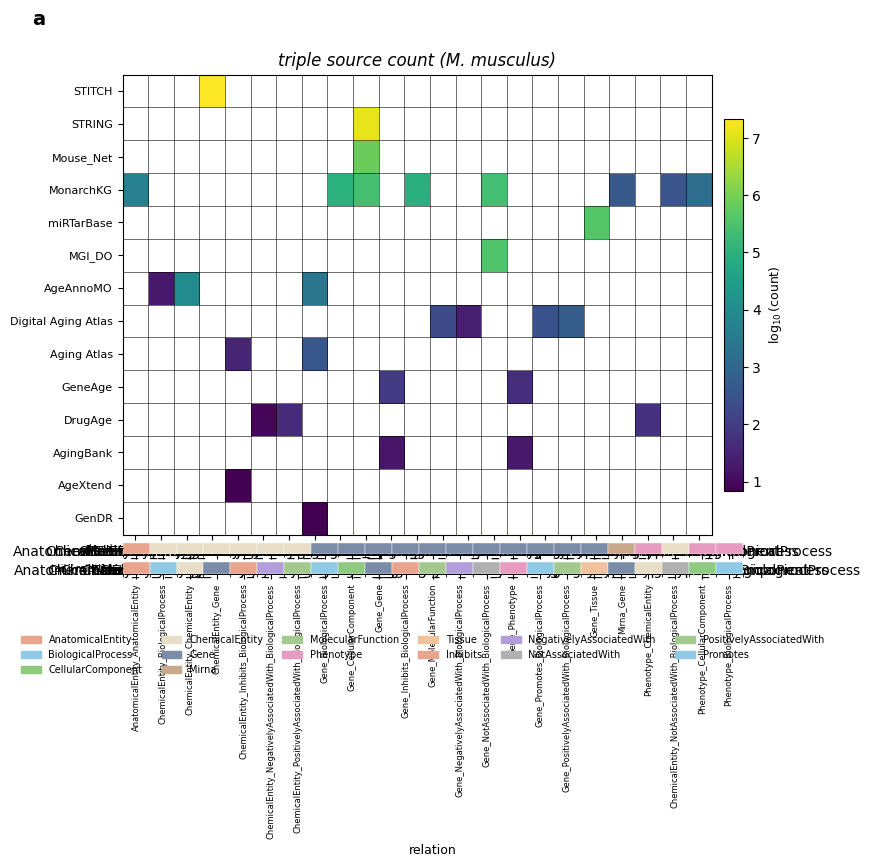

/home/arushis/.local/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_290062/2947285543.py:153: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


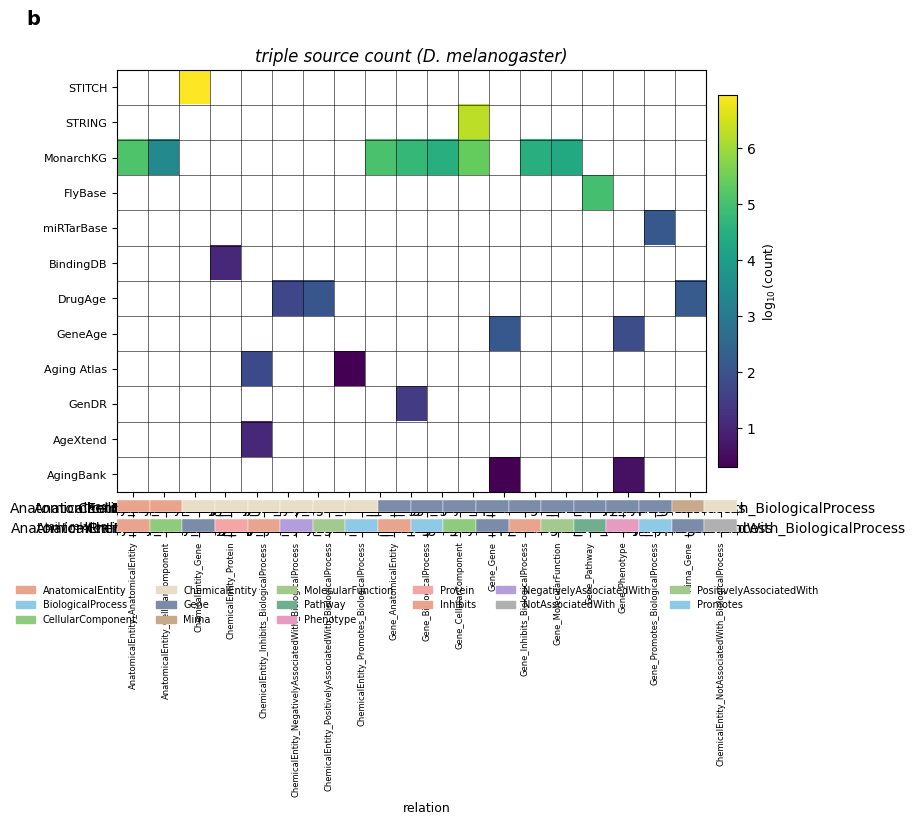

/home/arushis/.local/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_290062/2947285543.py:153: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


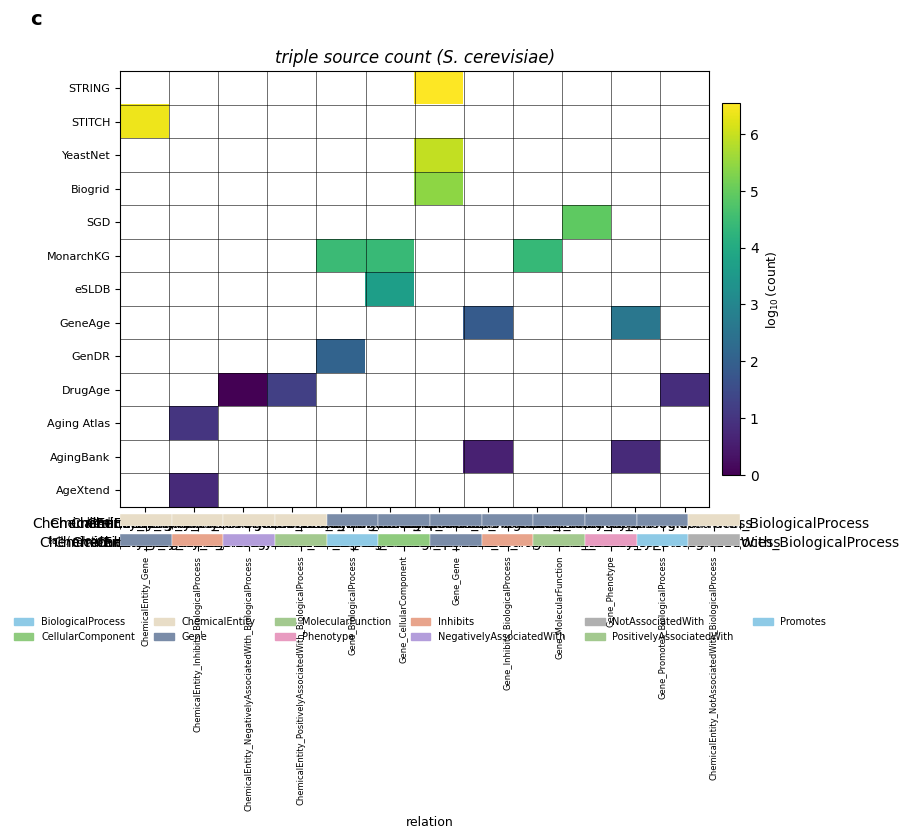

/home/arushis/.local/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_290062/2947285543.py:153: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


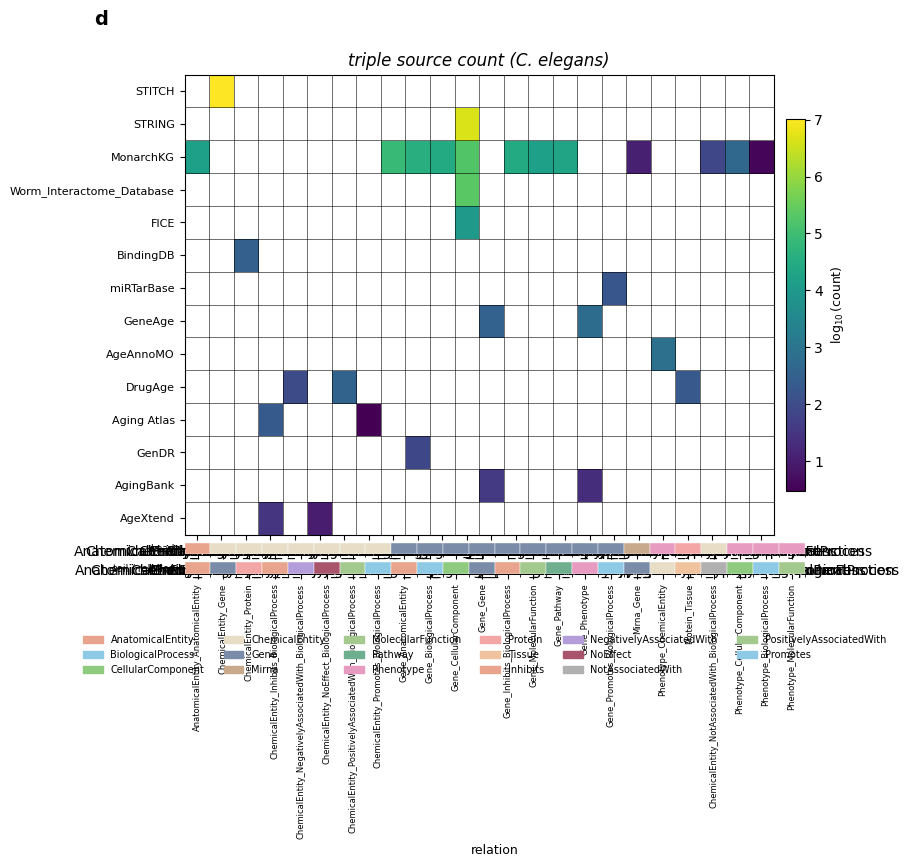

/home/arushis/.local/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_290062/2947285543.py:153: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


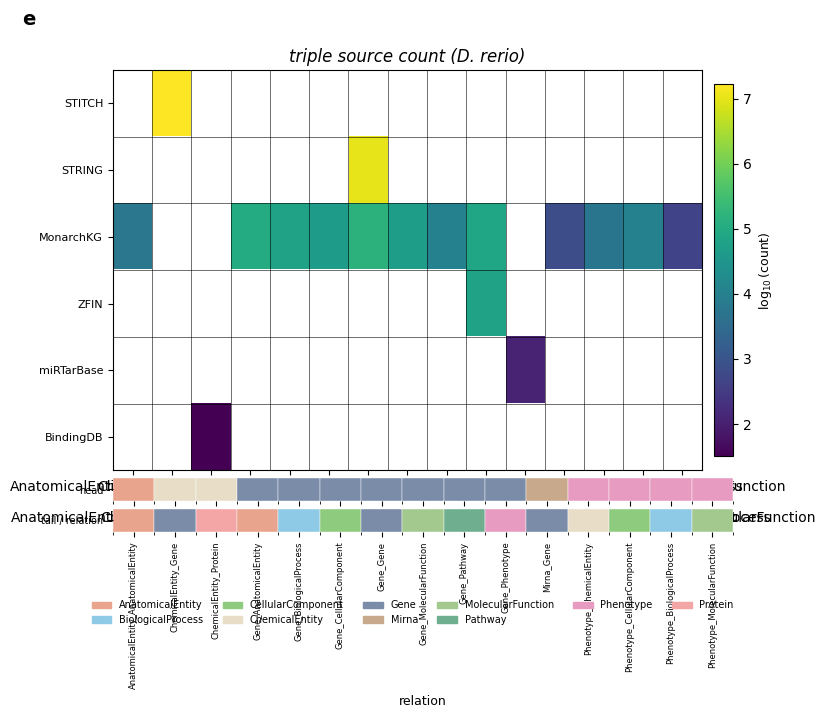

/home/arushis/.local/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_290062/2947285543.py:153: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


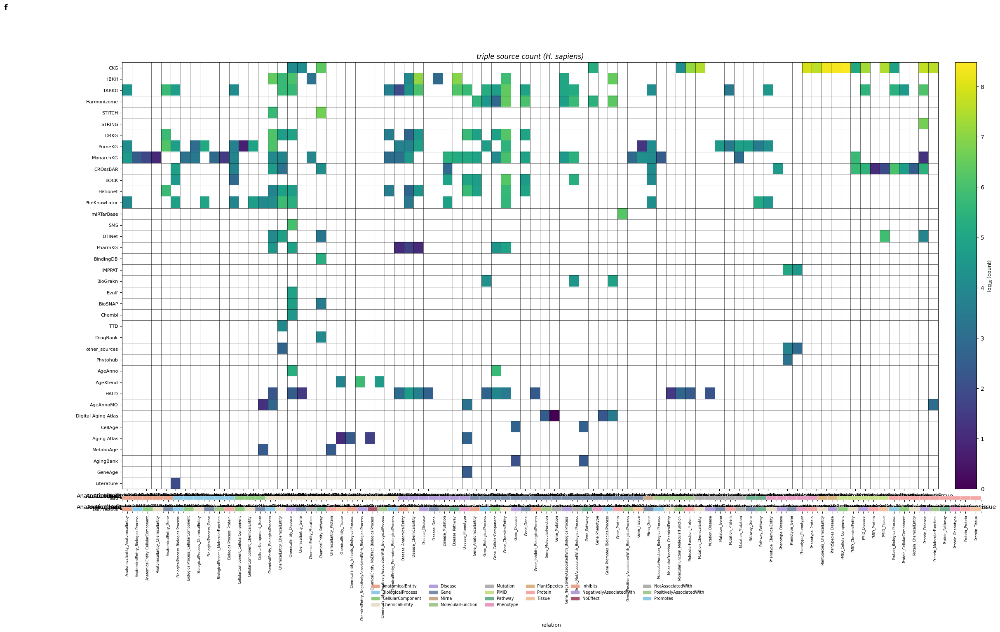

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap

# =============================================================================
# 0. CONFIG — one CSV per species, in the same wide format
#    (rows = source database, columns = HeadEntity_[Relation_]TailEntity, values = triple counts)
# =============================================================================
species_files = {
    'M. musculus':      'Mouse_only_source_databases_KG.csv',
    'D. melanogaster':  'Drosophila_only_source_databases_KG.csv',
    'S. cerevisiae':    'Yeast_only_source_databases_KG.csv',
    'C. elegans':       'Celegans_only_source_databases_KG.csv',
    'D. rerio':         'zebrafish_only_source_databases_KG.csv',
    'H. sapiens':       'Human_only_source_databases_KG.csv',
}
# ^ update these paths to your actual storage locations

NON_DATA_COLS = ['Source', 'KG_Type', 'Total']

# relation keywords that appear as the MIDDLE token in 3-part columns
# (e.g. "ChemicalEntity_Inhibits_BiologicalProcess"), or as the 2nd token
# in some 2-part columns (e.g. "Species_AssociatedWith")
RELATION_KEYWORDS = {
    'Inhibits', 'Promotes', 'NoEffect', 'NotAssociatedWith',
    'PositivelyAssociatedWith', 'NegativelyAssociatedWith', 'AssociatedWith',
}

# =============================================================================
# 1. Entity-type colour palette (head/tail annotation strip)
# =============================================================================
entity_colors = {
    'AnatomicalEntity':   '#e8a48c',
    'BiologicalProcess':  '#8ecae6',
    'CellularComponent':  '#8fcb7e',
    'ChemicalEntity':     '#e8ddc7',
    'Disease':            '#b39ddb',
    'Gene':                '#7a8ca8',
    'MolecularFunction':  '#a3c98f',
    'Mutation':           '#b0b0b0',
    'Pathway':             '#6fae8f',
    'Phenotype':           '#e89bc0',
    'Protein':              '#f4a6a6',
    'PlantSpecies':        '#d9b382',
    'Mirna':                '#c9a98b',
    'PMID':                 '#c8e08a',
    'Tissue':               '#f0c39e',
    'Species':              '#f2e3a0',
}

# relation-type colours (for 3-part / self-relation columns) -- same palette
# family used elsewhere in the project (Fig1 sunburst) for consistency
relation_colors = {
    'Inhibits':                  '#e8a48c',
    'Promotes':                  '#8ecae6',
    'NoEffect':                  '#a8546b',
    'NotAssociatedWith':         '#b0b0b0',
    'PositivelyAssociatedWith':  '#a3c98f',
    'NegativelyAssociatedWith':  '#b39ddb',
    'AssociatedWith':            '#a8546b',
}

def parse_column(col):
    """Return (head_entity, relation_or_None, tail_entity) for a triple-count column name."""
    parts = col.split('_')
    if len(parts) == 3 and parts[1] in RELATION_KEYWORDS:
        return parts[0], parts[1], parts[2]
    if len(parts) == 2 and parts[1] in RELATION_KEYWORDS:
        return parts[0], parts[1], parts[0]
    if len(parts) == 2:
        return parts[0], None, parts[1]
    # fallback: treat whole thing as a single entity self-loop
    return col, None, col

# =============================================================================
# 2. Build one heatmap per species
# =============================================================================
def plot_species_heatmap(csv_path, species_name, panel_label):
    df = pd.read_csv(csv_path)
    df = df.set_index('Source')

    data_cols = [c for c in df.columns if c not in NON_DATA_COLS]
    mat_df = df[data_cols]

    # drop columns that are all-zero for this species (no triples of that type)
    nonzero_cols = [c for c in data_cols if mat_df[c].sum() > 0]
    mat_df = mat_df[nonzero_cols]

    # drop sources with zero total across the remaining columns
    mat_df = mat_df.loc[mat_df.sum(axis=1) > 0]

    # log10(count), mask zeros as NaN so they render white (no data / no triples from that source)
    log_mat = mat_df.apply(lambda col: np.where(col > 0, np.log10(col), np.nan))
    log_mat = pd.DataFrame(log_mat, index=mat_df.index, columns=mat_df.columns)

    n_rows, n_cols = log_mat.shape

    fig = plt.figure(figsize=(max(8, n_cols * 0.32), max(4, n_rows * 0.32) + 2))
    gs = fig.add_gridspec(3, 1, height_ratios=[n_rows, 0.35, 0.35], hspace=0.05)

    ax_heat = fig.add_subplot(gs[0])
    ax_head = fig.add_subplot(gs[1], sharex=ax_heat)
    ax_tail = fig.add_subplot(gs[2], sharex=ax_heat)

    cmap = plt.cm.viridis.copy()
    cmap.set_bad('white')
    masked = np.ma.masked_invalid(log_mat.values)

    im = ax_heat.imshow(masked, cmap=cmap, aspect='auto')
    ax_heat.set_xticks([])
    ax_heat.set_yticks(range(n_rows))
    ax_heat.set_yticklabels(log_mat.index, fontsize=8)
    ax_heat.set_xticks(np.arange(-0.5, n_cols, 1), minor=True)
    ax_heat.set_yticks(np.arange(-0.5, n_rows, 1), minor=True)
    ax_heat.grid(which='minor', color='black', linewidth=0.4)
    ax_heat.tick_params(which='minor', length=0)
    ax_heat.set_title(f'triple source count ({species_name})', fontsize=12, style='italic')

    cbar = fig.colorbar(im, ax=ax_heat, fraction=0.03, pad=0.02)
    cbar.set_label(r'$\log_{10}$(count)', fontsize=9)

    # ── head/tail entity-type + relation-type annotation strips ──────────────
    parsed = [parse_column(c) for c in log_mat.columns]
    head_colors = [entity_colors.get(h, '#dddddd') for h, r, t in parsed]
    tail_colors = [relation_colors.get(r, entity_colors.get(t, '#dddddd')) for h, r, t in parsed]

    for ax, colors, label in [(ax_head, head_colors, 'head'), (ax_tail, tail_colors, 'tail / relation')]:
        for i, color in enumerate(colors):
            ax.add_patch(mpatches.Rectangle((i - 0.5, 0), 1, 1, facecolor=color, edgecolor='white', linewidth=0.3))
        ax.set_xlim(-0.5, n_cols - 0.5)
        ax.set_ylim(0, 1)
        ax.set_yticks([0.5])
        ax.set_yticklabels([label], fontsize=7)
        ax.set_xticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    ax_tail.set_xticks(range(n_cols))
    ax_tail.set_xticklabels(log_mat.columns, rotation=90, fontsize=6)
    ax_tail.set_xlabel('relation', fontsize=9)

    # ── legend: entity types + relation types actually used in this panel ────
    used_entities = sorted({h for h, r, t in parsed} | {t for h, r, t in parsed if not r})
    used_relations = sorted({r for h, r, t in parsed if r})
    legend_handles = [mpatches.Patch(color=entity_colors.get(e, '#dddddd'), label=e) for e in used_entities]
    legend_handles += [mpatches.Patch(color=relation_colors.get(r, '#dddddd'), label=r) for r in used_relations]
    fig.legend(handles=legend_handles, loc='lower center', ncol=min(6, len(legend_handles)),
               fontsize=7, bbox_to_anchor=(0.5, -0.06), frameon=False)

    fig.suptitle(panel_label, x=0.02, y=0.98, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'FIG1/Fig1_{panel_label}_{species_name.replace(". ", "_")}_source_heatmap.png',
                dpi=300, bbox_inches='tight')
    plt.savefig(f'FIG1/Fig1_{panel_label}_{species_name.replace(". ", "_")}_source_heatmap.svg',
                bbox_inches='tight')
    plt.show()


panel_labels = {
    'M. musculus': 'a', 'D. melanogaster': 'b', 'S. cerevisiae': 'c',
    'C. elegans': 'd', 'D. rerio': 'e', 'H. sapiens': 'f',
}

for species_name, path in species_files.items():
    plot_species_heatmap(path, species_name, panel_labels[species_name])